# Process Window Scout (AM-PWS)

An agent that answers a question every PBF-LB engineer asks: which laser settings give dense 316L parts? It reads
open-access papers, copies out the process parameters and densities with their sources, checks them, explains where
papers disagree, and proposes a process window for me to approve. Example request: *"316L on a 200 W machine, 30 µm
layers, relative density above 99.5 %"*.

**How to run:** kernel *Python 3.13 (CMU Agents)*, then *Restart & Run All*. Test cells print `ok` and stop at the first
failure. Model answers are cached in `data/`, so a rerun replays them without the VPN.

| Part | Question |
|---|---|
| 0 | Setup, and how the pieces fit |
| 1 | Which calculations must never be left to the model? |
| 2 | How do I talk to the model reliably? |
| 3 | Where does the knowledge come from? |
| 4 | Can one agent do the job alone? |
| 5 | What exactly does each paper report? (Reader) |
| 6 | Which records can I trust? (Checker) |
| 7 | Why do comparable studies disagree? (Analyst) |
| 8 | How do the agents work together? |
| 9 | When must a human decide? |
| 10 | Does it work, and was the split worth it? |
| 11 | One request from start to approved window |

## Part 0. Setup, and how the pieces fit

Everything later relies on this Part: the settings, a test helper, and a record of every model call.

- **Question:** What does every later Part rely on, and how is each model call kept and replayed?
- **Course concept:** the harness around an agent, and observability (Module 4)
- **Framework feature:** `ChatGLM` (a `ChatOpenAI` subclass), `set_llm_cache`, a callback handler for traces
- **Evidence:** the cache and trace tests in 0.3, and the trace tables after every model step

`check()` is my test helper. It prints `ok`, or stops the run at the first broken piece.

### How the pieces fit

1. **Request:** alloy, machine, layer thickness and target density in one sentence.
2. **Clarification (9.2):** anything missing is asked before reading.
3. **Retrieval (Part 3):** open-access papers, cut into passages, searched by meaning.
4. **Reader (Part 5):** the model copies each parameter set and density as printed, with its passage id.
5. **Checker (Part 6):** code checks every number. One retry, then "not verified".
6. **Conflicts (6.5):** code flags comparable records more than a point apart.
7. **Analyst (Part 7):** a Tree of Thought explains up to three conflicts, scored by code.
8. **Window (8.5):** code builds one window per density method.
9. **Approval (8.8, Part 9):** the graph pauses until I approve, correct or reject.

Reader, Checker, Analyst and a Coordinator in plain code share one evidence table in a LangGraph graph (Part 8).

### Rules and thresholds

Every number here is a decision with a date in `docs/decisions.md` (all dates 2026).

| Rule | Value | Why | Where | Decided |
|---|---|---|---|---|
| Ask first | grade, machine and layer must be named | a wrong guess spoils every step | 9.2 | 10-18 |
| Test set | v2 frozen, extension E01 to E06 never scored | a moving test set measures nothing | 3.9, 3.12 | 11-07 |
| Search | MMR from 60 candidates, max 2 per paper, alloy filter | several studies, no distractor | 3.10 | 10-24 |
| Reader unit | one density table per call | whole papers timed out | 5.1 | 11-07 |
| Parameter tables | a power column by word or by "P (W)", plus a speed column | columns are often named by symbol | 3.9 | 11-07 |
| Reader context | 30,000 characters per call | room left for the answer | 5.1 | 11-07 |
| Reader timeout | 10 min, one retry | a runaway answer ends on a retry | 5.1 | 11-07 |
| Numbers as printed | the model copies, code converts | no model arithmetic | 4.1 | 10-30 |
| Typical ranges | P 20 to 1000 W, v 50 to 5000 mm/s, h 20 to 300 µm, t 10 to 150 µm | catches unit slips | Part 1 | 10-18 |
| Energy density | printed and recomputed within 2 % | rounding only | 6.1 | 10-30 |
| Retry | once with the reason, then "not verified" | a second failure rarely fixes itself | 8.4 | 11-06 |
| Comparable | same layer and condition, P and v within 10 %, h within 15 % | judgement, see 8.12 | 6.5 | 11-07 |
| Conflict | densities more than 1 point apart | more than measurement scatter | 6.5 | 11-06 |
| Analyst budget | at most 3 conflicts per run | a tree costs up to 9 calls | 8.5 | 11-06 |
| Outlier | consensus AND the whole melt-pool band disagree | physics alone is weak | 6.6 | 10-09 |
| Tree size | 5 causes, beam 2, depth 2 | Checkpoint 4.1 | 7.1 | 11-06 |
| Tree points | +3 per side, +2 test, +1 physics, -3 contradicted, -2 assumption | own observations count most | 7.1 | 11-07 |
| Support gate | supporting words found in the quote, no captions | a quote is not an argument | 7.1 | 11-07 |
| Outcome bands | Resolved 6 or more with a lead of 2, Competing 3 or more | Checkpoint 4.1 judgement | 7.1 | 11-06 |
| Window | one per density method, Archimedes first | mixed methods look too good | 8.5 | 11-07 |
| Widening | under 10 records: one search at the neighbouring layers | Checkpoints 2.1 and 5.1 | 8.14 | 11-07 |
| Human gate | pause before any window is final | I decide, the agent advises | 8.5 | 11-06 |

### Agent words used in the code

| Word | Plain meaning |
|---|---|
| state | the shared dictionary a graph run carries, here mainly the evidence table |
| node | a Python function in the graph that returns only what it changes |
| edge | a fixed next step: after node A, run node B |
| conditional edge | a small router function that reads the state and picks the next node |
| reducer | the rule for merging two writes to one key, for example "append" or "update by id" |
| `Send` | starts copies of one node in parallel, each with its own input |
| `interrupt` | pauses the graph for a person, `Command(resume=...)` continues with the answer |
| checkpointer | saves the state after every step, so a paused run can continue later |
| tool | a Python function the model may ask to run |
| structured output | an answer in a fixed schema that code can read |
| trace | my log of every model call: prompt, reasoning, answer, tokens, time |
| cache | stored answers, so a call is never paid twice and reruns work offline |

### A 15-minute pass

Read these and look at their outputs: How the pieces fit (above), 1.3 (the melt-pool band), 3.8 (retrieval changes
the answer), 5.1 (the Reader's prompt), 6.1 and 6.5 (the checks and the comparability rule), 7.1 (the tree and its
points), 8.11 and 8.12 (the real run and L04 vs L07), 10.1 (was the split worth it) and Part 11 (one request end to end).

In [1]:
import math
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import lambertw

# Project root = the repository folder (this notebook lives in notebooks/).
ROOT = Path.cwd() if (Path.cwd() / "docs").exists() else Path.cwd().parent
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)
# A library warning about notebook progress bars prints the local install path: not needed, so it is filtered.
warnings.filterwarnings("ignore", message="IProgress not found")
print("Project root:", ROOT.name, "(every path below is relative to it)")


def check(name, condition):
    # Tiny test helper: print ok, or stop the notebook with a clear message.
    assert condition, f"FAILED: {name}"
    print(f"  ok  {name}")

Project root: process-window-scout (every path below is relative to it)


### 0.1 Settings and the endpoint

The model is GLM-5.2 on a vLLM server with an OpenAI-compatible API. The server address and key live in `.env`, which
is never committed. Thinking mode is on: the model writes its reasoning before its answer, and every agent prints it,
because seeing why it chose something is how I debug it. Off the network, model cells replay from the cache or skip.

In [2]:
import os
import json
import time
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(ROOT / ".env")
LLM_MODEL = os.environ.get("LLM_MODEL") or "GLM-5.2"  # the model this project was built and tested with
llm = OpenAI(base_url=os.environ.get("LLM_BASE_URL"), api_key=os.environ.get("LLM_API_KEY") or "EMPTY",
             timeout=300, max_retries=1)


def llm_available() -> bool:
    # True when the endpoint answers. Off the office network it does not, and the LLM cells skip politely.
    try:
        llm.with_options(timeout=10, max_retries=0).models.list()
        return True
    except Exception as e:
        print(f"LLM endpoint not reachable ({type(e).__name__}). LLM cells will be skipped.")
        return False


def ask_llm(messages, max_tokens=6000, show_reasoning=True):
    """Send a chat to GLM-5.2 with thinking on. Returns (reasoning, answer)."""
    t0 = time.time()
    r = llm.chat.completions.create(model=LLM_MODEL, messages=messages, max_tokens=max_tokens)
    msg = r.choices[0].message
    extra = msg.model_extra or {}
    reasoning = getattr(msg, "reasoning", None) or extra.get("reasoning") or extra.get("reasoning_content") or ""
    answer = msg.content or ""
    if not answer and r.choices[0].finish_reason == "length":
        print(f"WARNING: no answer, the model used all {max_tokens} tokens on reasoning. Raise max_tokens.")
    if show_reasoning and reasoning:
        print(f"--- reasoning ({len(reasoning.split())} words) ---\n{reasoning}\n")
    print(f"[{time.time() - t0:.0f} s, {r.usage.completion_tokens} output tokens]")
    return reasoning, answer


LLM_OK = llm_available()
print("Model:", LLM_MODEL or "(not set)", "| reachable:", LLM_OK)

Model: GLM-5.2 | reachable: True


### 0.2 GLM-5.2 through LangChain

LangChain's `ChatOpenAI` talks to any OpenAI-compatible server, but it drops GLM's reasoning text. `ChatGLM` is
`ChatOpenAI` with three small changes: it keeps the reasoning, times each call, and builds the cache key without the
server address. `reasoning_of(message)` is the one place the notebook reads the reasoning. Details: decisions.md,
2026-11-07.

In [3]:
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI


class ModelUnavailable(RuntimeError):
    """The answer is not in the cache and the GLM endpoint cannot be reached."""


class ChatGLM(ChatOpenAI):
    """ChatOpenAI for GLM-5.2 on vLLM: keeps the reasoning, times each call, cache key without the server address."""

    offline: bool = False              # True when the endpoint is unreachable: only cached answers are possible
    disable_streaming: bool = True     # one code path for every call (streaming would bypass _generate)

    def _create_chat_result(self, response, generation_info=None):
        result = super()._create_chat_result(response, generation_info)
        choices = response["choices"] if isinstance(response, dict) else response.choices
        for gen, choice in zip(result.generations, choices):
            msg = choice["message"] if isinstance(choice, dict) else choice.message
            fields = msg if isinstance(msg, dict) else (msg.model_extra or {})
            reasoning = fields.get("reasoning") or fields.get("reasoning_content")
            if reasoning:
                gen.message.additional_kwargs["reasoning_content"] = reasoning
            parsed = gen.message.additional_kwargs.get("parsed")
            if isinstance(parsed, BaseModel):           # structured output: a plain dict can be cached
                gen.message.additional_kwargs["parsed"] = parsed.model_dump()
        return result

    def _generate(self, messages, stop=None, run_manager=None, **kwargs):
        # LangChain checks the cache first, so this only runs on a cache miss.
        if self.offline:
            raise ModelUnavailable("this answer is not in the cache and the GLM endpoint is not reachable")
        t0 = time.time()
        result = super()._generate(messages, stop=stop, run_manager=run_manager, **kwargs)
        for gen in result.generations:
            gen.generation_info = {**(gen.generation_info or {}), "seconds": round(time.time() - t0, 2)}
        return result

    def _get_llm_string(self, stop=None, **kwargs) -> str:
        # The model half of the cache key (the messages are the other half). Bound tools and output schemas are in kwargs.
        def plain(x):
            return x.model_json_schema() if isinstance(x, type) and issubclass(x, BaseModel) else str(x)
        settings = {"model": self.model_name, "temperature": self.temperature, "max_tokens": self.max_tokens,
                    "extra_body": self.extra_body, "stop": stop, **kwargs}
        return json.dumps(settings, sort_keys=True, default=plain)


def reasoning_of(message) -> str:
    """GLM's reasoning for one answer ('' if there is none)."""
    return message.additional_kwargs.get("reasoning_content", "")

### 0.3 Cache and trace for every model call

Every model call is saved twice: once in a cache, so a rerun replays it without the VPN, and once in a trace, so I can
see what it cost and why it answered that way. Both are standard LangChain hooks, so they also work inside agents and
graph nodes. The server address and key never reach either file. Details: decisions.md, 2026-11-07.

In [4]:
import hashlib
import sqlite3
import threading
from datetime import datetime
from urllib.parse import urlparse

from langchain_core.caches import BaseCache
from langchain_core.callbacks import BaseCallbackHandler
from langchain_core.globals import set_llm_cache
from langchain_core.messages import message_to_dict, messages_from_dict
from langchain_core.outputs import ChatGeneration

TRACES = DATA / "traces"
TRACES.mkdir(exist_ok=True)


def messages_key(prompt: str) -> str:
    """The part of a conversation that decides the answer: each message's type, text and tool calls.

    LangChain hands the cache the full messages, bookkeeping included. On a replay it sets the answer's cost to zero,
    so in a tool loop the next step's messages differ from the first run and would never be found again. Leaving the
    bookkeeping (token counts, ids, costs) out of the key avoids that.
    """
    try:
        return json.dumps([[m["id"][-1], m["kwargs"].get("content"), m["kwargs"].get("tool_calls"),
                            m["kwargs"].get("tool_call_id")] for m in json.loads(prompt)], sort_keys=True, ensure_ascii=False)
    except (ValueError, KeyError, TypeError):
        return prompt


class SQLiteLLMCache(BaseCache):
    """LangChain cache backend: one SQLite row per (messages, model settings) holding the model's whole answer."""

    def __init__(self, path):
        self.path = str(path)
        # One connection for the whole session: reopening the file for every call failed now and then on this
        # Windows laptop ("attempt to write a readonly database"), a connection that stays open never did.
        self._db = sqlite3.connect(self.path, timeout=30, check_same_thread=False)
        self._lock = threading.Lock()                     # parallel Readers may write at the same moment
        self._sql("CREATE TABLE IF NOT EXISTS answers (key TEXT PRIMARY KEY, settings TEXT, messages TEXT, answer TEXT, saved TEXT)")

    def _sql(self, query, args=()):
        with self._lock, self._db:                        # one statement at a time, committed at once
            return self._db.execute(query, args).fetchall()

    @staticmethod
    def key(prompt: str, llm_string: str) -> str:
        return hashlib.sha256(f"{llm_string}\n{messages_key(prompt)}".encode()).hexdigest()

    def lookup(self, prompt, llm_string):
        rows = self._sql("SELECT answer FROM answers WHERE key = ?", (self.key(prompt, llm_string),))
        if not rows:
            return None                                     # a miss: LangChain will call the model
        return [ChatGeneration(message=messages_from_dict([g["message"]])[0],             # the answer exactly as saved
                               generation_info={**(g["info"] or {}), "from_cache": True})   # seen by the trace handler
                for g in json.loads(rows[0][0])]

    def update(self, prompt, llm_string, return_val):
        answer = json.dumps([{"message": message_to_dict(g.message), "info": g.generation_info} for g in return_val],
                            ensure_ascii=False)
        self._sql("INSERT OR REPLACE INTO answers VALUES (?, ?, ?, ?, ?)",
                  (self.key(prompt, llm_string), llm_string, prompt, answer, datetime.now().isoformat(timespec="seconds")))

    def clear(self, **kwargs):
        self._sql("DELETE FROM answers")

    def size(self) -> int:
        return self._sql("SELECT COUNT(*) FROM answers")[0][0]

    def close(self):
        self._db.close()


def redact(text: str) -> str:
    """Remove the server address, its host name and the key from a text before it is printed or saved."""
    base = os.environ.get("LLM_BASE_URL") or ""
    for secret in (base, urlparse(base).hostname, os.environ.get("LLM_API_KEY")):
        if secret:
            text = text.replace(secret, "<hidden>")
    return text


class TraceRecorder(BaseCallbackHandler):
    """Callback handler: one JSON line per model call in data/traces/<run>.jsonl, and the reasoning printed."""

    def __init__(self, folder, print_chars: int = 1500):
        self.folder, self.print_chars = Path(folder), print_chars
        self.run, self.path, self._file = None, None, None
        self._pending, self._lock = {}, threading.Lock()

    def start(self, run: str) -> Path:
        """Begin the trace of a new run. A trace file with the same name is replaced."""
        self.stop()
        with self._lock:
            self.run, self.path = run, self.folder / f"{run}.jsonl"
            # Kept open for the whole run: like the cache (0.3), reopening it for every call failed now and then here.
            self._file = self.path.open("w", encoding="utf-8")
        return self.path

    def stop(self):
        """Close the current trace file (a new start() or the next call opens one again)."""
        with self._lock:
            if self._file:
                self._file.close()
            self._file = None

    def on_chat_model_start(self, serialized, messages, *, run_id, metadata=None, invocation_params=None, **kwargs):
        meta, params = metadata or {}, invocation_params or {}
        self._pending[run_id] = {
            "agent": meta.get("agent") or meta.get("langgraph_node") or "notebook",
            "prompt": [{"role": m.type, "content": m.content,
                        **({"tool_calls": m.tool_calls} if getattr(m, "tool_calls", None) else {})} for m in messages[0]],
            "tools_offered": [t.get("function", t).get("name") for t in params.get("tools") or []],
        }

    def on_llm_end(self, response, *, run_id, **kwargs):
        start = self._pending.pop(run_id, {})
        gen = response.generations[0][0]
        msg, info, usage = gen.message, gen.generation_info or {}, gen.message.usage_metadata or {}
        rec = {"time": datetime.now().isoformat(timespec="seconds"), "run": self.run,
               "agent": start.get("agent", "notebook"), "model": msg.response_metadata.get("model_name"),
               "cached": bool(info.get("from_cache")), "seconds": info.get("seconds"),
               "input_tokens": usage.get("input_tokens"), "output_tokens": usage.get("output_tokens"),
               "reasoning_tokens": (usage.get("output_token_details") or {}).get("reasoning"),
               "tools_offered": start.get("tools_offered", []), "prompt": start.get("prompt"),
               "reasoning": reasoning_of(msg), "answer": msg.content,
               "tool_calls": [{"name": c["name"], "args": c["args"]} for c in msg.tool_calls]}
        self._write(rec)
        self._print(rec)

    def on_llm_error(self, error, *, run_id, **kwargs):
        start = self._pending.pop(run_id, {})
        self._write({"time": datetime.now().isoformat(timespec="seconds"), "run": self.run,
                     "agent": start.get("agent", "notebook"), "prompt": start.get("prompt"),
                     "error": redact(f"{type(error).__name__}: {error}")})

    def _write(self, rec):
        if self._file is None:
            self.start(self.run or "notebook")
        with self._lock:
            self._file.write(json.dumps(rec, ensure_ascii=False, default=str) + "\n")
            self._file.flush()                        # on disk at once, so load_trace sees every call

    def _print(self, rec):
        source = "from cache" if rec["cached"] else "model call"
        text = rec["reasoning"]
        more = f" [... {len(text) - self.print_chars} more characters in {self.path.name}]" if len(text) > self.print_chars else ""
        if self.print_chars < 200:        # short mode (Part 11): one line per call, the start of its reasoning
            lines = [f"  [{rec['agent'][:38]}] {source}, {rec['output_tokens']} tokens out, reasoning: "
                     f"{' '.join(text.split())[:self.print_chars]}..."]
        else:
            lines = [f"--- [{rec['agent']}] {source}: {rec['seconds']} s, {rec['input_tokens']} in / {rec['output_tokens']} out "
                     f"tokens ({rec['reasoning_tokens']} reasoning) ---",
                     f"reasoning ({len(text.split())} words): {text[:self.print_chars]}{more}"]
        lines += [f"tool call: {c['name']}({c['args']})" for c in rec["tool_calls"]]
        with self._lock:                  # calls running in parallel (batch, Send) print one whole block at a time
            print("\n".join(lines))


LLM_CACHE = SQLiteLLMCache(DATA / "llm_cache.sqlite")
set_llm_cache(LLM_CACHE)        # every LangChain chat model in this kernel now checks this cache first
TRACER = TraceRecorder(TRACES)

GLM_SETTINGS = dict(model=LLM_MODEL, base_url=os.environ.get("LLM_BASE_URL"), api_key=os.environ.get("LLM_API_KEY") or "EMPTY",
                    max_tokens=20000, timeout=600, max_retries=1, offline=not LLM_OK, callbacks=[TRACER])
glm = ChatGLM(**GLM_SETTINGS)          # agents with other needs start from GLM_SETTINGS (the Reader in Part 5)
print(f"Model {glm.model_name} | endpoint reachable: {LLM_OK} | answers in the cache: {LLM_CACHE.size()}")

Model GLM-5.2 | endpoint reachable: True | answers in the cache: 208


**The trace viewer.** `show_trace(run)` prints one line per call with totals. `show_trace(run, call=n)` shows one
call in full: prompt, reasoning and answer.

In [5]:
def print_rows(rows, columns):
    """Print a list of dicts as a fixed-width table. columns = [(key, header, width), ...]."""
    def cell(v, w):
        s = "" if v is None else (f"{v:g}" if isinstance(v, float) else str(v))
        s = s.replace("\n", " ")
        return (s if len(s) <= w else s[: w - 3] + "...").ljust(w)
    print("  ".join(h.ljust(w) for _, h, w in columns))
    print("  ".join("-" * w for _, _, w in columns))
    for r in rows:
        print("  ".join(cell(r.get(k), w) for k, _, w in columns))


def load_trace(run: str) -> list[dict]:
    """All model calls of one run, read back from data/traces/<run>.jsonl."""
    path = TRACES / f"{run}.jsonl"
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


def show_trace(run: str, call: int | None = None, chars: int = 600):
    """Trace viewer: a table of all calls in a run, or the prompt, reasoning and answer of one call."""
    recs = load_trace(run)
    if call is None:
        rows = [{"n": i, "agent": r["agent"], "src": "error" if "error" in r else "cache" if r["cached"] else "model",
                 "s": r.get("seconds"), "in": r.get("input_tokens"), "out": r.get("output_tokens"),
                 "reas": r.get("reasoning_tokens"),
                 "result": r.get("error") or "; ".join(f"{c['name']}({c['args']})" for c in r.get("tool_calls", []))
                           or r.get("answer")} for i, r in enumerate(recs, 1)]
        print(f"Trace '{run}': {len(recs)} model calls")
        print_rows(rows, [("n", "#", 3), ("agent", "agent / node", 22), ("src", "source", 6), ("s", "s", 6),
                          ("in", "tok in", 6), ("out", "tok out", 7), ("reas", "reason", 6), ("result", "answer or tool call", 60)])
        ok = [r for r in recs if "error" not in r]
        print(f"Total: {sum(r['seconds'] or 0 for r in ok):.1f} s of model time, "
              f"{sum(r['output_tokens'] or 0 for r in ok)} output tokens ({sum(r['reasoning_tokens'] or 0 for r in ok)} reasoning), "
              f"{sum(r['cached'] for r in ok)} of {len(ok)} answers replayed from the cache")
        return
    r = recs[call - 1]
    print(f"Call {call} of '{run}' by {r['agent']}")
    for m in r.get("prompt") or []:
        text = m["content"] if isinstance(m["content"], str) else json.dumps(m["content"], ensure_ascii=False)
        print(f"  [{m['role']}] {text[:chars]}{' ...' if len(text) > chars else ''}")
    print("\nREASONING:\n" + r.get("reasoning", ""))
    print("\nANSWER:\n" + (r.get("answer") or "(none)"))
    for c in r.get("tool_calls", []):
        print(f"TOOL CALL: {c['name']}({c['args']})")

In [6]:
# Tests for 0.2 and 0.3 (no endpoint needed)
from langchain_core.language_models.fake_chat_models import GenericFakeChatModel
from langchain_core.messages import AIMessage, HumanMessage, ToolMessage

# The cache backend keeps the reasoning, the call time and the token counts.
_test_cache = SQLiteLLMCache(DATA / "cache_selftest.sqlite")
_test_cache.update("messages", "settings", [ChatGeneration(
    message=AIMessage("answer", additional_kwargs={"reasoning_content": "because"},
                      usage_metadata={"input_tokens": 5, "output_tokens": 9, "total_tokens": 14}),
    generation_info={"seconds": 2.5})])
_hit = _test_cache.lookup("messages", "settings")
check("a saved answer comes back with its reasoning", reasoning_of(_hit[0].message) == "because")
check("it remembers the real call time and is marked as replayed",
      _hit[0].generation_info["seconds"] == 2.5 and _hit[0].generation_info["from_cache"])
check("token counts survive the round trip", _hit[0].message.usage_metadata["output_tokens"] == 9)
check("different settings are a miss", _test_cache.lookup("messages", "other settings") is None)

# A replayed step of a conversation must find the next step: bookkeeping differences do not change the key.
from langchain_core.load import dumps
_ask = [HumanMessage("energy density at 200 W?")]
_fresh = AIMessage("", tool_calls=[{"name": "energy_density", "args": {"power_W": 200}, "id": "call-1"}],
                   usage_metadata={"input_tokens": 5, "output_tokens": 9, "total_tokens": 14})
_replayed = _fresh.model_copy(update={"usage_metadata": {**_fresh.usage_metadata, "total_cost": 0}, "id": "other"})
_tool = ToolMessage("E_v = 83.3 J/mm³", tool_call_id="call-1")
check("a replayed tool step gives the same key for the next call",
      SQLiteLLMCache.key(dumps(_ask + [_fresh, _tool]), "s") == SQLiteLLMCache.key(dumps(_ask + [_replayed, _tool]), "s"))
check("a different tool result gives a different key",
      SQLiteLLMCache.key(dumps(_ask + [_fresh, _tool]), "s")
      != SQLiteLLMCache.key(dumps(_ask + [_fresh, ToolMessage("E_v = 90 J/mm³", tool_call_id="call-1")]), "s"))
_test_cache.close()
Path(_test_cache.path).unlink()

# The cache key: model and settings, never the server address. An output schema enters with its fields.
class _Probe(BaseModel):
    density_pct: float
key_plain, key_schema = glm._get_llm_string(), glm._get_llm_string(response_format=_Probe)
check("the cache key names the model", LLM_MODEL in key_plain)
check("the cache key has no server address", not (os.environ.get("LLM_BASE_URL") or "<none>") in key_plain + key_schema)
check("an output schema is in the key with its fields", "density_pct" in key_schema and key_schema != key_plain)

# The trace handler writes one line per call, with the reasoning and the agent name from the metadata.
TRACER.start("selftest")
fake = GenericFakeChatModel(messages=iter([AIMessage("ok", additional_kwargs={"reasoning_content": "test reasoning"})]),
                            cache=False, callbacks=[TRACER])
fake.invoke("hello", config={"metadata": {"agent": "tester"}})
_t = load_trace("selftest")
check("one trace line per model call", len(_t) == 1)
check("the trace holds agent, prompt, reasoning and answer",
      _t[0]["agent"] == "tester" and _t[0]["prompt"][0]["content"] == "hello"
      and _t[0]["reasoning"] == "test reasoning" and _t[0]["answer"] == "ok")
TRACER.stop()
(TRACES / "selftest.jsonl").unlink()

# Offline, a cache miss stops at once with a clear error instead of a network timeout.
try:
    ChatGLM(model=LLM_MODEL, api_key="none", offline=True, cache=False).invoke("hello")
    offline_error = None
except ModelUnavailable as e:
    offline_error = e
check("offline and not cached raises ModelUnavailable", isinstance(offline_error, ModelUnavailable))
check("redact() hides the server address", os.environ.get("LLM_BASE_URL") is None
      or redact(f"failed: {os.environ['LLM_BASE_URL']}/chat") == "failed: <hidden>/chat")

  ok  a saved answer comes back with its reasoning
  ok  it remembers the real call time and is marked as replayed
  ok  token counts survive the round trip
  ok  different settings are a miss
  ok  a replayed tool step gives the same key for the next call
  ok  a different tool result gives a different key
  ok  the cache key names the model
  ok  the cache key has no server address
  ok  an output schema is in the key with its fields
--- [tester] model call: None s, None in / None out tokens (None reasoning) ---
reasoning (2 words): test reasoning
  ok  one trace line per model call
  ok  the trace holds agent, prompt, reasoning and answer
  ok  offline and not cached raises ModelUnavailable
  ok  redact() hides the server address


### Part 0: what this showed

Every model call is cached and traced, so the notebook replays offline and any answer can be read back with its
reasoning.

## Part 1. Which calculations must never be left to the model? (tools)

Part 0 records the model's calls. Before trusting any of them, I need the numbers the model must not compute itself.

- **Question:** Which numbers must come from code, and how does an agent ask for them?
- **Course concept:** tool use, and why language models are weak at arithmetic (Modules 1 and 2)
- **Framework feature:** typed Python functions with docstrings, wrapped as LangChain tools in 1.4
- **Evidence:** the tests under each tool, the depth band plot, the tool schemas the model sees

My rule: **the model never does arithmetic**. It splits numbers into tokens and pattern-matches, so every number comes
from a paper or from a **tool**, a Python function the model may ask to run. Each tool has units in its argument names,
a docstring the model reads and a `summary` sentence it can quote. Odd but legal values (0.8 "mm/s") get a warning.

### 1.1 Unit conversion

Papers mix mm/s, m/s and mm/min, µm and mm. Everything goes to **W, mm/s and µm** before any comparison. Converting
W to mm is refused instead of returning nonsense.

In [7]:
# unit -> (dimension, factor to SI)
UNITS = {
    "W": ("power", 1.0), "kW": ("power", 1e3),
    "mm/s": ("speed", 1e-3), "m/s": ("speed", 1.0),
    "mm/min": ("speed", 1e-3 / 60), "m/min": ("speed", 1 / 60),
    "um": ("length", 1e-6), "µm": ("length", 1e-6), "μm": ("length", 1e-6),  # micro sign and Greek mu
    "mm": ("length", 1e-3), "m": ("length", 1.0),
    "J/mm3": ("energy density", 1e9), "J/m3": ("energy density", 1.0),
}


def convert_units(value: float, from_unit: str, to_unit: str) -> dict:
    """Convert a power, speed, length or energy density value from one unit to another.

    Use this whenever a paper reports a value in a different unit from the one needed for a comparison
    (project units are W, mm/s and µm). Do not convert units yourself.

    Args:
        value: the number to convert.
        from_unit: unit of the value, one of W, kW, mm/s, m/s, mm/min, m/min, um, µm, mm, m, J/mm3, J/m3.
        to_unit: unit wanted, same list; must measure the same quantity as from_unit.

    Example: convert_units(0.8, "m/s", "mm/s") gives 800 mm/s.
    Returns a dict with "value", "unit" and a "summary" sentence.
    """
    for u in (from_unit, to_unit):
        if u not in UNITS:
            raise ValueError(f"Unknown unit '{u}'. Known units: {', '.join(UNITS)}.")
    dim_from, f_from = UNITS[from_unit]
    dim_to, f_to = UNITS[to_unit]
    if dim_from != dim_to:
        raise ValueError(f"Cannot convert {dim_from} ({from_unit}) to {dim_to} ({to_unit}).")
    result = value * f_from / f_to
    return {
        "value": result,
        "unit": to_unit,
        "summary": f"{value:g} {from_unit} = {result:.6g} {to_unit} ({dim_from}).",
    }


print(convert_units(0.8, "m/s", "mm/s")["summary"])
print(convert_units(0.03, "mm", "µm")["summary"])

0.8 m/s = 800 mm/s (speed).
0.03 mm = 30 µm (length).


In [8]:
# Tests for convert_units
check("0.8 m/s is 800 mm/s", math.isclose(convert_units(0.8, "m/s", "mm/s")["value"], 800))
check("48 m/min is 800 mm/s", math.isclose(convert_units(48, "m/min", "mm/s")["value"], 800))
check("0.03 mm is 30 µm", math.isclose(convert_units(0.03, "mm", "µm")["value"], 30))
check("micro sign and Greek mu agree", convert_units(1, "mm", "µm")["value"] == convert_units(1, "mm", "μm")["value"])
check("0.4 kW is 400 W", math.isclose(convert_units(0.4, "kW", "W")["value"], 400))

for bad in [(1, "W", "mm"), (1, "furlong", "m")]:
    try:
        convert_units(*bad)
        check(f"{bad} should raise", False)
    except ValueError as e:
        check(f"{bad} raises: {e}", True)

  ok  0.8 m/s is 800 mm/s
  ok  48 m/min is 800 mm/s
  ok  0.03 mm is 30 µm
  ok  micro sign and Greek mu agree
  ok  0.4 kW is 400 W
  ok  (1, 'W', 'mm') raises: Cannot convert power (W) to length (mm).
  ok  (1, 'furlong', 'm') raises: Unknown unit 'furlong'. Known units: W, kW, mm/s, m/s, mm/min, m/min, um, µm, μm, mm, m, J/mm3, J/m3.


### 1.2 Energy density

$$E_v = \frac{P}{v \, h \, t} \quad [\mathrm{J/mm^3}]$$

with power $P$ (W), speed $v$ (mm/s), hatch $h$ and layer $t$ (mm). $E_v$ is coarse: the same $E_v$ can mean very
different melt pools and densities. The agent may use it to group settings, never to judge a result. Values outside
typical PBF-LB ranges are flagged, mainly to catch unit slips.

In [9]:
# Typical PBF-LB ranges: outside these is legal but suspicious (often a unit mistake).
TYPICAL = {
    "power_W": (20, 1000),
    "scan_speed_mm_s": (50, 5000),
    "hatch_um": (20, 300),
    "layer_um": (10, 150),
}


def _validate(**inputs) -> list[str]:
    # Raise on non-positive values; return warnings for values outside typical PBF-LB ranges.
    warnings = []
    for name, value in inputs.items():
        if value is None or not value > 0:
            raise ValueError(f"{name} must be a positive number, got {value!r}.")
        lo, hi = TYPICAL[name]
        if not lo <= value <= hi:
            warnings.append(f"{name} = {value:g} is outside the typical PBF-LB range {lo:g} to {hi:g}; check the units.")
    return warnings


def energy_density(power_W: float, scan_speed_mm_s: float, hatch_um: float, layer_um: float) -> dict:
    """Volumetric energy density E_v = P/(v*h*t) in J/mm³ and linear energy density P/v in J/mm.

    Use this when a paper gives laser power, scan speed, hatch spacing and layer thickness and you need
    its energy density, for example to group papers. E_v is a coarse metric: never judge a result on
    E_v alone.

    Args:
        power_W: laser power in W.
        scan_speed_mm_s: scan speed in mm/s (convert m/s first).
        hatch_um: hatch spacing in µm.
        layer_um: layer thickness in µm.

    Example: energy_density(200, 800, 100, 30) gives E_v = 83.3 J/mm³.
    Returns a dict with "ved_J_mm3", "led_J_mm", "warnings" and a "summary" sentence.
    """
    warnings = _validate(power_W=power_W, scan_speed_mm_s=scan_speed_mm_s, hatch_um=hatch_um, layer_um=layer_um)
    ved = power_W / (scan_speed_mm_s * (hatch_um / 1000) * (layer_um / 1000))
    led = power_W / scan_speed_mm_s
    summary = (
        f"For P = {power_W:g} W, v = {scan_speed_mm_s:g} mm/s, h = {hatch_um:g} µm, t = {layer_um:g} µm: "
        f"volumetric energy density E_v = P/(v*h*t) = {ved:.1f} J/mm³; linear energy density P/v = {led:.3f} J/mm. "
        "E_v is a coarse metric: equal E_v does not mean an equal melt pool or density."
    )
    if warnings:
        summary += " Warning: " + " ".join(warnings)
    return {"ved_J_mm3": ved, "led_J_mm": led, "warnings": warnings, "summary": summary}


print(energy_density(200, 800, 100, 30)["summary"])

For P = 200 W, v = 800 mm/s, h = 100 µm, t = 30 µm: volumetric energy density E_v = P/(v*h*t) = 83.3 J/mm³; linear energy density P/v = 0.250 J/mm. E_v is a coarse metric: equal E_v does not mean an equal melt pool or density.


In [10]:
# Tests for energy_density
r = energy_density(200, 800, 100, 30)
check("200 W, 800 mm/s, 100 µm, 30 µm gives 83.3 J/mm³", math.isclose(r["ved_J_mm3"], 83.333, rel_tol=1e-4))
check("linear energy density 0.25 J/mm", math.isclose(r["led_J_mm"], 0.25))
check("no warnings for a typical set", r["warnings"] == [])
check("doubling speed halves E_v", math.isclose(energy_density(200, 1600, 100, 30)["ved_J_mm3"], r["ved_J_mm3"] / 2))

# A speed given in m/s by mistake: allowed, but flagged in the summary the agent reads.
r_bad = energy_density(200, 0.8, 100, 30)
check("0.8 mm/s is flagged as a likely unit mistake", "scan_speed_mm_s" in r_bad["summary"] and r_bad["warnings"])

for bad in [dict(power_W=0, scan_speed_mm_s=800, hatch_um=100, layer_um=30),
            dict(power_W=200, scan_speed_mm_s=-5, hatch_um=100, layer_um=30)]:
    try:
        energy_density(**bad)
        check(f"{bad} should raise", False)
    except ValueError as e:
        check(f"raises: {e}", True)

  ok  200 W, 800 mm/s, 100 µm, 30 µm gives 83.3 J/mm³
  ok  linear energy density 0.25 J/mm
  ok  no warnings for a typical set
  ok  doubling speed halves E_v
  ok  0.8 mm/s is flagged as a likely unit mistake
  ok  raises: power_W must be a positive number, got 0.
  ok  raises: scan_speed_mm_s must be a positive number, got -5.


### 1.3 Melt-pool band (physics as weak evidence)

This tool lets the agent produce new data instead of only reading it. The Rosenthal solution for a moving point source
gives the temperature around the laser:

$$T - T_0 = \frac{A P}{2 \pi k R} \exp\left(-\frac{v (\xi + R)}{2 \alpha}\right), \qquad \alpha = \frac{k}{\rho c_p}$$

The melt boundary follows in closed form through the Lambert W function, and depth is half the width. Rosenthal
ignores flow, keyholing and the powder layer, and I rarely know the absorptivity $A$. So I run $A$ = 0.3, 0.5 and 0.7
and treat the spread as a band that never flags a result on its own. Derivation: decisions.md, 2026-10-18.

In [11]:
# Approximate 316L properties, averaged between room temperature and melting (after Mills, 2002).
MATERIALS = {
    "316L": {
        "k_W_mK": 22.0,      # thermal conductivity (about 14 at room temperature, about 30 near melting)
        "rho_kg_m3": 7800.0, # density
        "cp_J_kgK": 600.0,   # specific heat (about 500 to 720 over the range)
        "T_melt_K": 1700.0,  # between solidus (about 1658 K) and liquidus (about 1723 K)
        "T0_K": 300.0,       # build plate / powder bed temperature, no preheat
    },
}


def _rosenthal_pool(power_W, scan_speed_mm_s, absorptivity, mat):
    # Melt-pool width, depth and length (µm) from the Rosenthal point-source solution.
    k, rho, cp = mat["k_W_mK"], mat["rho_kg_m3"], mat["cp_J_kgK"]
    v = scan_speed_mm_s / 1000                      # m/s
    alpha = k / (rho * cp)                          # thermal diffusivity, m²/s
    b = v / (2 * alpha)                             # 1/m
    C = absorptivity * power_W / (2 * math.pi * k * (mat["T_melt_K"] - mat["T0_K"]))  # m

    xi_rear = -C                                    # rear tip of the pool
    xi_front = lambertw(2 * b * C).real / (2 * b)   # front tip of the pool
    xi = np.linspace(xi_rear, xi_front, 4001)
    R_m = lambertw(b * C * np.exp(-b * xi)).real / b   # melt boundary distance at each xi
    r = np.sqrt(np.clip(R_m**2 - xi**2, 0, None))      # half-width of the pool at each xi

    width = 2 * r.max()
    return {"width_um": width * 1e6, "depth_um": width / 2 * 1e6, "length_um": (xi_front - xi_rear) * 1e6}


def melt_pool_band(power_W: float, scan_speed_mm_s: float, material: str = "316L",
                   absorptivities: tuple = (0.3, 0.5, 0.7)) -> dict:
    """Estimated melt-pool width and depth (µm) from the Rosenthal model, as a band over absorptivity.

    Use this to see whether physics supports or contradicts a reported result at a given laser power and
    scan speed, for example whether the melt pool is likely deeper than the layer. The result is weak
    evidence: the model ignores fluid flow and keyholing, so treat the band as a rough range, not a check.

    Args:
        power_W: laser power in W.
        scan_speed_mm_s: scan speed in mm/s (convert m/s first).
        material: alloy name; only "316L" is available.
        absorptivities: laser absorptivities to try, each between 0 and 1 (default 0.3, 0.5, 0.7).

    Example: melt_pool_band(200, 800) gives width about 101 to 156 µm, depth about 51 to 78 µm.
    Returns a dict with "material", "band" (one row per absorptivity), "warnings" and a "summary" sentence.
    """
    if material not in MATERIALS:
        raise ValueError(f"No properties for material '{material}'. Available: {', '.join(MATERIALS)}.")
    for a in absorptivities:
        if not 0 < a <= 1:
            raise ValueError(f"Absorptivity must be between 0 and 1, got {a}.")
    warnings = _validate(power_W=power_W, scan_speed_mm_s=scan_speed_mm_s)

    rows = [{"absorptivity": a, **_rosenthal_pool(power_W, scan_speed_mm_s, a, MATERIALS[material])}
            for a in absorptivities]
    w = [row["width_um"] for row in rows]
    d = [row["depth_um"] for row in rows]
    summary = (
        f"Rosenthal estimate for {material} at P = {power_W:g} W, v = {scan_speed_mm_s:g} mm/s, "
        f"absorptivity {min(absorptivities):g} to {max(absorptivities):g}: melt-pool width {min(w):.0f} to {max(w):.0f} µm, "
        f"depth {min(d):.0f} to {max(d):.0f} µm. Weak evidence: the model ignores fluid flow and keyholing, "
        "so real depth can be much larger at high energy input."
    )
    if warnings:
        summary += " Warning: " + " ".join(warnings)
    return {"material": material, "band": rows, "warnings": warnings, "summary": summary}


band = melt_pool_band(200, 800)
print(band["summary"])
for row in band["band"]:
    print(f"  A = {row['absorptivity']}: width {row['width_um']:.0f} µm, depth {row['depth_um']:.0f} µm, length {row['length_um']:.0f} µm")

Rosenthal estimate for 316L at P = 200 W, v = 800 mm/s, absorptivity 0.3 to 0.7: melt-pool width 101 to 156 µm, depth 51 to 78 µm. Weak evidence: the model ignores fluid flow and keyholing, so real depth can be much larger at high energy input.
  A = 0.3: width 101 µm, depth 51 µm, length 327 µm
  A = 0.5: width 132 µm, depth 66 µm, length 536 µm
  A = 0.7: width 156 µm, depth 78 µm, length 744 µm


**Is the solver right?** The pool must grow with power and absorptivity and shrink with speed, depth must be half the
width, and at high speed the width must approach an independent formula I derived from the same equation.

In [12]:
# Tests for melt_pool_band
def width(P, v, A=0.5):
    return _rosenthal_pool(P, v, A, MATERIALS["316L"])["width_um"]

def width_high_speed(P, v, A=0.5, m=MATERIALS["316L"]):
    dT = m["T_melt_K"] - m["T0_K"]
    return math.sqrt(8 * A * P / (math.pi * math.e * m["rho_kg_m3"] * m["cp_J_kgK"] * (v / 1000) * dT)) * 1e6

check("wider at higher power", width(300, 800) > width(200, 800))
check("narrower at higher speed", width(200, 1200) < width(200, 800))
check("wider at higher absorptivity", width(200, 800, 0.7) > width(200, 800, 0.3))

pool = _rosenthal_pool(200, 800, 0.5, MATERIALS["316L"])
check("depth is half the width", math.isclose(pool["depth_um"], pool["width_um"] / 2))

for P, v in [(200, 800), (370, 1500), (200, 3000)]:
    ratio = width(P, v) / width_high_speed(P, v)
    check(f"P = {P} W, v = {v} mm/s: within 5 % of the high-speed formula (ratio {ratio:.3f})", abs(ratio - 1) < 0.05)
check("closer to the formula at higher speed", abs(width(200, 3000) / width_high_speed(200, 3000) - 1)
      < abs(width(200, 400) / width_high_speed(200, 400) - 1))

b = melt_pool_band(200, 800)
check("band has three absorptivities", [row["absorptivity"] for row in b["band"]] == [0.3, 0.5, 0.7])
check("summary states inputs and units", "200 W" in b["summary"] and "800 mm/s" in b["summary"] and "µm" in b["summary"])
for bad in [dict(material="Ti64"), dict(absorptivities=(0.5, 1.5))]:
    try:
        melt_pool_band(200, 800, **bad)
        check(f"{bad} should raise", False)
    except ValueError as e:
        check(f"raises: {e}", True)

  ok  wider at higher power
  ok  narrower at higher speed
  ok  wider at higher absorptivity
  ok  depth is half the width
  ok  P = 200 W, v = 800 mm/s: within 5 % of the high-speed formula (ratio 0.985)
  ok  P = 370 W, v = 1500 mm/s: within 5 % of the high-speed formula (ratio 0.996)
  ok  P = 200 W, v = 3000 mm/s: within 5 % of the high-speed formula (ratio 0.996)
  ok  closer to the formula at higher speed
  ok  band has three absorptivities
  ok  summary states inputs and units
  ok  raises: No properties for material 'Ti64'. Available: 316L.
  ok  raises: Absorptivity must be between 0 and 1, got 1.5.


**The band across scan speeds.** This is what a paper's result is later held against. A depth band well above the
layer says physics does not argue against full fusion. It does not prove it.

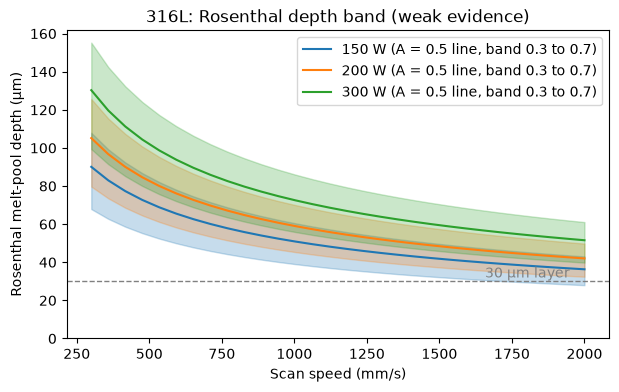

In [13]:
speeds = np.linspace(300, 2000, 30)
fig, ax = plt.subplots(figsize=(7, 4))
for P, colour in [(150, "tab:blue"), (200, "tab:orange"), (300, "tab:green")]:
    bands = [melt_pool_band(P, v)["band"] for v in speeds]
    lo = [b_[0]["depth_um"] for b_ in bands]
    mid = [b_[1]["depth_um"] for b_ in bands]
    hi = [b_[2]["depth_um"] for b_ in bands]
    ax.fill_between(speeds, lo, hi, color=colour, alpha=0.25)
    ax.plot(speeds, mid, color=colour, label=f"{P} W (A = 0.5 line, band 0.3 to 0.7)")
ax.axhline(30, color="grey", ls="--", lw=1)
ax.text(1950, 32, "30 µm layer", ha="right", color="grey")
ax.set_ylim(0, None)
ax.set_xlabel("Scan speed (mm/s)")
ax.set_ylabel("Rosenthal melt-pool depth (µm)")
ax.set_title("316L: Rosenthal depth band (weak evidence)")
ax.legend()
plt.show()

### 1.4 The tools as LangChain tools

An agent framework needs each tool as a name, a description and an argument schema. `tool(function,
parse_docstring=True)` builds all three from the function itself, so a tool and its function cannot drift apart.
Below is what the model sees.

In [14]:
from langchain_core.tools import tool

convert_units_tool = tool(convert_units, parse_docstring=True)
energy_density_tool = tool(energy_density, parse_docstring=True)
melt_pool_band_tool = tool(melt_pool_band, parse_docstring=True)
PART1_TOOLS = [convert_units_tool, energy_density_tool, melt_pool_band_tool]

for t in PART1_TOOLS:
    print(f"{t.name}: {t.description.splitlines()[0]}")
    for arg, spec in t.args.items():
        kind = spec.get("type") or "/".join(a.get("type", "?") for a in spec.get("anyOf", []))
        print(f"    {arg:<16} {kind:<14} {spec.get('description', '')}")

convert_units: Convert a power, speed, length or energy density value from one unit to another. Use this whenever a paper reports a value in a different unit from the one needed for a comparison
    value            number         the number to convert.
    from_unit        string         unit of the value, one of W, kW, mm/s, m/s, mm/min, m/min, um, µm, mm, m, J/mm3, J/m3.
    to_unit          string         unit wanted, same list; must measure the same quantity as from_unit.
energy_density: Volumetric energy density E_v = P/(v*h*t) in J/mm³ and linear energy density P/v in J/mm. Use this when a paper gives laser power, scan speed, hatch spacing and layer thickness and you need
    power_W          number         laser power in W.
    scan_speed_mm_s  number         scan speed in mm/s (convert m/s first).
    hatch_um         number         hatch spacing in µm.
    layer_um         number         layer thickness in µm.
melt_pool_band: Estimated melt-pool width and depth (µm) from the 

In [15]:
# Tests for 1.4
check("the tools keep the function names", [t.name for t in PART1_TOOLS] == ["convert_units", "energy_density", "melt_pool_band"])
check("argument descriptions with units come from the docstring", "laser power in W" in energy_density_tool.args["power_W"]["description"])
check("a tool call gives exactly the function's answer",
      energy_density_tool.invoke({"power_W": 200, "scan_speed_mm_s": 800, "hatch_um": 100, "layer_um": 30})["ved_J_mm3"]
      == energy_density(200, 800, 100, 30)["ved_J_mm3"])
check("convert_units as a tool: 0.8 m/s is 800 mm/s",
      convert_units_tool.invoke({"value": 0.8, "from_unit": "m/s", "to_unit": "mm/s"})["value"] == 800)
check("melt_pool_band as a tool returns the three absorptivities",
      [r["absorptivity"] for r in melt_pool_band_tool.invoke({"power_W": 200, "scan_speed_mm_s": 800})["band"]] == [0.3, 0.5, 0.7])

  ok  the tools keep the function names
  ok  argument descriptions with units come from the docstring
  ok  a tool call gives exactly the function's answer
  ok  convert_units as a tool: 0.8 m/s is 800 mm/s
  ok  melt_pool_band as a tool returns the three absorptivities


### Part 1: what this showed

Three tested tools, none needing a model, each returning numbers for code and a sentence for the agent. The melt-pool
band agrees with an independent formula but stays weak evidence.

## Part 2. How do I talk to the model reliably?

Part 1 keeps arithmetic in code. Now the model itself: can it give structured answers and call those tools?

- **Question:** How do I get reasoning, structured answers and tool calls out of GLM-5.2?
- **Course concept:** prompting, structured output and function calling (Modules 1 and 2)
- **Framework feature:** `ChatGLM` with `with_structured_output`, `bind_tools` and `create_agent`
- **Evidence:** the spike in 2.2: three output methods, tool calls, one agent round, tokens and time

### 2.1 The plain client

The cell below is the one deliberate live call in the notebook, a smoke test that the endpoint answers. Everything else
goes through the cache.

In [16]:
# Test: one short call (skipped off-network)
if LLM_OK:
    reasoning, answer = ask_llm([{"role": "user", "content": "In one sentence, what is volumetric energy density in PBF-LB?"}],
                                max_tokens=2000)
    print("answer:", answer)
    check("the model returned an answer", len(answer) > 10)
    check("the model returned its reasoning", len(reasoning) > 10)

--- reasoning (500 words) ---
1.  **Analyze the Request:**
    *   **Topic:** Volumetric energy density (VED) in PBF-LB (Powder Bed Fusion - Laser Beam).
    *   **Constraint:** Exactly one sentence.
    *   **Goal:** Define what VED is in this specific context.

2.  **Define the Core Concept:**
    *   What is VED in PBF-LB? It's a parameter used to quantify the amount of laser energy applied per unit volume of material during the printing process.
    *   Formula: $E_v = \frac{P}{v \cdot h \cdot t}$ (Laser Power / (Scan speed * Hatch spacing * Layer thickness)).
    *   Why is it used? It correlates process parameters to part density, microstructure, and mechanical properties.

3.  **Draft Initial Sentences:**
    *   *Draft 1:* Volumetric energy density in PBF-LB is a parameter that represents the amount of laser energy applied to a unit volume of powder, calculated by dividing the laser power by the product of scan speed, hatch spacing, and layer thickness.
    *   *Draft 2:* In PB

### 2.2 Spike: what GLM-5.2 can do through LangChain

Four checks with real calls, all cached and traced. `model_cell` skips a cell politely if an answer is neither cached
nor reachable.

**(a) Reasoning.** One question asked twice. The second answer must come from the cache, reasoning included.

In [17]:
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage


def model_cell(fn):
    """Run a cell's model calls. If an answer is neither cached nor reachable, say so and return None."""
    try:
        return fn()
    except ModelUnavailable as e:
        print(f"Skipped: {e}. Connect to the endpoint and re-run this cell.")
        return None


TRACER.start("part2_spike")
SHORT_QUESTION = [HumanMessage("In one sentence, what is volumetric energy density in PBF-LB?")]
spike_a = model_cell(lambda: [glm.invoke(SHORT_QUESTION, config={"metadata": {"agent": "spike (a) reasoning"}})
                              for _ in range(2)])
if spike_a:
    print("\nanswer:", spike_a[0].content)

--- [spike (a) reasoning] from cache: 3.14 s, 28 in / 620 out tokens (569 reasoning) ---
reasoning (365 words): 1.  **Analyze the Request:**
    *   **Topic:** Volumetric energy density (VED) in Powder Bed Fusion - Laser Beam (PBF-LB).
    *   **Constraint:** Exactly one sentence.
    *   **Goal:** Define what it is concisely and accurately.

2.  **Deconstruct Volumetric Energy Density in PBF-LB:**
    *   What is it? A parameter used to quantify the amount of energy applied by the laser to a specific volume of powder.
    *   What is the formula? $VED = \frac{P}{v \cdot h \cdot t}$ (Laser Power divided by scan speed, hatch spacing, and layer thickness).
    *   What is its purpose? It dictates the thermal input, which determines melt pool dynamics, microstructure, defect formation (porosity), and overall part density/quality.

3.  **Draft Initial Sentences:**
    *   *Draft 1:* Volumetric energy density in PBF-LB is a process parameter that defines the amount of laser energy applied t

In [18]:
# Tests for (a)
if spike_a:
    first, second = spike_a
    check("the reasoning text is kept", len(reasoning_of(first)) > 50)
    check("the token count shows reasoning tokens", first.usage_metadata["output_token_details"]["reasoning"] > 0)
    check("the second answer came from the cache", load_trace("part2_spike")[1]["cached"])
    check("with the same reasoning and answer", reasoning_of(second) == reasoning_of(first) and second.content == first.content)
    check("and it knows how long the real call took", second.response_metadata["seconds"] > 0)

  ok  the reasoning text is kept
  ok  the token count shows reasoning tokens
  ok  the second answer came from the cache
  ok  with the same reasoning and answer
  ok  and it knows how long the real call took


**(b) Structured output** means the model must answer in a fixed schema that code can read, not in free text. LangChain
offers three ways: `json_schema` (the server enforces the schema), `function_calling` (the schema becomes a forced tool
call) and `json_mode` (valid JSON only). Each extracts two records from two made-up test passages.

In [19]:
class SpikeRecord(BaseModel):
    """One parameter set and the density measured for it, copied from the passage."""
    power_W: float | None = Field(None, description="laser power in W")
    speed_mm_s: float | None = Field(None, description="scan speed in mm/s")
    hatch_um: float | None = Field(None, description="hatch spacing in µm")
    layer_um: float | None = Field(None, description="layer thickness in µm")
    density_pct: float | None = Field(None, description="relative density in %")
    density_method: str | None = Field(None, description="how density was measured, e.g. Archimedes")
    quote: str = Field(description="the exact sentence the values come from")


class SpikeRecords(BaseModel):
    """All parameter sets with a measured density in the passage."""
    records: list[SpikeRecord]


SPIKE_PASSAGES = {   # MADE-UP passages for this test only
    "p1": ("Cubes were built with a laser power of 195 W, a scan speed of 750 mm/s, a hatch spacing of 90 µm and a "
           "layer thickness of 30 µm. Their relative density, measured by the Archimedes method, was 99.62 %. "
           "A second set at 170 W and 600 mm/s with the same hatch and layer reached 99.10 %."),
    "p2": ("Samples were produced at 30 µm layer thickness with 120 µm hatch distance. At 140 W and 100 mm/s the "
           "relative density from image analysis of polished cross sections was 97.76 %, while 190 W and 800 mm/s "
           "gave 99.31 %."),
}
SPIKE_EXPECTED = {"p1": [(195, 750, 90, 30, 99.62), (170, 600, 90, 30, 99.10)],
                  "p2": [(140, 100, 120, 30, 97.76), (190, 800, 120, 30, 99.31)]}
EXTRACT_RULES = ("You extract process parameters from a PBF-LB paper passage. Copy numbers exactly as written, "
                 "never calculate, leave a field empty if it is not stated.")


def spike_extract(method: str, pid: str) -> dict:
    rules = EXTRACT_RULES
    if method == "json_mode":                      # json_mode needs the schema written into the prompt
        rules += " Answer only with JSON matching this schema: " + json.dumps(SpikeRecords.model_json_schema())
    chain = glm.with_structured_output(SpikeRecords, method=method, include_raw=True)
    out = chain.invoke([SystemMessage(rules), HumanMessage(f"Passage:\n{SPIKE_PASSAGES[pid]}")],
                       config={"metadata": {"agent": f"spike (b) {method}"}})
    raw, parsed = out["raw"], out["parsed"]
    got = [(r.power_W, r.speed_mm_s, r.hatch_um, r.layer_um, r.density_pct) for r in parsed.records] if parsed else None
    usage = raw.usage_metadata or {}
    return {"method": method, "passage": pid, "parsed": parsed is not None, "correct": got == SPIKE_EXPECTED[pid],
            "seconds": raw.response_metadata.get("seconds"), "out_tokens": usage.get("output_tokens"),
            "reasoning_tokens": (usage.get("output_token_details") or {}).get("reasoning"),
            "reasoning_words": len(reasoning_of(raw).split()), "error": str(out["parsing_error"] or "")[:60]}


SO_METHODS = ["json_schema", "function_calling", "json_mode"]
spike_b = model_cell(lambda: [spike_extract(m, p) for m in SO_METHODS for p in SPIKE_PASSAGES])
if spike_b:
    print()
    print_rows(spike_b, [("method", "method", 16), ("passage", "passage", 7), ("parsed", "parsed", 6),
                         ("correct", "correct", 7), ("seconds", "s", 5), ("out_tokens", "tok out", 7),
                         ("reasoning_tokens", "reason", 6), ("reasoning_words", "reason words", 12), ("error", "error", 20)])

--- [spike (b) json_schema] from cache: 5.54 s, 130 in / 1285 out tokens (1070 reasoning) ---
reasoning (597 words): 1.  **Analyze the Request:**
    *   Goal: Extract process parameters from the provided PBF-LB paper passage.
    *   Rule 1: Copy numbers exactly as written.
    *   Rule 2: Never calculate.
    *   Rule 3: Leave a field empty if not stated.
    *   Input passage: "Cubes were built with a laser power of 195 W, a scan speed of 750 mm/s, a hatch spacing of 90 µm and a layer thickness of 30 µm. Their relative density, measured by the Archimedes method, was 99.62 %. A second set at 170 W and 600 mm/s with the same hatch and layer reached 99.10 %."

2.  **Analyze the Passage for Parameters:**
    *   "laser power of 195 W" -> Laser Power 1: 195 W
    *   "scan speed of 750 mm/s" -> Scan Speed 1: 750 mm/s
    *   "hatch spacing of 90 µm" -> Hatch Spacing 1: 90 µm
    *   "layer thickness of 30 µm" -> Layer Thickness 1: 30 µm
    *   "relative density... was 99.62 %" -> Relati

In [20]:
# Tests for (b)
if spike_b:
    for m in SO_METHODS:
        rows = [r for r in spike_b if r["method"] == m]
        check(f"{m}: both passages parsed and every number copied correctly", all(r["parsed"] and r["correct"] for r in rows))
    check("json_schema keeps the model's reasoning", all(r["reasoning_words"] > 0 for r in spike_b if r["method"] == "json_schema"))

  ok  json_schema: both passages parsed and every number copied correctly
  ok  function_calling: both passages parsed and every number copied correctly
  ok  json_mode: both passages parsed and every number copied correctly
  ok  json_schema keeps the model's reasoning


**Which method?** All three were correct. I use `json_schema`: the server enforces the schema and the model still
reasons fully first. `function_calling` was faster but reasoned less, so it is the fallback. `json_mode` enforces
nothing.

**(c) Tool calls.** The model answers with a tool name and arguments, my code runs the function, and the result goes
back to the model. Here once by hand, then with `create_agent`, LangChain's ready-made agent loop, which does the
round trip itself.

In [21]:
from langchain.agents import create_agent
from langchain_core.tools import tool

# energy_density_tool is the Part 1 function as a LangChain tool (1.4)
print("Tool the model sees:", energy_density_tool.name, "| arguments:", list(energy_density_tool.args))


def tool_round_by_hand():
    bound = glm.bind_tools([energy_density_tool])
    cfg = {"metadata": {"agent": "spike (c) bind_tools"}}
    msgs = [HumanMessage("What is the volumetric energy density for 200 W, 800 mm/s, 100 µm hatch and 30 µm layers?")]
    ask = bound.invoke(msgs, config=cfg)
    result = energy_density_tool.invoke(ask.tool_calls[0]["args"])            # my code runs the tool, not the model
    msgs += [ask, ToolMessage(result["summary"], tool_call_id=ask.tool_calls[0]["id"])]
    final = bound.invoke(msgs, config=cfg)
    return ask, result, final


def tool_round_by_agent():
    agent = create_agent(model=glm, tools=[energy_density_tool],
                         system_prompt="You answer PBF-LB questions. Never calculate yourself, use the tools.")
    return agent.invoke({"messages": [HumanMessage("Energy density at 180 W, 700 mm/s, 90 µm hatch and 40 µm layers?")]},
                        config={"metadata": {"agent": "spike (c) create_agent"}})


spike_c = model_cell(lambda: (tool_round_by_hand(), tool_round_by_agent()))
if spike_c:
    (ask, tool_result, final), agent_out = spike_c
    print("\nBy hand: final answer:", final.content[:300])
    print("\ncreate_agent, message types:", [m.type for m in agent_out["messages"]])
    print("create_agent, final answer:", agent_out["messages"][-1].content[:300])

Tool the model sees: energy_density | arguments: ['power_W', 'scan_speed_mm_s', 'hatch_um', 'layer_um']
--- [spike (c) bind_tools] from cache: 0.77 s, 349 in / 73 out tokens (36 reasoning) ---
reasoning (23 words): The user wants to calculate the volumetric energy density given the parameters: 200 W, 800 mm/s, 100 µm hatch, 30 µm layer thickness.
tool call: energy_density({'power_W': 200, 'scan_speed_mm_s': 800, 'hatch_um': 100, 'layer_um': 30})
--- [spike (c) bind_tools] from cache: 1.42 s, 473 in / 216 out tokens (15 reasoning) ---
reasoning (13 words): The function returned the results. Let me present them clearly to the user.
--- [spike (c) create_agent] from cache: 0.69 s, 361 in / 69 out tokens (32 reasoning) ---
reasoning (20 words): The user wants to calculate energy density with given parameters: 180 W, 700 mm/s, 90 µm hatch, 40 µm layers.
tool call: energy_density({'power_W': 180, 'scan_speed_mm_s': 700, 'hatch_um': 90, 'layer_um': 40})
--- [spike (c) create_agent] from cache

In [22]:
# Tests for (c)
if spike_c:
    check("bind_tools: the model asked for energy_density", ask.tool_calls and ask.tool_calls[0]["name"] == "energy_density")
    check("with the right arguments and units",
          ask.tool_calls[0]["args"] == {"power_W": 200, "scan_speed_mm_s": 800, "hatch_um": 100, "layer_um": 30})
    check("the final answer uses the tool's number (83.3 J/mm³)", "83.3" in final.content)
    kinds = [m.type for m in agent_out["messages"]]
    check("create_agent ran a full round: question, tool call, tool result, answer", kinds == ["human", "ai", "tool", "ai"])
    check("create_agent's answer uses the tool result (71.4 J/mm³)", "71.4" in agent_out["messages"][-1].content)
    check("the reasoning is kept at every agent step",
          all(reasoning_of(m) for m in agent_out["messages"] if m.type == "ai"))

  ok  bind_tools: the model asked for energy_density
  ok  with the right arguments and units
  ok  the final answer uses the tool's number (83.3 J/mm³)
  ok  create_agent ran a full round: question, tool call, tool result, answer
  ok  create_agent's answer uses the tool result (71.4 J/mm³)
  ok  the reasoning is kept at every agent step


**(d) Time and tokens.** The trace holds what each call cost. The seconds are those of the real call, also on a replay.

In [23]:
show_trace("part2_spike")

Trace 'part2_spike': 12 model calls
#    agent / node            source  s       tok in  tok out  reason  answer or tool call                                         
---  ----------------------  ------  ------  ------  -------  ------  ------------------------------------------------------------
1    spike (a) reasoning     cache   3.14    28      620      569     In PBF-LB, volumetric energy density is a critical proces...
2    spike (a) reasoning     cache   3.14    28      620      569     In PBF-LB, volumetric energy density is a critical proces...
3    spike (b) json_schema   cache   5.54    130     1285     1070    {   "records": [     {       "power_W": 195,       "speed...
4    spike (b) json_schema   cache   4.15    107     933      745     {   "records": [     {       "power_W": 140,       "speed...
5    spike (b) function_...  cache   1.88    560     330      127     SpikeRecords({'records': [{'power_W': 195, 'speed_mm_s': ...
6    spike (b) function_...  cache   1.71    53

In [24]:
# Tests for (d): every spike call is in the trace with its reasoning, tokens and time
if spike_a and spike_b and spike_c:
    spike_trace = load_trace("part2_spike")
    check("2 + 6 + 2 + 2 = 12 model calls traced", len(spike_trace) == 12)
    check("every call has its reasoning, token counts and seconds",
          all(r["reasoning"] and r["output_tokens"] and r["seconds"] for r in spike_trace))
    check("the repeated question in (a) was replayed from the cache", spike_trace[1]["cached"])

  ok  2 + 6 + 2 + 2 = 12 model calls traced
  ok  every call has its reasoning, token counts and seconds
  ok  the repeated question in (a) was replayed from the cache


### Part 2: what this showed

GLM-5.2 gives reliable structured answers, keeps its reasoning through `ChatGLM` and calls tools. It does not copy
quotes word for word, so every agent must cite passage ids that code can check.

## Part 3. Where does the knowledge come from? (retrieval)

Part 2 showed the model must cite passages that code can check. This Part builds the library those passages come from.

- **Question:** Which papers and passages hold the parameters and densities, and how does the agent find them?
- **Course concept:** retrieval: chunking, embeddings, a vector store, MMR, a metadata filter (Module 3)
- **Framework feature:** Europe PMC API, Qwen3 embeddings in ChromaDB, then LangChain's splitter, `Chroma` and retriever
- **Evidence:** the distractor kept out (3.6), the demo with and without retrieval (3.8), the frozen library (3.9)

The facts are in papers, not in the model, and the source check needs the exact passage behind each value. So the
agent retrieves only the passages it needs. Europe PMC serves open-access full text as XML with tables intact.
Details: decisions.md, 2026-10-24.

In [25]:
import re
import xml.etree.ElementTree as ET
import requests

EPMC = "https://www.ebi.ac.uk/europepmc/webservices/rest"
PAPERS = DATA / "papers"
PAPERS.mkdir(exist_ok=True)


def search_papers(query: str, n: int = 30) -> list[dict]:
    """Search Europe PMC and return paper records (pmcid, doi, title, year, journal)."""
    r = requests.get(f"{EPMC}/search", params={"query": query, "format": "json", "pageSize": n,
                                                "resultType": "lite"}, timeout=30)
    r.raise_for_status()
    return [{"pmcid": w["pmcid"], "doi": w.get("doi", ""), "title": w["title"], "year": w.get("pubYear"),
             "journal": w.get("journalTitle", "")} for w in r.json()["resultList"]["result"] if w.get("pmcid")]


def fetch_fulltext(pmcid: str) -> Path:
    """Download the full-text XML once and cache it in data/papers/."""
    path = PAPERS / f"{pmcid}.xml"
    if not path.exists():
        r = requests.get(f"{EPMC}/{pmcid}/fullTextXML", timeout=60)
        r.raise_for_status()
        path.write_bytes(r.content)
    return path

### 3.1 Reading a paper and labelling its alloy

Tables become plain rows (`cell | cell | cell`), so numbers stay next to their headers and units. Each paper gets an
alloy label from its **title** first, because a 25CrMo4 paper may still mention 316L in its text.

In [26]:
GRADES = {  # name -> regular expression
    "316L": r"316\s?L", "304L": r"\b304L?\b", "17-4PH": r"17-4\s?PH", "25CrMo4": r"25CrMo4",
    "AlSi10Mg": r"AlSi10Mg", "Ti-6Al-4V": r"Ti-?6Al-?4V", "IN718": r"(IN|Inconel\s?)718",
    "H13": r"\bH13\b", "maraging": r"[Mm]araging",
}


def text_of(el) -> str:
    return re.sub(r"\s+", " ", "".join(el.itertext())).strip() if el is not None else ""


def detect_alloy(title: str, full_text: str) -> str:
    # Title first: it names the alloy the paper is actually about.
    in_title = [g for g, rx in GRADES.items() if re.search(rx, title)]
    if in_title:
        return in_title[0]
    counts = {g: len(re.findall(rx, full_text)) for g, rx in GRADES.items()}
    return max(counts, key=counts.get) if max(counts.values()) else "unknown"


def parse_paper(path: Path, paragraph_sep: str = " ") -> dict:
    """Parse a Europe PMC JATS XML file into title, doi, sections, tables and alloy.

    paragraph_sep joins the paragraphs of a section (the frozen library in 3.9 uses "\n\n").
    """
    root = ET.parse(path).getroot()
    title = text_of(root.find(".//article-title"))
    doi = text_of(root.find(".//article-id[@pub-id-type='doi']"))
    tables = []
    for tw in root.iter("table-wrap"):  # tables sit in <body> or <floats-group>
        head = f"{text_of(tw.find('label'))} {text_of(tw.find('caption'))}".strip()
        rows = [" | ".join(text_of(c) for c in tr if c.tag in ("td", "th")) for tr in tw.iter("tr")]
        rows = [r for r in rows if r.strip(" |")]
        if rows:
            tables.append({"label": head, "text": "\n".join(rows)})
    sections = []
    body = root.find(".//body")
    if body is not None:
        for sec in body.findall("sec"):
            paras = [text_of(p) for p in sec.iter("p")]
            sections.append({"title": text_of(sec.find("title")) or "Body", "text": paragraph_sep.join(p for p in paras if p)})
    full = " ".join(s["text"] for s in sections) + " " + " ".join(t["text"] for t in tables)
    return {"title": title, "doi": doi, "sections": sections, "tables": tables, "alloy": detect_alloy(title, full)}


def has_parameter_table(paper: dict) -> bool:
    # At least one table that mentions power, speed and density or porosity.
    for t in paper["tables"]:
        s = (t["label"] + " " + t["text"]).lower()
        if "power" in s and ("speed" in s or "velocity" in s or "mm/s" in s) and ("density" in s or "porosity" in s):
            return True
    return False

### 3.2 Choosing the papers

Open-access, CC BY, 316L PBF-LB papers with a parameter table: five for this first slice, plus one **distractor** about
another steel to test the alloy filter. The selection is saved, so reruns use the same papers.

In [27]:
SELECTION = PAPERS / "selection.json"
QUERY = ('("316L") AND ("laser powder bed fusion" OR "selective laser melting") AND '
         '("relative density" OR "porosity") AND ("scan speed" OR "scanning speed") AND '
         'OPEN_ACCESS:y AND HAS_FT:y AND LICENSE:"cc by"')

if SELECTION.exists():
    selection = json.loads(SELECTION.read_text(encoding="utf-8"))
else:
    selection, distractor = [], None
    for hit in search_papers(QUERY, n=40):
        paper = parse_paper(fetch_fulltext(hit["pmcid"]))
        if not has_parameter_table(paper):
            continue
        if paper["alloy"] == "316L" and len(selection) < 5:
            selection.append({**hit, "alloy": "316L", "role": "source"})
        elif paper["alloy"] not in ("316L", "unknown") and distractor is None:
            distractor = {**hit, "alloy": paper["alloy"], "role": "distractor"}
        if len(selection) == 5 and distractor:
            break
    selection.append(distractor)
    SELECTION.write_text(json.dumps(selection, indent=1), encoding="utf-8")

papers = {s["pmcid"]: parse_paper(fetch_fulltext(s["pmcid"])) for s in selection}
for s in selection:
    p = papers[s["pmcid"]]
    print(f"{s['role']:<10} {s['pmcid']}  {p['alloy']:<8} {len(p['tables']):>2} tables  {s['year']}  {p['title'][:70]}")

source     PMC13073740  316L      5 tables  2026  A Lattice Boltzmann Thermal Model for Predicting Melt Pool Geometry in
source     PMC12735063  316L      5 tables  2025  Role of Laser Powder Bed Fusion Process Factors in Determining the Por
source     PMC13208960  316L      3 tables  2026  Novel Design in Venturi-Type Nozzle by Selective Laser Melting for Enh
source     PMC12387571  316L      4 tables  2025  Manufacturing, Microstructure, and Mechanics of 316L SS Biomaterials b
source     PMC12194911  316L     18 tables  2025  A Review of Optimization of Additively Manufactured 316/316L Stainless
distractor PMC12693020  25CrMo4   8 tables  2025  Laser Powder Bed Fusion of 25CrMo4 Steel: Effect of Process Parameters


In [28]:
# Tests for the paper library
check("5 source papers and 1 distractor", [s["role"] for s in selection].count("source") == 5
      and [s["role"] for s in selection].count("distractor") == 1)
check("every source paper is labelled 316L", all(papers[s["pmcid"]]["alloy"] == "316L" for s in selection if s["role"] == "source"))
check("the distractor is another alloy", all(papers[s["pmcid"]]["alloy"] != "316L" for s in selection if s["role"] == "distractor"))
check("every paper has a parameter table", all(has_parameter_table(p) for p in papers.values()))
check("every paper has a DOI", all(p["doi"] for p in papers.values()))

  ok  5 source papers and 1 distractor
  ok  every source paper is labelled 316L
  ok  the distractor is another alloy
  ok  every paper has a parameter table
  ok  every paper has a DOI


### 3.3 Chunking

Text is cut into windows of about **250 words with 50 overlap**, so a sentence cut at a boundary appears whole in the
next chunk. **Tables are never split**: a row means nothing without its header and units. Every chunk carries its
paper, DOI, alloy and section or table. Chunks are small because the answer is often one table row.

In [29]:
def chunk_paper(pmcid: str, paper: dict, size: int = 250, overlap: int = 50) -> list[dict]:
    """Split a parsed paper into text chunks (overlapping word windows) and whole-table chunks."""
    meta = {"pmcid": pmcid, "doi": paper["doi"], "title": paper["title"][:200], "alloy": paper["alloy"]}
    chunks = []
    for sec in paper["sections"]:
        words = sec["text"].split()
        for start in range(0, max(len(words) - overlap, 1), size - overlap):
            piece = " ".join(words[start:start + size])
            if len(piece.split()) >= 30:  # skip scraps
                chunks.append({"text": piece, **meta, "where": sec["title"][:80], "kind": "text"})
    for t in paper["tables"]:
        chunks.append({"text": f"{t['label']}\n{t['text']}", **meta, "where": (t["label"] or "Table")[:80], "kind": "table"})
    for i, c in enumerate(chunks):
        c["id"] = f"{pmcid}-{i:03d}"
    return chunks


chunks = [c for pmcid, p in papers.items() for c in chunk_paper(pmcid, p)]
n_tables = sum(c["kind"] == "table" for c in chunks)
print(f"{len(chunks)} chunks: {len(chunks) - n_tables} text, {n_tables} tables")

328 chunks: 285 text, 43 tables


In [30]:
# Tests for chunking
text_chunks = [c for c in chunks if c["kind"] == "text"]
check("text chunks are at most 250 words", max(len(c["text"].split()) for c in text_chunks) <= 250)
check("one chunk per table (tables are never split)", n_tables == sum(len(p["tables"]) for p in papers.values()))
check("chunk ids are unique", len({c["id"] for c in chunks}) == len(chunks))
check("every chunk knows its paper, alloy and place", all(c["pmcid"] and c["alloy"] and c["where"] for c in chunks))
first = chunk_paper("x", {"doi": "d", "title": "t", "alloy": "316L", "tables": [],
                          "sections": [{"title": "S", "text": " ".join(f"w{i}" for i in range(400))}]})
check("consecutive text chunks overlap by 50 words", first[0]["text"].split()[-50:] == first[1]["text"].split()[:50])

  ok  text chunks are at most 250 words
  ok  one chunk per table (tables are never split)
  ok  chunk ids are unique
  ok  every chunk knows its paper, alloy and place
  ok  consecutive text chunks overlap by 50 words


### 3.4 Embeddings and the vector database

An embedding turns a passage into a vector, so similar meanings sit close together. **Qwen3-Embedding-0.6B** runs on
the laptop GPU and, unlike the lab's MiniLM, does not cut long tables at 256 tokens. The vectors go into **ChromaDB**
with their metadata, so a search can be filtered by alloy.

In [31]:
import torch
import chromadb
from sentence_transformers import SentenceTransformer

EMBED_MODEL = "Qwen/Qwen3-Embedding-0.6B"
_device = "cuda" if torch.cuda.is_available() else "cpu"
_kw = {"model_kwargs": {"torch_dtype": torch.float16}} if _device == "cuda" else {}
t0 = time.time()
try:  # use the cached copy without contacting Hugging Face (avoids hangs on a changing network)
    embedder = SentenceTransformer(EMBED_MODEL, device=_device, local_files_only=True, **_kw)
except Exception:  # first run: download it (about 1.2 GB)
    embedder = SentenceTransformer(EMBED_MODEL, device=_device, **_kw)
print(f"embedding model loaded on {_device} in {time.time() - t0:.0f} s")

chroma = chromadb.PersistentClient(path=str(DATA / "chroma"))
library = chroma.get_or_create_collection("papers_v1", metadata={"hnsw:space": "cosine"})

if library.count() != len(chunks):  # (re)build when the chunks changed
    chroma.delete_collection("papers_v1")
    library = chroma.create_collection("papers_v1", metadata={"hnsw:space": "cosine"})
    t0 = time.time()
    vectors = embedder.encode([c["text"] for c in chunks], batch_size=4, normalize_embeddings=True)
    print(f"embedded {len(chunks)} chunks in {time.time() - t0:.0f} s")
    library.add(ids=[c["id"] for c in chunks], embeddings=vectors.tolist(), documents=[c["text"] for c in chunks],
                metadatas=[{k: c[k] for k in ("pmcid", "doi", "title", "alloy", "where", "kind")} for c in chunks])
print("chunks in the vector database:", library.count())

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:  10%|▉         | 30/310 [00:00<00:00, 289.67it/s]

Loading weights:  23%|██▎       | 71/310 [00:00<00:00, 346.93it/s]

Loading weights:  37%|███▋      | 114/310 [00:00<00:00, 372.61it/s]

Loading weights:  50%|████▉     | 154/310 [00:00<00:00, 369.33it/s]

Loading weights:  63%|██████▎   | 196/310 [00:00<00:00, 381.19it/s]

Loading weights:  76%|███████▌  | 235/310 [00:00<00:00, 382.75it/s]

Loading weights:  88%|████████▊ | 274/310 [00:00<00:00, 377.50it/s]

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 378.21it/s]

embedding model loaded on cuda in 3 s


chunks in the vector database: 328


In [32]:
check("every chunk is in the database", library.count() == len(chunks))
check("vectors have 1024 dimensions", len(library.get(limit=1, include=["embeddings"])["embeddings"][0]) == 1024)

  ok  every chunk is in the database
  ok  vectors have 1024 dimensions


### 3.5 Searching: top 5, diverse, filtered by alloy

`search_passages()` takes the 60 closest chunks, picks 5 by **maximal marginal relevance** (relevant but not alike)
and allows **at most 2 per paper**. Without the cap, 19 of the 20 closest chunks came from one paper, which the agent
would take for agreement.

In [33]:
def search_passages(question: str, k: int = 5, alloy: str | None = "316L", fetch_k: int = 60,
                    lam: float = 0.7, max_per_paper: int = 2) -> list[dict]:
    """Find the k passages most relevant to a question, with citations.

    Use this to look up what the papers report (process parameters, densities, methods) before answering.
    alloy filters the library to one alloy (None searches everything). Returns a list of passages, each with
    text, pmcid, doi, title, where (section or table) and score (cosine similarity, higher is closer).
    """
    q = embedder.encode([question], prompt_name="query", normalize_embeddings=True)[0]
    res = library.query(query_embeddings=[q.tolist()], n_results=fetch_k, where={"alloy": alloy} if alloy else None,
                        include=["documents", "metadatas", "embeddings"])
    docs, metas, embs = res["documents"][0], res["metadatas"][0], np.array(res["embeddings"][0])
    relevance = embs @ q
    picked, per_paper = [], {}
    while len(picked) < min(k, len(docs)):
        best, best_score = None, -np.inf
        for i in range(len(docs)):
            if i in picked or per_paper.get(metas[i]["pmcid"], 0) >= max_per_paper:
                continue
            redundancy = max((float(embs[i] @ embs[j]) for j in picked), default=0.0)
            score = lam * relevance[i] - (1 - lam) * redundancy
            if score > best_score:
                best, best_score = i, score
        if best is None:
            break
        picked.append(best)
        per_paper[metas[best]["pmcid"]] = per_paper.get(metas[best]["pmcid"], 0) + 1
    return [{"text": docs[i], **metas[i], "score": round(float(relevance[i]), 3)} for i in picked]


def show_passages(passages, width=160):
    for n, p in enumerate(passages, 1):
        print(f"[{n}] {p['score']:.3f}  {p['alloy']:<8} {p['pmcid']}  {p['where'][:60]}")
        print("     " + p["text"][:width].replace("\n", " / ") + " ...")

In [34]:
LAYER_UM = 30  # layer thickness the engineer asked for: power and speed only make sense together with it
QUESTION = (f"For 316L at a layer thickness of {LAYER_UM} µm, which laser power and scan speed gave the highest "
            "relative density in these studies, and what density was reported?")
hits = search_passages(QUESTION)
show_passages(hits)

check("5 passages returned", len(hits) == 5)
check("all passages are 316L", all(h["alloy"] == "316L" for h in hits))
check("at most 2 passages per paper", max(sum(h["pmcid"] == p for h in hits) for p in {h["pmcid"] for h in hits}) <= 2)
check("passages are ordered by MMR, all reasonably relevant", min(h["score"] for h in hits) > 0.3)

[1] 0.756  316L     PMC12387571  2. Methodology
     the laser beam orientation between adjacent layers to promote better adhesion and enhance mechanical performance. For example, when the first layer was scanned  ...
[2] 0.735  316L     PMC13208960  Table 2 Experimental conditions and measured density for the
     Table 2 Experimental conditions and measured density for the SLM SS316 specimens. / Specimens | Laser Power (W) | Scan Speed (mm/s) | Laser Energy Density (J/mm3) ...
[3] 0.701  316L     PMC12194911  2. DED, SLM, and EBM Process Parameter Effects and Optimizat
     hardness variation, though the hardness value itself may be slightly lower. In contrast, 30 µm, 80 µm, and 100 µm thicknesses show better hardness but lead to h ...
[4] 0.711  316L     PMC12387571  3. Results
     as a function of laser power (140 to 190 W) and scanning speed (600 to 900 mm/s). Porosity decreased with increasing laser power and decreasing scanning speed.  ...
[5] 0.637  316L     PMC13073740  4. Re

### 3.6 Failure mode: the similarity trap

Search ranks by meaning, not by alloy. The distractor describes the same kind of experiment for another steel, so it
looks relevant. Below: the same question without and with the alloy filter.

In [35]:
distractor_id = next(s["pmcid"] for s in selection if s["role"] == "distractor")
unfiltered = search_passages(QUESTION, alloy=None, k=10)
print("WITHOUT alloy filter:")
show_passages(unfiltered, width=100)
print("\nWITH alloy filter (316L): distractor present?", any(h["pmcid"] == distractor_id for h in hits))

check("with the filter, the distractor never appears", not any(h["pmcid"] == distractor_id for h in hits))

WITHOUT alloy filter:
[1] 0.756  316L     PMC12387571  2. Methodology
     the laser beam orientation between adjacent layers to promote better adhesion and enhance mechanical ...
[2] 0.735  316L     PMC13208960  Table 2 Experimental conditions and measured density for the
     Table 2 Experimental conditions and measured density for the SLM SS316 specimens. / Specimens | Laser  ...
[3] 0.701  316L     PMC12194911  2. DED, SLM, and EBM Process Parameter Effects and Optimizat
     hardness variation, though the hardness value itself may be slightly lower. In contrast, 30 µm, 80 µ ...
[4] 0.711  316L     PMC12387571  3. Results
     as a function of laser power (140 to 190 W) and scanning speed (600 to 900 mm/s). Porosity decreased ...
[5] 0.637  316L     PMC13073740  4. Results
     187 μm, while the corresponding melt pool depths are about 79 μm, 81 μm, and 68 μm. These values ind ...
[6] 0.597  25CrMo4  PMC12693020  Table 2 The parameters of the printing material.
     Table 2 The par

### 3.7 Stated conditions

Power and speed mean little without the **layer thickness** and hatch, which papers state in the Methods, away from
the results table. `stated_conditions()` collects those sentences by code lookup, not by search.

In [36]:
COND_TERMS = re.compile(r"(layer thickness|layer height|powder layer|hatch (spacing|distance)|spot (size|diameter))", re.I)
COND_NUMBER = re.compile(r"\d+(\.\d+)?\s?(µm|μm|um|mm)\b")
METHODS = re.compile(r"method|experiment|material|setup|procedure", re.I)


def stated_conditions(pmcid: str, max_sentences: int = 3, library: dict | None = None) -> list[dict]:
    """Return sentences from one paper that state its layer thickness, hatch spacing or spot size with a number.

    Use this to find the experimental conditions behind a retrieved result. Methods sections come first;
    sentences that cite other work ([n]) are skipped. Each item has the sentence and its section.
    library: parsed papers to read from (default: the five Checkpoint 3.1 papers of 3.2).
    """
    found = []
    for sec in (library or papers)[pmcid]["sections"]:
        for sentence in re.split(r"(?<=[.;])\s+(?=[A-Z])", sec["text"]):
            if COND_TERMS.search(sentence) and COND_NUMBER.search(sentence) and len(sentence) < 400 \
                    and not re.search(r"\[\d+", sentence):
                found.append({"pmcid": pmcid, "where": sec["title"][:80], "text": sentence,
                              "methods": bool(METHODS.search(sec["title"]))})
    found.sort(key=lambda s: not s["methods"])  # Methods first, otherwise keep the paper's order
    return found[:max_sentences]


def conditions_block(conds):
    return "\n".join(f"[C{n}] {c['pmcid']} | {c['where']}: {c['text']}" for n, c in enumerate(conds, 1))


conditions = [c for pmcid in dict.fromkeys(h["pmcid"] for h in hits) for c in stated_conditions(pmcid)]
print(conditions_block(conditions))

[C1] PMC12387571 | 2. Methodology: Based on these considerations, the laser spot size for fabricating 316L stainless steel specimens in this study was set to 138 µm.
[C2] PMC12387571 | 2. Methodology: Other processing parameters were kept constant, following the manufacturer’s recommendations: laser spot diameter of 138 µm, hatch spacing of 90 µm, and powder layer thickness of 30 µm.
[C3] PMC13208960 | 2. Experimental Setup: The SLM structures with dimensions of 2 × 2 × 5 mm3, a layer thickness of 30 μm, and a hatch spacing of 120 μm were used for every conditions.
[C4] PMC13208960 | 4. Conclusions: The SLM structures were formed on the distribution plate of Venturi nozzle under the optimal condition of SLM process, as follows: a layer thickness of 30 μm, a hatch spacing of 120 μm, a laser power of 140 W, and a scanning speed of 100 mm/s.
[C5] PMC12194911 | 2. DED, SLM, and EBM Process Parameter Effects and Optimization: Studies indicate that a 60 µm layer thickness reduces hardness va

In [37]:
# Tests for stated_conditions
nozzle = stated_conditions("PMC13208960")
check("the nozzle study states 30 µm layers", any("30 μm" in s["text"] or "30 µm" in s["text"] for s in nozzle))
check("its hatch spacing (120 µm) is found too", any("120" in s["text"] for s in nozzle))
check("Methods sentences come first", nozzle[0]["methods"])
check("sentences citing other studies are skipped", not any(re.search(r"\[\d+", s["text"]) for s in conditions))
check("only papers from the search results are looked up", {c["pmcid"] for c in conditions} <= {h["pmcid"] for h in hits})

  ok  the nozzle study states 30 µm layers
  ok  its hatch spacing (120 µm) is found too
  ok  Methods sentences come first
  ok  sentences citing other studies are skipped
  ok  only papers from the search results are looked up


### 3.8 Demo: does retrieval change the answer?

The same question goes to GLM-5.2 alone, then with the 5 passages, their conditions and a rule to cite every number
or say "not reported". The answers were submitted with Checkpoint 3.1, so the cell replays them and checks that
retrieval still returns the same passages.

In [38]:
GROUNDED_SYSTEM = (
    "You answer questions about metal 3D printing (PBF-LB) using ONLY the numbered passages and the stated "
    "conditions provided. Every number you give must come from them; cite it as [n] or [Cn] with the paper ID "
    "and the table or section. Power and speed only make sense together with layer thickness: for every result, "
    "give the layer thickness and hatch spacing from the passages or stated conditions of the same paper, or say "
    "'layer thickness not stated'. Treat results at a different layer thickness from the one asked as different "
    "conditions and say so. If the passages do not contain the answer, say 'not reported in the retrieved "
    "passages'. Do not use outside knowledge and do not do arithmetic beyond reading values.")


def passages_block(passages):
    return "\n\n".join(f"[{n}] {p['pmcid']} | {p['where']} | doi:{p['doi']}\n{p['text']}"
                        for n, p in enumerate(passages, 1))


DEMO_TRACE = TRACES / "checkpoint3_demo.json"
RERUN_CHECKPOINT3_DEMO = False     # True calls GLM-5.2 again and overwrites the submitted run (normally never)
a0 = a1 = None

if DEMO_TRACE.exists() and not RERUN_CHECKPOINT3_DEMO:
    demo = json.loads(DEMO_TRACE.read_text(encoding="utf-8"))
    r0, a0 = demo["without_retrieval"]["reasoning"], demo["without_retrieval"]["answer"]
    r1, a1 = demo["with_retrieval"]["reasoning"], demo["with_retrieval"]["answer"]
    print(f"Replaying the submitted Checkpoint 3.1 run from {DEMO_TRACE.name} (no model call).")
    for title, reasoning, answer in [("WITHOUT retrieval", r0, a0), ("WITH retrieval", r1, a1)]:
        print("\n" + "=" * 30, title, "=" * 30)
        print(f"--- reasoning ({len(reasoning.split())} words, first 1500 characters) ---\n{reasoning[:1500]} ...\n")
        print(answer)
    check("the replayed run asked the same question", demo["question"] == QUESTION)
    check("today's retrieval returns the same 5 passages as the submitted run",
          [p["text"] for p in demo["with_retrieval"]["passages"]] == [h["text"] for h in hits])
    check("and the same stated conditions",
          [c["text"] for c in demo["with_retrieval"]["conditions"]] == [c["text"] for c in conditions])
elif LLM_OK:
    print("=" * 30, "WITHOUT retrieval", "=" * 30)
    r0, a0 = ask_llm([{"role": "user", "content": QUESTION + " Cite your sources."}], max_tokens=20000)
    print(a0)
    print("\n" + "=" * 30, "WITH retrieval", "=" * 30)
    r1, a1 = ask_llm([{"role": "system", "content": GROUNDED_SYSTEM},
                      {"role": "user", "content": f"Passages:\n\n{passages_block(hits)}\n\n"
                                                  f"Stated conditions:\n\n{conditions_block(conditions)}\n\n"
                                                  f"Question: {QUESTION}"}], max_tokens=20000)
    print(a1)
    (TRACES / "checkpoint3_demo.json").write_text(json.dumps({
        "question": QUESTION, "model": LLM_MODEL,
        "without_retrieval": {"reasoning": r0, "answer": a0},
        "with_retrieval": {"passages": hits, "conditions": conditions, "reasoning": r1, "answer": a1}}, indent=1, ensure_ascii=False), encoding="utf-8")
else:
    print("Skipped: connect to the network with the LLM endpoint and re-run this cell.")

if a1:
    check("the grounded answer cites passages, e.g. [2] or [2, PMC... | Table 2]", bool(re.search(r"\[\d+[\],]", a1)))
    check("the ungrounded answer is not empty", len(a0) > 0)

print("\nPapers for the hand check:")
for s in selection:
    if s["role"] == "source":
        print(f"  {s['pmcid']}  https://doi.org/{papers[s['pmcid']]['doi']}")

Replaying the submitted Checkpoint 3.1 run from checkpoint3_demo.json (no model call).

============================== WITHOUT retrieval ==============================
--- reasoning (2928 words, first 1500 characters) ---
1.  **Analyze the Request:**
    *   Material: 316L stainless steel.
    *   Layer thickness: 30 µm.
    *   Target: Laser power and scan speed that yielded the highest relative density.
    *   Output: Specific values (power, speed, density) and cited sources.
    *   Constraint: Needs to be from "these studies" (implying the user is referring to a specific set of literature, but since I don't have prior context, I must rely on widely known, highly cited, and seminal papers in LPBF/SLM of 316L with a 30 µm layer thickness).

2.  **Identify the missing context ("these studies"):**
    *   The prompt says "in these studies". Since I don't have an uploaded document or previous conversation, I need to provide answers from the most prominent/standard literature regarding 

**Checking the citations in code.** The studies the ungrounded answer names are looked up in Crossref (cached), and
every citation of the grounded answer must point to a passage that holds its numbers.

In [39]:
from difflib import SequenceMatcher

CROSSREF_CACHE = DATA / "crossref_check.json"
named = re.findall(r"### \d+\. (.+?)\n\* \*\*Study:\*\* \*(.+?)\*", a0 or "")
crossref = json.loads(CROSSREF_CACHE.read_text(encoding="utf-8")) if CROSSREF_CACHE.exists() else {}
for _, title in named:
    if title not in crossref:
        try:
            item = requests.get("https://api.crossref.org/works", params={"query.bibliographic": title, "rows": 1},
                                timeout=30).json()["message"]["items"][0]
            crossref[title] = {"title": (item.get("title") or [""])[0], "doi": item.get("DOI"),
                               "year": (item.get("issued", {}).get("date-parts") or [[None]])[0][0]}
        except (requests.RequestException, KeyError, IndexError, ValueError):
            print(f"Crossref not reachable for '{title[:50]}', skipped")
if named and all(t in crossref for _, t in named):
    CROSSREF_CACHE.write_text(json.dumps(crossref, indent=1, ensure_ascii=False), encoding="utf-8")
citation_rows = []
for author, title in named:
    hit = crossref.get(title)
    sim = SequenceMatcher(None, title.lower(), (hit or {}).get("title", "").lower()).ratio() if hit else None
    citation_rows.append({"named": author, "title": title, "closest": (hit or {}).get("title"), "year": (hit or {}).get("year"),
                          "similarity": round(sim, 2) if sim is not None else None,
                          "verdict": "-" if sim is None else "exists as written" if sim >= 0.95 else "similar title only" if sim >= 0.7 else "not found"})
print("The ungrounded answer's studies, looked up in Crossref:")
print_rows(citation_rows, [("named", "named as", 22), ("title", "title as given", 48), ("closest", "closest real title", 48),
                           ("year", "year", 4), ("similarity", "sim", 4), ("verdict", "verdict", 18)])

# The grounded answer: every [n] and [Cn] must exist, and the numbers on that line must be in the cited text
cited_text = {f"[{n}]": p["text"] for n, p in enumerate(demo["with_retrieval"]["passages"], 1)} if a1 else {}
cited_text.update({f"[C{n}]": c["text"] for n, c in enumerate(demo["with_retrieval"]["conditions"], 1)} if a1 else {})
grounded_rows = []
for line in (a1 or "").splitlines():
    refs = re.findall(r"\[C?\d+\]", line)
    if refs:
        numbers = {float(n) for n, _ in re.findall(r"(\d+(?:\.\d+)?)\s?(%|W|mm/s|µm|μm)", line)}
        pool = {float(x) for x in re.findall(r"\d+(?:\.\d+)?", " ".join(cited_text.get(r, "") for r in refs))}
        grounded_rows.append({"refs": " ".join(sorted(set(refs))), "exist": all(r in cited_text for r in refs),
                              "numbers": len(numbers), "in_text": len(numbers & pool), "line": line.strip()[:90]})
print(f"\nThe grounded answer: {len(grounded_rows)} lines with citations, "
      f"{sum(r['numbers'] for r in grounded_rows)} numbers, {sum(r['in_text'] for r in grounded_rows)} of them found in the cited text")
print_rows(grounded_rows, [("refs", "cites", 12), ("exist", "exist", 5), ("numbers", "numbers", 7), ("in_text", "in text", 7),
                           ("line", "line", 90)])

The ungrounded answer's studies, looked up in Crossref:
named as                title as given                                    closest real title                                year  sim   verdict           
----------------------  ------------------------------------------------  ------------------------------------------------  ----  ----  ------------------
Sun et al. (2018)       Selective laser melting of 316L stainless ste...  Effect of energy density and scanning strateg...  2020  0.51  not found         
Spierings et al. (2...  Microstructure and mechanical properties of a...  Nbc Particles-Reinforced 316l Stainless Steel...  2023  0.47  not found         
Liverani et al. (2017)  Effects of selective laser melting process pa...  Nbc Particles-Reinforced 316l Stainless Steel...  2023  0.55  not found         
Yakout et al. (2018)    Investigation of the performance of 316L stai...  Microstructural investigation of Selective La...  2011  0.68  not found         

The grounded 

In [40]:
# Tests for the citation check
if a1:
    check("every citation in the grounded answer points to a passage or condition that exists", all(r["exist"] for r in grounded_rows))
if citation_rows and all(r["verdict"] != "-" for r in citation_rows):
    check("none of the ungrounded answer's studies exists in Crossref under the title it gave",
          not any(r["verdict"] == "exists as written" for r in citation_rows))

  ok  every citation in the grounded answer points to a passage or condition that exists
  ok  none of the ungrounded answer's studies exists in Crossref under the title it gave


### 3.9 The frozen library (v2)

Evaluation needs variety: several layer thicknesses, close settings, different density methods, a review and HIP
results. So I chose ten 316L papers plus the distractor and **froze** them, because a test set that changes during
tuning measures nothing. Two break the table rule on purpose: L04 gives density only in its text, and L01 measures no
density at all, so the right answer there is "not reported".

In [41]:
LIBRARY_V2_FILE = PAPERS / "library_v2.json"
LIBRARY_V2 = {   # pmcid: why it is in the frozen library (everything else is read from Europe PMC and the paper)
    "PMC13073740": "v1. Melt-pool simulation: parameters quoted from other work, NO measured density (right answer: not reported)",
    "PMC12735063": "v1. Porosity formation at 30, 50 and 70 µm layers, scan speed given in m/s",
    "PMC13208960": "v1. Venturi nozzle, 30 µm, 120 µm hatch: the 97.76 % result of Checkpoint 3.1",
    "PMC12387571": "v1. 30 µm, 90 µm hatch, density only in text and figures: the 99.97 % result of Checkpoint 3.1",
    "PMC12194911": "v1. REVIEW: its tables quote other studies (quoted, not primary data)",
    "PMC11818529": "30 µm, Concept Laser: porosity by Archimedes AND image analysis on the same samples",
    "PMC8510493":  "30 µm, three energy densities, Archimedes density: close to the PMC12387571 settings",
    "PMC7579382":  "50 µm, pycnometry vs image analysis, as-built AND after HIP",
    "PMC8880558":  "40 µm, fixed 370 W, speed and hatch varied, optical porosity",
    "PMC9919176":  "20 µm, Trumpf TruPrint 1000, porosity table with very small values (check the units)",
    "PMC12693020": "DISTRACTOR: 25CrMo4 steel, same kind of study, wrong alloy",
}


def epmc_metadata(pmcid: str) -> dict:
    """Title, DOI, year, journal, licence and publication types of one paper from the Europe PMC search API."""
    r = requests.get(f"{EPMC}/search", params={"query": f"PMCID:{pmcid}", "format": "json", "resultType": "core"},
                     timeout=30)
    r.raise_for_status()
    w = r.json()["resultList"]["result"][0]
    return {"pmcid": pmcid, "doi": w.get("doi", ""), "title": w.get("title", ""), "year": w.get("pubYear"),
            "journal": (w.get("journalInfo") or {}).get("journal", {}).get("title", ""),
            "license": w.get("license", ""), "pub_types": (w.get("pubTypeList") or {}).get("pubType", [])}


if LIBRARY_V2_FILE.exists():                                  # frozen: never searched again
    library_v2_meta = json.loads(LIBRARY_V2_FILE.read_text(encoding="utf-8"))
else:
    library_v2_meta = []
    for pmcid, why in LIBRARY_V2.items():
        meta = epmc_metadata(pmcid)
        paper = parse_paper(fetch_fulltext(pmcid))
        is_review = any("review" in t.lower() for t in meta["pub_types"])
        library_v2_meta.append({**meta, "alloy": paper["alloy"], "why": why,
                                "role": "distractor" if why.startswith("DISTRACTOR") else "source",
                                "paper_kind": "review" if is_review else "primary"})
    LIBRARY_V2_FILE.write_text(json.dumps(library_v2_meta, indent=1, ensure_ascii=False), encoding="utf-8")

# Paragraphs are kept apart ("\n\n") so the LangChain splitter in 3.10 can cut between them.
papers_v2 = {m["pmcid"]: parse_paper(fetch_fulltext(m["pmcid"]), paragraph_sep="\n\n") for m in library_v2_meta}

**What is in it.** Per paper: role, review or not, licence, tables with parameters and with density, and the layer
thickness it states.

In [42]:
ENERGY_LIKE = re.compile(r"(volum\w* |linear |surface )?energy densit\w*|power densit\w*|dislocation densit\w*|defect densit\w*|"
                         r"current densit\w*|number densit\w*", re.I)
MEASURED_DENSITY = re.compile(r"porosit|relative densit|measured densit|densification|densit\w*[^|\n]{0,25}%", re.I)
LENGTH = r"(\d+(?:\.\d+)?)\s?(µm|μm|um|mm)\b(?!/)"              # a length, not a speed in mm/s
LAYER_BEFORE = re.compile(LENGTH + r"\s+(?:nominal\s+)?(?:powder\s+)?layers?\b", re.I)                  # "30 µm layer thickness"
LAYER_AFTER = re.compile(r"layer (?:thickness|height)\s*(?:of|was|is|were|=|:|,)?\s*"
                         r"(?:set (?:at|to)\s*|kept (?:at|constant at)\s*)?\(?" + LENGTH, re.I)       # "layer thickness of 30 µm"
LISTED_TERMS = re.compile(r"layer (?:thickness|height)|hatch\w*\s+(?:spacing|distance)|(?:spot|beam)\s+(?:size|diameter)", re.I)


POWER_HEADER = re.compile(r"power|\bL?P\s*[(\[]\s*k?W\s*[)\]]|[(\[]\s*k?W\s*[)\]]", re.I)   # "Power", "P (W)", "LP [W]", "(W)"
SPEED_HEADER = re.compile(r"speed|velocit|mm/s|m/s|mm·s", re.I)


def parameter_tables(paper: dict) -> list[dict]:
    """Tables that give laser power together with scan speed. A power column may be named by the word or only by its
    symbol and unit, as in "P (W)" (until 7 November only the word counted, so E04's and E05's tables were missed)."""
    return [t for t in paper["tables"] if POWER_HEADER.search(s := t["label"] + " " + t["text"]) and SPEED_HEADER.search(s)]


def density_tables(paper: dict) -> list[dict]:
    """Tables with a measured density or porosity. Energy, power or dislocation 'density' does not count, and neither
    does a material property such as 7900 kg/m³: it must be porosity, a relative or measured density, or a density in %."""
    return [t for t in paper["tables"] if MEASURED_DENSITY.search(ENERGY_LIKE.sub("", t["label"] + " " + t["text"]))]


def layers_in(sentence: str) -> list[str]:
    """Layer thicknesses stated in one sentence, e.g. ['30 µm']."""
    if "respectively" in sentence:       # "beam diameter and layer thickness were 55 µm and 20 µm, respectively"
        terms = LISTED_TERMS.findall(sentence)
        values = re.findall(LENGTH, sentence.split(terms[-1])[-1]) if terms else []
        pairs = zip(terms, values) if len(terms) == len(values) else []
        return [f"{v} {u}" for term, (v, u) in pairs if term.lower().startswith("layer")]
    return [f"{m.group(1)} {m.group(2)}" for rx in (LAYER_BEFORE, LAYER_AFTER) for m in rx.finditer(sentence)]


def stated_layers(pmcid: str, library: dict) -> list[str]:
    """Layer thicknesses a paper states in its own sentences (only a display hint: the answer key is the real check)."""
    found = [v.replace("μ", "µ") for c in stated_conditions(pmcid, max_sentences=50, library=library) for v in layers_in(c["text"])]
    return list(dict.fromkeys(found))


library_v2_rows = [{**m, "short": f"L{i:02d}" if m["role"] == "source" else "D01",
                    "n_param": len(parameter_tables(papers_v2[m["pmcid"]])),
                    "n_dens": len(density_tables(papers_v2[m["pmcid"]])),
                    "layers": ", ".join(stated_layers(m["pmcid"], papers_v2)) or "(in a table)"}
                   for i, m in enumerate(library_v2_meta, 1)]
print_rows(library_v2_rows, [("short", "id", 3), ("pmcid", "pmcid", 11), ("role", "role", 10), ("paper_kind", "kind", 7),
                             ("alloy", "alloy", 7), ("license", "licence", 7), ("year", "year", 4),
                             ("n_param", "param tab", 9), ("n_dens", "dens tab", 8), ("layers", "stated layer", 22),
                             ("title", "title", 50)])

id   pmcid        role        kind     alloy    licence  year  param tab  dens tab  stated layer            title                                             
---  -----------  ----------  -------  -------  -------  ----  ---------  --------  ----------------------  --------------------------------------------------
L01  PMC13073740  source      primary  316L     cc by    2026  1          0         30 µm                   A Lattice Boltzmann Thermal Model for Predictin...
L02  PMC12735063  source      primary  316L     cc by    2025  2          2         50 µm, 70 µm, 30 µm     Role of Laser Powder Bed Fusion Process Factors...
L03  PMC13208960  source      primary  316L     cc by    2026  1          1         30 µm                   Novel Design in Venturi-Type Nozzle by Selectiv...
L04  PMC12387571  source      primary  316L     cc by    2025  2          0         30 µm                   Manufacturing, Microstructure, and Mechanics of...
L05  PMC12194911  source      review   316L   

In [43]:
# Tests for the frozen library
roles = [m["role"] for m in library_v2_meta]
check("ten source papers and one distractor", roles.count("source") == 10 and roles.count("distractor") == 1)
check("every source paper is labelled 316L, the distractor is not",
      all((m["alloy"] == "316L") == (m["role"] == "source") for m in library_v2_meta))
check("every paper is CC BY", all(m["license"].lower() == "cc by" for m in library_v2_meta))
check("every paper has a DOI", all(m["doi"] for m in library_v2_meta))
NO_DENSITY_TABLE = {"PMC12387571", "PMC13073740"}       # the two documented exceptions (see the notes above)
check("every paper has a table with laser power and scan speed", all(r["n_param"] for r in library_v2_rows))
check("every paper except the two documented exceptions has a table with a measured density or porosity",
      all(bool(r["n_dens"]) != (r["pmcid"] in NO_DENSITY_TABLE) for r in library_v2_rows))
check("the review is labelled as a review", {m["pmcid"] for m in library_v2_meta if m["paper_kind"] == "review"} == {"PMC12194911"})
check("the Checkpoint 3.1 papers are all in the frozen library", {s["pmcid"] for s in selection} <= set(LIBRARY_V2))
layers_um = {round(float(v) * (1000 if u == "mm" else 1)) for r in library_v2_rows for v, u in
             re.findall(r"(\d+(?:\.\d+)?) (µm|mm)", r["layers"])}
check(f"several layer thicknesses are represented: {sorted(layers_um)}", {20, 30, 40, 50} <= layers_um)
check("a power column named only by symbol and unit counts: 'P (W) | V (mm/s)'",
      parameter_tables({"tables": [{"label": "Table 2 Settings.", "text": "No. | P (W) | V (mm/s) | h (µm)"}]}) != [])
check("a table without a power column is not a parameter table",
      parameter_tables({"tables": [{"label": "Table 3 Grains.", "text": "Sample | v (mm/s) | grain size (µm)"}]}) == [])
check("energy density alone does not make a density table",
      not density_tables({"tables": [{"label": "Table 1", "text": "Laser power | Scan speed | Energy density (J/mm3)"}]}))

  ok  ten source papers and one distractor
  ok  every source paper is labelled 316L, the distractor is not
  ok  every paper is CC BY
  ok  every paper has a DOI
  ok  every paper has a table with laser power and scan speed
  ok  every paper except the two documented exceptions has a table with a measured density or porosity
  ok  the review is labelled as a review
  ok  the Checkpoint 3.1 papers are all in the frozen library
  ok  several layer thicknesses are represented: [20, 30, 40, 50, 60, 70]
  ok  a power column named only by symbol and unit counts: 'P (W) | V (mm/s)'
  ok  a table without a power column is not a parameter table
  ok  energy density alone does not make a density table


### 3.10 The frozen library in LangChain

3.3 to 3.5 were written by hand to learn each step. For v2 I use LangChain's pieces for the same jobs: a text splitter
that cuts at paragraphs first, the `Chroma` vector store and its MMR retriever with the alloy filter. `QwenEmbeddings`
reuses the model already on the GPU. The 2-per-paper cap is applied after MMR. Details: decisions.md, 2026-11-07.

In [44]:
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.embeddings import Embeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter


class QwenEmbeddings(Embeddings):
    """LangChain's Embeddings interface around the Qwen3 model loaded in 3.4 (same vectors as v1, no second copy)."""

    def embed_documents(self, texts: list[str]) -> list[list[float]]:
        return embedder.encode(texts, batch_size=4, normalize_embeddings=True).tolist()

    def embed_query(self, text: str) -> list[float]:
        return embedder.encode([text], prompt_name="query", normalize_embeddings=True)[0].tolist()


splitter = RecursiveCharacterTextSplitter(chunk_size=250, chunk_overlap=50, length_function=lambda s: len(s.split()),
                                          separators=["\n\n", "\n", ". ", " ", ""], keep_separator="end")


def paper_documents(meta: dict, paper: dict) -> list[Document]:
    """One paper as LangChain Documents: split text sections, whole tables, citation metadata on every piece."""
    base = {"pmcid": meta["pmcid"], "doi": meta["doi"], "title": paper["title"][:200], "alloy": paper["alloy"],
            "paper_kind": meta["paper_kind"]}
    docs = []
    for sec in paper["sections"]:
        for piece in splitter.split_text(sec["text"]):
            if len(piece.split()) >= 30:                                       # skip scraps
                docs.append(Document(piece, metadata={**base, "where": sec["title"][:80], "kind": "text"}))
    for t in paper["tables"]:
        docs.append(Document(f"{t['label']}\n{t['text']}", metadata={**base, "where": (t["label"] or "Table")[:80], "kind": "table"}))
    for i, d in enumerate(docs):
        d.id = f"{meta['pmcid']}-{i:03d}"
    return docs


docs_v2 = [d for m in library_v2_meta for d in paper_documents(m, papers_v2[m["pmcid"]])]
store_v2 = Chroma(client=chroma, collection_name="papers_v2", embedding_function=QwenEmbeddings(),
                  collection_metadata={"hnsw:space": "cosine"})
if sorted(store_v2.get(include=[])["ids"]) != sorted(d.id for d in docs_v2):     # (re)build when the chunks changed
    store_v2.reset_collection()
    t0 = time.time()
    store_v2.add_documents(docs_v2, ids=[d.id for d in docs_v2])
    print(f"embedded {len(docs_v2)} chunks in {time.time() - t0:.0f} s")
n_tab_v2 = sum(d.metadata["kind"] == "table" for d in docs_v2)
print(f"papers_v2: {len(docs_v2)} chunks ({len(docs_v2) - n_tab_v2} text, {n_tab_v2} tables) from {len(papers_v2)} papers")


STORE_OF: dict = {}     # papers outside v2 and the collection that holds them (the extension of 3.12)


def search_library(question: str, k: int = 5, alloy: str | None = "316L", max_per_paper: int = 2,
                   paper: str | None = None) -> list[Document]:
    """Search the frozen library: LangChain MMR retriever (alloy filter), then at most max_per_paper per paper.

    paper (a PMCID) restricts the search to one paper, which the agents use in Parts 4 and 5. A paper of the extension
    (3.12) is searched in its own collection, so a search without a paper still sees only the frozen v2 library.
    """
    where = ([{"alloy": alloy}] if alloy else []) + ([{"pmcid": paper}] if paper else [])
    flt = {"$and": where} if len(where) > 1 else (where[0] if where else None)
    retriever = STORE_OF.get(paper, store_v2).as_retriever(search_type="mmr", search_kwargs={
        "k": 3 * k, "fetch_k": 60, "lambda_mult": 0.7, **({"filter": flt} if flt else {})})
    picked, per_paper = [], {}
    for d in retriever.invoke(question):
        if per_paper.get(d.metadata["pmcid"], 0) < max_per_paper:
            picked.append(d)
            per_paper[d.metadata["pmcid"]] = per_paper.get(d.metadata["pmcid"], 0) + 1
        if len(picked) == k:
            break
    return picked


def show_documents(docs, width=150):
    for n, d in enumerate(docs, 1):
        m = d.metadata
        print(f"[{n}] {m['pmcid']:<11} {m['alloy']:<8} {m['paper_kind']:<7} {m['where'][:60]}")
        print("     " + d.page_content[:width].replace("\n", " / ") + " ...")


hits_v2 = search_library(QUESTION)
show_documents(hits_v2)

papers_v2: 514 chunks (444 text, 70 tables) from 11 papers
[1] PMC8510493  316L     primary Table 2 Fabrication parameters for AISI 316L specimens.
     Table 2 Fabrication parameters for AISI 316L specimens. / ID | Volume Energy Density [J/mm3] | Laser Power [W] | Scan Speed [mm/s] | Hatch Spacing [µm]  ...
[2] PMC12387571 316L     primary 3. Results
     Effect of laser power, scanning speed, and energy density on the molten pool thickness of 316L stainless steel specimens in the parallel plane with an ...
[3] PMC12194911 316L     review  2. DED, SLM, and EBM Process Parameter Effects and Optimizat
     Studies indicate that a 60 µm layer thickness reduces hardness variation, though the hardness value itself may be slightly lower. In contrast, 30 µm,  ...
[4] PMC13208960 316L     primary Table 2 Experimental conditions and measured density for the
     Table 2 Experimental conditions and measured density for the SLM SS316 specimens. / Specimens | Laser Power (W) | Scan Speed (mm/s) |

In [45]:
# Tests for 3.10
check("every chunk of every paper is in papers_v2", len(store_v2.get(include=[])["ids"]) == len(docs_v2))
check("papers_v1 is untouched (Checkpoint 3.1 collection)", library.count() == len(chunks))
check("one Document per table (tables never split)", n_tab_v2 == sum(len(p["tables"]) for p in papers_v2.values()))
text_docs = [d for d in docs_v2 if d.metadata["kind"] == "text"]
check("text chunks are at most 250 words", max(len(d.page_content.split()) for d in text_docs) <= 250)
check("chunks end at a sentence or paragraph end more often than v1's fixed windows",
      sum(d.page_content.rstrip().endswith((".", ":", ")")) for d in text_docs) / len(text_docs)
      > sum(c["text"].rstrip().endswith((".", ":", ")")) for c in chunks if c["kind"] == "text") / len(text_chunks))
check("5 passages, all 316L", len(hits_v2) == 5 and all(d.metadata["alloy"] == "316L" for d in hits_v2))
check("at most 2 passages per paper", max(sum(d.metadata["pmcid"] == p for d in hits_v2) for p in {d.metadata["pmcid"] for d in hits_v2}) <= 2)
check("the distractor never appears with the alloy filter",
      not any(d.metadata["pmcid"] == "PMC12693020" for d in search_library("25CrMo4 laser power scan speed relative density")))
check("without the filter the distractor can be found", any(d.metadata["pmcid"] == "PMC12693020"
      for d in search_library("25CrMo4 laser power scan speed relative density", alloy=None)))

  ok  every chunk of every paper is in papers_v2
  ok  papers_v1 is untouched (Checkpoint 3.1 collection)
  ok  one Document per table (tables never split)
  ok  text chunks are at most 250 words
  ok  chunks end at a sentence or paragraph end more often than v1's fixed windows
  ok  5 passages, all 316L
  ok  at most 2 passages per paper


  ok  the distractor never appears with the alloy filter
  ok  without the filter the distractor can be found


**Lookups shared by the agents:** each paper's metadata, every chunk's text and kind by id, and the short names L01 to
L10 (D01 for the distractor).

In [46]:
# Lookups over the frozen library, used from Part 4 on
LIB_META = {m["pmcid"]: m for m in library_v2_meta}
CHUNK_TEXT = {d.id: d.page_content for d in docs_v2}
CHUNK_KIND = {d.id: d.metadata["kind"] for d in docs_v2}
PAPER_DOCS = {}
for d in docs_v2:
    PAPER_DOCS.setdefault(d.metadata["pmcid"], []).append(d)
SOURCE_IDS = [m["pmcid"] for m in library_v2_meta if m["role"] == "source"]
SHORT = {r["pmcid"]: r["short"] for r in library_v2_rows}
print(f"{len(CHUNK_TEXT)} chunks, {len(SOURCE_IDS)} source papers: " + ", ".join(SHORT[p] for p in SOURCE_IDS))

514 chunks, 10 source papers: L01, L02, L03, L04, L05, L06, L07, L08, L09, L10


### 3.11 Review sheets for my answer key

Accuracy (Part 10) is measured against a key I fill in by hand. This cell writes an offline HTML sheet per paper with
its conditions, its density method and its tables as printed. The sheets show nothing the agent extracted, so the key
stays independent. `eval/answer_key.csv` is created once and never overwritten.

In [47]:
import html

ANSWER_KEY_DIR = DATA / "answer_key"
ANSWER_KEY_DIR.mkdir(exist_ok=True)
ANSWER_KEY_CSV = ROOT / "eval" / "answer_key.csv"
ANSWER_KEY_COLUMNS = ["paper_id", "doi", "source", "sample_label", "power_W", "speed_mm_s", "hatch_um", "layer_um",
                      "spot_um", "density_pct", "density_method", "condition", "primary_or_quoted", "notes"]
PARAM_OR_DENSITY = re.compile(r"power|speed|velocit|hatch|layer|densit|porosit|J/mm", re.I)
DENSITY_METHOD = re.compile(r"Archimedes|pycnomet|computed tomography|\bX?CT\b|image analysis|ImageJ|"
                            r"density (was|were) (measured|determined)|porosity (was|were) (measured|determined|evaluated)", re.I)
MACHINE = re.compile(r"\b(EOS|SLM Solutions|SLM \d|Renishaw|Concept Laser|Trumpf|TruPrint|Farsoon|Aconity|3D Systems|"
                     r"Sisma|Realizer|DMG MORI|BLT|Eplus|Xact|Prima Additive|Lasertec)\b")
INLINE_TAGS = {"italic": "i", "bold": "b", "sup": "sup", "sub": "sub"}
TABLE_TAGS = {"table", "thead", "tbody", "tfoot", "tr", "th", "td"}


def jats_html(el) -> str:
    """Render a JATS (journal XML) element as HTML: table structure and merged cells kept, other markup reduced to text."""
    inner = html.escape(el.text or "") + "".join(jats_html(c) + html.escape(c.tail or "") for c in el)
    if el.tag in TABLE_TAGS:
        span = "".join(f' {a}="{html.escape(el.attrib[a])}"' for a in ("colspan", "rowspan") if a in el.attrib)
        return f"<{el.tag}{span}>{inner}</{el.tag}>"
    if el.tag == "break":
        return "<br>"
    if el.tag in INLINE_TAGS:
        return f"<{INLINE_TAGS[el.tag]}>{inner}</{INLINE_TAGS[el.tag]}>"
    return inner


def sentences_matching(paper: dict, pattern, max_n: int = 8) -> list[tuple[str, str]]:
    """(section, sentence) pairs that match a pattern, sentences citing other work skipped."""
    out = []
    for sec in paper["sections"]:
        for s in re.split(r"(?<=[.;])\s+(?=[A-Z])", sec["text"]):
            if pattern.search(s) and len(s) < 500 and not re.search(r"\[\d+", s):
                out.append((sec["title"][:80], s.replace("\n\n", " ")))
    return out[:max_n]


def table_sheets(pmcid: str) -> tuple[list[str], list[str]]:
    """HTML for the tables of one paper: (tables with parameters or density, other tables)."""
    root = ET.parse(PAPERS / f"{pmcid}.xml").getroot()
    main, other = [], []
    for tw in root.iter("table-wrap"):
        label, caption = text_of(tw.find("label")), text_of(tw.find("caption"))
        body = "".join(jats_html(t) for t in tw.iter("table"))
        foot = text_of(tw.find("table-wrap-foot"))
        block = (f"<div class='table'><p class='cap'><b>{html.escape(label)}</b> {html.escape(caption)}</p>{body}"
                 + (f"<p class='foot'>{html.escape(foot)}</p>" if foot else "") + "</div>")
        (main if PARAM_OR_DENSITY.search(label + caption + text_of(tw)) else other).append(block)
    return main, other


def review_sheet(row: dict) -> str:
    pmcid, paper = row["pmcid"], papers_v2[row["pmcid"]]
    conds = [(c["where"], c["text"].replace("\n\n", " ")) for c in stated_conditions(pmcid, max_sentences=20, library=papers_v2)]
    li = lambda pairs: "".join(f"<li><span class='sec'>{html.escape(w)}:</span> {html.escape(s)}</li>" for w, s in pairs) or "<li><i>none found</i></li>"
    main, other = table_sheets(pmcid)
    methods = [s for s in paper["sections"] if METHODS.search(s["title"])]
    methods_html = "".join(f"<h4>{html.escape(s['title'])}</h4>" + "".join(f"<p>{html.escape(p)}</p>" for p in s["text"].split("\n\n"))
                           for s in methods) or "<p><i>No section titled Methods or Experimental.</i></p>"
    kind = "REVIEW (tables quote other studies)" if row["paper_kind"] == "review" else "primary study"
    return f"""
<section id="{pmcid}">
  <h2>{row['short']} &middot; {pmcid} <span class="kind {row['paper_kind']}">{kind}</span>{' <span class="kind distractor">distractor, not 316L</span>' if row['role'] == 'distractor' else ''}</h2>
  <p class="title">{html.escape(row['title'])}</p>
  <table class="meta">
    <tr><th>paper_id</th><td>{pmcid}</td><th>DOI</th><td>{html.escape(row['doi'])}</td></tr>
    <tr><th>Journal, year</th><td>{html.escape(row['journal'])}, {row['year']}</td><th>Licence</th><td>{html.escape(row['license'].upper())}</td></tr>
    <tr><th>Link</th><td colspan="3"><a href="https://doi.org/{html.escape(row['doi'])}">https://doi.org/{html.escape(row['doi'])}</a> &middot;
        <a href="https://europepmc.org/article/PMC/{pmcid}">Europe PMC</a> (online only)</td></tr>
    <tr><th>Why in the library</th><td colspan="3">{html.escape(row['why'])}</td></tr>
  </table>
  <h3>Stated conditions (layer thickness, hatch spacing, spot size)</h3><ul>{li(conds)}</ul>
  <h3>How density or porosity was measured</h3><ul>{li(sentences_matching(paper, DENSITY_METHOD))}</ul>
  <h3>Machine</h3><ul>{li(sentences_matching(paper, MACHINE, 3))}</ul>
  <h3>Tables with process parameters or density ({len(main)})</h3>{''.join(main) or '<p><i>none</i></p>'}
  <details><summary>Other tables ({len(other)})</summary>{''.join(other) or '<p><i>none</i></p>'}</details>
  <details><summary>Full Methods text</summary>{methods_html}</details>
</section>"""


SHEET_CSS = """
body{font-family:Segoe UI,Arial,sans-serif;max-width:1100px;margin:24px auto;padding:0 16px;color:#222;line-height:1.45}
h1{font-size:1.6em} h2{border-top:3px solid #345;padding-top:12px;margin-top:48px} h3{margin-bottom:4px;color:#345}
.title{font-size:1.1em;font-weight:600} .sec{color:#777} .kind{font-size:.6em;padding:2px 8px;border-radius:8px;background:#e3eefa}
.kind.review{background:#fde2c4} .kind.distractor{background:#f8c9c9}
table{border-collapse:collapse;margin:6px 0 4px;font-size:.88em} td,th{border:1px solid #bbb;padding:3px 7px;vertical-align:top}
th{background:#f0f3f6} table.meta th{text-align:left;width:130px} .table{overflow-x:auto;margin:14px 0}
.cap{margin:0 0 4px} .foot{font-size:.82em;color:#555;margin:2px 0} details{margin:10px 0} summary{cursor:pointer;color:#345}
.howto{background:#f6f8fa;border:1px solid #ccd;padding:10px 18px} code{background:#eef;padding:0 3px}
@media print{section{page-break-before:always} details{display:none}}
"""

EVAL_README = ROOT / "eval" / "README.md"
howto = EVAL_README.read_text(encoding="utf-8") if EVAL_README.exists() else "(eval/README.md is missing)"
toc = "".join(f"<li><a href='#{r['pmcid']}'>{r['short']} {r['pmcid']}</a>: {html.escape(r['title'][:110])}"
              f"{' (review)' if r['paper_kind'] == 'review' else ''}{' (distractor)' if r['role'] == 'distractor' else ''}</li>"
              for r in library_v2_rows)
page = (f"<!doctype html><html><head><meta charset='utf-8'><title>Answer key review sheets</title><style>{SHEET_CSS}</style></head><body>"
        f"<h1>Process Window Scout: answer key review sheets</h1>"
        f"<p>Frozen library v2, {len(library_v2_rows)} papers. Generated {datetime.now():%Y-%m-%d} from the Europe PMC full text. "
        f"Fill <code>eval/answer_key.csv</code>, one row per parameter set with its density. Columns: "
        f"<code>{', '.join(ANSWER_KEY_COLUMNS)}</code>.</p>"
        f"<div class='howto'><b>How to fill the key</b> (from eval/README.md)<pre style='white-space:pre-wrap'>{html.escape(howto)}</pre></div>"
        f"<h3>Papers</h3><ol>{toc}</ol>"
        + "".join(review_sheet(r) for r in library_v2_rows) + "</body></html>")
SHEETS_HTML = ANSWER_KEY_DIR / "review_sheets.html"
SHEETS_HTML.write_text(page, encoding="utf-8")

if not ANSWER_KEY_CSV.exists():                       # the template is created once and never overwritten
    ANSWER_KEY_CSV.parent.mkdir(exist_ok=True)
    ANSWER_KEY_CSV.write_text(",".join(ANSWER_KEY_COLUMNS) + "\n", encoding="utf-8")
print(f"{SHEETS_HTML.relative_to(ROOT)}: {SHEETS_HTML.stat().st_size / 1e3:.0f} kB, {len(library_v2_rows)} sheets")
for r in library_v2_rows:
    main, other = table_sheets(r["pmcid"])
    print(f"  {r['short']} {r['pmcid']:<11} {len(main)} parameter or density tables, {len(other)} other")

data\answer_key\review_sheets.html: 323 kB, 11 sheets
  L01 PMC13073740 1 parameter or density tables, 4 other
  L02 PMC12735063 3 parameter or density tables, 2 other
  L03 PMC13208960 2 parameter or density tables, 1 other
  L04 PMC12387571 2 parameter or density tables, 2 other
  L05 PMC12194911 11 parameter or density tables, 7 other
  L06 PMC11818529 4 parameter or density tables, 1 other
  L07 PMC8510493  3 parameter or density tables, 1 other
  L08 PMC7579382  6 parameter or density tables, 2 other
  L09 PMC8880558  3 parameter or density tables, 1 other
  L10 PMC9919176  5 parameter or density tables, 1 other
  D01 PMC12693020 5 parameter or density tables, 3 other


In [48]:
# Tests for 3.11
check("the HTML has one sheet per paper", page.count("<section id=") == len(library_v2_rows))
check("it is self-contained (no scripts, no external styles or images)",
      not re.search(r"<script|<link|<img|src=", page, re.I))
check("every sheet shows at least one table", all(table_sheets(r["pmcid"])[0] for r in library_v2_rows))
check("merged cells survive the rendering", "colspan=" in page or "rowspan=" in page)
header = ANSWER_KEY_CSV.read_text(encoding="utf-8").splitlines()[0]
check("the CSV template has exactly the agreed columns", header.split(",") == ANSWER_KEY_COLUMNS)
check("the fill-in instructions are on the first page", "one row per" in howto.lower())

  ok  the HTML has one sheet per paper
  ok  it is self-contained (no scripts, no external styles or images)
  ok  every sheet shows at least one table
  ok  merged cells survive the rendering
  ok  the CSV template has exactly the agreed columns
  ok  the fill-in instructions are on the first page


### 3.12 More papers for the window, not for scoring

Few v2 papers reach 99.5 % at 30 µm, so the window rested on very little. I added six papers (E01 to E06), chosen the
same way: CC BY, 316L, solid parts at 30 µm, a density with its parameters. Lattices and foams were left out, because
their "relative density" is a design choice. The extension has its own collection and is **never scored**. Six papers
widen the evidence, they do not make it representative.

In [49]:
LIBRARY_EXT_FILE = PAPERS / "library_ext.json"
LIBRARY_EXT = {   # pmcid: why it is in the extension (window, conflicts and consensus only, never scored)
    "PMC9317792":  "30 µm, gas and ultrasonic atomized powders at the same settings, porosity table",
    "PMC8779437":  "30 µm, 200 W, 800 mm/s, porosity at three heights of one build",
    "PMC10934583": "30 µm, 165 W, 70 µm hatch, 800 mm/s, six scan strategies, Archimedes density in the text",
    "PMC9573657":  "30 µm, nine settings by energy density, sectional porosity from micrographs",
    "PMC12387858": "30 µm, 150 to 225 W, 600 to 1000 mm/s, 80 to 120 µm hatch, Archimedes",
    "PMC10935024": "30 µm, plain 316L next to 316L with nano TiC: only the plain 316L row is evidence",
}

if LIBRARY_EXT_FILE.exists():                                 # chosen once, never searched again
    library_ext_meta = json.loads(LIBRARY_EXT_FILE.read_text(encoding="utf-8"))
else:
    library_ext_meta = []
    for pmcid, why in LIBRARY_EXT.items():
        meta = epmc_metadata(pmcid)
        paper = parse_paper(fetch_fulltext(pmcid))
        is_review = any("review" in t.lower() for t in meta["pub_types"])
        library_ext_meta.append({**meta, "alloy": paper["alloy"], "why": why, "role": "extension",
                                 "paper_kind": "review" if is_review else "primary"})
    LIBRARY_EXT_FILE.write_text(json.dumps(library_ext_meta, indent=1, ensure_ascii=False), encoding="utf-8")

papers_ext = {m["pmcid"]: parse_paper(fetch_fulltext(m["pmcid"]), paragraph_sep="\n\n") for m in library_ext_meta}
EXT_IDS = [m["pmcid"] for m in library_ext_meta]
ALL_PAPERS = {**papers_v2, **papers_ext}          # what the Reader and the Checker read from Part 5 on

docs_ext = [d for m in library_ext_meta for d in paper_documents(m, papers_ext[m["pmcid"]])]
store_ext = Chroma(client=chroma, collection_name="papers_ext", embedding_function=QwenEmbeddings(),
                   collection_metadata={"hnsw:space": "cosine"})
if sorted(store_ext.get(include=[])["ids"]) != sorted(d.id for d in docs_ext):   # (re)build when the chunks changed
    store_ext.reset_collection()
    store_ext.add_documents(docs_ext, ids=[d.id for d in docs_ext])
STORE_OF.update({pid: store_ext for pid in EXT_IDS})

# The shared lookups of 3.10 learn the extension papers too (SOURCE_IDS stays the ten v2 papers).
LIB_META.update({m["pmcid"]: m for m in library_ext_meta})
CHUNK_TEXT.update({d.id: d.page_content for d in docs_ext})
CHUNK_KIND.update({d.id: d.metadata["kind"] for d in docs_ext})
for d in docs_ext:
    PAPER_DOCS.setdefault(d.metadata["pmcid"], []).append(d)
SHORT.update({pid: f"E{i:02d}" for i, pid in enumerate(EXT_IDS, 1)})

ext_rows = [{**m, "short": SHORT[m["pmcid"]], "n_param": len(parameter_tables(papers_ext[m["pmcid"]])),
             "n_dens": len(density_tables(papers_ext[m["pmcid"]])), "chunks": sum(d.metadata["pmcid"] == m["pmcid"] for d in docs_ext)}
            for m in library_ext_meta]
print_rows(ext_rows, [("short", "id", 3), ("pmcid", "pmcid", 11), ("year", "year", 4), ("license", "licence", 7), ("alloy", "alloy", 5),
                      ("n_param", "param tab", 9), ("n_dens", "dens tab", 8), ("chunks", "chunks", 6), ("why", "why", 62),
                      ("title", "title", 40)])

id   pmcid        year  licence  alloy  param tab  dens tab  chunks  why                                                             title                                   
---  -----------  ----  -------  -----  ---------  --------  ------  --------------------------------------------------------------  ----------------------------------------
E01  PMC9317792   2022  cc by    316L   2          1         37      30 µm, gas and ultrasonic atomized powders at the same sett...  A Comparative Study on Laser Powder B...
E02  PMC8779437   2022  cc by    316L   0          1         40      30 µm, 200 W, 800 mm/s, porosity at three heights of one build  Mechanical and Microstructural Anisot...
E03  PMC10934583  2024  cc by    316L   0          0         36      30 µm, 165 W, 70 µm hatch, 800 mm/s, six scan strategies, A...  Effect of Scanning Strategy on the Ma...
E04  PMC9573657   2022  cc by    316L   1          0         32      30 µm, nine settings by energy density, sectional porosity ..

In [50]:
# Tests for 3.12
check("six extension papers, none of them in v2", len(EXT_IDS) == 6 and not set(EXT_IDS) & set(LIBRARY_V2))
check("every extension paper is a CC BY primary study labelled 316L",
      all(m["license"].lower() == "cc by" and m["paper_kind"] == "primary" and m["alloy"] == "316L" for m in library_ext_meta))
check("every extension paper mentions 30 µm layers in its text or tables",
      all(re.search(r"\b30\s?(µm|μm|um)\b|0\.03\s?mm", " ".join(s["text"] for s in p["sections"]) + " ".join(t["text"] for t in p["tables"]))
          for p in papers_ext.values()))
check("the frozen v2 collection is unchanged", sorted(store_v2.get(include=[])["ids"]) == sorted(d.id for d in docs_v2))
check("SOURCE_IDS (scored, answer key) is still the ten v2 papers", SOURCE_IDS == [m["pmcid"] for m in library_v2_meta if m["role"] == "source"])
check("a search without a paper never returns an extension chunk",
      not any(d.metadata["pmcid"] in EXT_IDS for d in search_library("relative density of 316L at 30 µm", k=10)))
check("a search inside an extension paper returns only that paper",
      {d.metadata["pmcid"] for d in search_library("relative density porosity", paper=EXT_IDS[0], max_per_paper=5)} == {EXT_IDS[0]})

  ok  six extension papers, none of them in v2
  ok  every extension paper is a CC BY primary study labelled 316L
  ok  every extension paper mentions 30 µm layers in its text or tables
  ok  the frozen v2 collection is unchanged
  ok  SOURCE_IDS (scored, answer key) is still the ten v2 papers


  ok  a search without a paper never returns an extension chunk


  ok  a search inside an extension paper returns only that paper


### Part 3: what this showed

Retrieval with an alloy filter and a per-paper cap finds the right passages and changes the answer. The frozen v2
library is for scoring, the extension only feeds the window.

## Part 4. Can one agent do the job alone? (single-agent baseline)

Part 3 gives a searchable library. Before splitting the work between agents, I want to know how far one agent gets.

- **Question:** How good is one agent with tools on the same job as the multi-agent graph?
- **Course concept:** the ReAct loop (reason, act, observe), and Module 5's rule: split only for a reason, then measure
- **Framework feature:** `create_agent` with four tools and a structured final answer
- **Evidence:** its records, calls, tokens and run time, and the Checker's verdict on them in 6.7

4.1 first defines the record every agent fills in.

### 4.1 The record every agent fills in

A Pydantic schema, sent as `json_schema` output so the answer always parses. Three choices matter:

- **Numbers as printed, with their unit** (0.6 and `m/s`). Code converts, and the Checker can find the printed number.
- **`quantity`** says relative density or porosity. Code computes 100 minus porosity, never the model.
- **`chunk_ids`** cite the passages, so the Checker knows where to look.

Lengths are labelled `µm` or `mm`. With the old label `um`, the Reader tagged 32 of 190 values in µm as mm.

In [51]:
from typing import Literal
from langchain_core.prompts import ChatPromptTemplate


class Record(BaseModel):
    """One parameter set and its measured density or porosity, copied exactly as the paper prints them."""
    record_id: str | None = Field(None, description="leave null, except when correcting a record the Checker sent back")
    sample_label: str | None = Field(None, description="the paper's own label for the sample or set, e.g. S1, HD, A41")
    source: str = Field(description="where the values are, e.g. 'Table 2' or 'Text, 3.1 Results'")
    chunk_ids: list[str] = Field(description="ids of the passages the values were copied from, the main one first")
    power: float | None = Field(None, description="laser power as printed")
    power_unit: Literal["W", "kW"] | None = None
    speed: float | None = Field(None, description="scan speed as printed")
    speed_unit: Literal["mm/s", "m/s", "mm/min", "m/min"] | None = None
    hatch: float | None = Field(None, description="hatch spacing as printed")
    hatch_unit: Literal["µm", "mm"] | None = Field(None, description="µm means micrometres, mm millimetres")
    layer: float | None = Field(None, description="layer thickness as printed")
    layer_unit: Literal["µm", "mm"] | None = None
    spot: float | None = Field(None, description="laser spot or beam diameter as printed")
    spot_unit: Literal["µm", "mm"] | None = None
    quantity: Literal["relative density", "porosity", "none"] = Field(
        description="what the paper reports for this set, 'none' if it reports no measured density or porosity")
    value_pct: float | None = Field(None, description="the relative density or porosity in % exactly as printed")
    density_method: str | None = Field(None, description="how the paper measured THIS value: Archimedes, pycnometry, "
                                                         "CT, image analysis, ... null if the paper never says")
    condition: Literal["as-built", "HIP", "heat treated", "other"] | None = None
    origin: Literal["primary", "quoted"] = Field(
        description="primary: measured in this study. quoted: taken from other work (review or literature table, value cited with [n])")
    process: Literal["PBF-LB", "DED", "EBM", "other"] = Field(description="PBF-LB includes SLM, L-PBF and LPBF")
    reported_energy_density: float | None = Field(None, description="volumetric energy density in J/mm3 if printed for this set")
    notes: str | None = Field(None, description="anything odd: a range, a unit that looks wrong, a contradiction")


class Records(BaseModel):
    """Every parameter set with a measured density or porosity in one paper."""
    records: list[Record]


PRINTED = ["power", "speed", "hatch", "layer", "spot", "value_pct", "reported_energy_density"]


def to_evidence(r: Record, paper_id: str) -> dict:
    """Code, not the model: project units (W, mm/s, µm), relative density from porosity, the printed numbers kept."""
    def unit(value, u, target):
        return None if value is None or u is None else round(convert_units(value, u, target)["value"], 6)
    if r.value_pct is None or r.quantity == "none":
        density = None
    elif r.quantity == "porosity":
        density = round(100 - r.value_pct, 6)                # the only arithmetic on a density, done here in code
    else:
        density = r.value_pct
    return {"record_id": r.record_id, "paper_id": paper_id, "sample_label": r.sample_label, "source": r.source,
            "chunk_ids": r.chunk_ids, "power_W": unit(r.power, r.power_unit, "W"),
            "speed_mm_s": unit(r.speed, r.speed_unit, "mm/s"), "hatch_um": unit(r.hatch, r.hatch_unit, "µm"),
            "layer_um": unit(r.layer, r.layer_unit, "µm"), "spot_um": unit(r.spot, r.spot_unit, "µm"),
            "density_pct": density, "density_method": r.density_method, "condition": r.condition, "origin": r.origin,
            "process": r.process, "quantity": r.quantity, "notes": r.notes,
            "printed": {f: getattr(r, f) for f in PRINTED},
            "units": {"power": r.power_unit, "speed": r.speed_unit, "hatch": r.hatch_unit, "layer": r.layer_unit, "spot": r.spot_unit}}


READER_FIELDS = [k for k in to_evidence(Record(source="x", chunk_ids=[], quantity="none", origin="primary", process="PBF-LB"), "x")
                 if k not in ("record_id", "paper_id")]

In [52]:
# Tests for 4.1 (code only, no model)
_r = Record(source="Table 4", chunk_ids=["X-001"], power=150, power_unit="W", speed=0.6, speed_unit="m/s", hatch=0.11,
            hatch_unit="mm", layer=50, layer_unit="µm", quantity="porosity", value_pct=4.32, origin="primary", process="PBF-LB")
_e = to_evidence(_r, "X")
check("speed printed as 0.6 m/s becomes 600 mm/s", _e["speed_mm_s"] == 600)
check("hatch printed as 0.11 mm becomes 110 µm", _e["hatch_um"] == 110)
check("porosity 4.32 % becomes relative density 95.68 %", _e["density_pct"] == 95.68)
check("the printed numbers are kept for the Checker", _e["printed"]["speed"] == 0.6 and _e["units"]["speed"] == "m/s")
check("quantity 'none' gives no density", to_evidence(_r.model_copy(update={"quantity": "none"}), "X")["density_pct"] is None)
check("the schema offers µm (not um) for lengths, so the label says what it means",
      Record.model_json_schema()["properties"]["hatch_unit"]["anyOf"][0]["enum"] == ["µm", "mm"])
check("a value without a unit is not guessed", to_evidence(_r.model_copy(update={"layer_unit": None}), "X")["layer_um"] is None)

  ok  speed printed as 0.6 m/s becomes 600 mm/s
  ok  hatch printed as 0.11 mm becomes 110 µm
  ok  porosity 4.32 % becomes relative density 95.68 %
  ok  the printed numbers are kept for the Checker
  ok  quantity 'none' gives no density
  ok  the schema offers µm (not um) for lengths, so the label says what it means
  ok  a value without a unit is not guessed


In [53]:
# Every agent's records are saved in the same columns, answer-key columns first, for scoring in Part 10.
import csv

EXTRACTION = DATA / "extraction"
EXTRACTION.mkdir(exist_ok=True)


def save_records(records, path, extra=()):
    cols = ANSWER_KEY_COLUMNS + ["record_id", "chunk_ids", "quantity", "value_as_printed", "units", "process", *extra]
    with path.open("w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=cols)
        w.writeheader()
        for r in records:
            w.writerow({"paper_id": r["paper_id"], "doi": LIB_META.get(r["paper_id"], {}).get("doi", ""), "source": r["source"],
                        "sample_label": r["sample_label"], **{k: r[k] for k in ("power_W", "speed_mm_s", "hatch_um", "layer_um",
                        "spot_um", "density_pct", "density_method", "condition")}, "primary_or_quoted": r["origin"],
                        "notes": r["notes"], "record_id": r["id"], "chunk_ids": " ".join(r["chunk_ids"]), "quantity": r["quantity"],
                        "value_as_printed": r["printed"]["value_pct"], "units": json.dumps(r["units"]), "process": r["process"],
                        **{k: r.get(k) for k in extra}})
    return path

### 4.2 One agent, four tools

The job: for 316L at 30 µm, collect every parameter set with a measured density, cite each value, and propose a window
for 99.5 %. The agent runs a **ReAct loop**: it reasons, calls a tool, reads the result (written by code) and repeats.
Its answer is the record list plus a window. `recursion_limit=60` stops a loop that never ends.

In [54]:
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy
from langgraph.errors import GraphRecursionError


@tool("search_library", parse_docstring=True)
def search_library_tool(question: str, paper: str | None = None) -> str:
    """Find passages in the library of 316L PBF-LB papers. Each passage starts with its chunk id, which you cite.

    Search one paper at a time (paper) to see the tables and passages that hold its parameters and densities.

    Args:
        question: what to look for, for example "laser power scan speed relative density table".
        paper: optional PMCID, for example PMC11818529, to search inside one paper only.
    """
    docs = search_library(question, k=5, paper=paper, max_per_paper=5 if paper else 2)
    return "\n\n".join(f"[{d.id} | {d.metadata['pmcid']} | {d.metadata['where']}]\n{d.page_content}" for d in docs) or "no passages found"


@tool("stated_conditions", parse_docstring=True)
def stated_conditions_tool(paper: str) -> str:
    """The sentences in one paper that state its layer thickness, hatch spacing or spot size with a number.

    Args:
        paper: the PMCID of the paper, for example PMC11818529.
    """
    if paper not in papers_v2:
        return f"unknown paper {paper}. Known papers: {', '.join(SOURCE_IDS)}"
    lines = []
    for c in stated_conditions(paper, max_sentences=8, library=papers_v2):
        home = next((d.id for d in PAPER_DOCS[paper] if d.metadata["kind"] == "text" and c["text"][:80] in d.page_content), "?")
        lines.append(f"[{home} | {c['where']}] {c['text']}")
    return "\n".join(lines) or "no sentence states layer thickness, hatch spacing or spot size"


class Window(BaseModel):
    """The process window the agent proposes and the records behind it."""
    power_W: list[float] | None = Field(None, description="lowest and highest laser power in W")
    speed_mm_s: list[float] | None = Field(None, description="lowest and highest scan speed in mm/s")
    hatch_um: list[float] | None = Field(None, description="lowest and highest hatch spacing in µm")
    layer_um: float | None = Field(None, description="layer thickness in µm")
    supporting_records: list[int] = Field(description="positions (1, 2, ...) in records of the records that reach the target")


def _record_as_run_on_7_november():
    """The record schema exactly as the single agent was run with it (Session C): lengths labelled 'um'. The Reader's
    schema of 4.1 has since changed its label to 'µm'. The baseline keeps its own, see the note in 4.3."""
    class Record(BaseModel):
        """One parameter set and its measured density or porosity, copied exactly as the paper prints them."""
        record_id: str | None = Field(None, description="leave null, except when correcting a record the Checker sent back")
        sample_label: str | None = Field(None, description="the paper's own label for the sample or set, e.g. S1, HD, A41")
        source: str = Field(description="where the values are, e.g. 'Table 2' or 'Text, 3.1 Results'")
        chunk_ids: list[str] = Field(description="ids of the passages the values were copied from, the main one first")
        power: float | None = Field(None, description="laser power as printed")
        power_unit: Literal["W", "kW"] | None = None
        speed: float | None = Field(None, description="scan speed as printed")
        speed_unit: Literal["mm/s", "m/s", "mm/min", "m/min"] | None = None
        hatch: float | None = Field(None, description="hatch spacing as printed")
        hatch_unit: Literal["um", "mm"] | None = Field(None, description="um means micrometres")
        layer: float | None = Field(None, description="layer thickness as printed")
        layer_unit: Literal["um", "mm"] | None = None
        spot: float | None = Field(None, description="laser spot or beam diameter as printed")
        spot_unit: Literal["um", "mm"] | None = None
        quantity: Literal["relative density", "porosity", "none"] = Field(
            description="what the paper reports for this set, 'none' if it reports no measured density or porosity")
        value_pct: float | None = Field(None, description="the relative density or porosity in % exactly as printed")
        density_method: str | None = Field(None, description="Archimedes, pycnometry, CT, image analysis, ...")
        condition: Literal["as-built", "HIP", "heat treated", "other"] | None = None
        origin: Literal["primary", "quoted"] = Field(
            description="primary: measured in this study. quoted: taken from other work (review or literature table, value cited with [n])")
        process: Literal["PBF-LB", "DED", "EBM", "other"] = Field(description="PBF-LB includes SLM, L-PBF and LPBF")
        reported_energy_density: float | None = Field(None, description="volumetric energy density in J/mm3 if printed for this set")
        notes: str | None = Field(None, description="anything odd: a range, a unit that looks wrong, a contradiction")
    return Record


BaselineRecord = _record_as_run_on_7_november()


class BaselineAnswer(BaseModel):
    """Every 316L parameter set at the requested layer thickness with a measured density, and the proposed window."""
    records: list[BaselineRecord]
    window: Window | None = None


LIBRARY_LIST = "\n".join(f"- {p} ({SHORT[p]}): {LIB_META[p]['title']}" for p in SOURCE_IDS)
BASELINE_RULES = f"""You are a research assistant for metal 3D printing (PBF-LB). An engineer asks for a process window.

Your job:
1. Collect every parameter set for 316L printed with 30 µm layers for which a paper in the library reports a measured
   relative density or porosity of printed parts. One record per parameter set and measurement, with the paper's own
   sample label.
2. Propose a window (ranges of power, speed and hatch) from the records that reach the target density, and list the
   records that support it.

The library holds these papers:
{LIBRARY_LIST}

Tools: search_library finds passages (search one paper at a time with paper=PMCID to see its tables), stated_conditions
gives the sentences that state layer thickness, hatch spacing and spot size, energy_density and convert_units do every
calculation. Never calculate yourself.

Rules:
- Use only what the tools return. Copy every number exactly as printed, with its unit. Cite the chunk ids (the ids in
  square brackets) each record comes from.
- Density means the measured relative density of printed parts in %, or their porosity in % (set quantity to say which).
  It is not the density of the powder or alloy, not an energy density, and not a simulated value.
- origin is quoted for values a paper takes from other work (a review or literature table, a value cited with [n]),
  primary for the study's own measurements.
- Only PBF-LB (SLM, L-PBF, LPBF) of 316L. A value the passages do not state stays null. Never guess.
- Keep your reasoning short.
When you have looked at every paper, give your final answer."""

BASELINE_REQUEST = "316L, 30 µm layers, target relative density 99.5 %. Collect the evidence and propose a window."
baseline_llm = ChatGLM(**{**GLM_SETTINGS, "max_tokens": 32000, "timeout": 1200, "max_retries": 0})
BASELINE_TOOLS = [search_library_tool, stated_conditions_tool, energy_density_tool, convert_units_tool]
baseline_agent = create_agent(model=baseline_llm, tools=BASELINE_TOOLS, system_prompt=BASELINE_RULES,
                              response_format=ToolStrategy(BaselineAnswer), name="baseline")
print("tools:", [t.name for t in BASELINE_TOOLS], "| prompt:", len(BASELINE_RULES), "characters")
print(search_library_tool.invoke({"question": "relative density table", "paper": "PMC11818529"})[:300], "...")

tools: ['search_library', 'stated_conditions', 'energy_density', 'convert_units'] | prompt: 3062 characters


[PMC11818529-005 | PMC11818529 | 2. Materials and Methods]
Processing parameters of the design of experiments.

The porosity of the samples was determined using Archimedes’ principle as the complement of the relative density (RD), shown in Equations (1) and (2). Three replicas of each experimental r ...


### 4.3 Running the single agent

One request, one agent, traced and cached. **It uses the older label `um`.** I reran it twice with `µm` and the same
20-minute timeout, and both times one call ran away and timed out. So Part 10 uses the run with the older label. The
task is the same, and both agents get the same Checker. A timeout now stops the agent, not the notebook.

In [55]:
TRACER.start("baseline_agent")


def run_baseline():
    t0 = time.time()
    try:
        out = baseline_agent.invoke({"messages": [HumanMessage(BASELINE_REQUEST)]},
                                    config={"recursion_limit": 60, "metadata": {"agent": "baseline"}})
    except GraphRecursionError as e:
        out = {"messages": [], "structured_response": None, "stopped": f"GraphRecursionError: {str(e).splitlines()[0]}"}
    except Exception as e:                       # a call that runs past its timeout stops the agent, it does not stop the notebook
        if "Timeout" not in type(e).__name__:
            raise
        out = {"messages": [], "structured_response": None, "stopped": f"{type(e).__name__}: the agent's call ran past its timeout"}
    return out, time.time() - t0


baseline_run = model_cell(run_baseline)

--- [baseline] from cache: 1.9 s, 2859 in / 278 out tokens (125 reasoning) ---
reasoning (88 words): The user wants me to find all parameter sets for 316L PBF-LB with 30 µm layer thickness that have measured relative density or porosity data, and then propose a process window for achieving 99.5% relative density.

Let me start by searching through all the papers in the library. I'll need to check each paper for:
1. Layer thickness of 30 µm
2. 316L stainless steel
3. PBF-LB process
4. Measured relative density or porosity

Let me start by searching multiple papers simultaneously for layer thickness and density information.
tool call: stated_conditions({'paper': 'PMC13073740'})
tool call: stated_conditions({'paper': 'PMC12735063'})
tool call: stated_conditions({'paper': 'PMC13208960'})
tool call: stated_conditions({'paper': 'PMC12387571'})
tool call: stated_conditions({'paper': 'PMC12194911'})
tool call: stated_conditions({'paper': 'PMC11818529'})
tool call: stated_conditions({'paper': '

--- [baseline] from cache: 1.9 s, 4912 in / 441 out tokens (295 reasoning) ---
reasoning (143 words): Let me analyze which papers use 30 µm layer thickness:

1. PMC13073740 (L01) - 30 µm layer thickness ✓ (two parameter sets mentioned)
2. PMC12735063 (L02) - 30 µm layer thickness mentioned, but also 50 µm and 70 µm
3. PMC13208960 (L03) - 30 µm layer thickness ✓
4. PMC12387571 (L04) - 30 µm layer thickness ✓
5. PMC12194911 (L05) - 60 µm, 50 µm, 70 µm - NOT 30 µm
6. PMC11818529 (L06) - 30 µm layer thickness ✓
7. PMC8510493 (L07) - no layer thickness stated
8. PMC7579382 (L08) - 50 µm - NOT 30 µm
9. PMC8880558 (L09) - 0.04 mm = 40 µm - NOT 30 µm
10. PMC9919176 (L10) - 20 µm - NOT 30 µm

So papers with 30 µm layer: L01, L02, L03, L04, L06

Let me search these papers for density/porosity data with their parameters.
tool call: search_library({'paper': 'PMC13073740', 'question': 'relative density porosity table laser power scan speed hatch spacing'})
tool call: search_library({'paper': 'PMC12

--- [baseline] from cache: 1.61 s, 11915 in / 134 out tokens (0 reasoning) ---
reasoning (0 words): 
tool call: search_library({'paper': 'PMC12735063', 'question': 'Table 4 experimental design porosity VED laser power scan speed layer thickness hatch spacing'})
tool call: search_library({'paper': 'PMC12387571', 'question': 'porosity table laser power scanning speed measured values'})
tool call: search_library({'paper': 'PMC8510493', 'question': 'relative density porosity laser power scan speed hatch spacing layer thickness'})
tool call: search_library({'paper': 'PMC12194911', 'question': '316L relative density porosity laser power scan speed layer thickness 30 µm table'})


--- [baseline] from cache: 1.25 s, 18038 in / 66 out tokens (0 reasoning) ---
reasoning (0 words): 
tool call: search_library({'paper': 'PMC8510493', 'question': 'relative density measured Archimedes porosity values each sample'})
tool call: search_library({'paper': 'PMC12194911', 'question': 'relative density porosity percentage 316L SLM process parameters table'})
--- [baseline] from cache: 9.48 s, 22793 in / 2235 out tokens (2121 reasoning) ---
reasoning (1087 words): Let me now summarize what I've found for 30 µm layer thickness papers with measured density/porosity:

1. **PMC13073740 (L01)** - 30 µm layer thickness, 316L SS. Parameters: 400 W, 230 mm/s, 110 µm hatch. But no measured density or porosity reported - this is a simulation/modeling paper. Let me check again...

2. **PMC12735063 (L02)** - Layer thickness varies (30-70 µm). Table 4 has measured porosity values. Rows with 30 µm layer:
   - Row 1: 150 W, 0.20 m/s, 30 µm, 70 µm, VED 357.14, porosity 0.68%
   - Row 6: 200 W, 

--- [baseline] from cache: 8.55 s, 27522 in / 2057 out tokens (1986 reasoning) ---
reasoning (978 words): Let me now consolidate what I've found. I need to identify all papers with 316L PBF-LB at 30 µm layer thickness that report measured relative density or porosity.

Papers with 30 µm layer thickness:
1. **PMC13073740 (L01)**: 30 µm layer, 400 W, 230 mm/s, 110 µm hatch (Table 3). Also mentions 100 W, 100 mm/s, 100 µm hatch (but this seems to be for AlSi10Mg). The 316L parameters are 400 W, 230 mm/s, 110 µm, 30 µm. But NO measured density or porosity reported - this paper is about melt pool geometry modeling. No density.

2. **PMC12735063 (L02)**: Layer thickness varies (30, 50, 70 µm). Table 4 has the experimental design with porosity values. Let me check which rows have 30 µm layer thickness:
   - Row 1: P=150 W, V=0.20 m/s, t=30 µm, s=70 µm, porosity=0.68%
   - Row 6: P=200 W, V=1 m/s, t=30 µm, s=110 µm, porosity=3.41%
   - Row 8: P=250 W, V=0.6 m/s, t=30 µm, s=150 µm, porosity=1.6

--- [baseline] from cache: 0.97 s, 32695 in / 72 out tokens (0 reasoning) ---
reasoning (0 words): 
tool call: search_library({'paper': 'PMC12387571', 'question': 'relative density 99.97 Archimedes density measured values table results'})
tool call: search_library({'paper': 'PMC11818529', 'question': 'porosity Archimedes method density measurement hatch spacing 60 µm layer 30 µm'})
--- [baseline] from cache: 12.05 s, 35552 in / 2611 out tokens (2527 reasoning) ---
reasoning (1498 words): Now let me also check the PMC12387571 paper more carefully. It reports porosity values from Figure 5a (contour plot), with minimum porosity of approximately 0.04% at 190 W and 700 to 800 mm/s. The text says "up to 99.97%" relative density. The paper has Table 1 with process parameters and Table 4 with mechanical properties. The paper seems to report porosity from Figure 5a contour plot, not from a specific table with exact values for each sample.

Let me also check if there are exact porosity values pe

--- [baseline] from cache: 51.06 s, 38524 in / 12821 out tokens (12713 reasoning) ---
reasoning (6404 words): Now let me compile all the records I've found. Let me summarize:

**Paper PMC13208960 (L03)** - 30 µm layer, 120 µm hatch, density measured by Archimedes:
- SLM (100/100): 100 W, 100 mm/s, density 96.93%
- SLM (100/1000): 100 W, 1000 mm/s, density 95.55%
- SLM (140/100): 140 W, 100 mm/s, density 97.76%
- SLM (140/1000): 140 W, 1000 mm/s, density 96.78%
- SLM (180/100): 180 W, 100 mm/s, density 95.94%
- SLM (180/1000): 180 W, 1000 mm/s, density 93.79%
None reach 99.5%.

**Paper PMC12387571 (L04)** - 30 µm layer, 90 µm hatch, 138 µm spot:
12 parameter sets from Table 1 (all with h=0.09 mm, t=0.03 mm):
- 190 W, 600 mm/s, E=117.28
- 190 W, 700 mm/s, E=100.53
- 190 W, 800 mm/s, E=87.96
- 190 W, 900 mm/s, E=78.19
- 170 W, 600 mm/s, E=104.94
- 170 W, 700 mm/s, E=89.95
- 170 W, 800 mm/s, E=78.70
- 170 W, 900 mm/s, E=69.96
- 140 W, 600 mm/s, E=86.42
- 140 W, 700 mm/s, E=74.07
- 140 W, 8

--- [baseline] from cache: 72.13 s, 47141 in / 19551 out tokens (14492 reasoning) ---
reasoning (7639 words): Let me now summarize what I've found across all papers. I need to identify papers with:
1. 316L stainless steel
2. PBF-LB process (SLM, L-PBF, LPBF)
3. 30 µm layer thickness
4. Measured relative density or porosity

Let me go through each paper:

**PMC13073740 (L01)**: 316L, SLM, 30 µm layer thickness, 400 W, 110 µm hatch, 230 mm/s speed. But no measured relative density or porosity reported for the printed samples - only melt pool geometry measurements and density of solid material (7980 kg/m3). No density/porosity measurement of parts. → No records.

**PMC12735063 (L02)**: 316L, SLM, 30 µm layer thickness used in some samples (Table 4). Has measured porosity via μ-CT. From Table 4:
- Row 1: P=150 W, V=0.20 m/s (200 mm/s), t=30 µm, s=70 µm, VED=357.14, porosity=0.68%
- Row 6: P=200 W, V=1 m/s (1000 mm/s), t=30 µm, s=110 µm, VED=60.61, porosity=3.41%
- Row 8: P=250 W, V=0.6 m/s

In [56]:
baseline_records = []
if baseline_run:
    bl_out, bl_seconds = baseline_run
    bl_answer = bl_out.get("structured_response")
    bl_calls = [tc["name"] for m in bl_out["messages"] if m.type == "ai" for tc in m.tool_calls]
    print(bl_out.get("stopped") or f"Finished in {bl_seconds:.0f} s wall time, {len(bl_out['messages'])} messages")
    print("tool calls:", {name: bl_calls.count(name) for name in dict.fromkeys(bl_calls)})
    for n, r in enumerate(bl_answer.records if bl_answer else [], 1):
        pid = next((c.split("-")[0] for c in r.chunk_ids if c in CHUNK_TEXT), "unknown")      # code finds the paper
        baseline_records.append({"id": f"BL-r{n}", "attempt": 1, **{k: v for k, v in to_evidence(r, pid).items() if k != "record_id"}})
    print(f"\n{len(baseline_records)} records from {len({r['paper_id'] for r in baseline_records})} papers")
    print_rows([{**r, "paper": SHORT.get(r["paper_id"], r["paper_id"]), "value_pct": r["printed"]["value_pct"]} for r in baseline_records],
               [("id", "record", 7), ("paper", "paper", 5), ("sample_label", "sample", 12), ("power_W", "P W", 6),
                ("speed_mm_s", "v mm/s", 7), ("hatch_um", "h um", 6), ("layer_um", "t um", 5), ("quantity", "quantity", 9),
                ("value_pct", "printed %", 9), ("density_pct", "rho %", 8), ("density_method", "method", 14),
                ("origin", "origin", 7), ("chunk_ids", "chunks", 34)])
    if bl_answer and bl_answer.window:
        w = bl_answer.window
        print(f"\nThe agent's window: P {w.power_W} W, v {w.speed_mm_s} mm/s, h {w.hatch_um} µm at {w.layer_um} µm, "
              f"supported by records {w.supporting_records}")
    save_records(baseline_records, EXTRACTION / "baseline_records.csv")
    print(f"saved to {(EXTRACTION / 'baseline_records.csv').relative_to(ROOT)}")

Finished in 2 s wall time, 60 messages
tool calls: {'stated_conditions': 10, 'search_library': 27, 'convert_units': 3, 'energy_density': 3, 'BaselineAnswer': 1}

24 records from 5 papers
record   paper  sample        P W     v mm/s   h um    t um   quantity   printed %  rho %     method          origin   chunks                            
-------  -----  ------------  ------  -------  ------  -----  ---------  ---------  --------  --------------  -------  ----------------------------------
BL-r1    L03    SLM (100/...  100     100      120     30     relati...  96.93      96.93     Archimedes      primary  ['PMC13208960-029', 'PMC1320896...
BL-r2    L03    SLM (100/...  100     1000     120     30     relati...  95.55      95.55     Archimedes      primary  ['PMC13208960-029', 'PMC1320896...
BL-r3    L03    SLM (140/...  140     100      120     30     relati...  97.76      97.76     Archimedes      primary  ['PMC13208960-029', 'PMC1320896...
BL-r4    L03    SLM (140/...  140     1000 

### 4.4 What it cost

Every tool call with its reasoning, tokens and seconds. Part 10 puts these next to the graph's.

In [57]:
if baseline_run:
    show_trace("baseline_agent")

Trace 'baseline_agent': 15 model calls
#    agent / node            source  s       tok in  tok out  reason  answer or tool call                                         
---  ----------------------  ------  ------  ------  -------  ------  ------------------------------------------------------------
1    baseline                cache   1.9     2859    278      125     stated_conditions({'paper': 'PMC13073740'}); stated_condi...
2    baseline                cache   1.9     4912    441      295     search_library({'paper': 'PMC13073740', 'question': 'rela...
3    baseline                cache   1.61    11915   134      0       search_library({'paper': 'PMC12735063', 'question': 'Tabl...
4    baseline                cache   1.25    18038   66       0       search_library({'paper': 'PMC8510493', 'question': 'relat...
5    baseline                cache   9.48    22793   2235     2121    search_library({'paper': 'PMC12387571', 'question': 'poro...
6    baseline                cache   8.55   

In [58]:
# Tests for 4.2 to 4.4 (code facts about the run, not judgements of the model)
check("the tools the agent sees have the planned names",
      [t.name for t in BASELINE_TOOLS] == ["search_library", "stated_conditions", "energy_density", "convert_units"])
check("stated_conditions as a tool cites the chunk of each sentence",
      stated_conditions_tool.invoke({"paper": "PMC11818529"}).startswith("[PMC11818529-"))
if baseline_run and not bl_out.get("stopped"):
    bl_trace = load_trace("baseline_agent")
    check("it only called its own tools (and the final answer)", set(bl_calls) <= {t.name for t in BASELINE_TOOLS} | {"BaselineAnswer"})
    check("every model step is in the trace", len(bl_trace) == sum(m.type == "ai" for m in bl_out["messages"]))
    # Observations of the model's behaviour (reported, scored later), not tests:
    print(f"observed: structured answer {bl_answer is not None}, records whose cited chunks name no library paper: "
          f"{sum(r['paper_id'] not in LIB_META for r in baseline_records)}")
    check("the CSV has the same columns as the Reader's",
          (EXTRACTION / "baseline_records.csv").read_text(encoding="utf-8").splitlines()[0]
          == (EXTRACTION / "reader_records.csv").read_text(encoding="utf-8").splitlines()[0])

  ok  the tools the agent sees have the planned names
  ok  stated_conditions as a tool cites the chunk of each sentence
  ok  it only called its own tools (and the final answer)
  ok  every model step is in the trace
observed: structured answer True, records whose cited chunks name no library paper: 0
  ok  the CSV has the same columns as the Reader's


### Part 4: what this showed

One agent finds a usable answer (24 records at 30 µm, a window of 190 to 220 W and 700 to 800 mm/s) in 15 calls and
434,000 input tokens. But it checks its own work, and that is what the next Parts change.

## Part 5. What exactly does each paper report? (Reader)

Part 4's agent read and judged its own records. Here reading becomes a job of its own: the Reader, the first of three
agents.

- **Question:** What does each paper report, value by value, with the passage it came from?
- **Course concept:** structured extraction, "the model reads, code decides", a context budget per agent (Module 5)
- **Framework feature:** `ChatPromptTemplate`, `with_structured_output(..., method="json_schema")`, `batch`
- **Evidence:** 134 records from the ten v2 papers and 14 from the extension, each with chunk ids, and the traps table

The model is good at finding the right row of a messy table, but not reliable at copying numbers. So it copies, and
code checks everything in Part 6.

### 5.1 The Reader's prompt, units and context

**Prompt:** use only the given passages and cite each value. Density means the measured density of printed parts. A
printed mean beats its replicates, values from other work are marked quoted, and each value gets its method. **One
density table per call**, because whole papers timed out. **Context:** up to 30,000 characters of tables, condition
and method sentences, and the 4 best passages.

**Three fixes on 7 November** (8.13): the `µm` label (unit slips 32 to 1), L02's printed means (27 records became 9)
and the method sentences (L04 shows image analysis). **One table is left out:** every call on L08 Table 4 ran past
20 minutes. Its values are also in Tables 2 and 5.

In [59]:
READER_RULES = """You are the Reader in a small team that recommends PBF-LB process windows for metal 3D printing.
You read ONE paper and copy out the parameter sets for which it reports a measured relative density or porosity of
printed parts. The focus line says which part of the paper to read in this call.

Rules:
1. Use only the passages below. Each passage starts with its chunk id in square brackets. Cite the chunk ids your
   values come from, the main one first. source names the table or section, for example Table 2 or Section 3.1.
2. Copy every number exactly as printed, with the unit as printed (write micrometres as µm). Never calculate,
   convert, round or average.
3. Density means the measured relative density of printed parts in %, or their porosity in % (set quantity to say
   which, code converts porosity). It is not the density of the powder or alloy in g/cm3 or kg/m3, not an energy
   density, and not a value predicted by a model or simulation.
4. One record per parameter set and measurement. If a sample has values from two methods, or as-built and after HIP,
   write one record for each. Give the paper's own sample label.
5. Source precedence: tables and the main text over the abstract, measured values over nominal or predicted ones. If a
   sample has several replicate values and the paper also prints their mean, write one record with the mean and
   mention the replicates in notes. The mean is often in another table (for example a table of statistics with the
   same sample numbers): use it and cite that table too.
6. Layer thickness, hatch spacing and spot size are often stated once in the Methods for all samples. Use them for
   every record of that paper and cite that chunk too. A value the passages do not state stays null. Never guess.
7. origin is primary for the study's own measurements and quoted for values taken from other work: a review table, a
   literature summary table, or a value cited with a reference number such as [12].
8. Only PBF-LB of 316L (also called SLM, L-PBF or LPBF). Leave out rows that are clearly DED, EBM or another process.
   If you are unsure, include the row and set process to what the passage says.
9. If the paper reports process parameters but no measured density or porosity at all, return one record with those
   parameters and quantity none. If the focus table holds no measured density or porosity, return no records.
10. If the paper prints a volumetric energy density for a set, copy it into reported_energy_density (J/mm3 only).
11. Put anything odd in notes: a range instead of a value, a unit that looks wrong, a table that contradicts the text.
12. record_id stays null, except when you correct a record the Checker sent back.
13. density_method says how the paper measured that value. The passages headed "method" state it. A paper can use
    different methods for different values, for example porosity by image analysis and relative density by
    Archimedes: give each record the method of its own value and cite the sentence that says so. Leave it null only
    if the paper never says.
14. Keep your reasoning short. Decide which rows to take and how, but do not write the records out while reasoning:
    the answer holds them."""

READER_PROMPT = ChatPromptTemplate.from_messages([
    ("system", READER_RULES),
    ("human", "Paper {paper_id} ({paper_kind}): {title}\nFocus: {focus}\n\nPassages:\n\n{context}{feedback}"),
])

READER_QUESTION = ("laser power, scan speed, hatch spacing and layer thickness of the printed samples and their "
                   "measured relative density or porosity")
CONTEXT_BUDGET = 30_000      # characters, about 8,000 tokens


def table_chunk(pmcid: str, table: dict) -> Document:
    return next(d for d in PAPER_DOCS[pmcid] if d.page_content == f"{table['label']}\n{table['text']}")


# Tables left out of the reading units, with the reason. After the fixes of 7 November every call on L08 Table 4 (16
# samples x 4 values, two methods, as-built and HIP) ran past the 20-minute timeout: twice on the whole table, then on
# both halves. A unit that never answers cannot be replayed offline, so it is left out openly. Its as-built values are
# also in L08 Table 2 and its HIP values for six samples in Table 5 (the table the answer key uses).
SKIP_TABLES = {("PMC7579382", "Table 4"): "three calls ran past the 20-minute timeout (7 November)"}
SPLIT_TABLES: dict = {}     # (paper, table): parts to read separately, empty since the halves of L08 Table 4 also timed out


def reading_units(pmcid: str) -> list[dict]:
    """One unit per table with a measured density or porosity (a table in SPLIT_TABLES gives one unit per part), or one
    text unit if the paper has none."""
    units = []
    for d in (table_chunk(pmcid, t) for t in density_tables(ALL_PAPERS[pmcid])):
        name = d.metadata["where"].split(" ")[0] + " " + d.metadata["where"].split(" ")[1]
        if (pmcid, name) in SKIP_TABLES:
            continue
        parts = SPLIT_TABLES.get((pmcid, name), [None])
        units += [{"name": name + (f" {part}" if part else ""), "focus": [d.id], **({"part": part} if part else {})} for part in parts]
    return units or [{"name": "text", "focus": []}]


MEAN_TABLE = re.compile(r"\b(mean|average)", re.I)
METHOD_SENTENCE = re.compile(r"Archimed|pycnomet|computed tomography|\bX?CT\b(?!, USA)|micro-?CT|image analysis|ImageJ|"
                             r"(density|porosity) (was|were) (measured|determined|evaluated|estimated|quantified)", re.I)


def mean_tables(pmcid: str) -> list[Document]:
    """Tables whose header row prints a mean or average in %, such as L02's table of statistics."""
    return [table_chunk(pmcid, t) for t in ALL_PAPERS[pmcid]["tables"]
            if MEAN_TABLE.search(t["text"].split("\n")[0]) and "%" in t["text"].split("\n")[0]]


def method_sentences(pmcid: str, max_n: int = 6) -> list[tuple[str, str]]:
    """(chunk id, sentence) for the paper's own sentences that say how density or porosity was measured."""
    out = []
    for where, s in sentences_matching(ALL_PAPERS[pmcid], METHOD_SENTENCE, max_n=3 * max_n):
        home = next((d for d in PAPER_DOCS[pmcid] if d.metadata["kind"] == "text" and s[:80] in d.page_content), None)
        if home:
            out.append((home.id, s))
    return out[:max_n]


def reader_context(pmcid: str, focus: list[str], budget: int = CONTEXT_BUDGET) -> tuple[str, dict]:
    """The Reader's input for one call: focus tables, tables with means, parameter tables, stated conditions, method
    sentences, best passages, in this order until the budget is used."""
    docs = PAPER_DOCS[pmcid]
    items = [("focus", c, CHUNK_TEXT[c]) for c in focus]
    if focus:                                       # a printed mean may sit in another table (L02: Table 5)
        items += [("mean table", d.id, d.page_content) for d in mean_tables(pmcid) if d.id not in focus]
    for t in parameter_tables(ALL_PAPERS[pmcid]):
        d = table_chunk(pmcid, t)
        if d.id not in focus and all(d.id != i[1] for i in items):
            items.append(("table", d.id, d.page_content))
    for c in stated_conditions(pmcid, max_sentences=12, library=ALL_PAPERS):
        home = next((d for d in docs if d.metadata["kind"] == "text" and c["text"][:80] in d.page_content), None)
        if home:
            items.append(("condition", home.id, c["text"].replace("\n\n", " ")))
    items += [("method", cid, s) for cid, s in method_sentences(pmcid)]
    for d in search_library(READER_QUESTION, k=4, paper=pmcid, max_per_paper=4):
        if d.metadata["kind"] == "text":
            items.append(("passage", d.id, d.page_content))
    where = {d.id: d.metadata["where"] for d in docs}
    kept, dropped, used = [], [], 0
    for kind, cid, text in items:
        block = f"[{cid} | {where[cid]}{' | method' if kind == 'method' else ''}]\n{text}"
        if used + len(block) <= budget:
            kept.append(block)
            used += len(block) + 2
        else:
            dropped.append(cid)
    report = {"chars": used, **{k: sum(i[0] == k for i in items) for k in ("focus", "mean table", "table", "condition", "method", "passage")},
              "dropped": dropped, "chunk_ids": list(dict.fromkeys(i[1] for i in items if i[1] not in dropped))}
    return "\n\n".join(kept), report


RETRY_NOTE = ("\n\nThe Checker rejected these records from your previous answer. Return ONLY corrected versions of "
              "them, each with its record_id. Copy numbers exactly from the passages. If a value is not in the "
              "passages, set it to null.\n")


def printed_values(rec: dict) -> str:
    return ", ".join(f"{k} {v:g}" for k, v in rec["printed"].items() if v is not None)


def reader_inputs(pmcid: str, unit: dict | None = None, retry_records: list[dict] | None = None) -> dict:
    """Fill the prompt's slots for one call: a reading unit, or a retry of the records the Checker sent back."""
    if retry_records:
        focus = list(dict.fromkeys(c for r in retry_records for c in r["chunk_ids"][:2] if c in CHUNK_TEXT))   # where they came from
        focus_line = "correct the records listed at the end, which the Checker sent back."
        feedback = RETRY_NOTE + "\n".join(
            f"- {r['id']} ({r['source']}, sample {r['sample_label']}): {printed_values(r)}. Checker: {r['reason']}"
            for r in retry_records)
    else:
        focus, feedback = unit["focus"], ""
        part = f", only for {unit['part']}" if unit.get("part") else ""
        focus_line = (f"records whose density or porosity values are printed in [{focus[0]}]{part}. The other passages are "
                      "context for parameters and conditions." if focus else
                      "this paper has no table with a measured density or porosity. Look for measured values in the text.")
    context, _ = reader_context(pmcid, focus)
    meta = LIB_META[pmcid]
    return {"paper_id": pmcid, "paper_kind": meta["paper_kind"], "title": meta["title"], "focus": focus_line,
            "context": context, "feedback": feedback}


def merge_units(pmcid: str, outs: list[dict]) -> list[dict]:
    """Code: join the records of a paper's reading units and drop repeats: same sample, printed numbers, condition, and
    method (compared by its first word, so 'closed porosity (pycnometry)' and 'closed' count as the same method)."""
    seen, merged = {}, []
    for out in outs:
        for r in out["parsed"].records if out["parsed"] else []:
            e = to_evidence(r, pmcid)
            method = ((e["density_method"] or "").lower().split() or [""])[0]
            key = (e["sample_label"], e["quantity"], *e["printed"].values(), method, e["condition"])
            if key in seen:
                seen[key]["chunk_ids"] = list(dict.fromkeys(seen[key]["chunk_ids"] + e["chunk_ids"]))
            else:
                seen[key] = e
                merged.append(e)
    return merged


# The Reader's own model settings: a long table still gives many records, so more tokens and a longer timeout.
# Timeout and retry: a normal unit answers in 10 s to 2 min. Now and then a call runs away (its reasoning never ends),
# while the same prompt answers normally on another try. So a call stops after 10 minutes and is tried once more.
reader_llm = ChatGLM(**{**GLM_SETTINGS, "max_tokens": 32000, "timeout": 600, "max_retries": 1})
reader_chain = READER_PROMPT | reader_llm.with_structured_output(Records, method="json_schema", include_raw=True)

READING_UNITS = [(p, u) for p in SOURCE_IDS for u in reading_units(p)]
unit_rows = [{"paper": f"{SHORT[p]} {p}", "unit": u["name"], **reader_context(p, u["focus"])[1]} for p, u in READING_UNITS]
for r in unit_rows:
    r["dropped"] = len(r["dropped"])
print(f"{len(READING_UNITS)} reading units for {len(SOURCE_IDS)} papers")
print_rows(unit_rows, [("paper", "paper", 16), ("unit", "unit", 9), ("chars", "chars", 6), ("mean table", "mean tables", 11),
                       ("table", "param tables", 12), ("condition", "conditions", 10), ("method", "method", 6),
                       ("passage", "passages", 8), ("dropped", "dropped", 7)])

23 reading units for 10 papers
paper             unit       chars   mean tables  param tables  conditions  method  passages  dropped
----------------  ---------  ------  -----------  ------------  ----------  ------  --------  -------
L01 PMC13073740   text       5837    0            1             5           0       3         0      
L02 PMC12735063   Table 1    13308   2            0             12          4       4         0      
L02 PMC12735063   Table 4    13308   1            1             12          4       4         0      
L03 PMC13208960   Table 2    3894    0            0             2           2       3         0      
L04 PMC12387571   text       7003    0            2             2           3       4         0      
L05 PMC12194911   Table 1    18460   0            6             3           0       3         0      
L05 PMC12194911   Table 3    15432   0            5             3           0       3         0      
L05 PMC12194911   Table 4    15432   0            5

In [60]:
# Tests for 5.1 (no model)
_unit = next(u for p, u in READING_UNITS if p == "PMC11818529" and "porosity responses" in CHUNK_TEXT[u["focus"][0]])
_inp = reader_inputs("PMC11818529", _unit)
check("every call stays within the context budget", all(r["chars"] <= CONTEXT_BUDGET for r in unit_rows))
check("only the tables in SKIP_TABLES are left out (L08 Table 4), every other density table is one unit",
      not any(p == "PMC7579382" and u["name"].startswith("Table 4") for p, u in READING_UNITS)
      and len(READING_UNITS) == sum(len(density_tables(papers_v2[p])) or 1 for p in SOURCE_IDS) - len(SKIP_TABLES))
check("one unit per density table, a text unit only for papers without one",
      all((u["name"] == "text") == (not density_tables(papers_v2[p])) for p, u in READING_UNITS))
check("the focus table comes first in the context", _inp["context"].startswith(f"[{_unit['focus'][0]} |"))
check("L06's context holds the sentence with its 30 µm layers", "layer thickness of 30" in _inp["context"])
check("every block is headed by a real chunk id", all(c in CHUNK_TEXT for p, u in READING_UNITS for c in reader_context(p, u["focus"])[1]["chunk_ids"]))
check("the prompt has slots for paper, kind, title, focus, context and feedback",
      set(READER_PROMPT.input_variables) == {"paper_id", "paper_kind", "title", "focus", "context", "feedback"})
_msgs = READER_PROMPT.format_messages(**_inp)
check("the rules go in the system message, the paper and its focus in the human message",
      _msgs[0].type == "system" and "Never calculate" in _msgs[0].content and "Focus: records whose" in _msgs[1].content)
_l02 = next(u for p, u in READING_UNITS if p == "PMC12735063" and "Measured Porosity" in CHUNK_TEXT[u["focus"][0]])
check("L02's replicate table comes with the table that prints their means (Table 5)",
      any(CHUNK_TEXT[c].startswith("Table 5") for c in reader_context("PMC12735063", _l02["focus"])[1]["chunk_ids"]))
_l04 = reader_inputs("PMC12387571", reading_units("PMC12387571")[0])["context"]
check("L04's context holds both of its method sentences (Archimedes and image analysis)",
      "Archimedes density method" in _l04 and "metallographic image analysis" in _l04)
check("a method sentence is labelled as such in the context", "| method]" in _l04)
_dup = {"parsed": Records(records=[Record(source="T", chunk_ids=["A"], quantity="porosity", value_pct=1.0, origin="primary", process="PBF-LB"),
                                   Record(source="T", chunk_ids=["B"], quantity="porosity", value_pct=1.0, origin="primary", process="PBF-LB")])}
check("merge_units keeps one of two identical records and both their chunk ids",
      [r["chunk_ids"] for r in merge_units("X", [_dup])] == [["A", "B"]])

  ok  every call stays within the context budget
  ok  only the tables in SKIP_TABLES are left out (L08 Table 4), every other density table is one unit
  ok  one unit per density table, a text unit only for papers without one
  ok  the focus table comes first in the context
  ok  L06's context holds the sentence with its 30 µm layers


  ok  every block is headed by a real chunk id
  ok  the prompt has slots for paper, kind, title, focus, context and feedback
  ok  the rules go in the system message, the paper and its focus in the human message
  ok  L02's replicate table comes with the table that prints their means (Table 5)
  ok  L04's context holds both of its method sentences (Archimedes and image analysis)
  ok  a method sentence is labelled as such in the context
  ok  merge_units keeps one of two identical records and both their chunk ids


### 5.2 Running the Reader on the ten papers

All units, three calls at a time, each traced. The papers hold traps I chose on purpose: L01 has no measured density,
L02 prints speed in m/s, L04 gives density only in text, L08 has as-built and HIP values, L10 prints tiny porosities.
The trap table reports what the Reader did. These are observations, not tests: `check()` only tests code.

In [61]:
TRACER.start("reader_v2")


def read_units(units):
    """All reading units, three at a time. A unit whose call fails (a timeout) is kept as an empty answer and listed,
    so one runaway call costs that unit, not the notebook. Offline (not in the cache) the whole cell is skipped."""
    outs = reader_chain.batch([reader_inputs(p, u) for p, u in units],
                              config=[{"metadata": {"agent": f"reader {SHORT[p]} {u['name']}"}, "max_concurrency": 3}
                                      for p, u in units], return_exceptions=True)
    if outs and all(isinstance(o, ModelUnavailable) for o in outs):       # offline with nothing cached: skip the cell
        raise outs[0]
    outs = [o if isinstance(o, dict) else {"parsed": None, "raw": None, "failed": "not in the cache" if isinstance(o, ModelUnavailable)
                                            else type(o).__name__} for o in outs]
    by_paper = {}
    for (p, u), out in zip(units, outs):
        by_paper.setdefault(p, []).append((u, out))
    return by_paper


reader_out = model_cell(lambda: read_units(READING_UNITS))
extracted = []                                  # the evidence-table rows of the Reader's first attempt
if reader_out:
    for pid, unit_outs in reader_out.items():
        for n, e in enumerate(merge_units(pid, [o for _, o in unit_outs]), 1):
            extracted.append({"id": f"{pid}-r{n}", "attempt": 1, **{k: v for k, v in e.items() if k != "record_id"}})

--- [reader L01 text] from cache: 11.3 s, 2294 in / 1490 out tokens (1255 reasoning) ---
reasoning (739 words): Let me analyze this paper carefully. The focus says to look for measured density or porosity values in the text since there's no table with measured density/porosity.

Looking at the passages:

1. [PMC13073740-051] - Table 3 lists SLM processing parameters and thermo-physical properties. The "Density (solid)" values listed (2650 kg/m3 for AlSi10Mg, 7980 kg/m3 for 316L SS) are material densities, not measured relative densities of printed parts. These are thermo-physical properties used in simulations.

2. [PMC13073740-008] - Describes the SLM 280HL system, spot diameter 70 μm, wavelength 1060 nm.

3. [PMC13073740-010] - Manufacturing parameters: 30 μm layer thickness, 100 W laser power, 100 mm/s scanning speed, 100 μm hatch spacing, argon atmosphere, preheating at 200 °C.

4. [PMC13073740-013] - SLM process parameters: 30 μm layer thickness, 400 W laser power, 110 μm hatch sp

### 5.3 What the Reader found

Per paper: records, what it reports, quoted values and cost. Then every record in project units, the traps, and the
CSV I will score in Part 10.

In [62]:
def reader_summary(out_by_paper, records):
    rows = []
    for pid, unit_outs in out_by_paper.items():
        mine = [r for r in records if r["paper_id"] == pid]
        raws = [o["raw"] for _, o in unit_outs if o.get("raw") is not None]
        rows.append({"paper": f"{SHORT[pid]} {pid}", "units": len(unit_outs), "parsed": all(o["parsed"] is not None for _, o in unit_outs),
                     "records": len(mine), "density": sum(r["quantity"] == "relative density" for r in mine),
                     "porosity": sum(r["quantity"] == "porosity" for r in mine), "none": sum(r["quantity"] == "none" for r in mine),
                     "quoted": sum(r["origin"] == "quoted" for r in mine),
                     "s": round(sum(r.response_metadata.get("seconds") or 0 for r in raws), 1),
                     "out": sum((r.usage_metadata or {}).get("output_tokens", 0) for r in raws),
                     "reas": sum(((r.usage_metadata or {}).get("output_token_details") or {}).get("reasoning", 0) for r in raws)})
    print_rows(rows, [("paper", "paper", 16), ("units", "units", 5), ("parsed", "parsed", 6), ("records", "records", 7),
                      ("density", "density", 7), ("porosity", "porosity", 8), ("none", "none", 4), ("quoted", "quoted", 6),
                      ("s", "s", 6), ("out", "tok out", 7), ("reas", "reason", 6)])
    failed = [f"{SHORT[pid]} {u['name']} ({o['failed']})" for pid, uo in out_by_paper.items() for u, o in uo if o.get("failed")]
    print("units without an answer:", ", ".join(failed) if failed else "none")
    return rows


if reader_out:
    reader_rows = reader_summary(reader_out, extracted)
    print(f"Total: {len(extracted)} records, {sum(r['s'] for r in reader_rows):.0f} s of model time, "
          f"{sum(r['out'] for r in reader_rows)} output tokens\n")
    print_rows([{**r, "value_pct": r["printed"]["value_pct"]} for r in extracted], [("id", "record", 15), ("sample_label", "sample", 10), ("source", "source", 10), ("power_W", "P W", 6),
                           ("speed_mm_s", "v mm/s", 7), ("hatch_um", "h um", 6), ("layer_um", "t um", 5),
                           ("quantity", "quantity", 9), ("value_pct", "printed %", 9), ("density_pct", "rho %", 8),
                           ("density_method", "method", 14), ("condition", "cond", 8), ("origin", "origin", 7)])

paper             units  parsed  records  density  porosity  none  quoted  s       tok out  reason
----------------  -----  ------  -------  -------  --------  ----  ------  ------  -------  ------
L01 PMC13073740   1      True    1        0        0         1     0       11.3    1490     1255  
L02 PMC12735063   2      True    9        0        9         0     0       25.8    3984     1420  
L03 PMC13208960   1      True    6        6        0         0     0       13.6    2348     869   
L04 PMC12387571   1      True    3        1        2         0     1       28.3    5424     4578  
L05 PMC12194911   6      True    1        0        1         0     1       30.8    3502     3283  
L06 PMC11818529   3      True    18       0        18        0     0       116.2   6695     3129  
L07 PMC8510493    1      True    3        3        0         0     0       14      2142     1322  
L08 PMC7579382    4      True    64       0        64        0     10      238.7   40455    20484 
L09 PMC888

In [63]:
# The traps: what the Reader did (observations of model behaviour, scored later against the answer key)
def by_short(s):
    return [r for r in extracted if SHORT[r["paper_id"]] == s]


if extracted:
    traps = [
        ("L01 measures no density", "no record with a density value",
         not any(r["density_pct"] is not None for r in by_short("L01")),
         f"{len(by_short('L01'))} record(s), quantities {sorted({r['quantity'] for r in by_short('L01')})}"),
        ("L02 prints speed in m/s", "speed printed in m/s, code converts",
         any(r["units"]["speed"] == "m/s" for r in by_short("L02")),
         f"speed units {sorted({str(r['units']['speed']) for r in by_short('L02')})}, mm/s after conversion "
         f"{sorted({r['speed_mm_s'] for r in by_short('L02') if r['speed_mm_s']})[:4]}"),
        ("L04 density only in the text", "a density record citing a text passage",
         any(r["density_pct"] is not None and any(CHUNK_KIND.get(c) == "text" for c in r["chunk_ids"]) for r in by_short("L04")),
         f"{len(by_short('L04'))} record(s), printed values {sorted({r['printed']['value_pct'] for r in by_short('L04') if r['printed']['value_pct'] is not None})[:5]}"),
        ("L08 as-built and HIP", "records for both conditions",
         {"as-built", "HIP"} <= {r["condition"] for r in by_short("L08")},
         f"{len(by_short('L08'))} records, conditions {sorted({str(r['condition']) for r in by_short('L08')})}"),
        ("L10 very small porosities", "copied as printed, converted by code",
         any(r["quantity"] == "porosity" and (r["printed"]["value_pct"] or 1) < 0.01 for r in by_short("L10")),
         f"printed {sorted(r['printed']['value_pct'] for r in by_short('L10') if r['printed']['value_pct'] is not None)[:4]}, "
         f"notes: {[r['notes'] for r in by_short('L10') if r['notes']][:1]}"),
        ("L05 is a review", "every record marked quoted",
         bool(by_short("L05")) and all(r["origin"] == "quoted" for r in by_short("L05")),
         f"{len(by_short('L05'))} record(s), origins {sorted({r['origin'] for r in by_short('L05')})}"),
    ]
    print_rows([{"trap": t, "expected": e, "ok": "yes" if ok else "NO", "observed": o} for t, e, ok, o in traps],
               [("trap", "trap", 28), ("expected", "expected", 36), ("ok", "ok", 3), ("observed", "observed", 70)])

trap                          expected                              ok   observed                                                              
----------------------------  ------------------------------------  ---  ----------------------------------------------------------------------
L01 measures no density       no record with a density value        yes  1 record(s), quantities ['none']                                      
L02 prints speed in m/s       speed printed in m/s, code converts   yes  speed units ['m/s'], mm/s after conversion [200.0, 600.0, 1000.0]     
L04 density only in the text  a density record citing a text pa...  yes  3 record(s), printed values [0.04, 2.0, 99.99]                        
L08 as-built and HIP          records for both conditions           yes  64 records, conditions ['HIP', 'as-built']                            
L10 very small porosities     copied as printed, converted by code  yes  printed [0.0007, 0.0013, 0.0042, 0.0043], notes: ['Time=2 min, 

In [64]:
# Save the Reader's records for scoring against the answer key later (Part 10).
if extracted:
    p = save_records(extracted, EXTRACTION / "reader_records.csv")
    print(f"{len(extracted)} records saved to {p.relative_to(ROOT)}")

134 records saved to data\extraction\reader_records.csv


In [65]:
# Tests for 5.2 (code facts about the Reader's output, not judgements of the model)
if extracted:
    check("every unit that was answered parsed (a failed call is listed in 5.3, not hidden)",
          all(o["parsed"] is not None for uo in reader_out.values() for _, o in uo if not o.get("failed")))
    check("record ids are unique", len({r["id"] for r in extracted}) == len(extracted))
    check("every record cites at least one chunk", all(r["chunk_ids"] for r in extracted))
    check("where a speed was printed in m/s, code multiplied it by 1000",
          all(r["speed_mm_s"] == round(r["printed"]["speed"] * 1000, 6) for r in extracted if r["units"]["speed"] == "m/s"))
    check("porosity records got 100 minus the printed value from code",
          all(r["density_pct"] == round(100 - r["printed"]["value_pct"], 6) for r in extracted if r["quantity"] == "porosity" and r["printed"]["value_pct"] is not None))
    check("the reasoning of every Reader call is in the trace", all(t["reasoning"] for t in load_trace("reader_v2") if "error" not in t))

  ok  every unit that was answered parsed (a failed call is listed in 5.3, not hidden)
  ok  record ids are unique
  ok  every record cites at least one chunk
  ok  where a speed was printed in m/s, code multiplied it by 1000
  ok  porosity records got 100 minus the printed value from code
  ok  the reasoning of every Reader call is in the trace


### 5.4 The extension papers

The same Reader on E01 to E06. Their records go to their own file, never into the scored one. E06 prints plain 316L
next to 316L with TiC, and only the plain row belongs in the evidence.

In [66]:
TRACER.start("reader_ext")
EXT_UNITS = [(p, u) for p in EXT_IDS for u in reading_units(p)]
reader_out_ext = model_cell(lambda: read_units(EXT_UNITS))
extracted_ext = []
if reader_out_ext:
    for pid, unit_outs in reader_out_ext.items():
        for n, e in enumerate(merge_units(pid, [o for _, o in unit_outs]), 1):
            extracted_ext.append({"id": f"{pid}-r{n}", "attempt": 1, **{k: v for k, v in e.items() if k != "record_id"}})
    reader_summary(reader_out_ext, extracted_ext)
    print()
    print_rows([{**r, "paper": SHORT[r["paper_id"]], "value_pct": r["printed"]["value_pct"]} for r in extracted_ext],
               [("id", "record", 15), ("paper", "paper", 5), ("sample_label", "sample", 12), ("power_W", "P W", 6),
                ("speed_mm_s", "v mm/s", 7), ("hatch_um", "h um", 6), ("layer_um", "t um", 5), ("quantity", "quantity", 9),
                ("value_pct", "printed %", 9), ("density_pct", "rho %", 8), ("density_method", "method", 16), ("notes", "notes", 50)])
    save_records(extracted_ext, EXTRACTION / "reader_records_ext.csv")

--- [reader E01 Table 5] from cache: 7.25 s, 2735 in / 1110 out tokens (565 reasoning) ---
reasoning (229 words): Let me analyze the focus chunk [PMC9317792-034], which is Table 5 - "Parameters selected for tensile samples."

This table contains:
- Sample 19: PAGA powder, LP=220 W, ev=800 mm/s, hd=0.12 mm, ρE=76.39 J/mm³, Porosity=0.02%, Pore Size=0.04 mm
- Sample 22: UA powder, LP=250 W, ev=800 mm/s, hd=0.12 mm, ρE=86.81 J/mm³, Porosity=0.03%, Pore Size=0.05 mm

Both rows have measured porosity values, so I should create records for both.

From [PMC9317792-009] and [PMC9317792-010]: layer thickness = 0.03 mm, hatch spacing = 0.12 mm (already in table).

From [PMC9317792-010]: Porosity was measured using the KEYENCE VHX-7000 digital microscope - this is the density_method.

The process is L-PBF/SLM on SLM 125HL system, material is 316L stainless steel.

The quantity is porosity (not relative density).

Let me construct the records:

Record 1:
- sample_label: 19
- powder_batch: PAGA
- l

In [67]:
# Tests for 5.4
if extracted_ext:
    check("every extension unit that was answered parsed", all(o["parsed"] is not None for uo in reader_out_ext.values() for _, o in uo if not o.get("failed")))
    check("extension records stay out of the scored file", not any(r["paper_id"] in EXT_IDS for r in extracted))
    check("every extension record cites a chunk of its own paper", all(r["chunk_ids"] and r["chunk_ids"][0].startswith(r["paper_id"]) for r in extracted_ext))

  ok  every extension unit that was answered parsed
  ok  extension records stay out of the scored file
  ok  every extension record cites a chunk of its own paper


### Part 5: what this showed

With the right context the Reader copies values well, and the fixes cut unit slips from 32 to 1. It is not repeatable
though: with more context, L04's speed range became one incomplete record.

## Part 6. Which records can I trust? (Checker)

Part 5 produced fluent records. A fluent record is not yet a correct one, so this Part checks each in code.

- **Question:** Which records can enter a process window, and why not the others?
- **Course concept:** an independent evaluator, consensus, physics as weak evidence (Modules 4 and 5)
- **Framework feature:** plain code checks, and `consensus_lookup` as a LangChain tool
- **Evidence:** the verdict per record (6.2), planted errors (6.3, 6.4), the comparability rule (6.5), outliers (6.6)

The Checker is the second agent, and it is plain code on purpose: it gives the same verdict every time.

### 6.1 The checks

| # | Question | How |
|---|---|---|
| 11 | Is every number really in the paper? | each printed number must be in the cited passage, a density in its own sample's row |
| 14 | Do the numbers agree? | printed energy density within 2 % of P/(v·h·t), every value inside typical ranges |
| 15 | Is it usable evidence? | power, speed, hatch and layer present, the study's own value (not quoted), PBF-LB |

A failed 11 or 14 goes back to the Reader once, with the reason. 15 gives a final status. Only **verified** records
enter conflicts and windows, and nothing is dropped silently.

In [68]:
NUM_IN_TEXT = re.compile(r"\d{1,3}(?:,\d{3})+(?:\.\d+)?(?!\d)|\d+(?:\.\d+)?")
CITATION = re.compile(r"\[\d+(?:\s*[,\u2013-]\s*\d+)*\]")   # [12], [3, 4], [5-7]
QUOTED_CAPTION = re.compile(r"bibliograph|literature|previous(ly)? (studies|reported)|dataset \[", re.I)
OTHER_PROCESS = re.compile(r"\bDED\b|directed energy|\bEBM\b|electron beam|\bLENS\b|laser metal deposition|wire arc|binder jet", re.I)
REQUIRED = ["power_W", "speed_mm_s", "hatch_um", "layer_um"]


def numbers_in(text: str) -> set[float]:
    return {float(x.replace(",", "")) for x in NUM_IN_TEXT.findall(text)}


def own_row(rec: dict, table_text: str) -> str | None:
    """The table row whose first cell is the record's sample label (only if exactly one row matches)."""
    label = (rec.get("sample_label") or "").strip()
    rows = [r for r in table_text.split("\n")[1:] if label and r.split("|")[0].strip() == label]
    return rows[0] if len(rows) == 1 else None


def value_context(rec: dict, cid: str) -> tuple[str, str]:
    """(caption, the rows or sentences that hold the record's numbers) in one cited chunk."""
    text = CHUNK_TEXT[cid]
    keys = {rec["printed"][f] for f in ("value_pct", "power", "speed") if rec["printed"].get(f) is not None}
    if CHUNK_KIND[cid] == "table":
        row = own_row(rec, text)
        return text.split("\n")[0], row or "\n".join(r for r in text.split("\n")[1:] if keys & numbers_in(r))
    return "", " ".join(s for s in re.split(r"(?<=[.;])\s+", text) if keys & numbers_in(s))


def check_record(rec: dict) -> dict:
    """Checker (code): checks 11, 14 and 15 on one record. Returns the per-check results, the problems that justify
    a retry, and the status the record gets if there are none."""
    meta = LIB_META[rec["paper_id"]]
    cited = [c for c in rec["chunk_ids"] if c in CHUNK_TEXT]
    p11 = [f"chunk {c} does not exist" for c in rec["chunk_ids"] if c not in CHUNK_TEXT] + ([] if cited else ["no passage cited"])
    numbers = set().union(*(numbers_in(CHUNK_TEXT[c]) for c in cited)) if cited else set()
    p11 += [f"{f} {v:g} is not in the cited passages" for f, v in rec["printed"].items() if v is not None and v not in numbers]
    v = rec["printed"]["value_pct"]
    for c in cited:
        row = own_row(rec, CHUNK_TEXT[c]) if CHUNK_KIND[c] == "table" else None
        if row and v is not None and v in numbers_in(CHUNK_TEXT[c]) and v not in numbers_in(row):
            p11.append(f"{v:g} % is in {c} but not in the row of sample {rec['sample_label']}")

    present = {k: rec[k] for k in REQUIRED if rec.get(k) is not None}
    try:
        warnings = _validate(**{("scan_speed_mm_s" if k == "speed_mm_s" else k): x for k, x in present.items()})
    except ValueError as e:
        warnings = [str(e)]
    p14, ved_status, reported = [], "n/a", rec["printed"].get("reported_energy_density")
    if reported and len(present) == 4 and not warnings:
        ved = energy_density(rec["power_W"], rec["speed_mm_s"], rec["hatch_um"], rec["layer_um"])["ved_J_mm3"]
        ved_status = "pass" if abs(ved - reported) <= 0.02 * reported else "fail"
        if ved_status == "fail":
            p14.append(f"the paper prints {reported:g} J/mm³ but P/(v·h·t) = {ved:.1f} J/mm³")
    p14 += [f"implausible value: {w}" for w in warnings]

    # Origin and process are judged where the density itself is printed. Chunks cited only for conditions (a Methods
    # sentence, a parameter table that cites a dataset) do not make a value quoted.
    value_chunks = [c for c in cited if v is not None and v in numbers_in(CHUNK_TEXT[c])] or cited[:1]
    contexts = [value_context(rec, c) for c in value_chunks]
    captions, rows = " ".join(c for c, _ in contexts), " ".join(r for _, r in contexts)
    code_says_quoted = meta["paper_kind"] == "review" or bool(CITATION.search(captions + " " + rows)) or bool(QUOTED_CAPTION.search(captions))
    origin = "quoted" if code_says_quoted or rec["origin"] == "quoted" else "primary"
    other = OTHER_PROCESS.search(captions + " " + rows)
    process_ok = rec["process"] == "PBF-LB" and not other
    missing = [k for k in REQUIRED if rec.get(k) is None]

    if not process_ok:
        status, note = "other process", f"process: {rec['process']}" + (f", the passage says '{other.group(0)}'" if other else "")
    elif rec["density_pct"] is None:
        status, note = "no density", "no measured density for this set"
    elif missing:
        status, note = "incomplete", ", ".join(missing) + " not stated"
    elif origin == "quoted":
        status, note = "quoted", "taken from other work" + (" (the Reader said primary)" if rec["origin"] == "primary" else "")
    else:
        status, note = "verified", None
    checks = {"11 verbatim": "fail" if p11 else "pass", "14 energy": ved_status,
              "14 ranges": "fail" if warnings else "pass", "15 conditions": "incomplete" if missing else "pass",
              "15 origin": origin, "15 process": "pass" if process_ok else "fail"}
    return {"checks": checks, "problems": p11 + p14, "status_if_ok": status, "note": note,
            "code_origin": "quoted" if code_says_quoted else "primary"}


def judge_status(rec: dict, verdict: dict, max_attempts: int = 2) -> str:
    """What the Checker node decides (Part 8): problems mean one retry with the reason, then 'not verified'."""
    if verdict["problems"]:
        return "retry" if rec.get("attempt", 1) < max_attempts else "not verified"
    return verdict["status_if_ok"]

### 6.2 The verdict on the Reader's first attempt

Every record with the result of each check, then how often each check fired. `retry` means it would go back to the
Reader once.

In [69]:
checked = []
for rec in extracted:
    verdict = check_record(rec)
    checked.append({**rec, **verdict["checks"], "code_origin": verdict["code_origin"], "status": judge_status(rec, verdict),
                    "reason": "; ".join(verdict["problems"]) or verdict["note"]})

CHECK_COLS = ["11 verbatim", "14 energy", "14 ranges", "15 conditions", "15 origin", "15 process"]
if checked:
    print_rows(checked, [("id", "record", 15), ("sample_label", "sample", 9), ("power_W", "P", 5), ("speed_mm_s", "v", 6),
                         ("hatch_um", "h", 5), ("layer_um", "t", 4), ("density_pct", "rho %", 8),
                         *[(c, c.split(" ", 1)[1][:9], 9) for c in CHECK_COLS], ("status", "status", 13), ("reason", "reason", 55)])
    print("\nResults per check (all records):")
    for c in CHECK_COLS:
        values = [r[c] for r in checked]
        print(f"  {c:<14} " + ", ".join(f"{v}: {values.count(v)}" for v in sorted(set(values))))
    print("\nStatus per paper:")
    for pid in SOURCE_IDS:
        sts = [r["status"] for r in checked if r["paper_id"] == pid]
        print(f"  {SHORT[pid]} {pid:<11} " + ", ".join(f"{s}: {sts.count(s)}" for s in sorted(set(sts))))
    save_records(checked, EXTRACTION / "checked_records.csv", extra=[*CHECK_COLS, "status", "reason"])

record           sample     P      v       h      t     rho %     verbatim   energy     ranges     condition  origin     process    status         reason                                                 
---------------  ---------  -----  ------  -----  ----  --------  ---------  ---------  ---------  ---------  ---------  ---------  -------------  -------------------------------------------------------
PMC13073740-r1              400    230     110    30              pass       n/a        pass       pass       quoted     pass       no density     no measured density for this set                       
PMC12735063-r1   1          150    200     70     30    99.2933   pass       pass       pass       pass       primary    pass       verified                                                              
PMC12735063-r2   2          150    600     110    50    95.43     pass       pass       pass       pass       primary    pass       verified                                                

In [70]:
# Tests for the Checker on hand-made cases (code only, no model)
CHUNK_TEXT.update({
    "TEST-T9": "Table 9 Test table.\nSample | P (W) | v (mm/s) | Porosity (%) | E (J/mm3)\nS1 | 150 | 700 | 3.4 | 119.05\nS2 | 150 | 900 | 6.5 | 92.59",
    "TEST-C1": "Hatch spacing of 60 µm and a layer thickness of 30 µm were kept constant.",
    "TEST-C2": "S1 reached 3.4 % porosity at 150 W and 700 mm/s [12]."})
CHUNK_KIND.update({"TEST-T9": "table", "TEST-C1": "text", "TEST-C2": "text"})
LIB_META["TEST"] = {"paper_kind": "primary"}
_ok = {"id": "TEST-r1", "paper_id": "TEST", "attempt": 1, "sample_label": "S1", "chunk_ids": ["TEST-T9", "TEST-C1"],
       "power_W": 150, "speed_mm_s": 700, "hatch_um": 60, "layer_um": 30, "density_pct": 96.6, "origin": "primary",
       "process": "PBF-LB", "printed": {"power": 150, "speed": 700, "hatch": 60, "layer": 30, "spot": None,
                                        "value_pct": 3.4, "reported_energy_density": 119.05}}


def _with(**printed):
    return corrupt_printed(_ok, printed)


def corrupt_printed(rec, printed):
    return {**rec, "printed": {**rec["printed"], **printed}}


_v = check_record(_ok)
check("a correct record is verified, with its printed energy density reproduced",
      _v["status_if_ok"] == "verified" and not _v["problems"] and _v["checks"]["14 energy"] == "pass")
check("11: a value from another sample's row is caught", any("row of sample S1" in p for p in check_record(_with(value_pct=6.5))["problems"]))
check("11: a value that is not in the passage is caught", any("3.5 is not in" in p for p in check_record(_with(value_pct=3.5))["problems"]))
check("14: an energy density from another row is caught by recomputing P/(v·h·t)",
      check_record(_with(reported_energy_density=92.59))["checks"]["14 energy"] == "fail")
check("14: 0.7 mm/s (a speed in m/s taken as mm/s) is implausible", check_record({**_ok, "speed_mm_s": 0.7})["checks"]["14 ranges"] == "fail")
check("15: a missing hatch makes the record incomplete", check_record({**_ok, "hatch_um": None})["status_if_ok"] == "incomplete")
check("15: a citation next to the value makes it quoted, whatever the Reader said",
      check_record({**_ok, "chunk_ids": ["TEST-C2", "TEST-C1"]})["status_if_ok"] == "quoted")
check("15: a DED row is another process", check_record({**_ok, "process": "DED"})["status_if_ok"] == "other process")
for _k in ("TEST-T9", "TEST-C1", "TEST-C2"):
    CHUNK_TEXT.pop(_k), CHUNK_KIND.pop(_k)
LIB_META.pop("TEST")

  ok  a correct record is verified, with its printed energy density reproduced
  ok  11: a value from another sample's row is caught
  ok  11: a value that is not in the passage is caught
  ok  14: an energy density from another row is caught by recomputing P/(v·h·t)
  ok  14: 0.7 mm/s (a speed in m/s taken as mm/s) is implausible
  ok  15: a missing hatch makes the record incomplete
  ok  15: a citation next to the value makes it quoted, whatever the Reader said
  ok  15: a DED row is another process


{'paper_kind': 'primary'}

### 6.3 Planted errors

The real test of a checker is a mistake it was not shown. I take verified records, corrupt each in one typical way and
check again. Each row says which check caught it.

In [71]:
def corrupt(rec: dict, **changes) -> dict:
    """A copy of a record with some fields and printed numbers changed (printed=dict of printed numbers to change)."""
    printed = {**rec["printed"], **changes.pop("printed", {})}
    return {**rec, **changes, "printed": printed}


verified = [r for r in checked if r["status"] == "verified"]


def first(pred):
    return next((r for r in verified if pred(r)), None)


plans = []
r_ms = next((r for r in checked if r["units"]["speed"] == "m/s" and r["status"] in ("verified", "quoted", "incomplete")), None)
if r_ms:
    plans.append(("speed in m/s read as mm/s", r_ms,
                  corrupt(r_ms, speed_mm_s=r_ms["printed"]["speed"], units={**r_ms["units"], "speed": "mm/s"})))
r_sw = first(lambda r: r["units"]["hatch"] == "µm")
if r_sw:
    plans.append(("speed and hatch swapped", r_sw,
                  corrupt(r_sw, speed_mm_s=r_sw["hatch_um"], hatch_um=r_sw["speed_mm_s"],
                          printed={"speed": r_sw["printed"]["hatch"], "hatch": r_sw["printed"]["speed"]})))
r_row = first(lambda r: any(CHUNK_KIND[c] == "table" and own_row(r, CHUNK_TEXT[c]) for c in r["chunk_ids"]))
if r_row:
    other = next((o for o in extracted if o["paper_id"] == r_row["paper_id"] and o["sample_label"] != r_row["sample_label"]
                  and o["quantity"] == r_row["quantity"] and o["printed"]["value_pct"] not in (None, r_row["printed"]["value_pct"])
                  and o["chunk_ids"][:1] == r_row["chunk_ids"][:1]), None)
    if other:
        plans.append(("density taken from another sample", r_row,
                      corrupt(r_row, density_pct=other["density_pct"], printed={"value_pct": other["printed"]["value_pct"]})))
r_val = verified[0] if verified else None
if r_val:
    plans.append(("a density not in the passage", r_val,
                  corrupt(r_val, density_pct=round(r_val["density_pct"] - 0.37, 4),
                          printed={"value_pct": round(r_val["printed"]["value_pct"] + (0.37 if r_val["quantity"] == "porosity" else -0.37), 4)})))
r_q = next((r for r in checked if r["status"] == "quoted" and r["code_origin"] == "quoted"), None)
if r_q:
    plans.append(("a quoted value marked primary", r_q, corrupt(r_q, origin="primary")))

planted = []
for name, original, bad in plans:
    v = check_record(bad)
    status = judge_status({**bad, "attempt": 2}, v)
    new_problems = [p for p in v["problems"] if p not in check_record(original)["problems"]]
    if name == "a quoted value marked primary":       # harmless only if the record still cannot pass as primary evidence
        caught, by = status != "verified", ["15 origin"] if v["code_origin"] == "quoted" else []
    else:                                              # caught if the corruption produced a problem the original did not have
        caught, by = bool(new_problems), [c for c in CHECK_COLS if v["checks"][c] == "fail"]
    planted.append({"error": name, "record": original["id"], "before": original["status"], "after": status,
                    "caught": "caught" if caught else "MISSED", "by": ", ".join(by) or "-",
                    "reason": "; ".join(v["problems"]) or v["note"]})
print_rows(planted, [("error", "planted error", 34), ("record", "record", 15), ("before", "before", 9), ("after", "after", 13),
                     ("caught", "result", 6), ("by", "caught by", 22), ("reason", "reason", 60)])

planted error                       record           before     after          result  caught by               reason                                                      
----------------------------------  ---------------  ---------  -------------  ------  ----------------------  ------------------------------------------------------------
speed in m/s read as mm/s           PMC12735063-r1   verified   not verified   caught  14 ranges               implausible value: scan_speed_mm_s = 0.2 is outside the t...
speed and hatch swapped             PMC12735063-r1   verified   verified       MISSED  -                                                                                   
density taken from another sample   PMC12735063-r1   verified   not verified   caught  11 verbatim             4.57 % is in PMC12735063-041 but not in the row of sample 1 
a density not in the passage        PMC12735063-r1   verified   not verified   caught  11 verbatim             value_pct 1.0767 is not in th

In [72]:
# Tests for 6.3
if planted:
    check("every planted error was tried on a record the Checker had accepted",
          all(p["before"] in ("verified", "quoted", "incomplete") for p in planted))
    check("at least four kinds of planted error could be built from the real records", len(planted) >= 4)

  ok  every planted error was tried on a record the Checker had accepted
  ok  at least four kinds of planted error could be built from the real records


### 6.4 The column check

6.3 missed one error: speed and hatch swapped. Both numbers are in the table and in range, and P/(v·h·t) does not
change. What changes is **where** each number sits. So every number must now sit under a header that names its field,
or carry its unit in running text. A header names its field by a word ("Laser power") or by a symbol with its unit
("P (W)", "h (µm)"). A unit alone decides only when it is unambiguous: "(µm)" could be hatch, layer or spot.

In [73]:
# A header names its field by a word ("Laser power"), or by a symbol with its unit ("P (W)", "v (mm/s)", "h (µm)",
# "t (µm)", "VED (J/mm³)"). Only if neither matches, the unit alone decides, and only where it is unambiguous:
# a header that is just "(µm)" could be hatch, layer or spot, so it names nothing.
UNIT = r"\s*[(\[]\s*(?:{})\s*[)\]]"
FIELD_WORDS = {
    "power": re.compile(r"power|\bL?P" + UNIT.format(r"k?W") + r"|\bL?P\b", re.I),
    "speed": re.compile(r"speed|velocit|\b(?:v|SS|ev)" + UNIT.format(r"m{1,2}/s|mm·s(?:-1|⁻¹)?") + r"|\bv\b|exposure velocity", re.I),
    "hatch": re.compile(r"hatch|spacing|\b(?:h|hd|HD|s)" + UNIT.format(r"µm|μm|um|mm") + r"|\bh\b|\bhd\b|(?<!/)\bs\b", re.I),
    "layer": re.compile(r"layer|thickness|\b(?:t|Lt|lt|TL)" + UNIT.format(r"µm|μm|um|mm") + r"|\bt\b|\bLt\b", re.I),
    "spot": re.compile(r"spot|beam|diameter|\bd" + UNIT.format(r"µm|μm|um|mm"), re.I),
    "value_pct": re.compile(r"densit|porosit|\bRD\b|closed|image", re.I),
    "reported_energy_density": re.compile(r"energy|\b(?:VED|ED|E_?v|E)\b" + r"(?:" + UNIT.format(r"J/mm(?:3|³|\^3)") + r")?|J/mm", re.I),
}
UNIT_ONLY = {"power": re.compile(r"[(\[]\s*k?W\s*[)\]]|\bk?W\b"),"speed": re.compile(r"m{1,2}/s|mm·s"),
             "value_pct": re.compile(r"%"), "reported_energy_density": re.compile(r"J/mm")}
FIELD_UNITS = {"power": {"W", "kW"}, "speed": {"mm/s", "m/s", "mm·s"}, "hatch": {"µm", "mm"}, "layer": {"µm", "mm"},
               "spot": {"µm", "mm"}, "value_pct": {"%"}}
NUMBER_UNIT = re.compile(r"(\d+(?:\.\d+)?)\s?(%|kW|W|mm/s|m/s|mm·s|µm|μm|um|mm)(?![\w/])")


def header_fields(text: str) -> set[str]:
    """The fields a column header (or a row label) names. An energy density header is not a density header."""
    found = {f for f, rx in FIELD_WORDS.items() if rx.search(text)} or {f for f, rx in UNIT_ONLY.items() if rx.search(text)}
    if "reported_energy_density" in found:
        found -= {"value_pct", "power"}
    return found


def is_header_row(cells: list[str]) -> bool:
    filled = [c for c in cells if c.strip()]
    return sum(bool(re.match(r"\s*[-−+±]?\d", c)) for c in filled) < max(1, len(filled)) / 2


def table_columns(rec: dict, text: str):
    """For a table chunk: (cells of the record's row, header text per column), or None if no row fits."""
    rows = [r.split(" | ") for r in text.split("\n")[1:]]
    head = []
    for r in rows:
        if not is_header_row(r):
            break
        head.append(r)
    data = rows[len(head):]
    own = own_row(rec, text)
    keys = [rec["printed"][f] for f in ("power", "speed", "value_pct") if rec["printed"].get(f) is not None]
    if own:
        row = own.split(" | ")
    else:
        scored = [(sum(k in numbers_in(" ".join(r)) for k in keys), r) for r in data]
        best = max(scored, key=lambda x: x[0], default=(0, None))
        if best[0] < 2:
            return None
        row = best[1]
    same = [h for h in head if len(h) == len(row)]
    names = [" ".join(h[j] for h in (same or [h for h in head if len(h) > j]) if len(h) > j) for j in range(len(row))]
    return row, names


def column_problems(rec: dict) -> tuple[list[str], str]:
    """Second half of check 11: each printed number must sit under a header (or carry a unit) of its own field.

    A table only counts for a field if it has a column (or row label) for that field: a hatch spacing stated in the
    Methods may equal a porosity in the table by coincidence. A field passes if any cited chunk shows it in its own place.
    """
    printed = {f: v for f, v in rec["printed"].items() if v is not None}
    good, bad = {f: [] for f in printed}, {f: [] for f in printed}
    cited = [c for c in rec["chunk_ids"] if c in CHUNK_TEXT]
    in_tables = set().union(set(), *(numbers_in(CHUNK_TEXT[c]) for c in cited if CHUNK_KIND[c] == "table"))
    for cid in cited:
        text = CHUNK_TEXT[cid]
        if CHUNK_KIND[cid] == "table":
            found = table_columns(rec, text)
            if found:
                row, names = found
                places = [(cell, header_fields(names[j])) for j, cell in enumerate(row)]
            else:                                                  # samples as columns: the row label is the header
                rows = [r.split(" | ") for r in text.split("\n")[1:]]
                label = (rec.get("sample_label") or "").strip()
                col = next((r.index(label) for r in rows if label and label in r and r.index(label) > 0), None)
                places = [(r[col], header_fields(r[0])) for r in rows if col is not None and len(r) > col]
            for field, value in printed.items():
                if not any(field in fields for _, fields in places):
                    continue                                       # this table has no column for the field
                where = [fields for cell, fields in places if value in numbers_in(cell)]
                if any(field in fields for fields in where):
                    good[field].append(cid)
                elif any(where):
                    bad[field].append(f"{field} {value:g} is not in the {field} column of {cid}")
        else:                                                      # running text: the unit after the number decides
            pairs = [(float(n), u.replace("μ", "µ").replace("um", "µm")) for n, u in NUMBER_UNIT.findall(text)]
            for field, value in printed.items():
                units = {u for n, u in pairs if n == value}
                if units and field in FIELD_UNITS:
                    if units & FIELD_UNITS[field]:
                        good[field].append(cid)
                    elif value not in in_tables:               # a number that is also in a cited table is judged there
                        bad[field].append(f"{field} {value:g} is followed by {sorted(units)} in {cid}")
    problems = [bad[f][0] for f in printed if bad[f] and not good[f]]
    judged = any(good[f] or bad[f] for f in printed)
    return problems, ("fail" if problems else "pass" if judged else "n/a")


def check_record_full(rec: dict) -> dict:
    """check_record (6.1) plus the column check: the Checker as the graph uses it from here on."""
    verdict = check_record(rec)
    problems, status = column_problems(rec)
    return {**verdict, "checks": {**verdict["checks"], "11 column": status}, "problems": verdict["problems"] + problems}

In [74]:
# The column check on the Reader's 190 real records (false alarms would show up here)
col_rows = []
for rec in extracted:
    probs, status = column_problems(rec)
    col_rows.append({"id": rec["id"], "status": status, "problem": "; ".join(probs)})
print("column check on the real records:", {s: sum(r["status"] == s for r in col_rows) for s in ("pass", "fail", "n/a")})
print_rows([r for r in col_rows if r["status"] == "fail"], [("id", "record", 16), ("problem", "problem", 110)])

# The planted errors again, now with the column check. 'before' is the 6.3 result with check_record alone.
planted_after = []
for (name, original, bad), before in zip(plans, planted):
    v = check_record_full(bad)
    new_problems = [p for p in v["problems"] if p not in check_record_full(original)["problems"]]
    status = judge_status({**bad, "attempt": 2}, v)
    caught = status != "verified" if name == "a quoted value marked primary" else bool(new_problems)
    planted_after.append({"error": name, "before": before["caught"], "after": "caught" if caught else "MISSED",
                          "by": ", ".join(c for c in [*CHECK_COLS, "11 column"] if v["checks"].get(c) == "fail") or before["by"],
                          "reason": "; ".join(new_problems) or v["note"]})
print()
print_rows(planted_after, [("error", "planted error", 34), ("before", "before", 7), ("after", "after", 7),
                           ("by", "caught by", 24), ("reason", "reason", 70)])
print(f"\nbefore: {sum(p['caught'] == 'caught' for p in planted)} of {len(planted)} caught, "
      f"after: {sum(p['after'] == 'caught' for p in planted_after)} of {len(planted_after)}")

column check on the real records: {'pass': 133, 'fail': 0, 'n/a': 1}
record            problem                                                                                                       
----------------  --------------------------------------------------------------------------------------------------------------

planted error                       before   after    caught by                 reason                                                                
----------------------------------  -------  -------  ------------------------  ----------------------------------------------------------------------
speed in m/s read as mm/s           caught   caught   14 ranges                 implausible value: scan_speed_mm_s = 0.2 is outside the typical PBF...
speed and hatch swapped             MISSED   caught   11 column                 speed 70 is not in the speed column of PMC12735063-040; hatch 0.2 i...
density taken from another sample   caught   caught   11 verbatim   

In [75]:
# Tests for 6.4 (hand-made table, code only)
check("symbol-plus-unit headers name their fields",
      [header_fields(h) for h in ("P (W)", "v (mm/s)", "h (µm)", "t (µm)", "VED (J/mm³)")]
      == [{"power"}, {"speed"}, {"hatch"}, {"layer"}, {"reported_energy_density"}])
check("a unit alone decides only when it is unambiguous", header_fields("(W)") == {"power"} and header_fields("(µm)") == set())
CHUNK_TEXT["TEST-T8"], CHUNK_KIND["TEST-T8"] = "Table 8 Test.\nSample | P (W) | v (mm/s) | h (µm) | Porosity (%)\nS1 | 150 | 700 | 90 | 3.4", "table"
CHUNK_TEXT["TEST-X1"], CHUNK_KIND["TEST-X1"] = "Cubes built at 150 W and 700 mm/s with a 90 µm hatch had 3.4 % porosity.", "text"
_rec = {"sample_label": "S1", "chunk_ids": ["TEST-T8"], "printed": {"power": 150, "speed": 700, "hatch": 90, "layer": None,
        "spot": None, "value_pct": 3.4, "reported_energy_density": None}}
_swap = {**_rec, "printed": {**_rec["printed"], "speed": 90, "hatch": 700}}
check("a correct record passes the column check", column_problems(_rec) == ([], "pass"))
check("speed and hatch swapped are caught in a table", len(column_problems(_swap)[0]) == 2)
check("in running text the unit after the number decides",
      column_problems({**_swap, "chunk_ids": ["TEST-X1"]})[1] == "fail" and column_problems({**_rec, "chunk_ids": ["TEST-X1"]})[1] == "pass")
check("an energy density header is not taken for a density header", header_fields("Energy Density (J/mm3)") == {"reported_energy_density"})
for _k in ("TEST-T8", "TEST-X1"):
    CHUNK_TEXT.pop(_k), CHUNK_KIND.pop(_k)
check("the planted errors: at least as many caught as before",
      sum(p["after"] == "caught" for p in planted_after) >= sum(p["caught"] == "caught" for p in planted))

  ok  symbol-plus-unit headers name their fields
  ok  a unit alone decides only when it is unambiguous
  ok  a correct record passes the column check
  ok  speed and hatch swapped are caught in a table
  ok  in running text the unit after the number decides
  ok  an energy density header is not taken for a density header
  ok  the planted errors: at least as many caught as before


### 6.5 Which records may be compared?

Conflicts, consensus and outliers all use this one rule (`comparable`): same layer and condition, power and speed within
10 %, hatch within 15 %. Densities more than 1 point apart make a **conflict**. A different density method is
**tagged** as a possible cause, not excluded. One sample measured two ways is a **method spread**.

**Why.** Energy density alone flagged 70 pairs that only shared an energy density, and excluding different methods hid
L04 vs L07. The 10 and 15 % are my judgement (8.12 shows other values). Two methods on one good part agree within about
half a point, hence the 1-point gap. **Limit:** a 30 µm and a 40 µm study are never compared.

In [76]:
from itertools import combinations

ENERGY_TOL = 0.10       # old rule: energy densities within 10 % counted as comparable settings
DENSITY_GAP = 1.0       # percentage points of density difference that make a conflict
OLD_RULE = {"name": "before", "energy_tol": ENERGY_TOL}          # kept only for the "before" count
STRICT_RULE = {"name": "strict", "power_tol": 0.10, "speed_tol": 0.10, "hatch_tol": 0.15,     # 7 November, morning
               "same_condition": True, "same_method": True, "method_spread": True, "analyst": "cross-paper"}
ACTIVE_RULE = {**STRICT_RULE, "name": "active", "same_method": False}  # 7 November, evening: methods may differ, tagged
RULES = {"before": OLD_RULE, "strict": STRICT_RULE, "active": ACTIVE_RULE}


def ved(rec: dict) -> float:
    return energy_density(rec["power_W"], rec["speed_mm_s"], rec["hatch_um"], rec["layer_um"])["ved_J_mm3"]


def rel_diff(x: float, y: float) -> float:
    return abs(x - y) / ((x + y) / 2)


def method_key(rec: dict) -> str | None:
    """The density method in a few standard names, None if the record does not say."""
    m = f" {(rec.get('density_method') or '').lower()} "
    for key, words in [("Archimedes", ("archimed",)), ("pycnometry", ("pycno", "closed")), ("CT", (" ct ", "xct", "tomograph")),
                       ("image analysis", ("image", "optical", "micrograph", "metallograph"))]:
        if any(w in m for w in words):
            return key
    return None


def same_sample(a: dict, b: dict) -> bool:
    return a["paper_id"] == b["paper_id"] and bool(a.get("sample_label")) and \
        a["sample_label"].split()[0] == b["sample_label"].split()[0] and (a.get("condition") or "") == (b.get("condition") or "")


def comparable(a: dict, b: dict, rule: dict | None = None) -> tuple[bool, str]:
    """Are two records' settings close enough to compare their densities? Returns (yes or no, note)."""
    rule = rule or ACTIVE_RULE
    if a["layer_um"] != b["layer_um"]:
        return False, "different layer thickness"
    if "energy_tol" in rule:
        return rel_diff(ved(a), ved(b)) <= rule["energy_tol"], ""
    notes = []
    if rule.get("same_condition"):
        ca, cb = a.get("condition"), b.get("condition")
        if ca and cb and ca != cb:
            return False, "different condition"
        if not (ca and cb):
            notes.append("condition unknown")
    for field, tol in (("power_W", rule["power_tol"]), ("speed_mm_s", rule["speed_tol"]), ("hatch_um", rule["hatch_tol"])):
        if rel_diff(a[field], b[field]) > tol:
            return False, f"{field} differs"
    ma, mb = method_key(a), method_key(b)
    if ma and mb and ma != mb:
        if rule.get("same_method"):
            return False, "different density methods"
        notes.append(f"methods differ: {ma} vs {mb}")
    elif not (ma and mb):
        notes.append("method unknown")
    return True, ", ".join(notes)


def conflict_pairs(records: list[dict], layer_um: float, rule: dict) -> dict:
    """All flagged pairs among verified records at one layer thickness, sorted the way the rule wants them."""
    ok = [r for r in records if r["status"] == "verified" and r["layer_um"] == layer_um]
    out = {"compared": len(ok), "comparable": 0, "conflicts": [], "method_spread": []}
    for a, b in combinations(ok, 2):
        if rule.get("method_spread") and same_sample(a, b) and method_key(a) != method_key(b):
            out["method_spread"].append({"a": a, "b": b, "gap": round(abs(a["density_pct"] - b["density_pct"]), 2)})
            continue
        yes, note = comparable(a, b, rule)
        out["comparable"] += yes
        if yes and abs(a["density_pct"] - b["density_pct"]) > DENSITY_GAP:
            ma, mb = method_key(a), method_key(b)
            out["conflicts"].append({"a": a, "b": b, "note": note, "cross_paper": a["paper_id"] != b["paper_id"],
                                     "same_sample": same_sample(a, b), "tags": ["method"] if ma and mb and ma != mb else []})
    out["to_analyst"] = [c for c in out["conflicts"] if c["cross_paper"]] if rule.get("analyst") == "cross-paper" else out["conflicts"][:3]
    return out


def conflicts_all_layers(records: list[dict], rule: dict, prefer_layer: float | None = None) -> dict:
    """conflict_pairs at every layer thickness of the verified records. Pairs across papers are ordered for the Analyst:
    the requested layer first, then the largest density gap first (the biggest disagreements matter most)."""
    layers = sorted({r["layer_um"] for r in records if r["status"] == "verified" and r.get("layer_um")})
    found = [conflict_pairs(records, t, rule) for t in layers]
    out = {"layers": layers, "compared": sum(f["compared"] for f in found), "comparable": sum(f["comparable"] for f in found),
           "conflicts": [c for f in found for c in f["conflicts"]], "method_spread": [m for f in found for m in f["method_spread"]]}
    out["to_analyst"] = sorted([c for c in out["conflicts"] if c["cross_paper"]],
                               key=lambda c: (c["a"]["layer_um"] != prefer_layer, -abs(c["a"]["density_pct"] - c["b"]["density_pct"])))
    return out


def tolerance_sensitivity(records: list[dict], prefer_layer: float | None = None) -> list[dict]:
    """How many pairs each choice of tolerances flags (the 10 / 15 % of the active rule is a judgement, this shows its effect)."""
    rows = []
    for pv in (0.05, 0.10, 0.20):
        for h in (0.10, 0.15, 0.25):
            f = conflicts_all_layers(records, {**ACTIVE_RULE, "power_tol": pv, "speed_tol": pv, "hatch_tol": h}, prefer_layer)
            rows.append({"P and v": f"{pv:.0%}", "hatch": f"{h:.0%}", "comparable": f["comparable"], "conflicts": len(f["conflicts"]),
                         "across": len(f["to_analyst"]), "tagged": sum(bool(c["tags"]) for c in f["to_analyst"]),
                         "active": "<- active" if (pv, h) == (ACTIVE_RULE["power_tol"], ACTIVE_RULE["hatch_tol"]) else ""})
    return rows

In [77]:
# Tests for 6.5 (made-up records)
def _r(pid, label, P, v, h, rho, method=None, cond="as-built", t=30):
    return {"id": f"{pid}-{label}", "paper_id": pid, "sample_label": label, "power_W": P, "speed_mm_s": v, "hatch_um": h,
            "layer_um": t, "density_pct": rho, "density_method": method, "condition": cond, "status": "verified"}


_a, _b = _r("A", "S1", 190, 800, 90, 99.9, None), _r("B", "M", 190, 800, 100, 94.6, "Archimedes")
check("old rule: energy density within 10 % counted as comparable", comparable(_a, _r("C", "x", 250, 600, 150, 98, t=30), OLD_RULE)[0])
check("active rule: the same pair is not comparable (power and speed differ)", not comparable(_a, _r("C", "x", 250, 600, 150, 98))[0])
check("active rule: 190 W, 800 mm/s, hatch 90 vs 100 µm is comparable, the unknown method is marked",
      comparable(_a, _b) == (True, "method unknown"))
check("strict rule: different known methods are not comparable",
      not comparable(_r("A", "S1", 190, 800, 90, 99, "image analysis"), _b, STRICT_RULE)[0])
check("active rule: different known methods are comparable and the difference is noted",
      comparable(_r("A", "S1", 190, 800, 90, 99, "image analysis"), _b) == (True, "methods differ: image analysis vs Archimedes"))
_tagged = conflict_pairs([_r("A", "S1", 190, 800, 90, 99.9, "image analysis"), _b], 30, ACTIVE_RULE)["conflicts"]
check("a conflict between two known, different methods carries the tag 'method'", [c["tags"] for c in _tagged] == [["method"]])
_layers = conflicts_all_layers([_a, _b, _r("C", "x", 200, 900, 100, 99.8, t=40), _r("D", "y", 200, 900, 100, 97.0, t=40)], ACTIVE_RULE, prefer_layer=30)
check("conflicts are searched at every layer thickness, the requested layer first",
      _layers["layers"] == [30, 40] and [c["a"]["layer_um"] for c in _layers["to_analyst"]] == [30, 40])
check("active rule: as-built and HIP are not comparable", not comparable(_a, {**_b, "condition": "HIP"})[0])
_pair = [_r("A", "S1", 120, 700, 60, 95.7, "Archimedes"), _r("A", "S1", 120, 700, 60, 98.8, "image analysis")]
_spread = conflict_pairs(_pair, 30, ACTIVE_RULE)
check("one sample measured two ways is method spread, not a conflict", len(_spread["method_spread"]) == 1 and not _spread["conflicts"])
check("the old rule called the same pair a conflict", len(conflict_pairs(_pair, 30, OLD_RULE)["conflicts"]) == 1)
check("only pairs across papers go to the Analyst",
      [c["cross_paper"] for c in conflict_pairs([_a, _b, {**_a, "id": "A-S2", "sample_label": "S2", "density_pct": 97}], 30, ACTIVE_RULE)["to_analyst"]] == [True, True])

  ok  old rule: energy density within 10 % counted as comparable
  ok  active rule: the same pair is not comparable (power and speed differ)
  ok  active rule: 190 W, 800 mm/s, hatch 90 vs 100 µm is comparable, the unknown method is marked
  ok  strict rule: different known methods are not comparable
  ok  active rule: different known methods are comparable and the difference is noted
  ok  a conflict between two known, different methods carries the tag 'method'
  ok  conflicts are searched at every layer thickness, the requested layer first
  ok  active rule: as-built and HIP are not comparable
  ok  one sample measured two ways is method spread, not a conflict
  ok  the old rule called the same pair a conflict
  ok  only pairs across papers go to the Analyst


### 6.6 Consensus and the outlier rule

**Consensus:** the median density of comparable verified records from other papers. **Physics:** a dense record
(99 % or more) where the whole melt-pool band predicts lack of fusion, or a porous one (below 97 %) where it predicts
full fusion.

A record is an **outlier only if consensus (at least 2 peers, median more than 1 point away) AND the whole band
disagree**. Physics is approximate, so it never flags anything alone. Limit: consensus may mix density methods, which
blurs the median.

In [78]:
import statistics

EVIDENCE: dict[str, dict] = {}      # the evidence table the consensus tool reads (set with use_evidence)


def use_evidence(records: list[dict]):
    EVIDENCE.clear()
    EVIDENCE.update({r["id"]: r for r in records})


@tool("consensus_lookup", parse_docstring=True)
def consensus_lookup(record_id: str, rule: str = "active") -> dict:
    """Verified records from other papers at comparable settings, and how their densities compare with this one.

    Args:
        record_id: id of a record in the evidence table, for example PMC8510493-r2.
        rule: "active" for the rule the graph uses, "strict" for the same-method rule, or "before" for the old energy
            density rule.
    """
    rec = EVIDENCE[record_id]
    use = RULES[rule]
    peers = [r for r in EVIDENCE.values() if r["status"] == "verified" and r["paper_id"] != rec["paper_id"]
             and comparable(rec, r, use)[0]]
    med = statistics.median(r["density_pct"] for r in peers) if peers else None
    other = sum(bool(method_key(r) and method_key(rec) and method_key(r) != method_key(rec)) for r in peers)
    summary = (f"{len(peers)} comparable verified records from other papers ({use['name']} rule)"
               + (f", median density {med:g} % against {rec['density_pct']:g} %" if peers else "")
               + (f", {other} of them measured by another density method" if other else ""))
    return {"record_id": record_id, "n": len(peers), "median_density_pct": med, "peers": [r["id"] for r in peers], "summary": summary}


def physics_verdict(rec: dict) -> tuple[str, list[float]]:
    depths = [round(b["depth_um"], 1) for b in melt_pool_band(rec["power_W"], rec["speed_mm_s"])["band"]]
    if max(depths) < rec["layer_um"]:
        return "lack of fusion expected", depths
    if min(depths) >= rec["layer_um"]:
        return "full fusion expected", depths
    return "no verdict", depths


def outlier_check(rec: dict, rule: str = "active") -> dict:
    """Outlier only if consensus AND the whole melt-pool band disagree with the record."""
    c = consensus_lookup.invoke({"record_id": rec["id"], "rule": rule})
    physics, depths = physics_verdict(rec)
    consensus_disagrees = c["n"] >= 2 and abs(rec["density_pct"] - c["median_density_pct"]) > DENSITY_GAP
    physics_disagrees = (rec["density_pct"] >= 99.0 and physics == "lack of fusion expected") or \
                        (rec["density_pct"] < 97.0 and physics == "full fusion expected")
    return {"id": rec["id"], "rho": rec["density_pct"], "n": c["n"], "median": c["median_density_pct"],
            "depth": f"{min(depths):g} to {max(depths):g}", "physics": physics,
            "consensus_disagrees": consensus_disagrees, "physics_disagrees": physics_disagrees,
            "outlier": consensus_disagrees and physics_disagrees}


first_verified_30 = [r for r in checked if r["status"] == "verified" and r["layer_um"] == 30]
use_evidence(first_verified_30)
outliers = [outlier_check(r, rule) for rule in ("before", "active") for r in first_verified_30]
for rule in ("before", "active"):
    rows = outliers[:len(first_verified_30)] if rule == "before" else outliers[len(first_verified_30):]
    print(f"\n{rule} rule: {len(rows)} records, consensus disagrees for {sum(r['consensus_disagrees'] for r in rows)}, "
          f"physics disagrees for {sum(r['physics_disagrees'] for r in rows)}, outliers: {sum(r['outlier'] for r in rows)}")
print()
print_rows(outliers[len(first_verified_30):], [("id", "record", 16), ("rho", "rho %", 6), ("n", "peers", 5), ("median", "median %", 8),
                                               ("depth", "depth band um", 15), ("physics", "physics", 24),
                                               ("consensus_disagrees", "cons. dis.", 10), ("physics_disagrees", "phys. dis.", 10),
                                               ("outlier", "OUTLIER", 7)])


before rule: 30 records, consensus disagrees for 6, physics disagrees for 17, outliers: 4

active rule: 30 records, consensus disagrees for 0, physics disagrees for 17, outliers: 0

record            rho %   peers  median %  depth band um    physics                   cons. dis.  phys. dis.  OUTLIER
----------------  ------  -----  --------  ---------------  ------------------------  ----------  ----------  -------
PMC12735063-r1    99....  0                80.7 to 130.2    full fusion expected      False       False       False  
PMC12735063-r6    96....  0                45.4 to 70.1     full fusion expected      False       True        False  
PMC12735063-r8    98.26   0                65.2 to 100.9    full fusion expected      False       False       False  
PMC13208960-r1    96.93   0                81.4 to 139.1    full fusion expected      False       True        False  
PMC13208960-r2    95.55   0                31.6 to 49.2     full fusion expected      False       True       

In [79]:
# Tests for 6.6 (made-up records: the logic, not the data)
_peers = [_r("P", "a", 190, 800, 90, 95.0, "Archimedes"), _r("Q", "b", 190, 800, 90, 95.2, "Archimedes")]
_deep = {**_r("X", "x", 190, 800, 90, 99.9, "Archimedes"), "id": "X-x"}
use_evidence(_peers + [_deep])
check("consensus_lookup is a tool with two arguments", consensus_lookup.name == "consensus_lookup" and set(consensus_lookup.args) == {"record_id", "rule"})
check("it finds the two comparable records of other papers", consensus_lookup.invoke({"record_id": "X-x"})["n"] == 2)
_o = outlier_check(_deep)
check("consensus disagrees (95 % against 99.9 %) but physics expects full fusion for a dense record: not an outlier",
      _o["consensus_disagrees"] and not _o["physics_disagrees"] and not _o["outlier"])
_thick = [{**p, "layer_um": 120} for p in _peers] + [{**_deep, "layer_um": 120}]
use_evidence(_thick)
_o = outlier_check(_thick[-1])
check("dense where the whole band predicts lack of fusion, and against consensus: an outlier",
      _o["physics"] == "lack of fusion expected" and _o["outlier"])
use_evidence(first_verified_30)

  ok  consensus_lookup is a tool with two arguments
  ok  it finds the two comparable records of other papers
  ok  consensus disagrees (95 % against 99.9 %) but physics expects full fusion for a dense record: not an outlier
  ok  dense where the whole band predicts lack of fusion, and against consensus: an outlier


### 6.7 The same checks on the single agent

The baseline's records get the same checks but no retry, because one agent has nobody to send them back to.

In [80]:
def checked_rows(records, retry: bool):
    rows = []
    for rec in records:
        if rec["paper_id"] not in LIB_META:
            rows.append({**rec, "status": "no source", "reason": "its chunk ids name no library paper"})
            continue
        v = check_record_full(rec)
        rows.append({**rec, **v["checks"], "status": judge_status({**rec, "attempt": 1 if retry else MAX_ATTEMPTS_RETRY}, v),
                     "reason": "; ".join(v["problems"]) or v["note"]})
    return rows


MAX_ATTEMPTS_RETRY = 2
bl_checked = checked_rows(baseline_records, retry=False)
reader_30 = checked_rows([r for r in extracted if r["layer_um"] == 30], retry=True)
STATUS_ORDER = ["verified", "retry", "not verified", "quoted", "incomplete", "no density", "other process", "no source"]
print_rows([{"who": who, "records": len(rows), **{s: sum(r["status"] == s for r in rows) for s in STATUS_ORDER}}
            for who, rows in [("single agent (Part 4)", bl_checked), ("Reader, first attempt, 30 µm", reader_30)]],
           [("who", "records from", 28), ("records", "records", 7), *[(s, s, max(6, len(s))) for s in STATUS_ORDER]])
if bl_checked:
    print()
    print_rows([{**r, "paper": SHORT.get(r["paper_id"], r["paper_id"])} for r in bl_checked],
               [("id", "record", 7), ("paper", "paper", 5), ("sample_label", "sample", 12), ("density_pct", "rho %", 8),
                ("status", "status", 13), ("reason", "reason", 90)])

records from                  records  verified  retry   not verified  quoted  incomplete  no density  other process  no source
----------------------------  -------  --------  ------  ------------  ------  ----------  ----------  -------------  ---------
single agent (Part 4)         24       21        0       3             0       0           0           0              0        
Reader, first attempt, 30 µm  34       30        0       0             2       1           1           0              0        

record   paper  sample        rho %     status         reason                                                                                    
-------  -----  ------------  --------  -------------  ------------------------------------------------------------------------------------------
BL-r1    L03    SLM (100/...  96.93     verified                                                                                                 
BL-r2    L03    SLM (100/...  95.55     verified 

In [81]:
# Tests for 6.7
check("every single-agent record got a status", all(r.get("status") for r in bl_checked))
check("without a retry loop nothing is left in 'retry'", not any(r["status"] == "retry" for r in bl_checked))

  ok  every single-agent record got a status
  ok  without a retry loop nothing is left in 'retry'


### Part 6: what this showed

Code catches all five planted errors with no false alarms on real records. One rule decides which records may
disagree, and the disagreements that remain need an explanation.

## Part 7. Why do comparable studies disagree? (Analyst)

Part 6 flags comparable records that disagree. This Part explains why, without changing or dropping either value.

- **Question:** When two comparable studies disagree, which explanation does the evidence support?
- **Course concept:** Tree of Thought: generator, critic, rubric, beam, pruning (Module 4, Checkpoint 4.1)
- **Framework feature:** a LangGraph graph with `Send` for parallel critics and a router for a second level
- **Evidence:** two cases with a known answer (7.2) and the real conflicts in 8.12, each next to one thinking call

### 7.1 The tree and its points

A **generator** proposes up to five causes (method, melting regime, machine, powder, reporting) with searches for each.
Code runs them in both papers and adds each paper's sentences on its density method. A **critic** judges each cause,
and code adds the points:

| Evidence | Points |
|---|---|
| a quote from paper A that supports the cause for record A | +3 |
| the same from paper B | +3 |
| a code check that tests this cause (for example: the two methods differ) | +2 |
| the melt-pool band separates the two records this way | +1 |
| a quote that contradicts it | -3 |
| nothing but assumption | -2 |

A quote counts only if code finds it word for word in that side's paper, with the words the critic names as support.
Captions and number rows never count, and a true fact that explains nothing ("energy density differs by 11 %") scores
nothing. The best two causes go one level deeper. **Resolved** needs 6 points and a lead of 2, **Competing** needs 3:
my Checkpoint 4.1 judgement. Gate history: decisions.md, 2026-11-07.

In [82]:
import operator
from typing import Annotated, Literal as Lit, TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

TIER_ORDER = {"A": 0, "B": 1, "C": 2, "D": 3, "-": 4}

CAUSES = {
    "method": "the densities were measured with different methods, or one method misses some of the pores",
    "regime": "the settings put the parts in different melting regimes (lack of fusion or keyholing) despite similar parameters",
    "machine": "machine, spot size, scan strategy or gas flow differ between the studies",
    "powder": "the powder differs (particle size, shape, oxygen or moisture content)",
    "reporting": "an extraction or reporting issue: an approximate, averaged, quoted or figure-read value",
}


class Query(BaseModel):
    paper: str = Field(description="PMCID of one of the two papers")
    question: str = Field(description="what to search for in that paper")


class Branch(BaseModel):
    cause: Lit["method", "regime", "machine", "powder", "reporting"]
    explanation: str = Field(description="the explanation in one or two sentences, specific to these two records")
    queries: list[Query] = Field(description="one or two searches that would find evidence for or against it")
    discriminating_check: str = Field(description="the observation that would confirm it or rule it out")


class Proposal(BaseModel):
    branches: list[Branch]


class FollowUp(BaseModel):
    cause: Lit["method", "regime", "machine", "powder", "reporting"]
    queries: list[Query] = Field(description="two more specific searches for this explanation")


class FollowUps(BaseModel):
    follow_ups: list[FollowUp]


class Judgement(BaseModel):
    quote_a: str | None = Field(None, description="an exact sentence from a passage of paper A that supports the explanation for record A")
    chunk_a: str | None = Field(None, description="the chunk id of that passage (it starts with paper A's PMCID)")
    quote_b: str | None = Field(None, description="an exact sentence from a passage of paper B that supports the explanation for record B")
    chunk_b: str | None = Field(None, description="the chunk id of that passage (it starts with paper B's PMCID)")
    support_a: str | None = Field(None, description="the few words of quote_a, copied from it, that show the cause for record A")
    support_b: str | None = Field(None, description="the few words of quote_b, copied from it, that show the cause for record B")
    contradicting_quote: str | None = Field(None, description="an exact sentence from one passage that contradicts it")
    contradicting_chunk: str | None = Field(None, description="the chunk id of that passage")
    agreeing_facts: list[str] = Field(default_factory=list, description="ids of the facts (B1, C1, D1, ...) that agree with it")
    assumption_only: bool = Field(description="true if nothing in the passages or facts speaks for it")
    reason: str = Field(description="one or two sentences")


def describe(rec: dict) -> str:
    return (f"{SHORT[rec['paper_id']]} {rec['paper_id']} ({LIB_META[rec['paper_id']]['title'][:90]}), sample {rec.get('sample_label')}: "
            f"{rec['power_W']:g} W, {rec['speed_mm_s']:g} mm/s, hatch {rec['hatch_um']:g} µm, layer {rec['layer_um']:g} µm, "
            f"density {rec['density_pct']:g} % ({rec['quantity']} {rec['printed']['value_pct']:g} % as printed), "
            f"method {rec.get('density_method') or 'not stated'}, condition {rec.get('condition') or 'not stated'}, "
            f"from {rec['source']} [{', '.join(rec['chunk_ids'])}]")


def own_paper_side(lo: dict, hi: dict) -> tuple[str | None, list[dict]]:
    """Code test of 'regime' from the lower-density record's own paper. Its verified records at the same layer, method and
    condition that are more than DENSITY_GAP denser: if all of them used more energy density, the record sits on its
    own paper's lack-of-fusion side, if all used less, on its keyhole side. Not applicable to one sample measured twice."""
    if same_sample(lo, hi) or all(lo[f] == hi[f] for f in ("power_W", "speed_mm_s", "hatch_um", "layer_um")):
        return None, []
    peers = [r for r in EVIDENCE.values() if r["paper_id"] == lo["paper_id"] and r["id"] != lo["id"] and r["status"] == "verified"
             and r["layer_um"] == lo["layer_um"] and method_key(r) == method_key(lo)
             and (r.get("condition") or "") == (lo.get("condition") or "") and r["density_pct"] > lo["density_pct"] + DENSITY_GAP]
    if not peers:
        return None, []
    more = [r for r in peers if ved(r) > ved(lo)]
    side = "lack-of-fusion side" if len(more) == len(peers) else "keyhole side" if not more else None
    return side, peers


def case_facts(a: dict, b: dict) -> list[dict]:
    """Facts computed by code for one case. Tier B: deterministic checks, C: consensus, D: physics (weak).
    'tests' names the causes a fact can test and 'supports' says, by code, whether it supports them. Only such a fact
    earns points (score_branch). Facts that test nothing are context: they are shown, never scored."""
    facts = []
    ea, eb = ved(a), ved(b)
    lo, hi = (a, b) if a["density_pct"] < b["density_pct"] else (b, a)
    lo_name = "A" if lo is a else "B"
    facts.append({"id": "B1", "tier": "B", "text": f"Energy density P/(v·h·t): {ea:.1f} J/mm³ for A and {eb:.1f} J/mm³ for B "
                  f"({rel_diff(ea, eb) * 100:.0f} % apart)."})
    facts.append({"id": "B2", "tier": "B", "text": "Settings: " + ", ".join(
        f"{f.split('_')[0]} {a[f]:g} vs {b[f]:g} ({rel_diff(a[f], b[f]) * 100:.0f} %)" for f in ("power_W", "speed_mm_s", "hatch_um"))
        + f", layer {a['layer_um']:g} vs {b['layer_um']:g} µm."})
    ma, mb = method_key(a), method_key(b)
    facts.append({"id": "B3", "tier": "B", "tests": ["method"], "supports": bool(ma and mb and ma != mb),
                  "text": f"Density methods: A {ma or 'not stated'}, B {mb or 'not stated'}. "
                  f"Conditions: A {a.get('condition') or 'not stated'}, B {b.get('condition') or 'not stated'}."})
    facts.append({"id": "B4", "tier": "B", "tests": ["reporting"],
                  "supports": "quoted" in (a["origin"], b["origin"]) or {a["status"], b["status"]} != {"verified"},
                  "text": f"Same paper: {'yes' if a['paper_id'] == b['paper_id'] else 'no'}. "
                  f"Origins: A {a['origin']}, B {b['origin']}. Checker status: A {a['status']}, B {b['status']}."})
    side, peers = own_paper_side(lo, hi)
    facts.append({"id": "B5", "tier": "B", "tests": ["regime"], "supports": side is not None,
                  "text": (f"In its own paper, {len(peers)} verified record(s) of {lo_name} at the same layer and method are more than "
                           f"{DENSITY_GAP:g} point denser, at {min(ved(r) for r in peers):.0f} to {max(ved(r) for r in peers):.0f} J/mm³ "
                           f"against {ved(lo):.0f}: {lo_name} sits on its paper's {side}." if side else
                           f"{lo_name}'s own paper does not show it on a poor side of its own data (no consistent denser records, "
                           "or one sample measured twice).")})
    for n, rec in enumerate((a, b), 1):
        c = consensus_lookup.invoke({"record_id": rec["id"]}) if rec["id"] in EVIDENCE else {"summary": "not in the evidence table"}
        facts.append({"id": f"C{n}", "tier": "C", "text": f"Consensus for {'AB'[n - 1]}: {c['summary']}."})
    verdicts = {}
    for n, rec in enumerate((a, b), 1):
        verdict, depths = physics_verdict(rec)
        verdicts[rec["id"]] = verdict
        facts.append({"id": f"D{n}", "tier": "D", "text": f"Rosenthal melt-pool depth for {'AB'[n - 1]} at absorptivity 0.3 to 0.7: "
                      f"{min(depths):g} to {max(depths):g} µm against a {rec['layer_um']:g} µm layer, {verdict} (weak evidence)."})
    separates = verdicts[lo["id"]] == "lack of fusion expected" and verdicts[hi["id"]] != "lack of fusion expected"
    facts.append({"id": "D3", "tier": "D", "tests": ["regime"], "supports": separates,
                  "text": f"The melt-pool band {'separates' if separates else 'does not separate'} the two records: lack of fusion "
                          f"expected for the lower one ({lo_name}) {'and not' if separates else 'or for'} the other (weak evidence)."})
    return facts


def case_sentences(a: dict, b: dict) -> list[dict]:
    """Both papers' own sentences on how they measured density and on their conditions. Code hands them to every branch,
    so whether the method branch sees its evidence no longer depends on that branch's own searches."""
    out = []
    for side, rec in (("A", a), ("B", b)):
        if side == "B" and b["paper_id"] == a["paper_id"]:
            break
        pid, label = rec["paper_id"], side if a["paper_id"] != b["paper_id"] else "A and B"
        out += [{"side": label, "kind": "method", "chunk": c, "text": s} for c, s in method_sentences(pid)]
        for c in stated_conditions(pid, max_sentences=4, library=ALL_PAPERS):
            home = next((d.id for d in PAPER_DOCS[pid] if d.metadata["kind"] == "text" and c["text"][:80] in d.page_content), None)
            if home:
                out.append({"side": label, "kind": "condition", "chunk": home, "text": c["text"].replace("\n\n", " ")})
    return out


def case_text(case: dict) -> str:
    return (f"Record A: {describe(case['a'])}\nRecord B: {describe(case['b'])}\n\nFacts computed by code:\n"
            + "\n".join(f"[{f['id']}] {f['text']}" for f in case["facts"])
            + "\n\nWhat each paper says about how it measured density and about its conditions:\n"
            + "\n".join(f"[{s['chunk']} | {s['side']}, {s['kind']}] {s['text']}" for s in case.get("shared", [])))


def gather(queries: list[dict], papers: set[str]) -> list[dict]:
    """Code runs a branch's searches inside the case's papers (3 passages each, no duplicates)."""
    found = {}
    for q in queries:
        if q["paper"] in papers:
            for d in search_library(q["question"], k=3, paper=q["paper"], max_per_paper=3):
                found.setdefault(d.id, {"id": d.id, "where": d.metadata["where"], "text": d.page_content})
    return list(found.values())


TYPOGRAPHY = str.maketrans({"’": "'", "‘": "'", "“": '"', "”": '"'})


CHUNK_ID_TAG = re.compile(r"\s*\[[A-Z]+\d*-\d+\]\s*")


def strip_ids(text: str | None) -> str:
    """Remove chunk ids the critic writes into a quote, before or after it, such as [PMC11818529-005]."""
    return CHUNK_ID_TAG.sub(" ", text or "").strip()


def quote_ok(quote: str | None, chunk: str | None, allowed: set[str]) -> bool:
    """Evidence gate: the quote must be a sentence (not a table row) found in the cited chunk word for word. Spacing,
    case, curly quotes and a chunk id the critic appends in brackets are ignored."""
    if not quote or chunk not in allowed:
        return False
    quote = strip_ids(quote).strip('"')
    if "|" in quote or len(quote.split()) < 4:
        return False
    squash = lambda t: re.sub(r"\s+", " ", t.translate(TYPOGRAPHY)).strip().lower()
    return squash(quote) in squash(CHUNK_TEXT[chunk])


CAPTION = re.compile(r"^\s*(?:Table|Fig\.?|Figure)\s*\d+", re.I)


def squash_text(t: str | None) -> str:
    return re.sub(r"\s+", " ", (t or "").translate(TYPOGRAPHY)).strip().lower()


def caption_or_numbers(quote: str, chunk: str) -> bool:
    """A table or figure caption, or a line that is mostly numbers, shows that a value exists, not why."""
    first_line = CHUNK_TEXT.get(chunk, "").split("\n")[0]
    words = re.findall(r"[A-Za-z]{3,}", quote)
    quote = strip_ids(quote)
    return bool(CAPTION.match(quote)) or (CHUNK_KIND.get(chunk) == "table" and squash_text(quote) in squash_text(first_line)) \
        or len(words) < 3


def support_ok(quote: str | None, words: str | None) -> bool:
    """Support gate: the critic names the words of its quote that show the cause. Code checks that they are in the quote
    and say something (at least one word of four letters or more, not only numbers and units)."""
    w = squash_text(strip_ids(words))
    return bool(w) and w in squash_text(strip_ids(quote)) and bool(re.search(r"[a-z]{4,}", w))


def side_quote(j: dict, side: str, case: dict, allowed: set[str]) -> bool:
    """A side's quote counts only if code finds it word for word in a passage of that side's own paper (evidence gate),
    it is not a caption or a row of numbers, and the words the critic names as support are in it (support gate)."""
    chunk, quote = j.get(f"chunk_{side}") or "", j.get(f"quote_{side}") or ""
    return chunk.startswith(case[side]["paper_id"] + "-") and quote_ok(quote, chunk, allowed) \
        and not caption_or_numbers(quote, chunk) and support_ok(quote, j.get(f"support_{side}"))


def score_branch(j: dict, case: dict, cause: str, allowed: set[str]) -> dict:
    """The rubric of 7 November (evening). Text counts per side of the pair, a code fact only if it tests this cause and
    code says it supports it. Returns points, tier and what earned them."""
    ta, tb = side_quote(j, "a", case, allowed), side_quote(j, "b", case, allowed)
    squash = lambda t: re.sub(r"\s+", " ", t or "").strip().lower()
    if ta and tb and squash(j.get("quote_a")) == squash(j.get("quote_b")):
        tb = False                                         # one sentence counts once, even for a pair inside one paper
    tested = [f for f in case["facts"] if cause in f.get("tests", []) and f.get("supports")]
    check_ok, physics_ok = any(f["tier"] == "B" for f in tested), any(f["tier"] == "D" for f in tested)
    contradicted = quote_ok(j.get("contradicting_quote"), j.get("contradicting_chunk"), allowed)
    parts = {"text A +3": 3 * ta, "text B +3": 3 * tb, "check +2": 2 * check_ok, "physics +1": 1 * physics_ok,
             "contradicted -3": -3 * contradicted,
             "assumption -2": -2 * (j.get("assumption_only", False) or not (ta or tb or check_ok or physics_ok))}
    tier = "A" if ta or tb else "B" if check_ok else "D" if physics_ok else "-"
    return {"score": sum(parts.values()), "parts": {k: v for k, v in parts.items() if v}, "tier": tier,
            "quote_verified": ta or tb, "sides": "".join(s for s, ok in (("A", ta), ("B", tb)) if ok), "contradicted": contradicted}


def score_branch_old(j: dict, case: dict, cause: str, allowed: set[str]) -> dict:
    """The rubric until 7 November (Session C), kept to score the same judgements the old way: one quote from either
    paper +3, and any fact the critic named +2 (B), +2 (C) or +1 (D), whether or not it tests the explanation."""
    ids = {f["id"]: f["tier"] for f in case["facts"]}
    tiers = {ids[x] for x in j.get("agreeing_facts", []) if x in ids}
    supported = side_quote(j, "a", case, allowed) or side_quote(j, "b", case, allowed)
    contradicted = quote_ok(j.get("contradicting_quote"), j.get("contradicting_chunk"), allowed)
    parts = {"text +3": 3 * supported, "check +2": 2 * ("B" in tiers), "consensus +2": 2 * ("C" in tiers),
             "physics +1": 1 * ("D" in tiers), "contradicted -3": -3 * contradicted,
             "assumption -2": -2 * (j.get("assumption_only", False) or not (supported or tiers))}
    tier = "A" if supported else min(tiers, key=TIER_ORDER.get) if tiers else "-"
    return {"score": sum(parts.values()), "parts": {k: v for k, v in parts.items() if v}, "tier": tier, "quote_verified": supported}


def rescore(tot: dict, scorer) -> dict:
    """The outcome band of a finished tree when its final judgements are scored by another rubric."""
    final = [b for b in tot["branches"] if b.get("in_beam")] or [b for b in tot["branches"] if "score" in b]
    return outcome_band([{**b, **scorer(b["judgement"], tot["case"], b["id"], set(b["allowed"]))} for b in final if "judgement" in b])


def outcome_band(branches: list[dict]) -> dict:
    ranked = sorted(branches, key=lambda b: (-b["score"], TIER_ORDER[b["tier"]]))
    if not ranked:
        return {"band": "Unresolved", "best": None, "lead": 0, "runners_up": []}
    best, lead = ranked[0], ranked[0]["score"] - (ranked[1]["score"] if len(ranked) > 1 else 0)
    if best["score"] >= 6 and lead >= 2 and best["tier"] in ("A", "B"):
        band = "Resolved"
    elif best["score"] >= 3 and best["tier"] in ("A", "B", "C"):
        band = "Competing"
    else:
        band = "Unresolved"
    return {"band": band, "best": best, "lead": lead,
            "runners_up": [b for b in ranked[1:] if best["score"] - b["score"] <= 2] if band == "Competing" else []}

In [83]:
GENERATOR_PROMPT = ChatPromptTemplate.from_messages([
    ("system", "You are the generator of a Tree of Thought that explains why two PBF-LB 316L results disagree. Propose up to "
               "five explanations, at most one per cause category, each specific to these two records, with one or two searches "
               "inside the two papers that would find evidence for or against it, and the observation that would separate it "
               "from the others. Cause categories:\n{causes}\nDo not judge the explanations. Keep your reasoning short."),
    ("human", "{case}"),
])
FOLLOWUP_PROMPT = ChatPromptTemplate.from_messages([
    ("system", "You are the generator of a Tree of Thought. Two explanations are still in the beam. For each, propose two more "
               "specific searches inside the two papers that would confirm or rule it out, building on what was already found. "
               "Keep your reasoning short."),
    ("human", "{case}\n\nExplanations still in the beam, with the passages found so far:\n{beam}"),
])
CRITIC_PROMPT = ChatPromptTemplate.from_messages([
    ("system", "You are the critic of a Tree of Thought. You judge ONE explanation for why two PBF-LB results disagree, using "
               "only the passages and facts given. Judge each side of the pair: for record A, copy word for word one sentence "
               "from a passage of paper A that supports the explanation for A, with that passage's chunk id, and do the same for "
               "record B from paper B, and copy into support_a or support_b the few words of that quote that show the cause. A "
               "caption or a row of numbers only shows that a value exists and is never support. Leave a side empty if its own "
               "paper says nothing that supports it. A contradicting quote "
               "is copied the same way. List the ids of the facts that agree with the explanation. Say assumption_only when "
               "nothing speaks for it. Be strict: a fluent explanation without evidence earns nothing. Keep your reasoning short."),
    ("human", "{case}\n\nExplanation ({cause}): {explanation}\n\nPassages:\n{passages}"),
])
tot_llm = ChatGLM(**{**GLM_SETTINGS, "max_tokens": 16000, "timeout": 1200, "max_retries": 0})
generator = GENERATOR_PROMPT | tot_llm.with_structured_output(Proposal, method="json_schema", include_raw=True)
follower = FOLLOWUP_PROMPT | tot_llm.with_structured_output(FollowUps, method="json_schema", include_raw=True)
critic = CRITIC_PROMPT | tot_llm.with_structured_output(Judgement, method="json_schema", include_raw=True)


def invoke_or_none(chain, inputs: dict, config: dict | None = None, catch_offline: bool = False) -> dict:
    """One tree call. A call that fails (for example an answer that runs to the token limit and cannot be parsed) counts
    as no answer, so it costs that branch, not the tree. For the critic, an answer missing from the cache offline is
    treated the same way, so a replay ends exactly as the run that failed online."""
    try:
        return chain.invoke(inputs, config=config)
    except ModelUnavailable:
        if catch_offline:
            return {"parsed": None, "raw": None, "error": "not in the cache"}
        raise
    except Exception as e:
        return {"parsed": None, "raw": None, "error": type(e).__name__}


def passages_text(passages: list[dict]) -> str:
    return "\n\n".join(f"[{p['id']} | {p['where']}]\n{p['text']}" for p in passages) or "(no passages found)"


def upsert_by_id(old: list[dict], new: list[dict]) -> list[dict]:
    """Reducer: an update with a known id changes that branch, a new id adds one (8.2 uses the same idea)."""
    merged = {b["id"]: dict(b) for b in old}
    for u in new:
        merged.setdefault(u["id"], {}).update(u)
    return list(merged.values())


class ToTState(TypedDict, total=False):
    case: dict
    branches: Annotated[list[dict], upsert_by_id]        # one entry per cause, updated in place
    level: int
    log: Annotated[list[dict], operator.add]


def propose_node(state: ToTState) -> dict:
    case = state["case"]
    out = invoke_or_none(generator, {"causes": "\n".join(f"- {k}: {v}" for k, v in CAUSES.items()), "case": case_text(case)},
                           config={"metadata": {"agent": f"analyst generator {case['name']}"}})
    seen, branches = set(), []
    for b in (out["parsed"].branches if out["parsed"] else [])[:5]:
        if b.cause not in seen:
            seen.add(b.cause)
            branches.append({"id": b.cause, "explanation": b.explanation, "queries": [q.model_dump() for q in b.queries[:2]],
                             "discriminating_check": b.discriminating_check, "evidence": [], "level": 1})
    return {"branches": branches, "level": 1, "log": [{"node": "propose", "msg": f"{len(branches)} explanations: {sorted(seen)}"}]}


def judge_node(task: dict) -> dict:
    """Code gathers the branch's evidence, the critic judges it, code scores it (one Send per branch)."""
    case, br = task["case"], task["branch"]
    papers = {case["a"]["paper_id"], case["b"]["paper_id"]}
    evidence = br["evidence"] + [p for p in gather(task["queries"], papers) if p["id"] not in {e["id"] for e in br["evidence"]}]
    allowed = {p["id"] for p in evidence} | set(case["a"]["chunk_ids"]) | set(case["b"]["chunk_ids"]) | {s["chunk"] for s in case["shared"]}
    own = [{"id": c, "where": "cited by the record", "text": CHUNK_TEXT[c]} for c in dict.fromkeys(case["a"]["chunk_ids"][:1] + case["b"]["chunk_ids"][:1])]
    out = invoke_or_none(critic, {"case": case_text(case), "cause": br["id"], "explanation": br["explanation"],
                         "passages": passages_text(own + evidence)},
                        config={"metadata": {"agent": f"analyst critic {case['name']} {br['id']} L{task['level']}"}}, catch_offline=True)
    j = out["parsed"].model_dump() if out["parsed"] else {"assumption_only": True, "agreeing_facts": [], "reason": f"no judgement ({out.get('error') or 'not parsed'})"}
    s = score_branch(j, case, br["id"], allowed)
    return {"branches": [{"id": br["id"], "evidence": evidence, "judgement": j, "allowed": sorted(allowed), **s, "level": task["level"]}],
            "log": [{"node": f"judge L{task['level']}", "msg": f"{br['id']}: {s['score']:+d} {s['parts']} tier {s['tier']}"}]}


def send_judges(state: ToTState) -> list[Send]:
    level = state["level"]
    todo = [b for b in state["branches"] if b["level"] == level and "score" not in b] if level == 1 else \
           [b for b in state["branches"] if b.get("follow_up")]
    return [Send("judge", {"case": state["case"], "branch": b, "level": level,
                           "queries": b["follow_up"] if level == 2 else b["queries"]}) for b in todo]


def select_node(state: ToTState) -> dict:
    alive = sorted([b for b in state["branches"] if b.get("score", 0) > 0], key=lambda b: (-b["score"], TIER_ORDER[b["tier"]]))
    beam = {b["id"] for b in alive[:2]}
    updates = [{"id": b["id"], "in_beam": b["id"] in beam, "follow_up": None} for b in state["branches"]]
    return {"branches": updates, "log": [{"node": f"select L{state['level']}", "msg": f"beam {sorted(beam)}"}]}


def after_select(state: ToTState) -> str:
    beam = sorted([b for b in state["branches"] if b.get("in_beam")], key=lambda b: -b["score"])
    clear = beam and beam[0]["score"] >= 6 and beam[0]["score"] - (beam[1]["score"] if len(beam) > 1 else 0) >= 2
    return "conclude" if state["level"] == 2 or not beam or clear else "deepen"


def deepen_node(state: ToTState) -> dict:
    case, beam = state["case"], [b for b in state["branches"] if b.get("in_beam")]
    text = "\n\n".join(f"({b['id']}) {b['explanation']}\nFound so far:\n{passages_text(b['evidence'][:4])}" for b in beam)
    out = invoke_or_none(follower, {"case": case_text(case), "beam": text}, config={"metadata": {"agent": f"analyst follow-up {case['name']}"}})
    asks = {f.cause: [q.model_dump() for q in f.queries[:2]] for f in (out["parsed"].follow_ups if out["parsed"] else [])}
    return {"level": 2, "branches": [{"id": b["id"], "follow_up": asks.get(b["id"], b["queries"])} for b in beam],
            "log": [{"node": "deepen", "msg": f"follow-up searches for {sorted(asks)}"}]}


def conclude_node(state: ToTState) -> dict:
    final = [b for b in state["branches"] if b.get("in_beam")] or [b for b in state["branches"] if "score" in b]
    band = outcome_band(final)
    return {"log": [{"node": "conclude", "msg": f"{band['band']}: " + (f"{band['best']['id']} {band['best']['score']:+d}, lead {band['lead']}"
                                                                     if band["best"] else "no supported explanation")}]}


def build_tot():
    g = StateGraph(ToTState)
    for name, fn in [("propose", propose_node), ("judge", judge_node), ("select", select_node), ("deepen", deepen_node),
                     ("conclude", conclude_node)]:
        g.add_node(name, fn)
    g.add_edge(START, "propose")
    g.add_conditional_edges("propose", send_judges, ["judge"])
    g.add_edge("judge", "select")
    g.add_conditional_edges("select", after_select, ["deepen", "conclude"])
    g.add_conditional_edges("deepen", send_judges, ["judge"])
    g.add_edge("conclude", END)
    return g.compile()


TOT = build_tot()


def tree_of_thought(name: str, a: dict, b: dict) -> dict:
    """Run the tree on one case. Returns the branches, the outcome band and the trace lines."""
    case = {"name": name, "a": a, "b": b, "facts": case_facts(a, b), "shared": case_sentences(a, b)}
    state = TOT.invoke({"case": case, "branches": [], "level": 0, "log": []}, config={"recursion_limit": 20, "max_concurrency": 3})
    final = [x for x in state["branches"] if x.get("in_beam")] or [x for x in state["branches"] if "score" in x]
    return {"case": case, "branches": state["branches"], "result": outcome_band(final), "log": state["log"]}

**The comparison.** The same case and every passage the tree found go to one thinking call, with the same gates on its
quote. If it does as well, the tree is not worth its extra calls.

In [84]:
class SingleAnswer(BaseModel):
    cause: Lit["method", "regime", "machine", "powder", "reporting"]
    explanation: str
    quote: str | None = Field(None, description="an exact sentence from one passage that supports it")
    chunk: str | None = Field(None, description="the chunk id of that passage")
    support: str | None = Field(None, description="the few words of the quote, copied from it, that show the cause")
    confidence: Lit["high", "medium", "low"]


SINGLE_PROMPT = ChatPromptTemplate.from_messages([
    ("system", "Explain why two PBF-LB 316L results disagree. Choose the best-supported cause from these categories:\n{causes}\n"
               "Use only the passages and facts given. Support it with a sentence copied word for word from one passage and its "
               "chunk id, copy the few words of that sentence that show the cause, and give your confidence. A caption or a row "
               "of numbers is not support. Keep your reasoning short."),
    ("human", "{case}\n\nPassages:\n{passages}"),
])
single_call = SINGLE_PROMPT | tot_llm.with_structured_output(SingleAnswer, method="json_schema", include_raw=True)


def single_answer(tot: dict) -> dict:
    case = tot["case"]
    pool = list({p["id"]: p for b in tot["branches"] for p in b.get("evidence", [])}.values())
    out = invoke_or_none(single_call, {"causes": "\n".join(f"- {k}: {v}" for k, v in CAUSES.items()), "case": case_text(case),
                              "passages": passages_text(pool)}, config={"metadata": {"agent": f"analyst single call {case['name']}"}})
    ans = out["parsed"]
    allowed = {p["id"] for p in pool} | set(case["a"]["chunk_ids"]) | set(case["b"]["chunk_ids"]) | {s["chunk"] for s in case["shared"]}
    return {"cause": ans.cause if ans else None, "explanation": ans.explanation if ans else "",
            "confidence": ans.confidence if ans else None,
            "quote_verified": bool(ans) and quote_ok(ans.quote, ans.chunk, allowed) and not caption_or_numbers(ans.quote or "", ans.chunk or "")
                              and support_ok(ans.quote, ans.support), "passages": len(pool)}


def show_tree(tot: dict, single: dict | None = None):
    print(f"=== {tot['case']['name']}\nA: {describe(tot['case']['a'])}\nB: {describe(tot['case']['b'])}")
    for line in tot["log"]:
        print(f"  {line['node']:<10} {line['msg']}")
    rows = [{"cause": b["id"], "level": b.get("level"), "score": b.get("score"), "tier": b.get("tier"),
             "beam": "yes" if b.get("in_beam") else "", "quote": b.get("sides") or "",
             "explanation": b["explanation"]} for b in sorted(tot["branches"], key=lambda b: -(b.get("score") or -9))]
    print_rows(rows, [("cause", "cause", 9), ("level", "lvl", 3), ("score", "pts", 4), ("tier", "tier", 4), ("beam", "beam", 4),
                      ("quote", "quotes", 6), ("explanation", "explanation", 95)])
    r = tot["result"]
    print(f"OUTCOME: {r['band']}" + (f", best {r['best']['id']} ({r['best']['score']:+d}, tier {r['best']['tier']}), lead {r['lead']}" if r["best"] else ""))
    for b in r["runners_up"]:
        print(f"  runner-up {b['id']} ({b['score']:+d}): separate with: {b.get('discriminating_check')}")
    if r["best"]:
        j = r["best"]["judgement"]
        for side in "ab":
            if j.get(f"quote_{side}"):
                print(f"  quote {side.upper()} [{j[f'chunk_{side}']}]: \"{j[f'quote_{side}'][:200]}\" support: \"{(j.get(f'support_{side}') or '')[:80]}\"")
        print(f"  points: {r['best']['parts']}")
    if single:
        print(f"SINGLE CALL: {single['cause']} ({single['confidence']}), quote verified: {single['quote_verified']}: {single['explanation'][:200]}")

### 7.2 Two cases whose answer is known

One sample measured two ways, where the paper itself says why the methods disagree:
- **L06 S1:** Archimedes 95.7 % against image analysis 98.84 %.
- **L08 sample 4:** pycnometry sees 0.31 % porosity, image analysis 18.7 %. The paper says open lack-of-fusion pores
  are invisible to pycnometry.

If the tree does not pick "method" here, I should not trust it elsewhere. The real conflicts follow in 8.12.

In [85]:
TRACER.start("analyst_tot")
use_evidence([r for r in checked if r["status"] == "verified"])


def pick(paper: str, sample: str, method: str) -> dict | None:
    return next((r for r in checked if r["paper_id"] == paper and (r.get("sample_label") or "").split()[0] == sample
                 and r.get("condition") in (None, "as-built") and method_key(r) == method and r["status"] == "verified"), None)


KNOWN_CASES = [("L06 S1 method spread", pick("PMC11818529", "S1", "Archimedes"), pick("PMC11818529", "S1", "image analysis")),
               ("L08 sample 4 method spread", pick("PMC7579382", "4", "pycnometry"), pick("PMC7579382", "4", "image analysis"))]
known_results = model_cell(lambda: [(t, single_answer(t)) for n, a, b in KNOWN_CASES if a and b
                                    for t in [tree_of_thought(n, a, b)]])
if known_results:
    for t, s in known_results:
        show_tree(t, s)
        print()

--- [analyst generator L06 S1 method spread] from cache: 21.68 s, 968 in / 3748 out tokens (3145 reasoning) ---
reasoning (2259 words): Let me analyze this carefully. Both records are from the same paper (PMC11818529), same sample S1, same settings (120 W, 700 mm/s, hatch 60 µm, layer 30 µm). The key difference is:
- Record A: density 95.7% (porosity 4.3%), method Archimedes
- Record B: density 98.84% (porosity 1.16%), method image analysis

So this is the same sample measured by two different methods within the same paper. The paper mentions "Values of porosity obtained using the Archimedes method and image analysis" - so both methods were applied to the same samples.

Let me think about the cause categories:

1. **method**: This is the most obvious one. Archimedes measures bulk density including all closed and open pores, while image analysis measures porosity on a 2D cross-section. The two methods can give different results because:
   - Image analysis only sees pores on the specifi

--- [analyst critic L06 S1 method spread method L2] from cache: 13.09 s, 2863 in / 2633 out tokens (2356 reasoning) ---
reasoning (1674 words): The user wants me to judge an explanation for why two PBF-LB results disagree. Let me analyze the records and the explanation.

Record A: Sample S1 from PMC11818529, density 95.7% (porosity 4.3%), measured by Archimedes method.
Record B: Sample S1 from PMC11818529, density 98.84% (porosity 1.16%), measured by image analysis method.

Both are the same sample S1 in the same paper. The explanation is that the two records differ because density was measured by two different techniques: Archimedes (captures bulk 3D porosity including internal pores) vs image analysis (measures 2D cross-section, may miss internal pores).

The key supporting quote from the paper is in PMC11818529-009: "The porosity calculated by image correlation was lower (<3%). This difference is because the surface porosity did not consider the existing pores inside the samples."



--- [analyst critic L08 sample 4 method spread method L1] from cache: 8.58 s, 3568 in / 1142 out tokens (791 reasoning) ---
reasoning (525 words): Let me analyze this carefully.

The explanation is: Helium pycnometry determines closed porosity only, while ImageJ image analysis captures all visible pores including open, surface-connected porosity. An as-built sample with extensive surface-connected or open porosity would read ~99.7% by pycnometry but much lower by 2D image analysis.

For Record A (pycnometry, 99.69% density / 0.31% porosity):
I need a sentence from the paper that supports the explanation for A - that pycnometry measures only closed porosity.

From PMC7579382-018: "Porosity detected by image analysis includes both closed and open porosity, whereas pycnometric porosity includes only closed porosity, into which no gas enters."

This supports the explanation for A.

For Record B (image analysis, 81.3% density / 18.7% porosity):
I need a sentence from the paper that supports

In [86]:
# Tests for 7.1 and 7.2 (code facts: gating, scoring, bands, call budget)
CHUNK_TEXT["PA-001"] = "Porosity was measured by image analysis of polished sections."
CHUNK_TEXT["PB-001"] = "Density was measured by the Archimedes method."
_case = {"a": {"paper_id": "PA"}, "b": {"paper_id": "PB"},
         "facts": [{"id": "B1", "tier": "B", "text": ""}, {"id": "B3", "tier": "B", "tests": ["method"], "supports": True},
                   {"id": "D3", "tier": "D", "tests": ["regime"], "supports": False}]}
_both = score_branch({"quote_a": "porosity was measured by image analysis of  polished sections.", "chunk_a": "PA-001",
                      "support_a": "measured by image analysis",
                      "quote_b": "Density was measured by the Archimedes method.", "chunk_b": "PB-001",
                      "support_b": "the Archimedes method"}, _case, "method", {"PA-001", "PB-001"})
_wrong_side = score_branch({"quote_a": "Density was measured by the Archimedes method.", "chunk_a": "PB-001"}, _case, "method", {"PA-001", "PB-001"})
_regime = score_branch({"agreeing_facts": ["B1", "D3"]}, _case, "regime", {"PA-001", "PB-001"})
_fake = score_branch({"quote_a": "Image analysis always underestimates porosity.", "chunk_a": "PA-001"}, _case, "powder", {"PA-001"})
CHUNK_TEXT["PB-002"] = "Density was measured by the Archimedes\u2019 principle.\n79.4 | 15.9 | 94.6"
check("the gate ignores an appended chunk id and curly quotes",
      quote_ok("Density was measured by the Archimedes' principle. [PB-002]", "PB-002", {"PB-002"}))
check("a chunk id written before the quote is ignored too",
      quote_ok("[PB-002] Density was measured by the Archimedes’ principle.", "PB-002", {"PB-002"}))
check("a table row is not a sentence and earns nothing", not quote_ok("79.4 | 15.9 | 94.6", "PB-002", {"PB-002"}))
check("support words must be in the quote and say something",
      support_ok("Density was measured by the Archimedes method.", "Archimedes method")
      and not support_ok("Density was measured by the Archimedes method.", "image analysis")
      and not support_ok("Density was measured by the Archimedes method.", "the"))
check("a caption is never support", caption_or_numbers("Table 3 Grain size, aspect ratio, and the measured density.", "PB-002"))
check("a verified quote without support words earns nothing",
      score_branch({"quote_a": "porosity was measured by image analysis of polished sections.", "chunk_a": "PA-001"},
                   _case, "powder", {"PA-001"})["parts"].get("text A +3") is None)
CHUNK_TEXT.pop("PA-001"), CHUNK_TEXT.pop("PB-001"), CHUNK_TEXT.pop("PB-002")
check("a verified quote from each paper (+3 +3) and the method check (+2) give 8, tier A", _both["score"] == 8 and _both["tier"] == "A")
check("a quote counts only for the side whose paper it comes from", _wrong_side["parts"].get("text A +3") is None)
check("a fact that does not test the cause earns nothing, even if the critic names it", _regime["score"] == -2)
check("an invented quote earns nothing and counts as assumption", _fake["score"] == -2 and not _fake["quote_verified"])
check("the old rubric gave the critic's named facts points", score_branch_old({"agreeing_facts": ["B1"]}, _case, "regime", set())["score"] == 2)
check("physics alone cannot resolve: a tier D branch at 6 points stays Unresolved",
      outcome_band([{"id": "x", "score": 6, "tier": "D"}])["band"] == "Unresolved")
check("6 points, lead 2, tier A is Resolved", outcome_band([{"id": "x", "score": 6, "tier": "A"}, {"id": "y", "score": 4, "tier": "B"}])["band"] == "Resolved")
check("a lead under 2 is Competing, with the runner-up shown",
      len(outcome_band([{"id": "x", "score": 6, "tier": "A"}, {"id": "y", "score": 5, "tier": "B"}])["runners_up"]) == 1)
if known_results:
    tot_trace = load_trace("analyst_tot")
    per_case = {}
    for t in tot_trace:
        name = next((n for n, _, _ in KNOWN_CASES if n in t["agent"]), "?")
        per_case.setdefault(name, []).append(t)
    check("at most 9 tree calls plus 1 single call per case", all(len(v) <= 10 for v in per_case.values()))
    check("every tree and critic call is traced with its reasoning", all(t["reasoning"] for t in tot_trace if "error" not in t))
    check("every branch was given both papers' method sentences", all(t["case"]["shared"] for t, _ in known_results))
    print("observed: winning causes", [(t["case"]["name"], t["result"]["best"]["id"] if t["result"]["best"] else None,
                                         t["result"]["band"], s["cause"]) for t, s in known_results])

  ok  the gate ignores an appended chunk id and curly quotes
  ok  a chunk id written before the quote is ignored too
  ok  a table row is not a sentence and earns nothing
  ok  support words must be in the quote and say something
  ok  a caption is never support
  ok  a verified quote without support words earns nothing
  ok  a verified quote from each paper (+3 +3) and the method check (+2) give 8, tier A
  ok  a quote counts only for the side whose paper it comes from
  ok  a fact that does not test the cause earns nothing, even if the critic names it
  ok  an invented quote earns nothing and counts as assumption
  ok  the old rubric gave the critic's named facts points
  ok  physics alone cannot resolve: a tier D branch at 6 points stays Unresolved
  ok  6 points, lead 2, tier A is Resolved
  ok  a lead under 2 is Competing, with the runner-up shown
  ok  at most 9 tree calls plus 1 single call per case
  ok  every tree and critic call is traced with its reasoning
  ok  every branc

### Part 7: what this showed

Both controls pick "method": L08 sample 4 Resolved at +8, L06 S1 Competing at +5 because only one side has a supporting
sentence. The tree wins only with evidence code can verify.

## Part 8. How do the agents work together?

Parts 5 to 7 built three agents. This Part connects them into one run with a shared evidence table and a human gate.

- **Question:** How do Reader, Checker and Analyst share one evidence table, and who decides what runs next?
- **Course concept:** coordination through shared state, bounded loops, a human gate (Module 5, Checkpoint 5.1)
- **Framework feature:** LangGraph `StateGraph`, reducers, `Send`, conditional edges, `interrupt`, a checkpointer
- **Evidence:** the graph drawing (8.6), wiring tests on made-up papers (8.7 to 8.10), the real run (8.11)

A **Coordinator** in plain code plans, flags conflicts, builds the windows and asks me. 8.1 to 8.10 test the wiring with
a scripted fake model and no GLM calls, then 8.11 swaps in the real agents without rewiring. The glossary in Part 0
explains the graph words.

In [87]:
import operator
import re
from functools import partial
from itertools import combinations
from typing import Annotated, TypedDict
from importlib.metadata import version

from langgraph.graph import StateGraph, START, END
from langgraph.types import Send, Command, interrupt
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.config import get_config
from langgraph.errors import InvalidUpdateError, GraphRecursionError

print("langgraph", version("langgraph"))

langgraph 1.2.15


### 8.1 State and reducers

The graph keeps one **state**. A node returns only the keys it changes, and LangGraph merges them in. The Readers run at
the same time and all write to the evidence table, so LangGraph needs a **reducer** to combine their writes. Without one
it refuses. The toy graph below shows both cases.

In [88]:
class ToyPlain(TypedDict):
    notes: list[str]                              # no reducer: LangGraph cannot know which write should win


class ToyReduced(TypedDict):
    notes: Annotated[list[str], operator.add]     # reducer: old list + new list


def toy_graph(state_type):
    g = StateGraph(state_type)
    g.add_node("worker_a", lambda state: {"notes": ["A read paper 1"]})
    g.add_node("worker_b", lambda state: {"notes": ["B read paper 2"]})
    g.add_edge(START, "worker_a")
    g.add_edge(START, "worker_b")                 # two edges out of START: both workers run in the same round
    g.add_edge("worker_a", END)
    g.add_edge("worker_b", END)
    return g.compile()


try:
    toy_graph(ToyPlain).invoke({"notes": []})
    plain_error = None
except InvalidUpdateError as e:
    plain_error = e
    print("Without a reducer ->", type(e).__name__)
    print("  ", str(e).splitlines()[0])

toy_notes = toy_graph(ToyReduced).invoke({"notes": ["(start)"]})["notes"]
print("With operator.add ->", toy_notes)

Without a reducer -> InvalidUpdateError
   At key 'notes': Can receive only one value per step. Use an Annotated key to handle multiple values.
With operator.add -> ['(start)', 'A read paper 1', 'B read paper 2']


In [89]:
# Tests for 8.1
check("parallel writes without a reducer are refused", isinstance(plain_error, InvalidUpdateError))
check("with operator.add both writes are kept, after the starting value",
      toy_notes[0] == "(start)" and sorted(toy_notes[1:]) == ["A read paper 1", "B read paper 2"])

  ok  parallel writes without a reducer are refused
  ok  with operator.add both writes are kept, after the starting value


### 8.2 The evidence table

`merge_records` is the table's reducer: a known id updates that record, a new id adds one. `write()` lets each agent
change only its own fields, so a Checker that tries to fix a density is refused. Nobody checks their own work.

In [90]:
VALUE_FIELDS = ["power_W", "speed_mm_s", "hatch_um", "layer_um", "density_pct"]

OWNERS = {
    "reader": {"paper_id", "attempt", "passage_id", "status", *VALUE_FIELDS,
               *READER_FIELDS},                  # the real Reader's record from Part 5: printed values, units, chunk ids...
    "checker": {"checks", "status", "reason"},
    "analyst": {"analyst_note"},
    "coordinator": {"scope"},                   # "adjacent" for records from the one wider search (8.14)
}


def write(agent: str, rec_id: str, **fields) -> dict:
    """One agent's update to one record of the evidence table. Refuses fields the agent does not own."""
    not_allowed = set(fields) - OWNERS[agent]
    if not_allowed:
        raise PermissionError(f"{agent} may not write {sorted(not_allowed)}")
    if agent == "reader" and fields.get("status", "extracted") != "extracted":
        raise PermissionError("a Reader may only mark its record 'extracted', never verified")
    return {"id": rec_id, **fields}


def merge_records(table: list[dict], updates: list[dict]) -> list[dict]:
    """Reducer for the evidence table: an update with a known id changes that record, a new id is appended."""
    merged = {r["id"]: dict(r) for r in table}          # dicts keep insertion order
    for u in updates:
        merged.setdefault(u["id"], {}).update(u)
    return list(merged.values())


TABLE_COLUMNS = [("id", "record", 6), ("attempt", "try", 3), ("power_W", "P W", 5), ("speed_mm_s", "v mm/s", 6),
                 ("hatch_um", "h um", 5), ("layer_um", "t um", 4), ("density_pct", "rho %", 5),
                 ("status", "status", 12), ("reason", "reason", 60)]


def show_table(records, title="Evidence table"):
    """Print the evidence table as fixed-width text."""
    def cell(v, w):
        s = "" if v is None else (f"{v:g}" if isinstance(v, float) else str(v))
        return (s if len(s) <= w else s[: w - 3] + "...").ljust(w)
    print(f"{title} ({len(records)} records)")
    print("  ".join(h.ljust(w) for _, h, w in TABLE_COLUMNS))
    print("  ".join("-" * w for _, _, w in TABLE_COLUMNS))
    for r in records:
        print("  ".join(cell(r.get(k), w) for k, _, w in TABLE_COLUMNS))
    print()


# Walk one record through the reducer by hand, the way the graph will do it.
demo_table = []
demo_table = merge_records(demo_table, [write("reader", "T3-r1", paper_id="T3", attempt=1, power_W=200, speed_mm_s=800,
                                              hatch_um=90, layer_um=30, density_pct=99.1, status="extracted")])
show_table(demo_table, "After the Reader")
demo_table = merge_records(demo_table, [write("checker", "T3-r1", status="retry",
                                              reason="density_pct = 99.1 not in passage, nearest value 98.1")])
show_table(demo_table, "After the Checker (same record updated, not duplicated)")
try:
    write("checker", "T3-r1", density_pct=98.1)
except PermissionError as e:
    print("Checker tries to fix the density ->", e)

After the Reader (1 records)
record  try  P W    v mm/s  h um   t um  rho %  status        reason                                                      
------  ---  -----  ------  -----  ----  -----  ------------  ------------------------------------------------------------
T3-r1   1    200    800     90     30    99.1   extracted                                                                 

After the Checker (same record updated, not duplicated) (1 records)
record  try  P W    v mm/s  h um   t um  rho %  status        reason                                                      
------  ---  -----  ------  -----  ----  -----  ------------  ------------------------------------------------------------
T3-r1   1    200    800     90     30    99.1   retry         density_pct = 99.1 not in passage, nearest value 98.1       

Checker tries to fix the density -> checker may not write ['density_pct']


In [91]:
# Tests for 8.2
check("an update with a known id changes that record", len(demo_table) == 1 and demo_table[0]["status"] == "retry")
check("fields the Checker did not touch are kept", demo_table[0]["density_pct"] == 99.1)
t = merge_records(demo_table, [{"id": "T1-r1", "status": "extracted"}])
check("a new id is appended after the existing records", [r["id"] for r in t] == ["T3-r1", "T1-r1"])
check("the reducer returns a new list (the old table is unchanged)", len(demo_table) == 1)
for agent, fields in [("checker", {"density_pct": 98.1}), ("reader", {"status": "verified"}), ("analyst", {"status": "verified"})]:
    try:
        write(agent, "T3-r1", **fields)
        refused = False
    except PermissionError:
        refused = True
    check(f"{agent} may not write {fields}", refused)

  ok  an update with a known id changes that record
  ok  fields the Checker did not touch are kept
  ok  a new id is appended after the existing records
  ok  the reducer returns a new list (the old table is unchanged)
  ok  checker may not write {'density_pct': 98.1}
  ok  reader may not write {'status': 'verified'}
  ok  analyst may not write {'status': 'verified'}


### 8.3 Made-up test papers and a fake model

T1 to T5 are invented passages with known right answers. `ScriptedModel` plays back fixed answers and records each
call, so the tests can count calls. T3 misreads a density and fixes it on the retry. T4 invents its settings twice and
ends not verified. T1 and T3 conflict.

In [92]:
# MADE-UP test passages (not real papers). They only exercise the wiring of the graph.
TEST_LIBRARY = {
    "T1": {"passage_id": "T1-p1", "text": "Cubes were built at 190 W and 750 mm/s with a 90 µm hatch and 30 µm layers. "
                                          "Archimedes density was 99.9 %."},
    "T2": {"passage_id": "T2-p1", "text": "Using 140 W, 100 mm/s, 120 µm hatch spacing and a 30 µm layer thickness, "
                                          "the relative density was 97.8 % (image analysis)."},
    "T3": {"passage_id": "T3-p1", "text": "The 200 W, 800 mm/s, 90 µm hatch and 30 µm layer set gave 98.1 % density "
                                          "by the Archimedes method."},
    "T4": {"passage_id": "T4-p2", "text": "Specimens printed with 30 µm layers reached 99.2 % relative density. "
                                          "The scan settings are listed in Table 2."},
    "T5": {"passage_id": "T5-p1", "text": "With 170 W, 700 mm/s, 100 µm hatch and 30 µm layers the parts were "
                                          "99.6 % dense (Archimedes)."},
}


class ScriptedModel:
    """Stands in for GLM-5.2 in offline tests: plays back a fixed answer per (key, attempt) and logs every call."""

    def __init__(self, name: str, script: dict):
        self.name, self.script, self.calls = name, script, []

    def invoke(self, key: str, attempt: int = 1, **context) -> dict:
        self.calls.append({"key": key, "attempt": attempt, **context})
        answers = self.script[key]
        return dict(answers[min(attempt, len(answers)) - 1])     # last answer repeats if attempts run out


def r(P, v, h, t, rho, method):
    return dict(power_W=P, speed_mm_s=v, hatch_um=h, layer_um=t, density_pct=rho, density_method=method)


READER_SCRIPT = {
    "T1": [r(190, 750, 90, 30, 99.9, "Archimedes")],
    "T2": [r(140, 100, 120, 30, 97.8, "image analysis")],
    "T3": [r(200, 800, 90, 30, 99.1, "Archimedes"),              # attempt 1: misread density
           r(200, 800, 90, 30, 98.1, "Archimedes")],             # attempt 2: corrected after feedback
    "T4": [r(195, 800, None, 30, 99.2, "not stated")],           # invents P and v, no hatch, every time
    "T5": [r(170, 700, 100, 30, 99.6, "Archimedes")],
}

ANALYST_SCRIPT = {
    "T1-r1|T3-r1": [{"explanation": "Same method (Archimedes) and close settings, so the passages alone do not "
                                    "explain the 1.8 point gap. Open questions: powder or machine.",
                     "favoured": "-", "tier": "-"}],
}

for pid, p in TEST_LIBRARY.items():
    print(f"{pid} [{p['passage_id']}]  {p['text']}")

T1 [T1-p1]  Cubes were built at 190 W and 750 mm/s with a 90 µm hatch and 30 µm layers. Archimedes density was 99.9 %.
T2 [T2-p1]  Using 140 W, 100 mm/s, 120 µm hatch spacing and a 30 µm layer thickness, the relative density was 97.8 % (image analysis).
T3 [T3-p1]  The 200 W, 800 mm/s, 90 µm hatch and 30 µm layer set gave 98.1 % density by the Archimedes method.
T4 [T4-p2]  Specimens printed with 30 µm layers reached 99.2 % relative density. The scan settings are listed in Table 2.
T5 [T5-p1]  With 170 W, 700 mm/s, 100 µm hatch and 30 µm layers the parts were 99.6 % dense (Archimedes).


### 8.4 Reader and Checker nodes

A **node** is a plain function that returns only what it changes, and adds a line to `log`. On a retry `reader_node`
passes the Checker's reason to the model. `checker_node` takes a `judge`: a simple verbatim check here, Part 6's
checks in 8.11.

In [93]:
MAX_ATTEMPTS = 2        # one retry, then "not verified" (Checkpoint 5.1)
NUMBER = re.compile(r"\d+(?:\.\d+)?")


def log_entry(node: str, subject: str, msg: str) -> dict:
    """One line of the run trace, stamped with the super-step LangGraph is in ('-' outside a graph)."""
    try:
        step = get_config()["metadata"]["langgraph_step"]
    except RuntimeError:
        step = "-"
    return {"step": step, "node": node, "subject": subject, "msg": msg}


def show_log(entries):
    for e in entries:
        print(f"step {e['step']!s:>2} | {e['node']:<14} {e['subject']:<6} | {e['msg']}")


def reader_node(task: dict, model, library) -> dict:
    """Reader agent: extract the records of one paper. Receives its own task through Send.

    The model returns one record (the scripted stub) or several (the real Reader). On a retry the task carries the ids
    of the records the Checker sent back, and only those are rewritten.
    """
    pid, attempt, feedback = task["paper_id"], task.get("attempt", 1), task.get("feedback")
    retry_ids, source = task.get("retry_ids", []), library[pid]
    found = model.invoke(pid, attempt=attempt, passage=source.get("text"), feedback=feedback,
                         retry_records=task.get("retry_records"))
    found = found if isinstance(found, list) else [found]
    if attempt == 1:
        ids = [f"{pid}-r{n}" for n in range(1, len(found) + 1)]
    else:                                     # answers belong to the records sent back: by their id, else in order
        ids = [v.get("record_id") if v.get("record_id") in retry_ids else (retry_ids[n] if n < len(retry_ids) else None)
               for n, v in enumerate(found)]
    records = []
    for rid, values in zip(ids, found):
        if rid is None or rid in [r["id"] for r in records]:
            continue                          # an extra or repeated answer on a retry is ignored
        values = {k: v for k, v in values.items() if k not in ("record_id", "paper_id")}
        passage_id = (values.get("chunk_ids") or [source.get("passage_id")])[0]
        records.append(write("reader", rid, paper_id=pid, attempt=attempt, passage_id=passage_id, status="extracted", **values))
    for rid in sorted(set(retry_ids) - {r["id"] for r in records}):
        records.append(write("reader", rid, attempt=attempt, status="extracted"))   # not corrected: checked again as it is
    shown = f", rho = {found[0].get('density_pct')} %" if len(found) == 1 else ""
    msg = f"attempt {attempt}: {len(records)} record(s){shown}" + (f"  (feedback: {feedback[:160]})" if feedback else "")
    return {"records": records, "log": [log_entry("reader", pid, msg)]}


def source_check(rec: dict, passage: str) -> list[str]:
    """Every value must appear verbatim in its passage. Returns a list of problems (empty = pass)."""
    numbers = [float(x) for x in NUMBER.findall(passage)]
    problems = []
    for field in VALUE_FIELDS:
        value = rec.get(field)
        if value is None:
            problems.append(f"{field} missing")
        elif not any(abs(value - n) < 1e-9 for n in numbers):
            near = [n for n in numbers if abs(n - value) <= 0.2 * value]
            hint = f", nearest value {min(near, key=lambda n: abs(n - value)):g}" if near else ""
            problems.append(f"{field} = {value:g} not in passage{hint}")
    return problems


def default_judge(rec: dict, library) -> dict:
    """The skeleton's check: every value verbatim in the record's one passage. Part 6's check_record does the full set."""
    problems = source_check(rec, library[rec["paper_id"]]["text"])
    return {"checks": {"source_verbatim": "fail" if problems else "pass"}, "problems": problems,
            "status_if_ok": "verified", "note": None}


def checker_node(state: dict, library, judge=None) -> dict:
    """Checker (code checks): judge every waiting record. Problems mean one retry with the reason, then 'not verified'."""
    judge = judge or partial(default_judge, library=library)
    updates, log = [], []
    for rec in state.get("records", []):
        if rec["status"] != "extracted":
            continue                                   # already judged
        verdict = judge(rec)
        if not verdict["problems"]:
            status, reason = verdict["status_if_ok"], verdict["note"]
        elif rec["attempt"] < MAX_ATTEMPTS:
            status, reason = "retry", "; ".join(verdict["problems"])
        else:
            status, reason = "not verified", "; ".join(verdict["problems"])
        updates.append(write("checker", rec["id"], checks=verdict["checks"], status=status, reason=reason))
        log.append(log_entry("checker", rec["paper_id"], status + (f": {reason}" if reason else "")))
    return {"records": updates, "log": log}


# Try them alone: T3, first attempt, then the Checker's verdict on it.
solo_model = ScriptedModel("reader", READER_SCRIPT)
out_reader = reader_node({"paper_id": "T3", "attempt": 1}, solo_model, TEST_LIBRARY)
solo_table = merge_records([], out_reader["records"])
out_checker = checker_node({"records": solo_table}, TEST_LIBRARY)
solo_table = merge_records(solo_table, out_checker["records"])
show_log(out_reader["log"] + out_checker["log"])
print()
show_table(solo_table, "T3 after one Reader and one Checker call")
print("Reader returned the keys:", sorted(out_reader), "| Checker returned the keys:", sorted(out_checker))

step  - | reader         T3     | attempt 1: 1 record(s), rho = 99.1 %
step  - | checker        T3     | retry: density_pct = 99.1 not in passage, nearest value 98.1

T3 after one Reader and one Checker call (1 records)
record  try  P W    v mm/s  h um   t um  rho %  status        reason                                                      
------  ---  -----  ------  -----  ----  -----  ------------  ------------------------------------------------------------
T3-r1   1    200    800     90     30    99.1   retry         density_pct = 99.1 not in passage, nearest value 98.1       

Reader returned the keys: ['log', 'records'] | Checker returned the keys: ['log', 'records']


In [94]:
# Tests for 8.4
check("the Reader writes one record with status 'extracted'", out_reader["records"][0]["status"] == "extracted")
check("the misread density is caught and sent back for a retry", solo_table[0]["status"] == "retry")
check("the reason names the nearest value in the passage", "nearest value 98.1" in solo_table[0]["reason"])
check("a correct record passes", source_check(r(190, 750, 90, 30, 99.9, "Archimedes"), TEST_LIBRARY["T1"]["text"]) == [])
check("invented values and a missing hatch are all reported",
      len(source_check(READER_SCRIPT["T4"][0], TEST_LIBRARY["T4"]["text"])) == 3)
second_try = merge_records(solo_table, [{"id": "T3-r1", "attempt": 2, "status": "extracted", "density_pct": 99.1}])
check("a second failure gives 'not verified', not another retry",
      checker_node({"records": second_try}, TEST_LIBRARY)["records"][0]["status"] == "not verified")
check("outside a graph the log step is '-'", out_reader["log"][0]["step"] == "-")

  ok  the Reader writes one record with status 'extracted'
  ok  the misread density is caught and sent back for a retry
  ok  the reason names the nearest value in the passage
  ok  a correct record passes
  ok  invented values and a missing hatch are all reported
  ok  a second failure gives 'not verified', not another retry
  ok  outside a graph the log step is '-'


### 8.5 Coordinator, Analyst and approval nodes

Plain code, because these decisions are rules. `find_conflicts_node` applies 6.5 at every layer. `recommend_node`
builds **one window per density method**, Archimedes first, because mixed methods make a window look better than it
is. `approval_node` calls `interrupt` and waits for me.

In [95]:
MAX_CONFLICTS = 3       # Analyst budget per run (the tree costs up to 10 calls per conflict)


def coordinator_node(state: dict, library) -> dict:
    """Coordinator (code): choose the papers to read. Later: the Europe PMC search from Part 3."""
    papers = sorted(library)
    req = state["request"]
    return {"papers": papers,
            "log": [log_entry("coordinator", "", f"{req['alloy']}, {req['layer_um']} um, target {req['target_density_pct']} %: "
                                                 f"{len(papers)} papers to read")]}


def comparable_conflicts(records: list[dict], layer_um: float, rule: dict | None = None) -> tuple[int, list[dict]]:
    """The conflicts the Analyst should see under a rule of 6.5, at every layer thickness, the requested one first:
    (records compared, pairs in the Analyst's format)."""
    found = conflicts_all_layers(records, rule or ACTIVE_RULE, prefer_layer=layer_um)
    return found["compared"], [{"ids": [c["a"]["id"], c["b"]["id"]], "ved_J_mm3": [round(ved(c["a"]), 1), round(ved(c["b"]), 1)],
                                "density_pct": [c["a"]["density_pct"], c["b"]["density_pct"]], "note": c["note"],
                                "layer_um": c["a"]["layer_um"], "tags": c["tags"], "records": [c["a"], c["b"]]}
                               for c in found["to_analyst"]]


def find_conflicts_node(state: dict) -> dict:
    """Coordinator (code): flag comparable verified records whose densities disagree (active rule of 6.5, every layer).
    At most MAX_CONFLICTS pairs across papers go to the Analyst, the requested layer first, then the largest gap."""
    req = state["request"]
    found = conflicts_all_layers(state.get("records", []), ACTIVE_RULE, prefer_layer=req["layer_um"])
    n_ok, conflicts = comparable_conflicts(state.get("records", []), req["layer_um"])
    msg = (f"{n_ok} verified records at {len(found['layers'])} layer thickness(es) compared, {len(found['conflicts'])} conflict(s), "
           f"{len(conflicts)} across papers, {min(len(conflicts), MAX_CONFLICTS)} to the Analyst, "
           f"{len(found['method_spread'])} method-spread pair(s)"
           + "".join(f"; {c['ids'][0]} vs {c['ids'][1]} at {c['layer_um']:g} um: {c['density_pct']} %"
                     + (f" [{', '.join(c['tags'])}]" if c["tags"] else "") for c in conflicts[:MAX_CONFLICTS]))
    return {"conflicts": conflicts[:MAX_CONFLICTS], "log": [log_entry("find_conflicts", "", msg)]}


def analyst_node(state: dict, model) -> dict:
    """Analyst agent: explain each flagged conflict (the scripted stub, or the Tree of Thought of Part 7)."""
    explanations, updates, log = [], [], []
    for c in state["conflicts"]:
        key = "|".join(c["ids"])
        verdict = model.invoke(key, conflict=c, records=state.get("records", []))
        explanations.append({**c, **verdict})
        updates += [write("analyst", rid, analyst_note=verdict["explanation"]) for rid in c["ids"]]
        log.append(log_entry("analyst", "", f"{key}: favours {verdict['favoured']} (tier {verdict['tier']})"
                                            + (f", {verdict['band']}" if verdict.get("band") else "")))
    return {"explanations": explanations, "records": updates, "log": log}


MIN_RECORDS = 10        # Checkpoint 2.1: with fewer verified records that meet the request, search one step wider
MAX_STEP = 0.5          # a neighbouring layer thickness may differ from the requested one by at most 50 %


def meets_request(rec: dict, req: dict, layer_um: float | None = None) -> bool:
    """A verified record at the requested layer thickness (or at layer_um) that reaches the target density."""
    return rec["status"] == "verified" and rec["layer_um"] == (layer_um or req["layer_um"]) \
        and rec.get("density_pct") is not None and rec["density_pct"] >= req["target_density_pct"]


def neighbour_layers(records: list[dict], layer_um: float) -> list[float]:
    """The nearest thinner and the nearest thicker layer thickness among the verified records, each within MAX_STEP."""
    layers = sorted({r["layer_um"] for r in records if r["status"] == "verified" and r.get("layer_um")})
    below = [t for t in layers if layer_um * (1 - MAX_STEP) <= t < layer_um]
    above = [t for t in layers if layer_um < t <= layer_um * (1 + MAX_STEP)]
    return below[-1:] + above[:1]


def widen_node(state: dict) -> dict:
    """Coordinator (code): fewer than MIN_RECORDS verified records meet the request, so search once at the neighbouring
    layer thicknesses and mark what it finds 'adjacent'. Adjacent records are shown with the window, never its bounds."""
    req, records = state["request"], state.get("records", [])
    n = sum(meets_request(r, req) for r in records)
    if n >= MIN_RECORDS:
        return {"widened": {"n": n, "layers": [], "adjacent": [], "reach_target": []},
                "log": [log_entry("widen", "", f"{n} verified records meet the request, no wider search")]}
    layers = neighbour_layers(records, req["layer_um"])
    found = [r for r in records if r["status"] == "verified" and r["layer_um"] in layers]
    reach = [r["id"] for r in found if meets_request(r, req, r["layer_um"])]
    return {"widened": {"n": n, "layers": layers, "adjacent": [r["id"] for r in found], "reach_target": reach},
            "records": [write("coordinator", r["id"], scope="adjacent") for r in found],
            "log": [log_entry("widen", "", f"only {n} verified records meet the request (fewer than {MIN_RECORDS}): one wider "
                                           f"search at {', '.join(f'{t:g}' for t in layers) or 'no neighbouring'} µm found "
                                           f"{len(found)} verified records, {len(reach)} reach the target, marked adjacent")]}


def method_windows(records: list[dict]) -> list[dict]:
    """One window per density method from the records that meet the request, Archimedes first, then by record count.
    Records without a stated method form their own group, listed last."""
    groups = {}
    for r in records:
        groups.setdefault(method_key(r) or "not stated", []).append(r)
    order = sorted(groups, key=lambda m: (m != "Archimedes", m == "not stated", -len(groups[m]), m))
    span = lambda rs, f: [min(r[f] for r in rs), max(r[f] for r in rs)]
    return [{"method": m, "records": len(groups[m]), "papers": len({r["paper_id"] for r in groups[m]}),
             "power_W": span(groups[m], "power_W"), "speed_mm_s": span(groups[m], "speed_mm_s"),
             "hatch_um": span(groups[m], "hatch_um"), "cites": [r["id"] for r in groups[m]]} for m in order]


def window_method(records: list[dict]) -> str | None:
    """The one density method the window is built from: Archimedes where available, else the most common known one."""
    methods = [method_key(r) for r in records if method_key(r)]
    if "Archimedes" in methods:
        return "Archimedes"
    return max(sorted(set(methods)), key=methods.count) if methods else None


def recommend_node(state: dict) -> dict:
    """Coordinator (code): one window per density method, side by side with their record counts, Archimedes first.
    The first window with a known method gives the headline bounds, the records of the other windows are listed as
    supporting evidence. Adjacent records (8.14) are shown, never bounds. The model never does this."""
    req = state["request"]
    good = [r for r in state.get("records", []) if r["status"] == "verified"
            and r["layer_um"] == req["layer_um"] and r["density_pct"] >= req["target_density_pct"]]
    excluded = [r["id"] for r in state.get("records", []) if r["status"] == "not verified"]
    adjacent = [r["id"] for r in state.get("records", []) if r.get("scope") == "adjacent" and meets_request(r, req, r["layer_um"])]
    method = window_method(good)
    bounds = [r for r in good if method and method_key(r) == method]
    supporting = [r["id"] for r in good if r not in bounds]
    if not bounds:
        rec = {"status": "insufficient evidence", "method": None, "cites": [], "supporting": supporting, "excluded": excluded,
               "adjacent": adjacent, "windows": method_windows(good)}
    else:
        span = lambda f: [min(r[f] for r in bounds), max(r[f] for r in bounds)]
        rec = {"status": "proposed", "method": method, "power_W": span("power_W"), "speed_mm_s": span("speed_mm_s"),
               "hatch_um": span("hatch_um"), "layer_um": req["layer_um"], "cites": [r["id"] for r in bounds],
               "supporting": supporting, "excluded": excluded, "adjacent": adjacent}
    rec["windows"] = method_windows(good)
    msg = (f"{rec['status']} from {method} records: P {rec['power_W'][0]} to {rec['power_W'][1]} W, v {rec['speed_mm_s'][0]} to "
           f"{rec['speed_mm_s'][1]} mm/s from {rec['cites']}, {len(supporting)} supporting" if bounds else rec["status"]) \
        + (f", {len(adjacent)} adjacent" if adjacent else "")
    return {"recommendation": rec, "log": [log_entry("recommend", "", msg)]}


def approval_node(state: dict) -> dict:
    """Human gate: pause the graph until the engineer answers. The answer becomes the return value of interrupt()."""
    decision = interrupt({"question": "Approve this process window?", "recommendation": state["recommendation"]})
    verdict = "approved" if decision.get("approved") else "rejected"
    return {"approval": decision,
            "log": [log_entry("approval", "", f"engineer {verdict}" + (f": {decision['note']}" if decision.get("note") else ""))]}


# Quick look without a graph: conflicts and the window on a hand-made verified table.
hand_table = [{"id": f"{p}-r1", "paper_id": p, "status": "verified", **READER_SCRIPT[p][-1]} for p in ["T1", "T2", "T3", "T5"]]
REQUEST = {"alloy": "316L", "layer_um": 30, "target_density_pct": 99.5}
show_log(find_conflicts_node({"request": REQUEST, "records": hand_table})["log"]
         + recommend_node({"request": REQUEST, "records": hand_table})["log"])

step  - | find_conflicts        | 4 verified records at 1 layer thickness(es) compared, 1 conflict(s), 1 across papers, 1 to the Analyst, 0 method-spread pair(s); T1-r1 vs T3-r1 at 30 um: [99.9, 98.1] %
step  - | recommend             | proposed from Archimedes records: P 170 to 190 W, v 700 to 750 mm/s from ['T1-r1', 'T5-r1'], 0 supporting


In [96]:
# Tests for 8.5
fc = find_conflicts_node({"request": REQUEST, "records": hand_table})
check("T1 and T3 conflict (close settings, both Archimedes, densities 1.8 points apart)",
      [c["ids"] for c in fc["conflicts"]] == [["T1-r1", "T3-r1"]])
check("T5 is not comparable with T1 (power 11 % apart)", not comparable(hand_table[0], hand_table[3])[0])
rec = recommend_node({"request": REQUEST, "records": hand_table})["recommendation"]
check("the window spans the Archimedes records at or above 99.5 %",
      rec["method"] == "Archimedes" and rec["cites"] == ["T1-r1", "T5-r1"] and rec["power_W"] == [170, 190])
_mixed = hand_table + [{"id": "T6-r1", "paper_id": "T6", "status": "verified", **r(250, 900, 100, 30, 99.8, "image analysis")}]
check("a record measured by another method supports the window but does not set its bounds",
      recommend_node({"request": REQUEST, "records": _mixed})["recommendation"]["supporting"] == ["T6-r1"]
      and recommend_node({"request": REQUEST, "records": _mixed})["recommendation"]["power_W"] == [170, 190])
check("no qualifying record gives 'insufficient evidence'",
      recommend_node({"request": {**REQUEST, "target_density_pct": 99.95}, "records": hand_table})["recommendation"]["status"]
      == "insufficient evidence")

  ok  T1 and T3 conflict (close settings, both Archimedes, densities 1.8 points apart)
  ok  T5 is not comparable with T1 (power 11 % apart)
  ok  the window spans the Archimedes records at or above 99.5 %
  ok  a record measured by another method supports the window but does not set its bounds
  ok  no qualifying record gives 'insufficient evidence'


### 8.6 Wiring the graph

Edges fix the next step, and small routers on the conditional edges pick it from the state, so no model decides where
the graph goes. `Send` starts one Reader per paper, and after the Checker a router sends failed records back or moves
on. The drawing comes from the compiled graph itself.

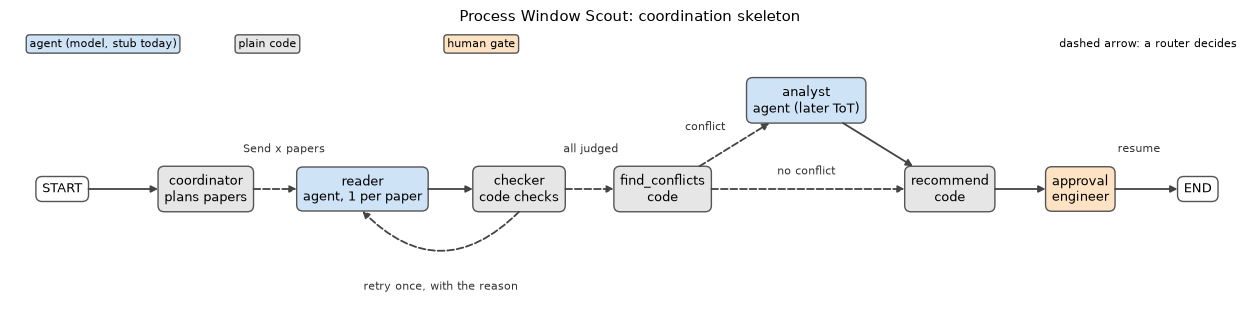

In [97]:
class ScoutState(TypedDict, total=False):
    request: dict                                          # from the engineer: alloy, layer thickness, target
    papers: list[str]                                      # Coordinator
    records: Annotated[list[dict], merge_records]          # evidence table: Reader, Checker, Analyst (own fields)
    widened: dict                                          # Coordinator (code): the one wider search (8.14)
    conflicts: list[dict]                                  # Coordinator (code)
    explanations: list[dict]                               # Analyst
    recommendation: dict                                   # Coordinator (code)
    approval: dict                                         # engineer
    log: Annotated[list[dict], operator.add]               # every node appends its trace line


def send_readers(state: ScoutState) -> list[Send]:
    """Fan out: one Reader per paper, all in the same super-step."""
    return [Send("reader", {"paper_id": p, "attempt": 1}) for p in state["papers"]]


def route_after_check(state: ScoutState):
    """Failed records go back to their paper's Reader once, all of that paper's together, with the reasons.
    Otherwise move on to conflicts."""
    retry = [r for r in state["records"] if r["status"] == "retry"]
    if not retry:
        return "find_conflicts"
    by_paper = {}
    for r in retry:
        by_paper.setdefault(r["paper_id"], []).append(r)
    return [Send("reader", {"paper_id": pid, "attempt": max(r["attempt"] for r in rs) + 1,
                            "feedback": " | ".join(f"{r['id']}: {r['reason']}" for r in rs),
                            "retry_ids": [r["id"] for r in rs], "retry_records": rs})
            for pid, rs in by_paper.items()]


def route_after_conflicts(state: ScoutState) -> str:
    """Spend Analyst calls only when code found a conflict."""
    return "analyst" if state["conflicts"] else "recommend"


def build_scout_graph(reader_model, analyst_model, library, checkpointer=None, judge=None, guardrails=False, store=None,
                      widen=False):
    """The scout graph. guardrails=True adds the clarification step and the engineer's memory of Part 9.
    widen=True adds the Coordinator's one wider search between the Checker and the conflict search (8.14)."""
    g = StateGraph(ScoutState)
    g.add_node("coordinator", partial(coordinator_node, library=library))
    g.add_node("reader", partial(reader_node, model=reader_model, library=library))
    g.add_node("checker", partial(checker_node, library=library, judge=judge))
    g.add_node("find_conflicts", find_conflicts_node)
    g.add_node("analyst", partial(analyst_node, model=analyst_model))
    g.add_node("recommend", recommend_with_memory if guardrails else recommend_node)     # the memory versions are in Part 9
    g.add_node("approval", approval_with_memory if guardrails else approval_node)
    if guardrails:
        g.add_node("clarify", clarify_node)
        g.add_edge(START, "clarify")
        g.add_edge("clarify", "coordinator")
    else:
        g.add_edge(START, "coordinator")
    g.add_conditional_edges("coordinator", send_readers, ["reader"])
    g.add_edge("reader", "checker")
    if widen:      # the router's "find_conflicts" now leads to the wider search first, then on to the conflicts
        g.add_node("widen", widen_node)
        g.add_conditional_edges("checker", route_after_check, {"reader": "reader", "find_conflicts": "widen"})
        g.add_edge("widen", "find_conflicts")
    else:
        g.add_conditional_edges("checker", route_after_check, ["reader", "find_conflicts"])
    g.add_conditional_edges("find_conflicts", route_after_conflicts, ["analyst", "recommend"])
    g.add_edge("analyst", "recommend")
    g.add_edge("recommend", "approval")
    g.add_edge("approval", END)
    return g.compile(checkpointer=checkpointer, store=store)


# Drawing: positions and labels for this graph. Colours: agent (model), code, human.
KIND = {"coordinator": "code", "reader": "agent", "checker": "code", "find_conflicts": "code",
        "analyst": "agent", "recommend": "code", "approval": "human"}
SUBTITLE = {"coordinator": "plans papers", "reader": "agent, 1 per paper", "checker": "code checks",
            "find_conflicts": "code", "analyst": "agent (later ToT)", "recommend": "code", "approval": "engineer"}
COLOR = {"agent": "#cfe3f7", "code": "#e6e6e6", "human": "#fde2c4", "end": "#ffffff"}
POS = {"__start__": (0, 0), "coordinator": (2.2, 0), "reader": (4.6, 0), "checker": (7, 0), "find_conflicts": (9.2, 0),
       "analyst": (11.4, 1), "recommend": (13.6, 0), "approval": (15.6, 0), "__end__": (17.4, 0)}
EDGE_LABEL = {("coordinator", "reader"): ("Send x papers", 0, 0.45), ("checker", "reader"): ("retry once, with the reason", 0, -1.1),
              ("checker", "find_conflicts"): ("all judged", 0, 0.45), ("find_conflicts", "analyst"): ("conflict", -0.45, 0.2),
              ("find_conflicts", "recommend"): ("no conflict", 0, 0.2), ("approval", "__end__"): ("resume", 0, 0.45)}


def draw_graph(compiled, title="Process Window Scout: coordination skeleton"):
    """Draw the compiled graph from its own node and edge list. Dashed = conditional edge (a router decides)."""
    G = compiled.get_graph()
    fig, ax = plt.subplots(figsize=(16, 3.8))
    ax.set_xlim(-0.8, 18.2)
    ax.set_ylim(-1.5, 1.8)
    ax.axis("off")
    boxes = {}
    for n in G.nodes:
        name = {"__start__": "START", "__end__": "END"}.get(n, n)
        boxes[n] = ax.text(*POS[n], name + (f"\n{SUBTITLE[n]}" if n in SUBTITLE else ""), ha="center", va="center",
                           fontsize=9, bbox=dict(boxstyle="round,pad=0.5", fc=COLOR[KIND.get(n, "end")], ec="#555"))
    # Box sizes are known only after a first draw. Convert them to data units to end arrows at the box edges.
    fig.canvas.draw()
    to_data = ax.transData.inverted()
    half = {}
    for n, t in boxes.items():
        (xa, ya), (xb, yb) = to_data.transform(t.get_bbox_patch().get_window_extent(fig.canvas.get_renderer()))
        half[n] = ((xb - xa) / 2, (yb - ya) / 2)

    def border(n, toward):                                # where the line from n's centre to 'toward' leaves n's box
        (cx, cy), (hw, hh) = POS[n], half[n]
        dx, dy = toward[0] - cx, toward[1] - cy
        s = min(hw / abs(dx) if dx else float("inf"), hh / abs(dy) if dy else float("inf"))
        return cx + dx * s, cy + dy * s

    for e in G.edges:
        a, b = POS[e.source], POS[e.target]
        style = dict(arrowstyle="-|>", color="#444", lw=1.3, linestyle="--" if e.conditional else "-", shrinkA=0, shrinkB=0)
        if b[0] < a[0]:                                   # the retry loop runs backwards: an arc under the boxes
            start, end = (a[0], a[1] - half[e.source][1]), (b[0], b[1] - half[e.target][1])
            style["connectionstyle"] = "arc3,rad=-0.5"
        else:
            start, end = border(e.source, b), border(e.target, a)
        ax.annotate("", xy=end, xytext=start, arrowprops=style)
        if (e.source, e.target) in EDGE_LABEL:
            text, dx, dy = EDGE_LABEL[(e.source, e.target)]
            ax.text((a[0] + b[0]) / 2 + dx, (a[1] + b[1]) / 2 + dy, text, ha="center", va="center", fontsize=8, color="#333")
    for i, (k, lab) in enumerate([("agent", "agent (model, stub today)"), ("code", "plain code"), ("human", "human gate")]):
        ax.text(-0.5 + 3.2 * i, 1.6, lab, fontsize=8, bbox=dict(boxstyle="round", fc=COLOR[k], ec="#555"))
    ax.text(18, 1.6, "dashed arrow: a router decides", fontsize=8, ha="right")
    ax.set_title(title, fontsize=11)
    plt.show()


preview_graph = build_scout_graph(ScriptedModel("reader", READER_SCRIPT), ScriptedModel("analyst", ANALYST_SCRIPT),
                                  TEST_LIBRARY, checkpointer=InMemorySaver())
draw_graph(preview_graph)

In [98]:
# Tests for 8.6: the compiled graph has exactly the planned shape
G = preview_graph.get_graph()
edges = {(e.source, e.target, e.conditional) for e in G.edges}
check("seven nodes plus START and END", set(G.nodes) == set(POS))
check("fan out from the Coordinator to the Readers is conditional (Send)", ("coordinator", "reader", True) in edges)
check("the retry loop goes from the Checker back to the Reader", ("checker", "reader", True) in edges)
check("the Analyst is skipped when there is no conflict", ("find_conflicts", "recommend", True) in edges)
check("approval is the last node before END", ("approval", "__end__", False) in edges)

  ok  seven nodes plus START and END
  ok  fan out from the Coordinator to the Readers is conditional (Send)
  ok  the retry loop goes from the Checker back to the Reader
  ok  the Analyst is skipped when there is no conflict
  ok  approval is the last node before END


### 8.7 Run 1: five papers, one retry, one conflict

Each run has a `thread_id` (a new id means a fresh table), a `recursion_limit` and `max_concurrency` (3 Readers at
once). Watch the step column: five Readers share one step, T3 and T4 go back, and the run stops before approval.

In [99]:
def run_config(thread_id: str, recursion_limit: int = 25) -> dict:
    return {"configurable": {"thread_id": thread_id}, "recursion_limit": recursion_limit, "max_concurrency": 3}


def stream_run(graph, inputs, config):
    """Run (or resume) the graph and print each node's trace lines as they arrive."""
    for update in graph.stream(inputs, config, stream_mode="updates"):
        for node, change in update.items():
            if node == "__interrupt__":
                print("        PAUSED: waiting for the engineer (interrupt)")
            else:
                show_log((change or {}).get("log", []))


reader_1 = ScriptedModel("reader", READER_SCRIPT)
analyst_1 = ScriptedModel("analyst", ANALYST_SCRIPT)
memory = InMemorySaver()                                   # checkpointer: keeps every run's state in RAM
scout = build_scout_graph(reader_1, analyst_1, TEST_LIBRARY, checkpointer=memory)
cfg_1 = run_config("run-1")

stream_run(scout, {"request": REQUEST}, cfg_1)
state_1 = scout.get_state(cfg_1).values
print()
show_table(state_1["records"])

step  1 | coordinator           | 316L, 30 um, target 99.5 %: 5 papers to read


step  2 | reader         T3     | attempt 1: 1 record(s), rho = 99.1 %
step  2 | reader         T2     | attempt 1: 1 record(s), rho = 97.8 %
step  2 | reader         T4     | attempt 1: 1 record(s), rho = 99.2 %
step  2 | reader         T5     | attempt 1: 1 record(s), rho = 99.6 %
step  2 | reader         T1     | attempt 1: 1 record(s), rho = 99.9 %
step  3 | checker        T1     | verified
step  3 | checker        T2     | verified
step  3 | checker        T3     | retry: density_pct = 99.1 not in passage, nearest value 98.1
step  3 | checker        T4     | retry: power_W = 195 not in passage; speed_mm_s = 800 not in passage; hatch_um missing
step  3 | checker        T5     | verified
step  4 | reader         T3     | attempt 2: 1 record(s), rho = 98.1 %  (feedback: T3-r1: density_pct = 99.1 not in passage, nearest value 98.1)
step  4 | reader         T4     | attempt 2: 1 record(s), rho = 99.2 %  (feedback: T4-r1: power_W = 195 not in passage; speed_mm_s = 800 not in passage; h

**The run as a timeline.** One row per agent, one column per step. Second marks are retries, colours show the Checker's
verdict.

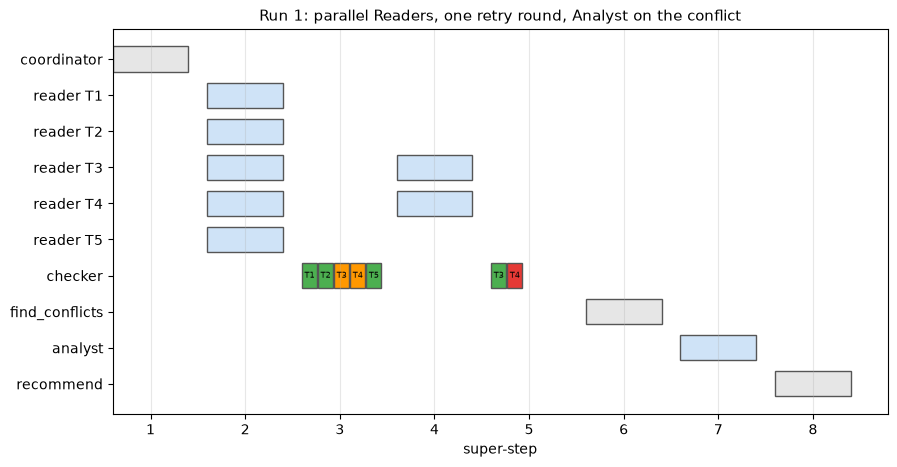

In [100]:
VERDICT_COLOR = {"verified": "#4caf50", "retry": "#ff9800", "not verified": "#e53935"}


def plot_timeline(log, title):
    """Gantt-style view of the trace: which node ran in which super-step."""
    rows, marks = [], []
    for e in log:
        if e["step"] == "-":
            continue
        row = f"reader {e['subject']}" if e["node"] == "reader" else e["node"]
        if row not in rows:
            rows.append(row)
        colour = "#cfe3f7" if e["node"] in ("reader", "analyst") else "#fde2c4" if e["node"] == "approval" else "#e6e6e6"
        if e["node"] == "checker":
            colour = VERDICT_COLOR.get(e["msg"].split(":")[0], "#e6e6e6")
        marks.append((e["step"], row, colour, e["subject"] if e["node"] == "checker" else ""))
    rows.sort(key=lambda rw: (min(s for s, r, *_ in marks if r == rw), rw))
    y = {rw: i for i, rw in enumerate(rows)}
    fig, ax = plt.subplots(figsize=(10, 0.38 * len(rows) + 1.2))
    seen = {}
    for step, row, colour, label in marks:
        k = seen.get((step, row), 0)
        seen[(step, row)] = k + 1
        if row == "checker":                               # several verdicts per Checker step: small stacked boxes
            ax.barh(y[row], 0.16, left=step - 0.4 + 0.17 * k, color=colour, edgecolor="#555", height=0.7)
            ax.text(step - 0.32 + 0.17 * k, y[row], label, ha="center", va="center", fontsize=6)
        elif k == 0:
            ax.barh(y[row], 0.8, left=step - 0.4, color=colour, edgecolor="#555", height=0.7)
    ax.set_yticks(range(len(rows)), rows)
    ax.invert_yaxis()
    steps = sorted({s for s, *_ in marks})
    ax.set_xticks(steps)
    ax.set_xlabel("super-step")
    ax.set_title(title, fontsize=11)
    ax.grid(axis="x", alpha=0.3)
    plt.show()


plot_timeline(state_1["log"], "Run 1: parallel Readers, one retry round, Analyst on the conflict")

In [101]:
# Tests for 8.7
by_id = {r["id"]: r for r in state_1["records"]}
first_round = [e["step"] for e in state_1["log"] if e["node"] == "reader" and e["msg"].startswith("attempt 1")]
check("five Readers ran, all in the same super-step (parallel)", len(first_round) == 5 and len(set(first_round)) == 1)
check("the evidence table has one record per paper (retries updated, not duplicated)", len(state_1["records"]) == 5)
check("T3 was verified on the retry with the corrected density",
      by_id["T3-r1"]["status"] == "verified" and by_id["T3-r1"]["attempt"] == 2 and by_id["T3-r1"]["density_pct"] == 98.1)
check("T3's second Reader call received the Checker's reason",
      "nearest value 98.1" in [c for c in reader_1.calls if c["key"] == "T3" and c["attempt"] == 2][0]["feedback"])
check("T4 was tried exactly twice and ended 'not verified'",
      by_id["T4-r1"]["status"] == "not verified" and sum(c["key"] == "T4" for c in reader_1.calls) == 2)
check("Reader model calls = 5 papers + 2 retries", len(reader_1.calls) == 7)
check("the Analyst ran once, on the T1 vs T3 conflict",
      [c["key"] for c in analyst_1.calls] == ["T1-r1|T3-r1"] and "Archimedes" in by_id["T1-r1"]["analyst_note"])
check("the window cites T1 and T5 and excludes T4",
      state_1["recommendation"]["cites"] == ["T1-r1", "T5-r1"] and state_1["recommendation"]["excluded"] == ["T4-r1"])
check("the run is paused at approval (no decision yet)", "approval" not in state_1)

  ok  five Readers ran, all in the same super-step (parallel)
  ok  the evidence table has one record per paper (retries updated, not duplicated)
  ok  T3 was verified on the retry with the corrected density
  ok  T3's second Reader call received the Checker's reason
  ok  T4 was tried exactly twice and ended 'not verified'
  ok  Reader model calls = 5 papers + 2 retries
  ok  the Analyst ran once, on the T1 vs T3 conflict
  ok  the window cites T1 and T5 and excludes T4
  ok  the run is paused at approval (no decision yet)


### 8.8 The human gate

The graph stopped at `interrupt`, and the checkpointer kept its state. `get_state` shows what waits,
`Command(resume=answer)` continues, and `get_state_history` is the audit trail.

In [102]:
paused = scout.get_state(cfg_1)
question = paused.tasks[0].interrupts[0].value
print("Waiting to run :", paused.next)
print("Question       :", question["question"])
for k, v in question["recommendation"].items():
    print(f"  {k:<11}: {v}")

Waiting to run : ('approval',)
Question       : Approve this process window?
  status     : proposed
  method     : Archimedes
  power_W    : [170, 190]
  speed_mm_s : [700, 750]
  hatch_um   : [90, 100]
  layer_um   : 30
  cites      : ['T1-r1', 'T5-r1']
  supporting : []
  excluded   : ['T4-r1']
  adjacent   : []
  windows    : [{'method': 'Archimedes', 'records': 2, 'papers': 2, 'power_W': [170, 190], 'speed_mm_s': [700, 750], 'hatch_um': [90, 100], 'cites': ['T1-r1', 'T5-r1']}]


In [103]:
stream_run(scout, Command(resume={"approved": True, "note": "start at the middle, 180 W and 725 mm/s"}), cfg_1)
final_1 = scout.get_state(cfg_1)
print("\nWaiting to run :", final_1.next or "nothing, the run is finished")
print("Approval       :", final_1.values["approval"])

print("\nCheckpoints of run-1 (newest first):")
for snap in scout.get_state_history(cfg_1):
    print(f"  after step {snap.metadata['step']:>2}: next = {snap.next}")

step  9 | approval              | engineer approved: start at the middle, 180 W and 725 mm/s

Waiting to run : nothing, the run is finished
Approval       : {'approved': True, 'note': 'start at the middle, 180 W and 725 mm/s'}

Checkpoints of run-1 (newest first):
  after step  9: next = ()
  after step  8: next = ('approval',)
  after step  7: next = ('recommend',)
  after step  6: next = ('analyst',)
  after step  5: next = ('find_conflicts',)
  after step  4: next = ('checker',)
  after step  3: next = ('reader', 'reader')
  after step  2: next = ('checker',)
  after step  1: next = ('reader', 'reader', 'reader', 'reader', 'reader')
  after step  0: next = ('coordinator',)
  after step -1: next = ('__start__',)


In [104]:
# Tests for 8.8
check("before resuming, the graph was waiting at 'approval'", paused.next == ("approval",))
check("the engineer saw the window and its citations", question["recommendation"]["cites"] == ["T1-r1", "T5-r1"])
check("after resuming, the run is finished", final_1.next == ())
check("the approval is stored in the state", final_1.values["approval"]["approved"] is True)
check("resuming did not call the Reader again (state came from the checkpoint)", len(reader_1.calls) == 7)
history = list(scout.get_state_history(cfg_1))
check("one checkpoint per super-step was saved", len(history) >= 10)

  ok  before resuming, the graph was waiting at 'approval'
  ok  the engineer saw the window and its citations
  ok  after resuming, the run is finished
  ok  the approval is stored in the state
  ok  resuming did not call the Reader again (state came from the checkpoint)
  ok  one checkpoint per super-step was saved


### 8.9 Run 2: another path through the same graph

Only the three papers that agree. There is no conflict, so the router skips the Analyst and no Analyst call is spent.
This time I reject the window.

step  1 | coordinator           | 316L, 30 um, target 99.5 %: 3 papers to read
step  2 | reader         T5     | attempt 1: 1 record(s), rho = 99.6 %
step  2 | reader         T2     | attempt 1: 1 record(s), rho = 97.8 %
step  2 | reader         T1     | attempt 1: 1 record(s), rho = 99.9 %
step  3 | checker        T1     | verified
step  3 | checker        T2     | verified
step  3 | checker        T5     | verified
step  4 | find_conflicts        | 3 verified records at 1 layer thickness(es) compared, 0 conflict(s), 0 across papers, 0 to the Analyst, 0 method-spread pair(s)
step  5 | recommend             | proposed from Archimedes records: P 170 to 190 W, v 700 to 750 mm/s from ['T1-r1', 'T5-r1'], 0 supporting
        PAUSED: waiting for the engineer (interrupt)


step  6 | approval              | engineer rejected: our machine tops out at 180 W


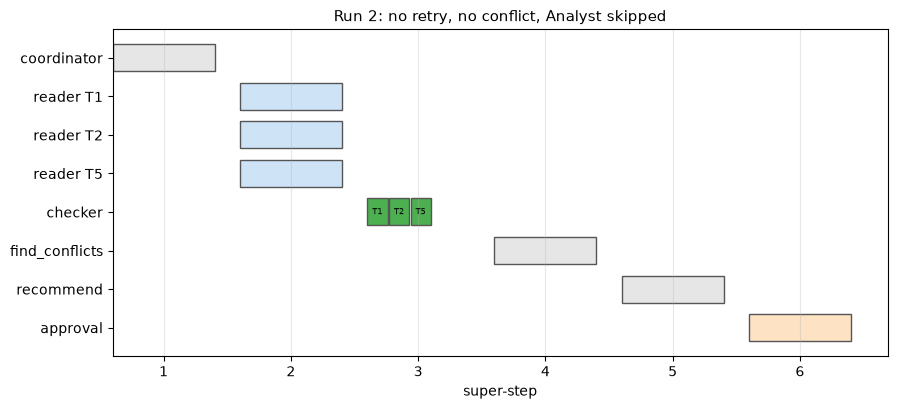

In [105]:
agreeing = {p: TEST_LIBRARY[p] for p in ["T1", "T2", "T5"]}
reader_2 = ScriptedModel("reader", READER_SCRIPT)
analyst_2 = ScriptedModel("analyst", ANALYST_SCRIPT)
scout_2 = build_scout_graph(reader_2, analyst_2, agreeing, checkpointer=InMemorySaver())
cfg_2 = run_config("run-2")

stream_run(scout_2, {"request": REQUEST}, cfg_2)
stream_run(scout_2, Command(resume={"approved": False, "note": "our machine tops out at 180 W"}), cfg_2)
state_2 = scout_2.get_state(cfg_2).values
plot_timeline(state_2["log"], "Run 2: no retry, no conflict, Analyst skipped")

In [106]:
# Tests for 8.9
nodes_2 = [e["node"] for e in state_2["log"]]
check("the Analyst was skipped and never called", "analyst" not in nodes_2 and analyst_2.calls == [])
check("no retries: three Reader calls for three papers", len(reader_2.calls) == 3)
check("node order: coordinator, readers, checker, find_conflicts, recommend, approval",
      [n for i, n in enumerate(nodes_2) if i == 0 or n != nodes_2[i - 1]]
      == ["coordinator", "reader", "checker", "find_conflicts", "recommend", "approval"])
check("the rejection and its note are stored",
      state_2["approval"] == {"approved": False, "note": "our machine tops out at 180 W"})
check("run-1 is untouched by run-2 (separate threads)", scout.get_state(cfg_1).values["approval"]["approved"] is True)

  ok  the Analyst was skipped and never called
  ok  no retries: three Reader calls for three papers
  ok  node order: coordinator, readers, checker, find_conflicts, recommend, approval
  ok  the rejection and its note are stored
  ok  run-1 is untouched by run-2 (separate threads)


### 8.10 Safety brakes

The retry cap is the designed brake: a Reader that is always wrong costs two calls. `recursion_limit` is the backstop
for a router bug: run 1 needs 8 steps, so a limit of 6 must stop it.

In [107]:
reader_3 = ScriptedModel("reader", READER_SCRIPT)
scout_3 = build_scout_graph(reader_3, ScriptedModel("analyst", ANALYST_SCRIPT), TEST_LIBRARY, checkpointer=InMemorySaver())
try:
    stream_run(scout_3, {"request": REQUEST}, run_config("run-3", recursion_limit=6))
    stopped = None
except GraphRecursionError as e:
    stopped = e
    print("\nStopped by the backstop ->", type(e).__name__, ":", str(e).splitlines()[0])
steps_run_1 = max(e["step"] for e in state_1["log"] if e["node"] != "approval")
print("Super-steps run 1 needed before the pause:", steps_run_1)

step  1 | coordinator           | 316L, 30 um, target 99.5 %: 5 papers to read
step  2 | reader         T3     | attempt 1: 1 record(s), rho = 99.1 %
step  2 | reader         T1     | attempt 1: 1 record(s), rho = 99.9 %
step  2 | reader         T4     | attempt 1: 1 record(s), rho = 99.2 %
step  2 | reader         T5     | attempt 1: 1 record(s), rho = 99.6 %
step  2 | reader         T2     | attempt 1: 1 record(s), rho = 97.8 %
step  3 | checker        T1     | verified
step  3 | checker        T2     | verified
step  3 | checker        T3     | retry: density_pct = 99.1 not in passage, nearest value 98.1
step  3 | checker        T4     | retry: power_W = 195 not in passage; speed_mm_s = 800 not in passage; hatch_um missing
step  3 | checker        T5     | verified
step  4 | reader         T3     | attempt 2: 1 record(s), rho = 98.1 %  (feedback: T3-r1: density_pct = 99.1 not in passage, nearest value 98.1)
step  4 | reader         T4     | attempt 2: 1 record(s), rho = 99.2 %  (fee

In [108]:
# Tests for 8.10
check("a too small recursion_limit stops the run with GraphRecursionError", isinstance(stopped, GraphRecursionError))
check("run 1 fits comfortably inside the limit of 25", steps_run_1 < 25)
check("the always wrong Reader (T4) cost exactly MAX_ATTEMPTS calls in run 1",
      sum(c["key"] == "T4" for c in reader_1.calls) == MAX_ATTEMPTS)

  ok  a too small recursion_limit stops the run with GraphRecursionError
  ok  run 1 fits comfortably inside the limit of 25
  ok  the always wrong Reader (T4) cost exactly MAX_ATTEMPTS calls in run 1


### 8.11 The real agents in the graph

Same wiring, real agents: the Part 5 Reader, the Part 6 checks and the Part 7 tree, on all sixteen papers. Request:
316L, 30 µm, 99.5 %. Look at the status per paper, the records sent back and the windows side by side.

In [109]:
class GLMReader:
    """The real Reader (Part 5) with the same invoke() as ScriptedModel, so build_scout_graph needs no change."""

    def __init__(self):
        self.calls = []

    def invoke(self, paper_id, attempt=1, retry_records=None, **_):
        self.calls.append({"paper_id": paper_id, "attempt": attempt})
        if attempt == 1:     # the paper's reading units with the same prompts as in 5.2, so the answers come from the cache
            calls = [(reader_inputs(paper_id, unit), f"reader {SHORT[paper_id]} {unit['name']}") for unit in reading_units(paper_id)]
        else:                # one call for the records the Checker sent back, with its reasons
            calls = [(reader_inputs(paper_id, retry_records=retry_records), f"reader {SHORT[paper_id]} retry")]
        outs = []
        for inputs, name in calls:
            try:
                outs.append(reader_chain.invoke(inputs, config={"metadata": {"agent": name}}))
            except Exception as e:                       # a timeout (or, offline, a unit never answered) costs this unit
                print(f"        {name}: no answer ({'not in the cache' if isinstance(e, ModelUnavailable) else type(e).__name__})")
        if calls and not outs and LLM_OK is False:
            raise ModelUnavailable("no answer of this paper is in the cache")
        return merge_units(paper_id, outs)


import concurrent.futures


class ToTAnalyst:
    """The Analyst for the graph: runs the Tree of Thought of Part 7 on each conflict it is given."""

    def __init__(self):
        self.calls, self.trees = [], {}

    def invoke(self, key, conflict=None, records=(), **_):
        self.calls.append(key)
        use_evidence([x for x in records if x["status"] == "verified"])     # consensus facts from this run's table
        a, b = conflict["records"]
        # The tree is a LangGraph graph of its own. Called straight from this node it inherits the outer run's context
        # (checkpointer, task runner) and waited forever. A worker thread starts with a fresh context: a top-level run.
        with concurrent.futures.ThreadPoolExecutor(max_workers=1) as pool:
            tot = pool.submit(tree_of_thought, f"{SHORT[a['paper_id']]} vs {SHORT[b['paper_id']]}", a, b).result()
        self.trees[key] = tot
        best = tot["result"]["best"]
        return {"explanation": best["explanation"] if best else "no explanation is supported by the evidence",
                "favoured": best["id"] if best else "-", "tier": best["tier"] if best else "-", "band": tot["result"]["band"]}


REAL_LIBRARY = {pid: LIB_META[pid] for pid in SOURCE_IDS + EXT_IDS}     # v2 and the extension (3.12)
real_reader, real_analyst = GLMReader(), ToTAnalyst()
real_graph = build_scout_graph(real_reader, real_analyst, REAL_LIBRARY, checkpointer=InMemorySaver(), judge=check_record_full,
                               widen=True)
cfg_real = run_config("real-run-1")


def run_real():
    """Stream the real run. The Checker writes one log line per record, so its lines are summarised per step."""
    TRACER.start("graph_real_run")
    t0 = time.time()
    for update in real_graph.stream({"request": REQUEST}, cfg_real, stream_mode="updates"):
        for node, change in update.items():
            if node == "__interrupt__":
                print("        PAUSED: waiting for the engineer (interrupt)")
                continue
            entries = (change or {}).get("log", [])
            if node == "checker" and entries:
                verdicts = [e["msg"].split(":")[0] for e in entries]
                print(f"step {entries[0]['step']!s:>2} | checker        {len(entries)} records | "
                      + ", ".join(f"{s}: {verdicts.count(s)}" for s in sorted(set(verdicts))))
            for e in entries if node != "checker" else []:
                print(f"step {e['step']!s:>2} | {e['node']:<14} {SHORT.get(e['subject'], e['subject']):<4} | {e['msg'][:140]}")
    return time.time() - t0


real_seconds = model_cell(run_real)

step  1 | coordinator         | 316L, 30 um, target 99.5 %: 16 papers to read


--- [reader E06 text] from cache: 6.76 s, 1824 in / 1122 out tokens (390 reasoning) ---
reasoning (203 words): Let me analyze the passages to extract the parameter sets and measured density values.

From Table 2 (chunk PMC10935024-020), I have the optimized processing parameters:
- 316L (0 wt% TiC): 180W, 1000 mm/s, 30 µm layer, 60 µm hatch
- 2 wt% TiC/316L: 200W, 1000 mm/s, 30 µm layer, 60 µm hatch
- 4 wt% TiC/316L: 240W, 800 mm/s, 30 µm layer, 60 µm hatch

From chunk PMC10935024-007, the measured relative densities by Archimedes drainage method:
- 316L: 96.3%
- 2 wt% TiC/316L: 99.1%
- 4 wt% TiC/316L: 93.2%

The density method is Archimedes drainage method (chunk PMC10935024-005 and PMC10935024-007).

The spot size is 50 µm (chunk PMC10935024-004).

Layer thickness = 30 µm, hatch distance = 60 µm from Table 2 for all samples.

No energy density is reported in the passages.

The three samples correspond to three different material compositions, each with their own optimized parameters.

step  2 | reader         E06  | attempt 1: 3 record(s)


--- [reader E03 text] from cache: 12.5 s, 1733 in / 1815 out tokens (1227 reasoning) ---
reasoning (694 words): Let me analyze this paper carefully. The paper studies the effect of scanning strategy on 316L stainless steel printed by SLM (which is PBF-LB).

From the passages, I can identify:

**Process parameters (stated once for all samples):**
- Layer thickness: 30 μm
- Laser power: 165 W
- Hatch spacing: 70 μm
- Scan speed: 800 mm/s

**Density measurement method:** Archimedes drainage method (from [PMC10934583-011])

**Measured density values (from text in [PMC10934583-011]):**
- The bulk density of samples is above 98%
- Z-90° specimen: lowest density at 98.80%
- I-67° specimen: highest density at 99.86%

From [PMC10934583-014]:
- I-67° and S-67° samples have density higher than 99.5%

So from the text, I can extract these specific measured values:
1. Z-90°: 98.80% relative density (Archimedes method)
2. I-67°: 99.86% relative density (Archimedes method)

The S-67° is stated as "hi

step  2 | reader         E03  | attempt 1: 2 record(s)


--- [reader L04 text] from cache: 28.26 s, 2900 in / 5424 out tokens (4578 reasoning) ---
reasoning (2926 words): Let me analyze the passages to find measured density or porosity values.

From the text, I can find these measured porosity values:

1. From [PMC12387571-017]: "The minimum porosity of approximately 0.04% occurred at 190 W and 700 to 800 mm/s" - this gives porosity values but for a range of scanning speeds (700-800 mm/s), not a single parameter set.

2. From [PMC12387571-017]: "the maximum porosity of about 2% appeared at 140 W and 900 mm/s" - this gives a specific porosity value at specific parameters.

3. From [PMC12387571-002]: This mentions other studies' values - Wang et al. [28] obtained relative density of 99.99% under 150 μm layer thickness, 380 W and 333 mm/s. But this is from another study (origin: quoted).

The methods state:
- Porosity was measured by metallographic image analysis [PMC12387571-013]
- Relative density was measured using Archimedes density method 

... (6 outputs left out)

--- [reader L08 Table 2] from cache: 82.19 s, 4183 in / 14945 out tokens (4259 reasoning) ---
reasoning (2693 words): Let me analyze the focus chunk [PMC7579382-039] which is Table 2. This table contains density measurements and porosity levels for 16 samples after SLM.

The table has columns:
- Sample number
- ρpycno (g/cm3) - pycnometric density
- Vpycno (cm3) - pycnometric volume
- Pclosed (%) - closed porosity (from pycnometric method)
- Pimage (%) - porosity from image analysis

From the methods section [PMC7579382-011], I can see:
- Helium pycnometry method was used for density determination (ρpycno)
- Closed porosity Pcl was determined based on gas pycnometer measurements
- Image analysis was done using ImageJ software

So the density values (ρpycno) are in g/cm3, which is the density of the printed part measured by pycnometry. But the rule says "Density means the measured relative density of printed parts in %, or their porosity in %". 

The table has:
1. ρpycno in g/cm3 - this

--- [reader L10 Table 3] from cache: 17.73 s, 2886 in / 2988 out tokens (1068 reasoning) ---
reasoning (471 words): The focus is on [PMC9919176-024], which is Table 3 with porosity values. I need to extract all 10 rows from that table, each with its porosity measurement.

Let me gather the parameters:
- Layer thickness: 20 µm (from [PMC9919176-005])
- Laser beam diameter (spot size): 55 µm (from [PMC9919176-005])
- All rows have Time=2 min, Gas Feed=3.5 m/s

The 10 rows from Table 3:
1. Power=108.0 W, Speed=465.0 mm/s, Hatch Spacing=97.0 µm, Energy Density=119.72 J/mm3, Angle=77.0°, Porosity=0.0007%
2. Power=163.0 W, Speed=616.0 mm/s, Hatch Spacing=71.0 µm, Energy Density=186.35 J/mm3, Angle=51.0°, Porosity=0.0013%
3. Power=131.0 W, Speed=955.0 mm/s, Hatch Spacing=77.0 µm, Energy Density=89.07 J/mm3, Angle=83.0°, Porosity=0.0042%
4. Power=101.0 W, Speed=505.0 mm/s, Hatch Spacing=87.0 µm, Energy Density=114.94 J/mm3, Angle=5.0°, Porosity=0.0043%
5. Power=159.0 W, Speed=1128.0 mm/s, Hatc

--- [reader L09 retry] from cache: 25.21 s, 3409 in / 3945 out tokens (3334 reasoning) ---
reasoning (2069 words): Let me analyze the Checker's rejections carefully.

**PMC8880558-r3 (Table 1, sample [31]):**
The Checker says hatch_um = 10 is outside the typical PBF-LB range 20 to 300; check the units.

Looking at the table entry for [31]:
`[31] | 150–200 | 300–600 | 10–50 | 50 | 100–1333 | SLM Epit: 560 mV vs. Ag/AgCl, ≈ wrought 316LRinger's solution pH 6.9 ± 0.2. | 0.04 µmColloidal silica | 98%`

So the hatch spacing is listed as "10–50" (μm) and layer thickness is 50 (μm). The Checker flagged that hatch_um = 10 is outside the typical range. But the rule says "Copy every number exactly as printed." The paper does print 10–50 as a range. 

However, looking more carefully - the table header says "HatchSpacing (h) (μm)". The value is "10–50" μm. The power is "150–200" W, scanning speed is "300–600" mm/s, layer thickness is 50 μm, energy density is "100–1333" J/mm³.

The Checker is sayin

--- [analyst critic E06 vs L06 method L1] from cache: 16.66 s, 1651 in / 2105 out tokens (1815 reasoning) ---
reasoning (1150 words): The explanation claims that B's density might have been taken from image analysis rather than Archimedes, which could inflate porosity. Let me check the evidence.

For Record A: The record's density is from Archimedes. Paper A states it uses Archimedes drainage method. The explanation says A is Archimedes-only. Does paper A say anything supporting the explanation for A? The explanation is about B's method possibly being image analysis. Paper A just confirms Archimedes. 

[PMC10935024-005] says "The densities of the samples were tested based on the Archimedes drainage method." and [PMC10935024-007] confirms 96.3% by Archimedes. Paper A doesn't say anything about image analysis or cross-referencing methods - it just uses Archimedes. So paper A's own content doesn't really support the explanation (which is about B's method).

For Record B: The table [PMC118

In [110]:
if real_seconds is not None:
    state_real = real_graph.get_state(cfg_real).values
    recs_real = state_real["records"]
    print(f"Run time {real_seconds:.0f} s. Records: {len(recs_real)}\n")
    STATUSES = ["verified", "quoted", "incomplete", "no density", "other process", "not verified"]
    rows = []
    for pid in REAL_LIBRARY:
        mine = [r for r in recs_real if r["paper_id"] == pid]
        rows.append({"paper": f"{SHORT[pid]} {pid}", "records": len(mine), "retried": sum(r["attempt"] > 1 for r in mine),
                     **{s: sum(r["status"] == s for r in mine) for s in STATUSES}})
    print_rows(rows, [("paper", "paper", 16), ("records", "records", 7), ("retried", "retried", 7),
                      *[(s, s, max(len(s), 6)) for s in STATUSES]])

    print("\nRecords sent back to the Reader, and what happened:")
    print_rows([r for r in recs_real if r["attempt"] > 1],
               [("id", "record", 16), ("sample_label", "sample", 10), ("status", "final status", 12), ("reason", "reason", 100)])

    rec_window = state_real["recommendation"]
    print(f"\nWindow ({rec_window['status']}, bounds from {rec_window.get('method') or 'no'} measurements): "
          f"P {rec_window.get('power_W')} W, v {rec_window.get('speed_mm_s')} mm/s, h {rec_window.get('hatch_um')} µm at "
          f"{REQUEST['layer_um']} µm, from {len(rec_window['cites'])} records. {len(rec_window['supporting'])} records reach the target "
          f"by another or an unknown method and are shown as support. {len(rec_window['excluded'])} 'not verified' records kept out. "
          f"{len(rec_window.get('adjacent', []))} adjacent records (one wider search, 8.14) reach the target at a neighbouring thickness.")
    print("\nOne window per density method (Archimedes first), from the verified records that reach the target:")
    print_rows([{**w, "P": "{:g} to {:g}".format(*w["power_W"]), "v": "{:g} to {:g}".format(*w["speed_mm_s"]),
                 "h": "{:g} to {:g}".format(*w["hatch_um"])} for w in rec_window["windows"]],
               [("method", "method", 15), ("records", "records", 7), ("papers", "papers", 6), ("P", "P W", 12),
                ("v", "v mm/s", 13), ("h", "h um", 12)])
    by_id = {r["id"]: r for r in recs_real}
    print_rows([{**by_id[i], "role": role, "paper": SHORT[by_id[i]["paper_id"]], "method": method_key(by_id[i]) or "not stated"}
                for role, ids in (("bounds", rec_window["cites"]), ("support", rec_window["supporting"])) for i in ids],
               [("role", "role", 7), ("id", "record", 16), ("paper", "paper", 5), ("sample_label", "sample", 12), ("power_W", "P W", 6),
                ("speed_mm_s", "v mm/s", 7), ("hatch_um", "h um", 6), ("density_pct", "rho %", 7), ("method", "method", 15)])

Run time 3 s. Records: 148

paper             records  retried  verified  quoted  incomplete  no density  other process  not verified
----------------  -------  -------  --------  ------  ----------  ----------  -------------  ------------
L01 PMC13073740   1        0        0         0       0           1           0              0           
L02 PMC12735063   9        0        9         0       0           0           0              0           
L03 PMC13208960   6        0        5         1       0           0           0              0           
L04 PMC12387571   3        0        1         0       2           0           0              0           
L05 PMC12194911   1        0        0         0       0           0           1              0           
L06 PMC11818529   18       0        18        0       0           0           0              0           
L07 PMC8510493    3        0        3         0       0           0           0              0           
L08 PMC7579382    

In [111]:
show_trace("graph_real_run")

Trace 'graph_real_run': 48 model calls
#    agent / node            source  s       tok in  tok out  reason  answer or tool call                                         
---  ----------------------  ------  ------  ------  -------  ------  ------------------------------------------------------------
1    reader E06 text         cache   6.76    1824    1122     390     {"records": [   {     "record_id": null,     "sample_labe...
2    reader E03 text         cache   12.5    1733    1815     1227    {"records": [   {     "record_id": null,     "sample_labe...
3    reader L04 text         cache   28.26   2900    5424     4578    {   "records": [     {       "record_id": null,       "sa...
4    reader E05 text         cache   7.28    2486    997      433     {"records": [   {     "record_id": null,     "sample_labe...
5    reader L06 Table 2      cache   101.69  2422    6186     2636    {"records": [   {"record_id": null, "sample_label": "S1",...
6    reader L06 Table 3      cache   2.64   

In [112]:
# Tests for 8.11
if real_seconds is not None:
    trace_real = load_trace("graph_real_run")
    retried_papers = {r["paper_id"] for r in recs_real if r["attempt"] > 1}
    check("the run is paused at the approval node", real_graph.get_state(cfg_real).next == ("approval",))
    check("every record has been judged (none left waiting or in retry)",
          not any(r["status"] in ("extracted", "retry") for r in recs_real))
    check("'not verified' only after the one retry", all(r["attempt"] == MAX_ATTEMPTS for r in recs_real if r["status"] == "not verified"))
    check("Reader calls = 16 papers (v2 and extension) + one retry per paper with rejected records",
          len(real_reader.calls) == len(REAL_LIBRARY) + len(retried_papers))
    check("first attempts were replayed from the cache (same prompts as 5.2)",
          all(t["cached"] for t in trace_real if t["agent"].startswith("reader") and not t["agent"].endswith("retry")))
    check("every other traced call belongs to the Analyst's tree", all(t["agent"].startswith(("reader", "analyst")) for t in trace_real))
    check("the window cites only verified records", all(by_id[i]["status"] == "verified" for i in rec_window["cites"]))
    check("the window's bounds come from one density method", len({method_key(by_id[i]) for i in rec_window["cites"]}) <= 1)
    check("verified records passed every check",
          all(r["checks"]["11 verbatim"] == "pass" and r["checks"]["14 ranges"] == "pass" and r["checks"]["14 energy"] != "fail"
              for r in recs_real if r["status"] == "verified"))

  ok  the run is paused at the approval node
  ok  every record has been judged (none left waiting or in retry)
  ok  'not verified' only after the one retry
  ok  Reader calls = 16 papers (v2 and extension) + one retry per paper with rejected records
  ok  first attempts were replayed from the cache (same prompts as 5.2)
  ok  every other traced call belongs to the Analyst's tree
  ok  the window cites only verified records
  ok  the window's bounds come from one density method
  ok  verified records passed every check


### 8.12 Which pairs are real conflicts?

Three rules on the same records: the old energy-density rule, the strict same-method rule and the active rule. Then a
sensitivity table for the 10 and 15 % tolerances, and the trees on the conflicts, each next to one thinking call.

In [113]:
if real_seconds is not None:
    before = conflict_pairs(recs_real, REQUEST["layer_um"], OLD_RULE)
    strict = conflict_pairs(recs_real, REQUEST["layer_um"], STRICT_RULE)
    active_t = conflict_pairs(recs_real, REQUEST["layer_um"], ACTIVE_RULE)
    after = conflicts_all_layers(recs_real, ACTIVE_RULE, prefer_layer=REQUEST["layer_um"])

    def counts(name, f):
        return {"rule": name, "compared": f["compared"], "flagged": len(f["conflicts"]),
                "inside": sum(not c["cross_paper"] for c in f["conflicts"]), "across": sum(c["cross_paper"] for c in f["conflicts"]),
                "spread": sum(c["same_sample"] for c in f["conflicts"]) + len(f["method_spread"]),
                "analyst": len(f["to_analyst"][:MAX_CONFLICTS])}

    print_rows([counts(f"old (energy density), {REQUEST['layer_um']} µm", before), counts(f"strict, {REQUEST['layer_um']} µm", strict),
                counts(f"active, {REQUEST['layer_um']} µm", active_t), counts("active, every layer", after)],
               [("rule", "rule", 28), ("compared", "records", 7), ("flagged", "conflicts", 9), ("inside", "inside one paper", 16),
                ("across", "across papers", 13), ("spread", "same sample, two methods", 24), ("analyst", "to the Analyst", 14)])

    def label(x):
        return f"{SHORT[x['paper_id']]} {x.get('sample_label') or ''} {x['power_W']:g} W {x['speed_mm_s']:g} mm/s h{x['hatch_um']:g}"

    sent = {tuple(c["ids"]) for c in state_real["conflicts"]}
    print("\nConflicts under the active rule, every layer (the Analyst's order for pairs across papers):")
    print_rows([{"a": label(c["a"]), "b": label(c["b"]), "t": c["a"]["layer_um"], "rho": f"{c['a']['density_pct']:g} / {c['b']['density_pct']:g}",
                 "methods": f"{method_key(c['a']) or '?'} / {method_key(c['b']) or '?'}", "tags": ", ".join(c["tags"]),
                 "across": "yes" if c["cross_paper"] else "", "analyst": "yes" if (c["a"]["id"], c["b"]["id"]) in sent else ""}
                for c in after["to_analyst"] + [c for c in after["conflicts"] if not c["cross_paper"]]],
               [("a", "record A", 30), ("b", "record B", 30), ("t", "t um", 4), ("rho", "density %", 14), ("methods", "methods", 26),
                ("tags", "tags", 6), ("across", "across", 6), ("analyst", "Analyst", 7)])
    print("\nMethod spread (one sample, two methods, not a conflict):")
    print_rows([{"sample": label(m["a"]), "methods": f"{method_key(m['a'])} / {method_key(m['b'])}",
                 "rho": f"{m['a']['density_pct']:g} / {m['b']['density_pct']:g}", "gap": m["gap"]} for m in after["method_spread"]],
               [("sample", "sample", 32), ("methods", "methods", 30), ("rho", "density %", 15), ("gap", "gap", 5)])

    L04_L07 = [c for c in after["to_analyst"] if {c["a"]["paper_id"], c["b"]["paper_id"]} == {"PMC12387571", "PMC8510493"}]
    print("\nTolerance sensitivity (active rule, every layer): how many pairs each choice flags")
    print_rows(tolerance_sensitivity(recs_real, REQUEST["layer_um"]),
               [("P and v", "P and v", 7), ("hatch", "hatch", 5), ("comparable", "comparable pairs", 16), ("conflicts", "conflicts", 9),
                ("across", "across papers", 13), ("tagged", "method tag", 10), ("active", "", 9)])
    print("\nL04's records and the method the Reader gave each value (blank before the fixes of 5.1):")
    print_rows([{**r, "value_pct": r["printed"]["value_pct"], "method": method_key(r) or "not stated"}
                for r in recs_real if r["paper_id"] == "PMC12387571"],
               [("id", "record", 16), ("sample_label", "sample", 12), ("power_W", "P W", 5), ("speed_mm_s", "v mm/s", 6),
                ("quantity", "quantity", 16), ("value_pct", "printed %", 9), ("density_method", "method as read", 34),
                ("method", "method key", 14), ("status", "status", 10)])
    print("L04's own method sentences:")
    for cid, sentence in method_sentences("PMC12387571"):
        print(f"  [{cid}] {sentence[:200]}")
    save_records(recs_real, EXTRACTION / "graph_run_records.csv", extra=["attempt", "status", "reason"])

rule                          records  conflicts  inside one paper  across papers  same sample, two methods  to the Analyst
----------------------------  -------  ---------  ----------------  -------------  ------------------------  --------------
old (energy density), 30 µm   41       80         23                57             9                         3             
strict, 30 µm                 41       2          1                 1              9                         1             
active, 30 µm                 41       3          1                 2              9                         2             
active, every layer           122      11         9                 2              30                        2             

Conflicts under the active rule, every layer (the Analyst's order for pairs across papers):
record A                        record B                        t um  density %       methods                     tags    across  Analyst
-------------------------

In [114]:
# The Tree of Thought the graph ran on its conflicts, plus L04 vs L07 if the graph did not pick it, next to one thinking call
if real_seconds is not None:
    graph_trees = list(real_analyst.trees.values())
    ran = {tuple(sorted((t["case"]["a"]["id"], t["case"]["b"]["id"]))) for t in graph_trees}
    for c in L04_L07[:1]:
        if tuple(sorted((c["a"]["id"], c["b"]["id"]))) not in ran:
            use_evidence([r for r in recs_real if r["status"] == "verified"])
            extra = model_cell(lambda: tree_of_thought("L04 vs L07", c["a"], c["b"]))
            graph_trees += [extra] if extra else []
    # Since Session E the Reader merges L04's "700 to 800 mm/s" into one record without a speed, so the pair is no longer
    # compared. To judge the new support gate on the same case, the tree also runs on L04's record as Session D read it
    # (kept in data/extraction/graph_run_records_sessionD.csv), against L07's medium-VED record of this run.
    SESSION_D_CSV = EXTRACTION / "graph_run_records_sessionD.csv"
    l07_mid = next((r for r in recs_real if r["paper_id"] == "PMC8510493" and r["power_W"] == 190 and r["status"] == "verified"), None)
    if not L04_L07 and SESSION_D_CSV.exists() and l07_mid:
        row = next(r for r in csv.DictReader(SESSION_D_CSV.open(encoding="utf-8"))
                   if r["paper_id"] == "PMC12387571" and r["speed_mm_s"] == "800.0")
        num = lambda x: float(x) if x else None
        l04_d = {"id": "PMC12387571-sessionD", "paper_id": row["paper_id"], "sample_label": row["sample_label"], "source": row["source"],
                 "power_W": num(row["power_W"]), "speed_mm_s": num(row["speed_mm_s"]), "hatch_um": num(row["hatch_um"]),
                 "layer_um": num(row["layer_um"]), "density_pct": num(row["density_pct"]), "quantity": row["quantity"],
                 "printed": {"value_pct": num(row["value_as_printed"])}, "density_method": row["density_method"],
                 "condition": row["condition"], "origin": row["primary_or_quoted"], "status": "verified",
                 "chunk_ids": row["chunk_ids"].split()}
        use_evidence([r for r in recs_real if r["status"] == "verified"] + [l04_d])
        extra = model_cell(lambda: tree_of_thought("L04 vs L07 (Session D record)", l04_d, l07_mid))
        graph_trees += [extra] if extra else []
    graph_singles = model_cell(lambda: [single_answer(t) for t in graph_trees])
    for t, s in zip(graph_trees, graph_singles or [None] * len(graph_trees)):
        show_tree(t, s)
        print()
    SESSION_C = {"L06 S1 method spread": "method, Competing, +5", "L08 sample 4 method spread": "method, Competing, +5",
                 "L04 vs L07": "regime, Resolved, +7", "L04 vs L07 (Session D record)": "regime, Resolved, +7"}
    SESSION_D = {"L06 S1 method spread": "method, Resolved, +8", "L08 sample 4 method spread": "method, Resolved, +8",
                 "L04 vs L07": "reporting, Competing, +6", "L04 vs L07 (Session D record)": "reporting, Competing, +6",
                 "E06 vs L06": "method +8 and regime +5"}      # quote per side, no support gate
    fmt = lambda r: f"{r['best']['id']}, {r['band']}, {r['best']['score']:+d}" if r["best"] else f"none, {r['band']}"
    tot_compare = [{"case": t["case"]["name"], "c": SESSION_C.get(t["case"]["name"], "not run"), "d": SESSION_D.get(t["case"]["name"], "not run"),
                    "new": fmt(t["result"]), "single": f"{s['cause']} ({s['confidence']}, quote {'ok' if s['quote_verified'] else 'not ok'})" if s else "-"}
                   for t, s in [*(known_results or [])] + list(zip(graph_trees, graph_singles or [None] * len(graph_trees)))]
    print("The Analyst across the three rubrics (best cause, band, points):")
    print_rows(tot_compare, [("case", "case", 28), ("c", "Session C: old rubric", 24), ("d", "Session D: quote per side", 26),
                             ("new", "now: with the support gate", 27), ("single", "single call", 30)])

--- [analyst generator L04 vs L07 (Session D record)] from cache: 27.9 s, 1181 in / 4609 out tokens (3500 reasoning) ---
reasoning (2385 words): Let me analyze the two records carefully and propose explanations for why they disagree.

Record A: 190 W, 800 mm/s, hatch 90 µm, layer 30 µm, density 99.96%, method metallographic image analysis (ImageJ), spot size 138 µm
Record B: 190 W, 800 mm/s, hatch 100 µm, layer 30 µm, density 94.6%, method Archimedes' principle

Key differences:
- Hatch spacing: 90 vs 100 µm (A has tighter hatch, higher energy density)
- Density method: image analysis vs Archimedes
- Spot size: A has 138 µm spot (very large!), B's spot size unknown
- Energy density: 88 vs 79.2 J/mm³
- B sits on its paper's lack-of-fusion side

Let me think through each cause category:

1. **method**: A uses ImageJ metallographic image analysis, B uses Archimedes. Image analysis on a 2D cross-section can miss pores that are not in the plane of sectioning. Archimedes captures all pores (

--- [analyst critic L04 vs L07 (Session D record) regime L1] from cache: 28.67 s, 1845 in / 3816 out tokens (3548 reasoning) ---
reasoning (2386 words): The explanation says B's wider hatch (100 µm vs 90 µm) yields 11% lower energy density, and B sits on its paper's lack-of-fusion side. The reduced track overlap at 100 µm hatch could create inter-track lack-of-fusion porosity.

Let me look for evidence in each paper.

For paper A (PMC12387571):
- The record's own passage (PMC12387571-017) describes porosity as a function of processing parameters, showing minimum porosity at 190 W and 700-800 mm/s. It mentions "maximum porosity of about 2% appeared at 140 W and 900 mm/s due to insufficient energy input and weak melt pool bonding." This talks about energy density and porosity but doesn't specifically discuss hatch spacing effects or inter-track lack-of-fusion due to wider hatch.
- The passage mentions energy density relationship but doesn't specifically address hatch spacing or track ove

--- [analyst single call L04 vs L07 (Session D record)] from cache: 53.32 s, 1182 in / 10248 out tokens (10048 reasoning) ---
reasoning (6618 words): Let me analyze the disagreement between Records A and B.

Record A: 190 W, 800 mm/s, hatch 90 µm, layer 30 µm, density 99.96%, method: metallographic image analysis (ImageJ)
Record B: 190 W, 800 mm/s, hatch 100 µm, layer 30 µm, density 94.6%, method: Archimedes' principle

Key differences:
1. Hatch spacing: 90 µm vs 100 µm (11% apart)
2. Energy density: 88.0 vs 79.2 J/mm³ (11% apart)
3. Density methods: image analysis vs Archimedes

Let me look at the facts:

[B1] Energy density differs by 11%.
[B2] Same power and speed, but hatch differs (90 vs 100 µm).
[B3] Different density methods: A image analysis, B Archimedes.
[B5] B sits on its paper's lack-of-fusion side at 79 J/mm³.
[D3] Lack of fusion expected for the lower one (B).

The hatch spacing difference (90 vs 100 µm) puts B at a lower energy density (79.2 vs 88.0 J/mm³), and [B5] says

=== E06 vs L06
A: E06 PMC10935024 (Strength Enhancement of Laser Powder Bed Fusion 316L by Addition of Nano TiC Particles.), sample 316L (0 wt% TiC): 180 W, 1000 mm/s, hatch 60 µm, layer 30 µm, density 96.3 % (relative density 96.3 % as printed), method Archimedes drainage method, condition as-built, from Table 2; Section 3.1 [PMC10935024-020, PMC10935024-007, PMC10935024-005, PMC10935024-004]
B: L06 PMC11818529 (Effect of Porosity on Tribological Properties of Medical-Grade 316L Stainless Steel Manufa), sample S9: 180 W, 1100 mm/s, hatch 60 µm, layer 30 µm, density 99.53 % (porosity 0.47 % as printed), method image analysis, condition not stated, from Table 2 [PMC11818529-023] [PMC11818529-023, PMC11818529-004, PMC11818529-009]
  propose    5 explanations: ['machine', 'method', 'powder', 'regime', 'reporting']
  judge L1   method: +3 {'text A +3': 3, 'check +2': 2, 'assumption -2': -2} tier A
  judge L1   regime: +0 {'check +2': 2, 'assumption -2': -2} tier B
  judge L1   machine: -2 

**L04 vs L07, in short.** L04 (190 W, 800 mm/s, 90 µm hatch, 99.96 %) against L07 (190 W, 800 mm/s, 100 µm,
94.6 %). The tree's answer moved four times while the papers stayed the same:

1. "Regime", Resolved: its method branch never saw L04's sentence on image analysis.
2. Once methods were recorded, the strict rule dropped the pair, so methods are now tagged.
3. The per-side rubric gave "reporting" +6, partly for a table caption.
4. With the support gate: **method, Resolved (+8)**, as the single call says.

In the latest run the Reader merged L04's "700 to 800 mm/s" into one record without a speed, so the tree runs on L04's
earlier record. My reading: mostly the method, plus a value read from a contour plot. Details: decisions.md, 2026-11-07.

In [115]:
# Tests for 8.12
if real_seconds is not None:
    check("the strict rule flags fewer pairs than the old one", len(strict["conflicts"]) < len(before["conflicts"]))
    check("the active rule finds at least the strict rule's conflicts at the requested layer",
          len(active_t["conflicts"]) >= len(strict["conflicts"]))
    check(f"at most {MAX_CONFLICTS} conflicts went to the Analyst", len(state_real["conflicts"]) <= MAX_CONFLICTS)
    check("a 'method' tag only on pairs with two different known methods",
          all(method_key(c["a"]) and method_key(c["b"]) and method_key(c["a"]) != method_key(c["b"]) for c in after["conflicts"] if c["tags"]))
    check("the sensitivity table has 9 settings and marks the active one", len(_sens := tolerance_sensitivity(recs_real)) == 9
          and sum(r["active"] != "" for r in _sens) == 1)
    check("only pairs across papers go to the Analyst", all(c["cross_paper"] for c in after["to_analyst"]))
    check("every method-spread pair is one sample measured by two methods",
          all(same_sample(m["a"], m["b"]) and method_key(m["a"]) != method_key(m["b"]) for m in after["method_spread"]))
    check("every pair sent to the Analyst is comparable under the active rule",
          all(comparable(c["a"], c["b"])[0] for c in after["to_analyst"]))
    check("the graph's Analyst ran the tree on exactly the conflicts it was sent",
          sorted(real_analyst.calls) == sorted("|".join(c["ids"]) for c in state_real["conflicts"]))

  ok  the strict rule flags fewer pairs than the old one
  ok  the active rule finds at least the strict rule's conflicts at the requested layer
  ok  at most 3 conflicts went to the Analyst
  ok  a 'method' tag only on pairs with two different known methods


  ok  the sensitivity table has 9 settings and marks the active one
  ok  only pairs across papers go to the Analyst
  ok  every method-spread pair is one sample measured by two methods
  ok  every pair sent to the Analyst is comparable under the active rule
  ok  the graph's Analyst ran the tree on exactly the conflicts it was sent


### 8.13 Before and after the Reader fixes

Only the ten v2 papers and the strict rule, so the Reader is the only difference. The "before" is the first run of
7 November, checked against its saved files when they exist.

In [116]:
BEFORE_FIXES = {         # the first run, 7 November (Sessions B and C)
    "records": {"L01": 1, "L02": 27, "L03": 6, "L04": 4, "L05": 1, "L06": 18, "L07": 3, "L08": 101, "L09": 13, "L10": 16},
    "unit_slips": {"L07": 3, "L08": 18, "L09": 1, "L10": 10},      # first attempt: a length in µm tagged as mm
    "sent_back": 33, "verified_after_retry": 31, "L04_methods": "none stated",
    "conflicts_old_rule": 70, "conflicts_strict": 1, "cross_paper": 1, "method_spread": 9,
    "window": "Archimedes, 1 record (L07 high-VED), 6 supporting",
}
UNIT_SLIP = re.compile(r"(hatch_um|layer_um|spot_um) = [\d.]+ is outside")


def before_from_files() -> dict | None:
    """Recount the 'before' numbers from the saved first-run records, if the files are there."""
    reader_csv, checked_csv = EXTRACTION / "reader_records_before_fixes.csv", EXTRACTION / "checked_records_before_fixes.csv"
    if not (reader_csv.exists() and checked_csv.exists()):
        return None
    old = list(csv.DictReader(reader_csv.open(encoding="utf-8")))
    old_checked = list(csv.DictReader(checked_csv.open(encoding="utf-8")))
    slips = [r for r in old_checked if r["status"] == "retry" and UNIT_SLIP.search(r["reason"])]
    return {"records": {s: sum(SHORT[r["paper_id"]] == s for r in old) for s in BEFORE_FIXES["records"]},
            "unit_slips": {s: n for s in BEFORE_FIXES["unit_slips"] if (n := sum(SHORT[r["paper_id"]] == s for r in slips))}}


if real_seconds is not None and checked:
    after_slips = [r for r in checked if r["status"] == "retry" and UNIT_SLIP.search(r["reason"] or "")]
    v2_real = [r for r in recs_real if r["paper_id"] in SOURCE_IDS]        # like for like: the "before" run read v2 only
    sent_back = [r for r in v2_real if r["attempt"] > 1]
    l04 = [r for r in v2_real if r["paper_id"] == "PMC12387571" and r["density_pct"] is not None]
    old_v2, strict_v2 = (conflict_pairs(v2_real, REQUEST["layer_um"], rule) for rule in (OLD_RULE, STRICT_RULE))
    w_v2 = recommend_node({"request": REQUEST, "records": v2_real})["recommendation"]
    rows = [{"what": f"records {s}", "before": n, "after": sum(SHORT[r["paper_id"]] == s for r in extracted)}
            for s, n in BEFORE_FIXES["records"].items()]
    rows += [{"what": "records, all papers", "before": sum(BEFORE_FIXES["records"].values()), "after": len(extracted)},
             {"what": "first attempt: µm tagged as mm", "before": sum(BEFORE_FIXES["unit_slips"].values()), "after": len(after_slips)},
             {"what": "  per paper", "before": ", ".join(f"{k} {v}" for k, v in BEFORE_FIXES["unit_slips"].items()),
              "after": ", ".join(f"{s} {n}" for s in dict.fromkeys(SHORT[r["paper_id"]] for r in after_slips)
                                 if (n := sum(SHORT[r["paper_id"]] == s for r in after_slips))) or "none"},
             {"what": "records sent back to the Reader (graph)", "before": BEFORE_FIXES["sent_back"], "after": len(sent_back)},
             {"what": "  verified after the retry", "before": BEFORE_FIXES["verified_after_retry"],
              "after": sum(r["status"] == "verified" for r in sent_back)},
             {"what": "L04: method per value", "before": BEFORE_FIXES["L04_methods"],
              "after": ", ".join(f"{r['quantity']} {method_key(r) or 'not stated'}" for r in l04)},
             {"what": "pairs flagged, old energy-density rule, 30 µm", "before": BEFORE_FIXES["conflicts_old_rule"], "after": len(old_v2["conflicts"])},
             {"what": "conflicts, strict rule, 30 µm", "before": BEFORE_FIXES["conflicts_strict"], "after": len(strict_v2["conflicts"])},
             {"what": "  across papers", "before": BEFORE_FIXES["cross_paper"], "after": len(strict_v2["to_analyst"])},
             {"what": "  method-spread pairs", "before": BEFORE_FIXES["method_spread"], "after": len(strict_v2["method_spread"])},
             {"what": "window (bounds), v2 papers", "before": BEFORE_FIXES["window"],
              "after": f"{w_v2.get('method')}, {len(w_v2['cites'])} record(s), {len(w_v2['supporting'])} supporting"}]
    print_rows(rows, [("what", "", 40), ("before", "before the fixes", 36), ("after", "after the fixes", 50)])

                                          before the fixes                      after the fixes                                   
----------------------------------------  ------------------------------------  --------------------------------------------------
records L01                               1                                     1                                                 
records L02                               27                                    9                                                 
records L03                               6                                     6                                                 
records L04                               4                                     3                                                 
records L05                               1                                     1                                                 
records L06                               18                                    18 

In [117]:
# Tests for 8.13
if real_seconds is not None and checked:
    files = before_from_files()
    if files:
        check("the 'before' record counts match the saved first-run records", files["records"] == BEFORE_FIXES["records"])
        check("the 'before' unit slips match the saved first-run Checker verdicts", files["unit_slips"] == BEFORE_FIXES["unit_slips"])
    check("the length units in the new records are µm or mm only",
          {u for r in extracted for k, u in r["units"].items() if k in ("hatch", "layer", "spot") and u} <= {"µm", "mm"})

  ok  the 'before' record counts match the saved first-run records
  ok  the 'before' unit slips match the saved first-run Checker verdicts
  ok  the length units in the new records are µm or mm only


### 8.14 One wider search when evidence is thin

If fewer than 10 verified records meet the request, the Coordinator searches once at the nearest thinner and thicker
layer. Those records are marked **adjacent** and shown, never used as bounds, because a 40 µm layer melts differently.
With the extension, 12 records meet the 30 µm request, so nothing widens. On v2 alone only 5 do, and the search adds
20 µm (L10) and 40 µm (L09). The threshold of 10 is my Checkpoint 2.1 judgement.

In [118]:
if real_seconds is not None:
    wid = state_real["widened"]
    print(f"Request: {REQUEST['alloy']}, {REQUEST['layer_um']} µm, at least {REQUEST['target_density_pct']} %. "
          f"Verified records that meet it: {wid['n']} (fewer than {MIN_RECORDS}: {'yes' if wid['n'] < MIN_RECORDS else 'no'}).")
    print(f"One wider search at {', '.join(f'{t:g}' for t in wid['layers']) or 'no'} µm: {len(wid['adjacent'])} verified records, "
          f"{len(wid['reach_target'])} reach the target, all marked adjacent.\n")
    print_rows([{**by_id[i], "paper": SHORT[by_id[i]["paper_id"]], "method": method_key(by_id[i]) or "not stated",
                 "reaches": "yes" if i in wid["reach_target"] else ""} for i in wid["adjacent"]],
               [("id", "record", 16), ("paper", "paper", 5), ("sample_label", "sample", 12), ("layer_um", "t um", 4),
                ("power_W", "P W", 6), ("speed_mm_s", "v mm/s", 7), ("hatch_um", "h um", 6), ("density_pct", "rho %", 8),
                ("method", "method", 15), ("scope", "scope", 8), ("reaches", "reaches target", 14)])
    print(f"\nThe window's bounds still come from {len(rec_window['cites'])} record(s) at {REQUEST['layer_um']} µm. "
          f"Shown next to it: {len(rec_window['adjacent'])} adjacent records that reach the target.")

    # The same request on the frozen v2 papers alone (the evidence before the extension of 3.12): code only, no model.
    v2_only = [r for r in recs_real if r["paper_id"] in SOURCE_IDS]
    wid_v2 = widen_node({"request": REQUEST, "records": v2_only})["widened"]
    print(f"\nOn the ten v2 papers alone: {wid_v2['n']} verified records meet the request, so the Coordinator searches once at "
          f"{', '.join(f'{t:g}' for t in wid_v2['layers'])} µm: {len(wid_v2['adjacent'])} verified records, "
          f"{len(wid_v2['reach_target'])} of them reach the target.")
    print_rows([{**by_id[i], "paper": SHORT[by_id[i]["paper_id"]], "method": method_key(by_id[i]) or "not stated",
                 "reaches": "yes" if i in wid_v2["reach_target"] else ""} for i in wid_v2["adjacent"]],
               [("id", "record", 16), ("paper", "paper", 5), ("sample_label", "sample", 12), ("layer_um", "t um", 4),
                ("power_W", "P W", 6), ("speed_mm_s", "v mm/s", 7), ("hatch_um", "h um", 6), ("density_pct", "rho %", 8),
                ("method", "method", 15), ("reaches", "reaches target", 14)])

Request: 316L, 30 µm, at least 99.5 %. Verified records that meet it: 12 (fewer than 10: no).
One wider search at no µm: 0 verified records, 0 reach the target, all marked adjacent.

record            paper  sample        t um  P W     v mm/s   h um    rho %     method           scope     reaches target
----------------  -----  ------------  ----  ------  -------  ------  --------  ---------------  --------  --------------

The window's bounds still come from 4 record(s) at 30 µm. Shown next to it: 0 adjacent records that reach the target.

On the ten v2 papers alone: 5 verified records meet the request, so the Coordinator searches once at 20, 40 µm: 25 verified records, 22 of them reach the target.
record            paper  sample        t um  P W     v mm/s   h um    rho %     method           reaches target
----------------  -----  ------------  ----  ------  -------  ------  --------  ---------------  --------------
PMC8880558-r5     L09    A41           40    370     1200     190  

In [119]:
# Tests for 8.14 (code facts on made-up records, then on the run)
def _v(t, rho=99.9, rid=None):
    return {"id": rid or f"X-{t}-{rho}", "status": "verified", "layer_um": t, "density_pct": rho}


check("neighbours of 30 µm are the nearest thinner and thicker thickness", neighbour_layers([_v(20), _v(25), _v(40), _v(50)], 30) == [25, 40])
check("a thickness more than 50 % away is not a neighbour", neighbour_layers([_v(50), _v(90)], 30) == [])
_enough = widen_node({"request": REQUEST, "records": [_v(30, rid=f"X-{n}") for n in range(MIN_RECORDS)] + [_v(40)]})
check("with 10 records that meet the request there is no wider search", _enough["widened"]["layers"] == [] and "records" not in _enough)
_thin = widen_node({"request": REQUEST, "records": [_v(30), _v(40, 99.0, "A"), _v(40, 99.8, "B"), {**_v(20), "status": "not verified"}]})
check("a thin request marks the verified neighbours adjacent, not the unverified ones",
      [u["id"] for u in _thin["records"]] == ["A", "B"] and _thin["widened"]["reach_target"] == ["B"])
check("the Coordinator may write 'scope' and nothing else", OWNERS["coordinator"] == {"scope"})
if real_seconds is not None:
    check("the real graph ran the wider search exactly once", sum(e["node"] == "widen" for e in state_real["log"]) == 1)
    check("every adjacent record is verified and at a neighbouring thickness",
          all(by_id[i]["status"] == "verified" and by_id[i]["layer_um"] in wid["layers"] for i in wid["adjacent"]))
    check("no adjacent record sets the window's bounds", not set(wid["adjacent"]) & set(rec_window["cites"]))
    check("on v2 alone the 30 µm request is thin and widens to 20 and 40 µm", wid_v2["n"] < MIN_RECORDS and wid_v2["layers"] == [20, 40])

  ok  neighbours of 30 µm are the nearest thinner and thicker thickness
  ok  a thickness more than 50 % away is not a neighbour
  ok  with 10 records that meet the request there is no wider search
  ok  a thin request marks the verified neighbours adjacent, not the unverified ones
  ok  the Coordinator may write 'scope' and nothing else
  ok  the real graph ran the wider search exactly once
  ok  every adjacent record is verified and at a neighbouring thickness
  ok  no adjacent record sets the window's bounds
  ok  on v2 alone the 30 µm request is thin and widens to 20 and 40 µm


### 8.15 Tools over MCP

**MCP** (Model Context Protocol) lets an agent use tools that run in another process. The next cell writes a small
fastmcp server with four tools: two library tools for the Reader, two calculation tools for the Analyst. Each agent
gets only its own. A short bridge wraps them as LangChain tools, and a parity test checks the server gives Part 1's
numbers. Details: decisions.md, 2026-11-07.

In [120]:
import atexit
import asyncio
import os
import socket
import subprocess
import sys
from fastmcp import Client
from langchain_core.tools import StructuredTool

MCP_DIR = DATA / "mcp"
MCP_DIR.mkdir(exist_ok=True)
MCP_SERVER = MCP_DIR / "pws_server.py"
MCP_CALLS = MCP_DIR / "server_calls.jsonl"

# The data behind stated_conditions on the server: each paper's own condition and method sentences, with chunk ids.
facts = {}
for pid in SOURCE_IDS + EXT_IDS:
    rows = []
    for c in stated_conditions(pid, max_sentences=8, library=ALL_PAPERS):
        home = next((d.id for d in PAPER_DOCS[pid] if d.metadata["kind"] == "text" and c["text"][:80] in d.page_content), None)
        if home:
            rows.append({"chunk": home, "kind": "condition", "text": c["text"].replace("\n\n", " ")})
    rows += [{"chunk": cid, "kind": "method", "text": s} for cid, s in method_sentences(pid)]
    facts[pid] = rows
(MCP_DIR / "library_facts.json").write_text(json.dumps(facts, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"library_facts.json: {sum(len(v) for v in facts.values())} sentences from {len(facts)} papers")

library_facts.json: 62 sentences from 16 papers


In [121]:
%%writefile ../data/mcp/pws_server.py
"""Process Window Scout tool server (MCP, fastmcp). Written by the notebook, Part 8.15. Run: python pws_server.py --port N"""
import argparse
import json
import math
import os
import time
from pathlib import Path

import numpy as np
from fastmcp import FastMCP
from scipy.special import lambertw

DATA = Path(__file__).resolve().parent.parent                                     # the project's data/ folder
CALLS = DATA / "mcp" / "server_calls.jsonl"                                         # every call, for the notebook to show
FACTS = json.loads((DATA / "mcp" / "library_facts.json").read_text(encoding="utf-8"))
mcp = FastMCP("process-window-scout-tools")


def log_call(tool: str, args: dict):
    with CALLS.open("a", encoding="utf-8") as f:
        f.write(json.dumps({"pid": os.getpid(), "tool": tool, "args": args, "time": time.strftime("%H:%M:%S")}) + "\n")


# ---- library tools (Reader) -------------------------------------------------------------------------------------
_store = None


def store():
    """The notebook's Chroma collection with the same embedding model, loaded on the first search only."""
    global _store
    if _store is None:
        import chromadb
        import torch
        from langchain_chroma import Chroma
        from langchain_core.embeddings import Embeddings
        from sentence_transformers import SentenceTransformer
        device = "cuda" if torch.cuda.is_available() else "cpu"
        kw = {"model_kwargs": {"torch_dtype": torch.float16}} if device == "cuda" else {}
        model = SentenceTransformer("Qwen/Qwen3-Embedding-0.6B", device=device, local_files_only=True, **kw)

        class Qwen(Embeddings):
            def embed_documents(self, texts):
                return model.encode(texts, batch_size=4, normalize_embeddings=True).tolist()

            def embed_query(self, text):
                return model.encode([text], prompt_name="query", normalize_embeddings=True)[0].tolist()

        _store = Chroma(client=chromadb.PersistentClient(path=str(DATA / "chroma")), collection_name="papers_v2",
                        embedding_function=Qwen())
    return _store


@mcp.tool
def search_passages(question: str, paper: str | None = None) -> str:
    """Find passages in the library of 316L PBF-LB papers. Each passage starts with its chunk id, which you cite.

    Args:
        question: what to look for, for example "laser power scan speed relative density table".
        paper: optional PMCID, for example PMC11818529, to search inside one paper only.
    """
    log_call("search_passages", {"question": question, "paper": paper})
    where = [{"alloy": "316L"}] + ([{"pmcid": paper}] if paper else [])
    flt = {"$and": where} if len(where) > 1 else where[0]
    k, per_paper = 5, 5 if paper else 2
    docs = store().as_retriever(search_type="mmr", search_kwargs={"k": 3 * k, "fetch_k": 60, "lambda_mult": 0.7,
                                                                  "filter": flt}).invoke(question)
    picked, count = [], {}
    for d in docs:
        if count.get(d.metadata["pmcid"], 0) < per_paper and len(picked) < k:
            picked.append(d)
            count[d.metadata["pmcid"]] = count.get(d.metadata["pmcid"], 0) + 1
    return "\n\n".join(f"[{d.id} | {d.metadata['pmcid']} | {d.metadata['where']}]\n{d.page_content}" for d in picked) \
        or "no passages found"


@mcp.tool
def stated_conditions(paper: str) -> str:
    """The sentences in one paper that state its layer thickness, hatch spacing or spot size, or how it measured density.

    Args:
        paper: the PMCID of the paper, for example PMC11818529.
    """
    log_call("stated_conditions", {"paper": paper})
    if paper not in FACTS:
        return f"unknown paper {paper}. Known papers: {', '.join(FACTS)}"
    lines = [f"[{s['chunk']} | {s['kind']}] {s['text']}" for s in FACTS[paper]]
    return "\n".join(lines) or "no sentence states layer thickness, hatch spacing, spot size or the density method"


# ---- calculation tools (Analyst) ----------------------------------------------------------------------------------
TYPICAL = {"power_W": (20, 1000), "scan_speed_mm_s": (50, 5000), "hatch_um": (20, 300), "layer_um": (10, 150)}
STEEL_316L = {"k_W_mK": 22.0, "rho_kg_m3": 7800.0, "cp_J_kgK": 600.0, "T_melt_K": 1700.0, "T0_K": 300.0}


def _warnings(**inputs) -> list[str]:
    out = []
    for name, value in inputs.items():
        if value is None or not value > 0:
            raise ValueError(f"{name} must be a positive number, got {value!r}.")
        lo, hi = TYPICAL[name]
        if not lo <= value <= hi:
            out.append(f"{name} = {value:g} is outside the typical PBF-LB range {lo:g} to {hi:g}; check the units.")
    return out


@mcp.tool
def energy_density(power_W: float, scan_speed_mm_s: float, hatch_um: float, layer_um: float) -> dict:
    """Volumetric energy density E_v = P/(v*h*t) in J/mm³ and linear energy density P/v in J/mm.

    E_v is a coarse metric: never judge a result on E_v alone.

    Args:
        power_W: laser power in W.
        scan_speed_mm_s: scan speed in mm/s.
        hatch_um: hatch spacing in µm.
        layer_um: layer thickness in µm.
    """
    log_call("energy_density", {"power_W": power_W, "scan_speed_mm_s": scan_speed_mm_s, "hatch_um": hatch_um, "layer_um": layer_um})
    warnings = _warnings(power_W=power_W, scan_speed_mm_s=scan_speed_mm_s, hatch_um=hatch_um, layer_um=layer_um)
    ved = power_W / (scan_speed_mm_s * (hatch_um / 1000) * (layer_um / 1000))
    return {"ved_J_mm3": ved, "led_J_mm": power_W / scan_speed_mm_s, "warnings": warnings,
            "summary": f"For P = {power_W:g} W, v = {scan_speed_mm_s:g} mm/s, h = {hatch_um:g} µm, t = {layer_um:g} µm: "
                       f"E_v = {ved:.1f} J/mm³. E_v is a coarse metric: equal E_v does not mean an equal melt pool or density."}


def _pool(power_W, speed_mm_s, a, m=STEEL_316L):
    v, alpha = speed_mm_s / 1000, m["k_W_mK"] / (m["rho_kg_m3"] * m["cp_J_kgK"])
    b, C = v / (2 * alpha), a * power_W / (2 * math.pi * m["k_W_mK"] * (m["T_melt_K"] - m["T0_K"]))
    xi = np.linspace(-C, lambertw(2 * b * C).real / (2 * b), 4001)
    R = lambertw(b * C * np.exp(-b * xi)).real / b
    width = 2 * np.sqrt(np.clip(R**2 - xi**2, 0, None)).max()
    return {"absorptivity": a, "width_um": width * 1e6, "depth_um": width / 2 * 1e6}


@mcp.tool
def melt_pool_band(power_W: float, scan_speed_mm_s: float) -> dict:
    """Rosenthal melt-pool width and depth (µm) for 316L at absorptivity 0.3, 0.5 and 0.7. Weak evidence only.

    Args:
        power_W: laser power in W.
        scan_speed_mm_s: scan speed in mm/s.
    """
    log_call("melt_pool_band", {"power_W": power_W, "scan_speed_mm_s": scan_speed_mm_s})
    warnings = _warnings(power_W=power_W, scan_speed_mm_s=scan_speed_mm_s)
    band = [_pool(power_W, scan_speed_mm_s, a) for a in (0.3, 0.5, 0.7)]
    d = [r["depth_um"] for r in band]
    return {"band": band, "warnings": warnings,
            "summary": f"Rosenthal estimate for 316L at {power_W:g} W, {scan_speed_mm_s:g} mm/s: melt-pool depth {min(d):.0f} to "
                       f"{max(d):.0f} µm at absorptivity 0.3 to 0.7. Weak evidence: the model ignores fluid flow and keyholing."}


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--port", type=int, required=True)
    mcp.run(transport="http", host="127.0.0.1", port=parser.parse_args().port, show_banner=False)

Overwriting ../data/mcp/pws_server.py


In [122]:
def run_async(coro):
    """Run one coroutine to the end in a worker thread with its own event loop (Jupyter already runs a loop here)."""
    with concurrent.futures.ThreadPoolExecutor(max_workers=1) as pool:
        return pool.submit(asyncio.run, coro).result()


async def _mcp(url: str, tool: str | None = None, args: dict | None = None):
    """One short MCP session: list the tools, or call one tool."""
    async with Client(url) as client:
        return await (client.call_tool(tool, args or {}) if tool else client.list_tools())


def start_mcp_server(timeout_s: int = 240) -> tuple[subprocess.Popen, str]:
    """Start the server file in its own process on a free local port and wait until it answers."""
    with socket.socket() as s:
        s.bind(("127.0.0.1", 0))
        port = s.getsockname()[1]
    MCP_CALLS.unlink(missing_ok=True)
    log = (MCP_DIR / "server.log").open("w", encoding="utf-8")
    proc = subprocess.Popen([sys.executable, str(MCP_SERVER), "--port", str(port)], stdout=log, stderr=subprocess.STDOUT)
    atexit.register(proc.terminate)
    url, t0 = f"http://127.0.0.1:{port}/mcp", time.time()
    while time.time() - t0 < timeout_s:
        try:
            run_async(_mcp(url))
            print(f"MCP server: process {proc.pid}, port {port}, up after {time.time() - t0:.0f} s")
            return proc, url
        except Exception:
            if proc.poll() is not None:
                raise RuntimeError("the MCP server stopped, see data/mcp/server.log")
            time.sleep(1)
    proc.terminate()
    raise TimeoutError("the MCP server did not answer, see data/mcp/server.log")


def mcp_as_langchain(url: str) -> dict[str, StructuredTool]:
    """What langchain-mcp-adapters' load_mcp_tools does: every server tool as a LangChain tool with its own schema."""
    def wrap(spec):
        def call(**kwargs):
            result = run_async(_mcp(url, spec.name, kwargs))
            return "\n".join(c.text for c in result.content if hasattr(c, "text"))
        return StructuredTool(name=spec.name, description=spec.description or "", args_schema=spec.input_schema, func=call)
    return {spec.name: wrap(spec) for spec in run_async(_mcp(url))}


mcp_proc, MCP_URL = start_mcp_server()
MCP_TOOLS = mcp_as_langchain(MCP_URL)
LOCAL_TOOLS = {"consensus_lookup": consensus_lookup}
AGENT_TOOLS = {"reader": ["search_passages", "stated_conditions"],
               "analyst": ["energy_density", "melt_pool_band", "consensus_lookup"],
               "checker": [], "coordinator": []}


def tools_for(agent: str) -> list:
    return [MCP_TOOLS.get(name) or LOCAL_TOOLS[name] for name in AGENT_TOOLS[agent]]


print("served by MCP:", list(MCP_TOOLS))
for agent in AGENT_TOOLS:
    print(f"  {agent:<12} gets {[t.name for t in tools_for(agent)]}")
print("\nthe Reader's stated_conditions for L04, through the server:")
print(MCP_TOOLS["stated_conditions"].invoke({"paper": "PMC12387571"})[:600])

MCP server: process 33188, port 54890, up after 4 s
served by MCP: ['search_passages', 'stated_conditions', 'energy_density', 'melt_pool_band']
  reader       gets ['search_passages', 'stated_conditions']
  analyst      gets ['energy_density', 'melt_pool_band', 'consensus_lookup']
  checker      gets []
  coordinator  gets []

the Reader's stated_conditions for L04, through the server:
[PMC12387571-005 | condition] Based on these considerations, the laser spot size for fabricating 316L stainless steel specimens in this study was set to 138 µm.
[PMC12387571-007 | condition] Other processing parameters were kept constant, following the manufacturer’s recommendations: laser spot diameter of 138 µm, hatch spacing of 90 µm, and powder layer thickness of 30 µm.
[PMC12387571-013 | method] Porosity was quantitatively measured by metallographic image analysis.
[PMC12387571-013 | method] The images were analyzed with ImageJ version 1.47q software, using threshold segmentation to ident


In [123]:
# Parity: the server's answers equal the notebook's own functions (the formulas now exist twice, see above)
_cases = [(190, 800, 90, 30), (220, 725, 120, 30), (150, 200, 70, 30)]
_ved = [json.loads(MCP_TOOLS["energy_density"].invoke({"power_W": P, "scan_speed_mm_s": v, "hatch_um": h, "layer_um": t}))["ved_J_mm3"]
        for P, v, h, t in _cases]
_band = [[round(b["depth_um"], 6) for b in json.loads(MCP_TOOLS["melt_pool_band"].invoke({"power_W": P, "scan_speed_mm_s": v}))["band"]]
         for P, v, h, t in _cases]
_search = MCP_TOOLS["search_passages"].invoke({"question": READER_QUESTION, "paper": "PMC11818529"})
check("energy_density through MCP equals Part 1's", all(abs(x - energy_density(*c)["ved_J_mm3"]) < 1e-9 for x, c in zip(_ved, _cases)))
check("melt_pool_band through MCP equals Part 1's",
      all(x == [round(b["depth_um"], 6) for b in melt_pool_band(c[0], c[1])["band"]] for x, c in zip(_band, _cases)))
check("search_passages through MCP finds the same chunks as search_library",
      re.findall(r"^\[(PMC\d+-\d+) \|", _search, re.M) == [d.id for d in search_library(READER_QUESTION, paper="PMC11818529", max_per_paper=5)])

  ok  energy_density through MCP equals Part 1's
  ok  melt_pool_band through MCP equals Part 1's
  ok  search_passages through MCP finds the same chunks as search_library


**One agent calling tools through the server.** The Analyst as a small agent with its three tools, asked about the
L04 and L07 settings. The server's call log shows the calls under its own process id, not this notebook's.

In [124]:
TRACER.start("mcp_agent")
ANALYST_TOOL_RULES = ("You are the Analyst of a team that recommends PBF-LB process windows for 316L. Use your tools for every "
                      "number, never calculate yourself. The melt-pool band is weak evidence. Answer in at most four sentences.")
mcp_analyst = create_agent(model=glm, tools=tools_for("analyst"), system_prompt=ANALYST_TOOL_RULES,
                           name="analyst_mcp")
MCP_QUESTION = ("Two papers print 316L at 190 W and 800 mm/s with 30 µm layers, one with a 90 µm hatch and one with a 100 µm "
                "hatch. Give both energy densities and the melt-pool depth band, and say whether the physics expects lack "
                "of fusion at these settings.")
mcp_run = model_cell(lambda: mcp_analyst.invoke({"messages": [HumanMessage(MCP_QUESTION)]},
                                               config={"recursion_limit": 12, "metadata": {"agent": "analyst (MCP tools)"}}))
if mcp_run:
    for m in mcp_run["messages"]:
        if m.type == "ai" and m.tool_calls:
            print("Analyst calls:", ", ".join(f"{tc['name']}({', '.join(f'{k}={v}' for k, v in tc['args'].items())})" for tc in m.tool_calls))
        elif m.type == "tool":
            print(f"  {m.name} answered: {m.content[:160]}")
    print("\nAnalyst:", mcp_run["messages"][-1].content)
server_calls = [json.loads(line) for line in MCP_CALLS.read_text(encoding="utf-8").splitlines()]
print(f"\nThe server's call log (this notebook runs as process {os.getpid()}):")
for c in server_calls:
    print(f"  {c['time']}  pid {c['pid']}  {c['tool']}({', '.join(f'{k}={v}' for k, v in c['args'].items())})")

--- [analyst (MCP tools)] from cache: 1.71 s, 670 in / 162 out tokens (68 reasoning) ---
reasoning (49 words): The user wants two energy density calculations (one for 90 µm hatch, one for 100 µm hatch), the melt-pool band for 190 W / 800 mm/s, and an assessment of lack of fusion risk.

Let me make all independent calls at once: two energy_density calls and one melt_pool_band call.
tool call: energy_density({'power_W': 190, 'scan_speed_mm_s': 800, 'hatch_um': 90, 'layer_um': 30})
tool call: energy_density({'power_W': 190, 'scan_speed_mm_s': 800, 'hatch_um': 100, 'layer_um': 30})
tool call: melt_pool_band({'power_W': 190, 'scan_speed_mm_s': 800})
--- [analyst (MCP tools)] from cache: 3.49 s, 1135 in / 611 out tokens (379 reasoning) ---
reasoning (214 words): Let me analyze the results:

1. 90 µm hatch: E_v = 88.0 J/mm³, LED = 0.2375 J/mm
2. 100 µm hatch: E_v = 79.2 J/mm³, LED = 0.2375 J/mm (same LED since it doesn't depend on hatch)

Melt-pool depth band: 49–76 µm (absorptivity 0.3–0.7)


In [125]:
# Tests for 8.15
check("the server serves exactly the four planned tools",
      sorted(MCP_TOOLS) == ["energy_density", "melt_pool_band", "search_passages", "stated_conditions"])
check("each MCP tool keeps the server's own argument schema",
      MCP_TOOLS["energy_density"].args.keys() == {"power_W", "scan_speed_mm_s", "hatch_um", "layer_um"})
check("the Reader cannot reach the calculation tools, the Analyst cannot search the library",
      not {"energy_density", "melt_pool_band"} & set(AGENT_TOOLS["reader"]) and "search_passages" not in AGENT_TOOLS["analyst"])
check("every call in the server's log ran in one other process, not in this notebook",
      len({c["pid"] for c in server_calls}) == 1 and server_calls[0]["pid"] != os.getpid())
if mcp_run:
    _called = [tc["name"] for m in mcp_run["messages"] if m.type == "ai" for tc in m.tool_calls]
    check("the Analyst called only tools it was given", set(_called) <= set(AGENT_TOOLS["analyst"]))
    check("every MCP tool the Analyst called is in the server's log",
          {n for n in _called if n in MCP_TOOLS} <= {c["tool"] for c in server_calls})
    check("the reasoning of every Analyst call is in the trace", all(t["reasoning"] for t in load_trace("mcp_agent") if "error" not in t))
mcp_proc.terminate()
mcp_proc.wait(timeout=30)
print("MCP server stopped")

  ok  the server serves exactly the four planned tools
  ok  each MCP tool keeps the server's own argument schema
  ok  the Reader cannot reach the calculation tools, the Analyst cannot search the library
  ok  every call in the server's log ran in one other process, not in this notebook
  ok  the Analyst called only tools it was given
  ok  every MCP tool the Analyst called is in the server's log
  ok  the reasoning of every Analyst call is in the trace
MCP server stopped


### Part 8: what this showed

Three agents and a Coordinator turn sixteen papers into windows per method (Archimedes 165 to 225 W from 4 records)
and two explained conflicts, within every Checkpoint 5.1 limit. The windows rest on few records, which I must see
before I approve.

## Part 9. When must a human decide? (guardrails and memory)

Part 8 pauses for my approval. This Part makes that pause survive a restart, asks back on vague requests and remembers
my corrections.

- **Question:** When does the agent stop and ask, and what does it remember from me?
- **Course concept:** human in the loop, guardrails, memory types (Modules 2 and 6)
- **Framework feature:** `interrupt`, an SQLite checkpointer, a LangGraph `Store`, an SQL evidence table
- **Evidence:** a resumed run after a restart (9.1), a vague request asked back (9.2), a remembered limit (9.3)

Three kinds of memory: the state of one run (the checkpointer, 9.1), the evidence table in SQL (9.1), and what I told
the agent in an earlier run (a `Store`, 9.3).

In [126]:
%pip install -q --disable-pip-version-check langgraph-checkpoint-sqlite

Note: you may need to restart the kernel to use updated packages.


### 9.1 A pause that survives a restart

`SqliteSaver` writes the checkpoints to a file. The test pauses the real run, throws away the graph and the connection,
and a new graph finds the paused run by its thread id. The evidence table also goes to SQLite, so "which verified 30 µm
records reach 99.5 %?" is one line of SQL.

In [127]:
from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.store.sqlite import SqliteStore
from langgraph.config import get_store


def open_sqlite(path: Path, tries: int = 5, isolation_level: str | None = "") -> sqlite3.Connection:
    """Open an SQLite file for writing. A test write proves it really opened writable, otherwise retry.
    isolation_level=None gives an autocommit connection, which SqliteStore needs (it starts its own transactions)."""
    for _ in range(tries):
        conn = sqlite3.connect(path, timeout=30, check_same_thread=False, isolation_level=isolation_level)
        try:
            conn.execute("PRAGMA user_version = 1")
            conn.commit()
            return conn
        except sqlite3.OperationalError:
            conn.close()
            time.sleep(0.3)
    raise RuntimeError(f"could not open {path.name} for writing")


def fresh_file(path: Path) -> Path:
    """Start a demo database from an empty file (each Restart & Run All repeats the demo from scratch)."""
    try:
        path.unlink(missing_ok=True)
    except PermissionError:
        print(f"{path.name} is still open in this kernel: restart the kernel to repeat the demo from scratch")
    return path


EVIDENCE_DB = DATA / "evidence.sqlite"
EVIDENCE_COLUMNS = ["id", "paper", "short", "sample", "power_W", "speed_mm_s", "hatch_um", "layer_um", "density_pct",
                    "method", "condition", "origin", "status", "reason", "chunk_ids", "checks"]


def save_evidence_table(records: list[dict], path: Path = EVIDENCE_DB) -> int:
    conn = open_sqlite(path)
    with conn:
        conn.execute("DROP TABLE IF EXISTS records")
        conn.execute("CREATE TABLE records (" + ", ".join(f"{c} {'TEXT PRIMARY KEY' if c == 'id' else 'REAL' if c in VALUE_FIELDS else 'TEXT'}"
                                                      for c in EVIDENCE_COLUMNS) + ")")
        conn.executemany(f"INSERT INTO records VALUES ({', '.join('?' * len(EVIDENCE_COLUMNS))})", [
            (r["id"], r["paper_id"], SHORT.get(r["paper_id"]), r.get("sample_label"), r.get("power_W"), r.get("speed_mm_s"),
             r.get("hatch_um"), r.get("layer_um"), r.get("density_pct"), method_key(r), r.get("condition"), r.get("origin"),
             r["status"], r.get("reason"), " ".join(r.get("chunk_ids", [])), json.dumps(r.get("checks", {}))) for r in records])
    n = conn.execute("SELECT COUNT(*) FROM records").fetchone()[0]
    conn.close()
    return n


def sql(query: str, path: Path = EVIDENCE_DB) -> list[dict]:
    conn = sqlite3.connect(path)
    cur = conn.execute(query)
    rows = [dict(zip([d[0] for d in cur.description], row)) for row in cur.fetchall()]
    conn.close()
    return rows


TRACER.start("part9_runs")                  # Part 9 replays the graph several times: its own trace, so 10.2 counts 8.11 alone
CHECKPOINT_DB = fresh_file(DATA / "checkpoints.sqlite")
cfg_sql = run_config("sqlite-run-1")
conn_1 = open_sqlite(CHECKPOINT_DB)
graph_1 = build_scout_graph(GLMReader(), ToTAnalyst(), REAL_LIBRARY, checkpointer=SqliteSaver(conn_1), judge=check_record_full)
paused_run = model_cell(lambda: graph_1.invoke({"request": REQUEST}, cfg_sql))
conn_1.close()
del graph_1                                   # the graph object and its connection are gone: a restart, as far as LangGraph knows

if paused_run is not None:
    conn_2 = open_sqlite(CHECKPOINT_DB)
    reader_after, analyst_after = GLMReader(), ToTAnalyst()
    graph_2 = build_scout_graph(reader_after, analyst_after, REAL_LIBRARY, checkpointer=SqliteSaver(conn_2), judge=check_record_full)
    before_resume = graph_2.get_state(cfg_sql)
    print(f"new graph, new connection: waiting at {before_resume.next}, {len(before_resume.values['records'])} records in the saved state")
    graph_2.invoke(Command(resume={"approved": True, "note": "resumed after a restart"}), cfg_sql)
    after_resume = graph_2.get_state(cfg_sql)
    print(f"after resuming: next {after_resume.next or 'nothing, the run is finished'}, approval {after_resume.values['approval']}")
    n_saved = save_evidence_table(after_resume.values["records"])
    conn_2.close()
    print(f"\n{n_saved} records written to {EVIDENCE_DB.name}. Records per paper and status:")
    print_rows(sql("SELECT short, status, COUNT(*) AS n FROM records GROUP BY short, status ORDER BY short, status"),
               [("short", "paper", 5), ("status", "status", 13), ("n", "n", 4)])
    print("\nSELECT ... WHERE status = 'verified' AND layer_um = 30 AND density_pct >= 99.5:")
    print_rows(sql("SELECT short, sample, power_W, speed_mm_s, hatch_um, density_pct, method FROM records "
                   "WHERE status = 'verified' AND layer_um = 30 AND density_pct >= 99.5 ORDER BY density_pct DESC"),
               [("short", "paper", 5), ("sample", "sample", 12), ("power_W", "P W", 6), ("speed_mm_s", "v mm/s", 7),
                ("hatch_um", "h um", 6), ("density_pct", "rho %", 7), ("method", "method", 15)])

--- [reader E06 text] from cache: 6.76 s, 1824 in / 1122 out tokens (390 reasoning) ---
reasoning (203 words): Let me analyze the passages to extract the parameter sets and measured density values.

From Table 2 (chunk PMC10935024-020), I have the optimized processing parameters:
- 316L (0 wt% TiC): 180W, 1000 mm/s, 30 µm layer, 60 µm hatch
- 2 wt% TiC/316L: 200W, 1000 mm/s, 30 µm layer, 60 µm hatch
- 4 wt% TiC/316L: 240W, 800 mm/s, 30 µm layer, 60 µm hatch

From chunk PMC10935024-007, the measured relative densities by Archimedes drainage method:
- 316L: 96.3%
- 2 wt% TiC/316L: 99.1%
- 4 wt% TiC/316L: 93.2%

The density method is Archimedes drainage method (chunk PMC10935024-005 and PMC10935024-007).

The spot size is 50 µm (chunk PMC10935024-004).

Layer thickness = 30 µm, hatch distance = 60 µm from Table 2 for all samples.

No energy density is reported in the passages.

The three samples correspond to three different material compositions, each with their own optimized parameters.


--- [reader E03 text] from cache: 12.5 s, 1733 in / 1815 out tokens (1227 reasoning) ---
reasoning (694 words): Let me analyze this paper carefully. The paper studies the effect of scanning strategy on 316L stainless steel printed by SLM (which is PBF-LB).

From the passages, I can identify:

**Process parameters (stated once for all samples):**
- Layer thickness: 30 μm
- Laser power: 165 W
- Hatch spacing: 70 μm
- Scan speed: 800 mm/s

**Density measurement method:** Archimedes drainage method (from [PMC10934583-011])

**Measured density values (from text in [PMC10934583-011]):**
- The bulk density of samples is above 98%
- Z-90° specimen: lowest density at 98.80%
- I-67° specimen: highest density at 99.86%

From [PMC10934583-014]:
- I-67° and S-67° samples have density higher than 99.5%

So from the text, I can extract these specific measured values:
1. Z-90°: 98.80% relative density (Archimedes method)
2. I-67°: 99.86% relative density (Archimedes method)

The S-67° is stated as "h

--- [reader L04 text] from cache: 28.26 s, 2900 in / 5424 out tokens (4578 reasoning) ---
reasoning (2926 words): Let me analyze the passages to find measured density or porosity values.

From the text, I can find these measured porosity values:

1. From [PMC12387571-017]: "The minimum porosity of approximately 0.04% occurred at 190 W and 700 to 800 mm/s" - this gives porosity values but for a range of scanning speeds (700-800 mm/s), not a single parameter set.

2. From [PMC12387571-017]: "the maximum porosity of about 2% appeared at 140 W and 900 mm/s" - this gives a specific porosity value at specific parameters.

3. From [PMC12387571-002]: This mentions other studies' values - Wang et al. [28] obtained relative density of 99.99% under 150 μm layer thickness, 380 W and 333 mm/s. But this is from another study (origin: quoted).

The methods state:
- Porosity was measured by metallographic image analysis [PMC12387571-013]
- Relative density was measured using Archimedes density method 

--- [reader L06 Table 2] from cache: 101.69 s, 2422 in / 6186 out tokens (2636 reasoning) ---
reasoning (1476 words): Let me analyze the focus chunk [PMC11818529-023], which is Table 2 with experimental factors and porosity responses.

From Table 2, I have 9 samples (S1-S9), each with two porosity measurements:
1. Archimedes Porosity [%]
2. Image Analysis Porosity [%]

The table header says "Values of porosity obtained using the Archimedes method and image analysis."

Looking at the table structure more carefully:
Sample ID | Power[W] | Speed[mm/s] | Archimedes Porosity[%] | Image Analysis Porosity[%] | Average Shape Factor
S1 | 120 | 700 | 4.3 ± 0.5 | 1.16 | 1.12
S2 | 120 | 900 | 6.5 ± 0.1 | 1.21 | 3.15
S3 | 120 | 1100 | 9.1 ± 1.2 | 3.02 | 2.63
S4 | 150 | 700 | 3.4 ± 0.4 | 1.24 | 1.28
S5 | 150 | 900 | 5.3 ± 0.4 | 1.48 | 1.43
S6 | 150 | 1100 | 7.1 ± 1.4 | 0.32 | 1.13
S7 | 180 | 700 | 1.7 ± 0.1 | 0.21 | 1.18
S8 | 180 | 900 | 3.2 ± 0.5 | 0.25 | 2.09
S9 | 180 | 1100 | 5.4 ± 0.3 | 0.47 | 2

--- [reader L01 text] from cache: 11.3 s, 2294 in / 1490 out tokens (1255 reasoning) ---
reasoning (739 words): Let me analyze this paper carefully. The focus says to look for measured density or porosity values in the text since there's no table with measured density/porosity.

Looking at the passages:

1. [PMC13073740-051] - Table 3 lists SLM processing parameters and thermo-physical properties. The "Density (solid)" values listed (2650 kg/m3 for AlSi10Mg, 7980 kg/m3 for 316L SS) are material densities, not measured relative densities of printed parts. These are thermo-physical properties used in simulations.

2. [PMC13073740-008] - Describes the SLM 280HL system, spot diameter 70 μm, wavelength 1060 nm.

3. [PMC13073740-010] - Manufacturing parameters: 30 μm layer thickness, 100 W laser power, 100 mm/s scanning speed, 100 μm hatch spacing, argon atmosphere, preheating at 200 °C.

4. [PMC13073740-013] - SLM process parameters: 30 μm layer thickness, 400 W laser power, 110 μm hatch sp

--- [reader L03 Table 2] from cache: 13.64 s, 1836 in / 2348 out tokens (869 reasoning) ---
reasoning (472 words): Let me analyze the focus passage [PMC13208960-029] which is Table 2, containing the experimental conditions and measured density for SLM SS316L specimens.

From Table 2, I have 6 specimens with their parameters and density values:

1. SLM (100/100): Power=100W, Scan Speed=100 mm/s, LED=278 J/mm3, Density=96.93%
2. SLM (100/1000): Power=100W, Scan Speed=1000 mm/s, LED=28 J/mm3, Density=95.55%
3. SLM (140/100): Power=140W, Scan Speed=100 mm/s, LED=389 J/mm3, Density=97.76%
4. SLM (140/1000): Power=140W, Scan Speed=1000 mm/s, LED=39 J/mm3, Density=96.78%
5. SLM (180/100): Power=180W, Scan Speed=100 mm/s, LED=500 J/mm3, Density=95.94%
6. SLM (180/1000): Power=180W, Scan Speed=1000 mm/s, LED=50 J/mm3, Density=93.79%

Now let me gather the common parameters from the methods section:
- Layer thickness: 30 μm [PMC13208960-010, PMC13208960-011]
- Hatch spacing: 120 μm [PMC13208960-

... (2 outputs left out)

--- [reader E04 text] from cache: 41.9 s, 2634 in / 7496 out tokens (6779 reasoning) ---
reasoning (4211 words): Let me analyze the passages to find measured density or porosity values reported in the text.

From [PMC9573657-013], the text discusses sectional porosity values at different energy densities, but these are reported as ranges, not individual sample measurements:
- Sectional porosity of 0.1% or lower when ED ≥ 103 J/mm³
- Lowest sectional porosity of 0.002% at ED = 155 J/mm³
- Sectional porosity of 0.2–0.5% when ED between 79 and 103 J/mm³
- Sectional porosity of 0.03–12% when ED between 50 and 79 J/mm³
- Sectional porosity of 1.6–48% when ED < 50 J/mm³

From [PMC9573657-016]:
- "When the energy density is 79 J/mm3, an excellent relative density of 99.5% is obtained."

This is a measured relative density value! At ED = 79 J/mm³, relative density = 99.5%.

Now let me figure out which sample has ED = 79 J/mm³. Looking at Table 1 [PMC9573657-030]:
- Sample 8: LP=100W, SS=500 mm

--- [reader L09 retry] from cache: 25.21 s, 3409 in / 3945 out tokens (3334 reasoning) ---
reasoning (2069 words): Let me analyze the Checker's rejections carefully.

**PMC8880558-r3 (Table 1, sample [31]):**
The Checker says hatch_um = 10 is outside the typical PBF-LB range 20 to 300; check the units.

Looking at the table entry for [31]:
`[31] | 150–200 | 300–600 | 10–50 | 50 | 100–1333 | SLM Epit: 560 mV vs. Ag/AgCl, ≈ wrought 316LRinger's solution pH 6.9 ± 0.2. | 0.04 µmColloidal silica | 98%`

So the hatch spacing is listed as "10–50" (μm) and layer thickness is 50 (μm). The Checker flagged that hatch_um = 10 is outside the typical range. But the rule says "Copy every number exactly as printed." The paper does print 10–50 as a range. 

However, looking more carefully - the table header says "HatchSpacing (h) (μm)". The value is "10–50" μm. The power is "150–200" W, scanning speed is "300–600" mm/s, layer thickness is 50 μm, energy density is "100–1333" J/mm³.

The Checker is sayin

--- [analyst generator E06 vs L06] from cache: 11.15 s, 1147 in / 1888 out tokens (850 reasoning) ---
reasoning (554 words): The user wants me to generate a Tree of Thought explaining why two PBF-LB 316L results disagree. Let me analyze the two records:

Record A: 180 W, 1000 mm/s, hatch 60 µm, layer 30 µm, density 96.3%, Archimedes, as-built
Record B: 180 W, 1100 mm/s, hatch 60 µm, layer 30 µm, density 94.6%, Archimedes

The energy density differs by 10% (100 vs 90.9 J/mm³). B is less dense by 1.7 percentage points. Both use Archimedes. The key differences:
- Speed: 1000 vs 1100 mm/s (10% difference)
- B sits on its paper's lack-of-fusion side (B5)
- B's condition not stated

Let me propose up to 5 explanations, one per cause category:

1. **regime**: B at 90.9 J/mm³ is in lack-of-fusion regime while A at 100 J/mm³ is not. B5 confirms B sits on lack-of-fusion side in its own paper. The 10% lower energy density could push B into lack of fusion.

2. **method**: Both use Archimedes, but 

--- [analyst critic E06 vs L06 regime L2] from cache: 5.95 s, 3382 in / 1070 out tokens (820 reasoning) ---
reasoning (547 words): The explanation says: B's 10% higher scan speed drops energy density to 90.9 J/mm³, and B5 notes B sits on its own paper's lack-of-fusion side; A at 100 J/mm³ may be just above the transition, so B enters lack-of-fusion porosity while A does not.

Let me check each side.

For A: The explanation claims A at 100 J/mm³ may be just above the transition (lack-of-fusion transition). Does paper A say anything about energy density thresholds or lack of fusion? Looking at the passages from paper A... PMC10935024-007 talks about relative densities and molten pools but doesn't mention energy density thresholds or lack of fusion. PMC10935024-020 is just Table 2. PMC10935024-000 and -001 are introduction sections that mention porosity generally but don't specifically support the energy density transition claim for A. So A's paper doesn't support the claim that A is "jus

In [128]:
# Tests for 9.1
if paused_run is not None:
    check("the new graph found the paused run in the file", before_resume.next == ("approval",))
    check("resuming finished the run and stored the approval", after_resume.next == () and after_resume.values["approval"]["approved"])
    check("nothing was read or analysed again after the restart", reader_after.calls == [] and analyst_after.calls == [])
    check("every record is in the SQL table", n_saved == len(after_resume.values["records"]))
    check("SQL and Python agree on the verified 30 µm records",
          sql("SELECT COUNT(*) AS n FROM records WHERE status = 'verified' AND layer_um = 30")[0]["n"]
          == sum(r["status"] == "verified" and r["layer_um"] == 30 for r in after_resume.values["records"]))

  ok  the new graph found the paused run in the file
  ok  resuming finished the run and stored the approval
  ok  nothing was read or analysed again after the restart
  ok  every record is in the SQL table
  ok  SQL and Python agree on the verified 30 µm records


### 9.2 Clarification

"Stainless steel" can mean 316L, 304L or 17-4PH, and a wrong grade spoils every step. `clarify_node` reads the request
in code and, if the grade, machine or layer is missing, calls `interrupt` with the questions before any paper is read.

In [129]:
CLARIFY_QUESTIONS = {"alloy": "Which alloy grade: 316L, 304L or 17-4PH? 'Stainless steel' covers all three.",
                     "machine": "Which machine? Its power limit and spot size decide what can be printed.",
                     "layer_um": "Which layer thickness in µm? Power and speed only make sense with it."}
GENERIC_MACHINE = re.compile(r"\b\d{2,4}\s?W (?:[a-z-]+ )?machine\b", re.I)    # "a 200 W machine" names a machine without a brand
LAYER_IN_REQUEST = re.compile(r"(\d+(?:\.\d+)?)\s?(?:µm|μm|um)\s*(?:layers?|layer thickness)|layers? of (\d+(?:\.\d+)?)\s?(?:µm|μm|um)", re.I)


def parse_request(text: str) -> dict:
    """Code reads the engineer's request: alloy grade, machine, layer thickness and target density. Nothing is guessed."""
    grades = [g for g, rx in GRADES.items() if re.search(rx, text)]
    layer, target, machine = LAYER_IN_REQUEST.search(text), re.search(r"(\d{2}(?:\.\d+)?)\s?%", text), MACHINE.search(text) or GENERIC_MACHINE.search(text)
    return {"text": text, "alloy": grades[0] if len(grades) == 1 else None, "machine": machine.group(0) if machine else None,
            "layer_um": float(layer.group(1) or layer.group(2)) if layer else None,
            "target_density_pct": float(target.group(1)) if target else 99.5}


def clarify_node(state: dict) -> dict:
    """Guardrail: ask back for whatever the request leaves open, before any paper is read."""
    req = dict(state["request"])
    missing = [f for f in CLARIFY_QUESTIONS if not req.get(f)]
    log = []
    if missing:
        answer = interrupt({"question": "Before I search, I need to know:", "ask": {f: CLARIFY_QUESTIONS[f] for f in missing},
                            "request": req.get("text")})
        req.update({f: answer[f] for f in missing if answer.get(f)})
        log.append(log_entry("clarify", "", f"asked for {missing}, engineer answered {answer}"))
    log.append(log_entry("clarify", "", f"request complete: {req['alloy']}, {req['machine']}, {req['layer_um']:g} um, "
                                         f"target {req['target_density_pct']:g} %"))
    return {"request": req, "log": log}


def recommend_with_memory(state: dict) -> dict:
    """recommend_node after the engineer's stored limits for this machine have removed what it cannot print."""
    limits = {}
    for item in get_store().search(("limits", state["request"].get("machine") or "any")):
        limits.update(item.value)
    records = state.get("records", [])
    blocked = [r["id"] for r in records if r["status"] == "verified" and limits.get("max_power_W") and r["power_W"] > limits["max_power_W"]]
    out = recommend_node({**state, "records": [r for r in records if r["id"] not in blocked]})
    out["recommendation"] = {**out["recommendation"], "limits": limits, "blocked_by_limits": blocked}
    if limits:
        out["log"].append(log_entry("recommend", "", f"engineer limits {limits}: {len(blocked)} records above them left out"))
    return out


def approval_with_memory(state: dict) -> dict:
    """The approval gate of 8.5, plus: limits the engineer gives are stored for this machine (long-term memory)."""
    out = approval_node(state)
    limits = out["approval"].get("limits")
    if limits:
        get_store().put(("limits", state["request"].get("machine") or "any"), "engineer", limits)
        out["log"].append(log_entry("approval", "", f"remembered for {state['request'].get('machine')}: {limits}"))
    return out


STORE_DB = fresh_file(DATA / "engineer_memory.sqlite")
store_conn = open_sqlite(STORE_DB, isolation_level=None)
memory = SqliteStore(store_conn)
memory.setup()
guarded = build_scout_graph(GLMReader(), ToTAnalyst(), REAL_LIBRARY, checkpointer=InMemorySaver(), judge=check_record_full,
                            guardrails=True, store=memory)

vague = parse_request("Stainless steel parts, relative density above 99.5 %")
cfg_clarify = run_config("clarify-1")
asked = model_cell(lambda: guarded.invoke({"request": vague}, cfg_clarify))
if asked is not None:
    pause = guarded.get_state(cfg_clarify)
    question = pause.tasks[0].interrupts[0].value
    print("Request:", vague["text"])
    print("Paused at:", pause.next)
    for field, q in question["ask"].items():
        print(f"  {field}: {q}")
    model_cell(lambda: guarded.invoke(Command(resume={"alloy": "316L", "machine": "200 W machine", "layer_um": 30.0}), cfg_clarify))
    after_clarify = guarded.get_state(cfg_clarify)
    print("\nAfter the answer the run went on to:", after_clarify.next)
    show_log([e for e in after_clarify.values["log"] if e["node"] == "clarify"])

Request: Stainless steel parts, relative density above 99.5 %
Paused at: ('clarify',)
  alloy: Which alloy grade: 316L, 304L or 17-4PH? 'Stainless steel' covers all three.
  machine: Which machine? Its power limit and spot size decide what can be printed.
  layer_um: Which layer thickness in µm? Power and speed only make sense with it.


--- [reader E06 text] from cache: 6.76 s, 1824 in / 1122 out tokens (390 reasoning) ---
reasoning (203 words): Let me analyze the passages to extract the parameter sets and measured density values.

From Table 2 (chunk PMC10935024-020), I have the optimized processing parameters:
- 316L (0 wt% TiC): 180W, 1000 mm/s, 30 µm layer, 60 µm hatch
- 2 wt% TiC/316L: 200W, 1000 mm/s, 30 µm layer, 60 µm hatch
- 4 wt% TiC/316L: 240W, 800 mm/s, 30 µm layer, 60 µm hatch

From chunk PMC10935024-007, the measured relative densities by Archimedes drainage method:
- 316L: 96.3%
- 2 wt% TiC/316L: 99.1%
- 4 wt% TiC/316L: 93.2%

The density method is Archimedes drainage method (chunk PMC10935024-005 and PMC10935024-007).

The spot size is 50 µm (chunk PMC10935024-004).

Layer thickness = 30 µm, hatch distance = 60 µm from Table 2 for all samples.

No energy density is reported in the passages.

The three samples correspond to three different material compositions, each with their own optimized parameters.

--- [reader L06 Table 2] from cache: 101.69 s, 2422 in / 6186 out tokens (2636 reasoning) ---
reasoning (1476 words): Let me analyze the focus chunk [PMC11818529-023], which is Table 2 with experimental factors and porosity responses.

From Table 2, I have 9 samples (S1-S9), each with two porosity measurements:
1. Archimedes Porosity [%]
2. Image Analysis Porosity [%]

The table header says "Values of porosity obtained using the Archimedes method and image analysis."

Looking at the table structure more carefully:
Sample ID | Power[W] | Speed[mm/s] | Archimedes Porosity[%] | Image Analysis Porosity[%] | Average Shape Factor
S1 | 120 | 700 | 4.3 ± 0.5 | 1.16 | 1.12
S2 | 120 | 900 | 6.5 ± 0.1 | 1.21 | 3.15
S3 | 120 | 1100 | 9.1 ± 1.2 | 3.02 | 2.63
S4 | 150 | 700 | 3.4 ± 0.4 | 1.24 | 1.28
S5 | 150 | 900 | 5.3 ± 0.4 | 1.48 | 1.43
S6 | 150 | 1100 | 7.1 ± 1.4 | 0.32 | 1.13
S7 | 180 | 700 | 1.7 ± 0.1 | 0.21 | 1.18
S8 | 180 | 900 | 3.2 ± 0.5 | 0.25 | 2.09
S9 | 180 | 1100 | 5.4 ± 0.3 | 0.47 | 2

--- [reader L01 text] from cache: 11.3 s, 2294 in / 1490 out tokens (1255 reasoning) ---
reasoning (739 words): Let me analyze this paper carefully. The focus says to look for measured density or porosity values in the text since there's no table with measured density/porosity.

Looking at the passages:

1. [PMC13073740-051] - Table 3 lists SLM processing parameters and thermo-physical properties. The "Density (solid)" values listed (2650 kg/m3 for AlSi10Mg, 7980 kg/m3 for 316L SS) are material densities, not measured relative densities of printed parts. These are thermo-physical properties used in simulations.

2. [PMC13073740-008] - Describes the SLM 280HL system, spot diameter 70 μm, wavelength 1060 nm.

3. [PMC13073740-010] - Manufacturing parameters: 30 μm layer thickness, 100 W laser power, 100 mm/s scanning speed, 100 μm hatch spacing, argon atmosphere, preheating at 200 °C.

4. [PMC13073740-013] - SLM process parameters: 30 μm layer thickness, 400 W laser power, 110 μm hatch sp

--- [reader L02 Table 1] from cache: 3.48 s, 4451 in / 226 out tokens (219 reasoning) ---
reasoning (151 words): Let me analyze the focus chunk [PMC12735063-037], which is Table 1 - "Overview of existing porosity modeling studies in LPBF."

Looking at this table, it contains references to other studies (Wang and Liang [10], Ning et al. [11], Ning et al. [12], Tang et al. [14], Wang and Liang [16], King et al. [17]) and describes their modeling strategies and remarks. This is a literature summary table - it does not contain any measured density or porosity values for any parameter sets.

The table describes modeling studies and their remarks about prediction accuracy, generalizability, and computational efficiency. There are no numerical parameter sets (laser power, scan speed, layer thickness, hatch spacing) with corresponding measured density or porosity values.

According to rule 9: "If the focus table holds no measured density or porosity, return no records."

Since Table 1 ([PMC127

--- [reader L07 Table 3] from cache: 13.99 s, 1919 in / 2142 out tokens (1322 reasoning) ---
reasoning (807 words): Let me analyze the passages to extract the density records from Table 3 (PMC8510493-031).

Table 3 shows three AMed samples with different VED values and their measured densities:
1. VED 50.8 J/mm³ → Density 91.9%
2. VED 79.4 J/mm³ → Density 94.6%
3. VED 84.3 J/mm³ → Density 99.6%

There's also a wrought sample with density 100%, but that's not an AMed part, so I should exclude it.

From Table 2 (PMC8510493-030), I can get the fabrication parameters:
- low-VED: VED 50.8 J/mm³, Laser Power 160 W, Scan Speed 875 mm/s, Hatch Spacing 120 µm, Layer Thickness 30 µm
- medium-VED: VED 79.4 J/mm³, Laser Power 190 W, Scan Speed 800 mm/s, Hatch Spacing 100 µm, Layer Thickness 30 µm
- high-VED: VED 84.3 J/mm³, Laser Power 220 W, Scan Speed 725 mm/s, Hatch Spacing 120 µm, Layer Thickness 30 µm

The density method is stated in PMC8510493-007: "Material density was measured by the Archi

--- [reader E02 Table 5] from cache: 22.66 s, 2349 in / 3125 out tokens (2119 reasoning) ---
reasoning (1315 words): Let me analyze the focus chunk [PMC8779437-039] which is Table 5 "Pore size distribution count."

This table has three rows: Top, Central, Bottom - representing three levels along vertical tensile test samples. Each row has a porosity value (%).

From [PMC8779437-039]:
- Top: Porosity 0.103%, Maximum Size 43 µm
- Central: Porosity 0.036%, Maximum Size 55.8 µm
- Bottom: Porosity 0.089%, Maximum Size 119.4 µm

From [PMC8779437-030] (Conclusions): "Porosity investigation was performed in three levels along vertical tensile test samples with very promising results in the range of 0.036% to 0.103%."

Now let me determine the process parameters from [PMC8779437-006]:
- Layer thickness: 30 µm
- Laser power (core): 200 W
- Scanning speed (core): 800 mm/s
- Laser power (contours): 180 W
- Scanning speed (contours): 1600 mm/s
- Beam diameter: 0.15 mm (= 150 µm)
- Beam overlap: 15%

--- [reader E01 Table 5] from cache: 7.25 s, 2735 in / 1110 out tokens (565 reasoning) ---
reasoning (229 words): Let me analyze the focus chunk [PMC9317792-034], which is Table 5 - "Parameters selected for tensile samples."

This table contains:
- Sample 19: PAGA powder, LP=220 W, ev=800 mm/s, hd=0.12 mm, ρE=76.39 J/mm³, Porosity=0.02%, Pore Size=0.04 mm
- Sample 22: UA powder, LP=250 W, ev=800 mm/s, hd=0.12 mm, ρE=86.81 J/mm³, Porosity=0.03%, Pore Size=0.05 mm

Both rows have measured porosity values, so I should create records for both.

From [PMC9317792-009] and [PMC9317792-010]: layer thickness = 0.03 mm, hatch spacing = 0.12 mm (already in table).

From [PMC9317792-010]: Porosity was measured using the KEYENCE VHX-7000 digital microscope - this is the density_method.

The process is L-PBF/SLM on SLM 125HL system, material is 316L stainless steel.

The quantity is porosity (not relative density).

Let me construct the records:

Record 1:
- sample_label: 19
- powder_batch: PAGA
- l

--- [reader L10 Table 3] from cache: 17.73 s, 2886 in / 2988 out tokens (1068 reasoning) ---
reasoning (471 words): The focus is on [PMC9919176-024], which is Table 3 with porosity values. I need to extract all 10 rows from that table, each with its porosity measurement.

Let me gather the parameters:
- Layer thickness: 20 µm (from [PMC9919176-005])
- Laser beam diameter (spot size): 55 µm (from [PMC9919176-005])
- All rows have Time=2 min, Gas Feed=3.5 m/s

The 10 rows from Table 3:
1. Power=108.0 W, Speed=465.0 mm/s, Hatch Spacing=97.0 µm, Energy Density=119.72 J/mm3, Angle=77.0°, Porosity=0.0007%
2. Power=163.0 W, Speed=616.0 mm/s, Hatch Spacing=71.0 µm, Energy Density=186.35 J/mm3, Angle=51.0°, Porosity=0.0013%
3. Power=131.0 W, Speed=955.0 mm/s, Hatch Spacing=77.0 µm, Energy Density=89.07 J/mm3, Angle=83.0°, Porosity=0.0042%
4. Power=101.0 W, Speed=505.0 mm/s, Hatch Spacing=87.0 µm, Energy Density=114.94 J/mm3, Angle=5.0°, Porosity=0.0043%
5. Power=159.0 W, Speed=1128.0 mm/s, Hatc

--- [reader L09 retry] from cache: 25.21 s, 3409 in / 3945 out tokens (3334 reasoning) ---
reasoning (2069 words): Let me analyze the Checker's rejections carefully.

**PMC8880558-r3 (Table 1, sample [31]):**
The Checker says hatch_um = 10 is outside the typical PBF-LB range 20 to 300; check the units.

Looking at the table entry for [31]:
`[31] | 150–200 | 300–600 | 10–50 | 50 | 100–1333 | SLM Epit: 560 mV vs. Ag/AgCl, ≈ wrought 316LRinger's solution pH 6.9 ± 0.2. | 0.04 µmColloidal silica | 98%`

So the hatch spacing is listed as "10–50" (μm) and layer thickness is 50 (μm). The Checker flagged that hatch_um = 10 is outside the typical range. But the rule says "Copy every number exactly as printed." The paper does print 10–50 as a range. 

However, looking more carefully - the table header says "HatchSpacing (h) (μm)". The value is "10–50" μm. The power is "150–200" W, scanning speed is "300–600" mm/s, layer thickness is 50 μm, energy density is "100–1333" J/mm³.

The Checker is sayin

--- [analyst critic E06 vs L06 machine L1] from cache: 7.82 s, 1629 in / 864 out tokens (702 reasoning) ---
reasoning (493 words): The explanation claims that different PBF-LB machines, laser spot sizes, scan strategies, or gas-flow conditions could cause one system to achieve full melting at 100 J/mm³ (A) while another at 91 J/mm³ (B) leaves lack-of-fusion pores.

Let me check what each paper says.

For paper A (PMC10935024): The passages provided are about Table 2 (processing parameters) and the method/condition passages. There's no mention of laser spot size, scan strategy, gas-flow conditions, or machine differences in the provided passages. The table just shows parameters.

For paper B (PMC11818529): The passages show Table 2 with porosity responses, and method/condition passages. The passage PMC11818529-009 mentions "Using Archimedes' principle, the sample with the highest porosity (9.1%) was obtained using a low power and high scanning speed." This suggests that high scanning sp

In [130]:
# Tests for 9.2
_full = parse_request("316L on a 200 W machine, 30 µm layers, relative density above 99.5 %")
check("a complete request needs no question", all(_full[f] for f in CLARIFY_QUESTIONS) and _full["layer_um"] == 30)
check("'stainless steel' names no grade, machine or layer thickness", not any(vague[f] for f in CLARIFY_QUESTIONS))
if asked is not None:
    check("the vague request paused at the clarification step before any paper was read",
          pause.next == ("clarify",) and not pause.values.get("records"))
    check("it asked for grade, machine and layer thickness", set(question["ask"]) == {"alloy", "machine", "layer_um"})
    check("after the answer the run read the papers and reached the approval gate",
          after_clarify.next == ("approval",) and after_clarify.values["request"]["alloy"] == "316L")

  ok  a complete request needs no question
  ok  'stainless steel' names no grade, machine or layer thickness
  ok  the vague request paused at the clarification step before any paper was read
  ok  it asked for grade, machine and layer thickness
  ok  after the answer the run read the papers and reached the approval gate


### 9.3 My feedback changes the next run

In run 1 I reject the window: the machine tops out at 200 W. The limit is stored under the machine's name. Run 2 finds
it and leaves out every record above 200 W. A 400 W limit would change nothing in this library, so 200 W is the one
that bites.

In [131]:
known_request = parse_request("316L on a 200 W machine, 30 µm layers, relative density above 99.5 %")
cfg_m1, cfg_m2 = run_config("memory-1"), run_config("memory-2")


def two_runs():
    guarded.invoke({"request": known_request}, cfg_m1)
    w1 = guarded.get_state(cfg_m1).values["recommendation"]
    guarded.invoke(Command(resume={"approved": False, "note": "our machine tops out at 200 W", "limits": {"max_power_W": 200}}), cfg_m1)
    guarded.invoke({"request": known_request}, cfg_m2)
    return w1, guarded.get_state(cfg_m2).values["recommendation"]


memory_runs = model_cell(two_runs)
if memory_runs:
    w1, w2 = memory_runs
    for name, w in (("run 1", w1), ("run 2", w2)):
        print(f"{name}: {w['status']}, bounds from {w.get('method')}: P {w.get('power_W')} W, v {w.get('speed_mm_s')} mm/s, "
              f"cites {w['cites']}, support {len(w['supporting'])}, limits {w.get('limits')}, "
              f"{len(w.get('blocked_by_limits') or [])} verified records above the limit left out")
    stored = [(i.namespace, i.value) for i in memory.search(("limits",))]
    print("\nin the store:", stored)

--- [reader E03 text] from cache: 12.5 s, 1733 in / 1815 out tokens (1227 reasoning) ---
reasoning (694 words): Let me analyze this paper carefully. The paper studies the effect of scanning strategy on 316L stainless steel printed by SLM (which is PBF-LB).

From the passages, I can identify:

**Process parameters (stated once for all samples):**
- Layer thickness: 30 μm
- Laser power: 165 W
- Hatch spacing: 70 μm
- Scan speed: 800 mm/s

**Density measurement method:** Archimedes drainage method (from [PMC10934583-011])

**Measured density values (from text in [PMC10934583-011]):**
- The bulk density of samples is above 98%
- Z-90° specimen: lowest density at 98.80%
- I-67° specimen: highest density at 99.86%

From [PMC10934583-014]:
- I-67° and S-67° samples have density higher than 99.5%

So from the text, I can extract these specific measured values:
1. Z-90°: 98.80% relative density (Archimedes method)
2. I-67°: 99.86% relative density (Archimedes method)

The S-67° is stated as "hi

--- [reader E06 text] from cache: 6.76 s, 1824 in / 1122 out tokens (390 reasoning) ---
reasoning (203 words): Let me analyze the passages to extract the parameter sets and measured density values.

From Table 2 (chunk PMC10935024-020), I have the optimized processing parameters:
- 316L (0 wt% TiC): 180W, 1000 mm/s, 30 µm layer, 60 µm hatch
- 2 wt% TiC/316L: 200W, 1000 mm/s, 30 µm layer, 60 µm hatch
- 4 wt% TiC/316L: 240W, 800 mm/s, 30 µm layer, 60 µm hatch

From chunk PMC10935024-007, the measured relative densities by Archimedes drainage method:
- 316L: 96.3%
- 2 wt% TiC/316L: 99.1%
- 4 wt% TiC/316L: 93.2%

The density method is Archimedes drainage method (chunk PMC10935024-005 and PMC10935024-007).

The spot size is 50 µm (chunk PMC10935024-004).

Layer thickness = 30 µm, hatch distance = 60 µm from Table 2 for all samples.

No energy density is reported in the passages.

The three samples correspond to three different material compositions, each with their own optimized parameters.

--- [reader L06 Table 2] from cache: 101.69 s, 2422 in / 6186 out tokens (2636 reasoning) ---
reasoning (1476 words): Let me analyze the focus chunk [PMC11818529-023], which is Table 2 with experimental factors and porosity responses.

From Table 2, I have 9 samples (S1-S9), each with two porosity measurements:
1. Archimedes Porosity [%]
2. Image Analysis Porosity [%]

The table header says "Values of porosity obtained using the Archimedes method and image analysis."

Looking at the table structure more carefully:
Sample ID | Power[W] | Speed[mm/s] | Archimedes Porosity[%] | Image Analysis Porosity[%] | Average Shape Factor
S1 | 120 | 700 | 4.3 ± 0.5 | 1.16 | 1.12
S2 | 120 | 900 | 6.5 ± 0.1 | 1.21 | 3.15
S3 | 120 | 1100 | 9.1 ± 1.2 | 3.02 | 2.63
S4 | 150 | 700 | 3.4 ± 0.4 | 1.24 | 1.28
S5 | 150 | 900 | 5.3 ± 0.4 | 1.48 | 1.43
S6 | 150 | 1100 | 7.1 ± 1.4 | 0.32 | 1.13
S7 | 180 | 700 | 1.7 ± 0.1 | 0.21 | 1.18
S8 | 180 | 900 | 3.2 ± 0.5 | 0.25 | 2.09
S9 | 180 | 1100 | 5.4 ± 0.3 | 0.47 | 2

--- [reader L01 text] from cache: 11.3 s, 2294 in / 1490 out tokens (1255 reasoning) ---
reasoning (739 words): Let me analyze this paper carefully. The focus says to look for measured density or porosity values in the text since there's no table with measured density/porosity.

Looking at the passages:

1. [PMC13073740-051] - Table 3 lists SLM processing parameters and thermo-physical properties. The "Density (solid)" values listed (2650 kg/m3 for AlSi10Mg, 7980 kg/m3 for 316L SS) are material densities, not measured relative densities of printed parts. These are thermo-physical properties used in simulations.

2. [PMC13073740-008] - Describes the SLM 280HL system, spot diameter 70 μm, wavelength 1060 nm.

3. [PMC13073740-010] - Manufacturing parameters: 30 μm layer thickness, 100 W laser power, 100 mm/s scanning speed, 100 μm hatch spacing, argon atmosphere, preheating at 200 °C.

4. [PMC13073740-013] - SLM process parameters: 30 μm layer thickness, 400 W laser power, 110 μm hatch sp

--- [reader L02 Table 4] from cache: 22.36 s, 4451 in / 3758 out tokens (1201 reasoning) ---
reasoning (477 words): Let me analyze the focus chunk [PMC12735063-040], which is Table 4 - the Experimental design matrix. This table contains measured porosity values for 9 different parameter sets.

Looking at the table:
- Each row (No 1-9) has: P (W), V (m/s), t (μm), s (μm), VED (J/mm3), Measured Porosity (%), Predicted Porosity (%), Error with Respect to Mean Value (%)

The "Measured Porosity (%)" column seems to have three values per row (three replicate measurements), and Table 5 [PMC12735063-041] gives the mean values for each sample.

Let me re-read the table more carefully:

Row 1: P=150W, V=0.20 m/s, t=30 μm, s=70 μm, VED=357.14 J/mm3, Measured Porosity: 0.68, 0.89, 0.55 (three replicates), Predicted: 0.827, Error: 17.1%

Row 2: P=150W, V=0.6 m/s, t=50 μm, s=110 μm, VED=45.45 J/mm3, Measured Porosity: 4.32, 5.24, 4.15, Predicted: 5.196, Error: 13.7%

Row 3: P=150W, V=1 m/s, t=70 μm,

--- [reader E02 Table 5] from cache: 22.66 s, 2349 in / 3125 out tokens (2119 reasoning) ---
reasoning (1315 words): Let me analyze the focus chunk [PMC8779437-039] which is Table 5 "Pore size distribution count."

This table has three rows: Top, Central, Bottom - representing three levels along vertical tensile test samples. Each row has a porosity value (%).

From [PMC8779437-039]:
- Top: Porosity 0.103%, Maximum Size 43 µm
- Central: Porosity 0.036%, Maximum Size 55.8 µm
- Bottom: Porosity 0.089%, Maximum Size 119.4 µm

From [PMC8779437-030] (Conclusions): "Porosity investigation was performed in three levels along vertical tensile test samples with very promising results in the range of 0.036% to 0.103%."

Now let me determine the process parameters from [PMC8779437-006]:
- Layer thickness: 30 µm
- Laser power (core): 200 W
- Scanning speed (core): 800 mm/s
- Laser power (contours): 180 W
- Scanning speed (contours): 1600 mm/s
- Beam diameter: 0.15 mm (= 150 µm)
- Beam overlap: 15%

... (9 outputs left out)

--- [reader E01 Table 5] from cache: 7.25 s, 2735 in / 1110 out tokens (565 reasoning) ---
reasoning (229 words): Let me analyze the focus chunk [PMC9317792-034], which is Table 5 - "Parameters selected for tensile samples."

This table contains:
- Sample 19: PAGA powder, LP=220 W, ev=800 mm/s, hd=0.12 mm, ρE=76.39 J/mm³, Porosity=0.02%, Pore Size=0.04 mm
- Sample 22: UA powder, LP=250 W, ev=800 mm/s, hd=0.12 mm, ρE=86.81 J/mm³, Porosity=0.03%, Pore Size=0.05 mm

Both rows have measured porosity values, so I should create records for both.

From [PMC9317792-009] and [PMC9317792-010]: layer thickness = 0.03 mm, hatch spacing = 0.12 mm (already in table).

From [PMC9317792-010]: Porosity was measured using the KEYENCE VHX-7000 digital microscope - this is the density_method.

The process is L-PBF/SLM on SLM 125HL system, material is 316L stainless steel.

The quantity is porosity (not relative density).

Let me construct the records:

Record 1:
- sample_label: 19
- powder_batch: PAGA
- l

--- [reader L08 Table 2] from cache: 82.19 s, 4183 in / 14945 out tokens (4259 reasoning) ---
reasoning (2693 words): Let me analyze the focus chunk [PMC7579382-039] which is Table 2. This table contains density measurements and porosity levels for 16 samples after SLM.

The table has columns:
- Sample number
- ρpycno (g/cm3) - pycnometric density
- Vpycno (cm3) - pycnometric volume
- Pclosed (%) - closed porosity (from pycnometric method)
- Pimage (%) - porosity from image analysis

From the methods section [PMC7579382-011], I can see:
- Helium pycnometry method was used for density determination (ρpycno)
- Closed porosity Pcl was determined based on gas pycnometer measurements
- Image analysis was done using ImageJ software

So the density values (ρpycno) are in g/cm3, which is the density of the printed part measured by pycnometry. But the rule says "Density means the measured relative density of printed parts in %, or their porosity in %". 

The table has:
1. ρpycno in g/cm3 - this

--- [reader L09 retry] from cache: 25.21 s, 3409 in / 3945 out tokens (3334 reasoning) ---
reasoning (2069 words): Let me analyze the Checker's rejections carefully.

**PMC8880558-r3 (Table 1, sample [31]):**
The Checker says hatch_um = 10 is outside the typical PBF-LB range 20 to 300; check the units.

Looking at the table entry for [31]:
`[31] | 150–200 | 300–600 | 10–50 | 50 | 100–1333 | SLM Epit: 560 mV vs. Ag/AgCl, ≈ wrought 316LRinger's solution pH 6.9 ± 0.2. | 0.04 µmColloidal silica | 98%`

So the hatch spacing is listed as "10–50" (μm) and layer thickness is 50 (μm). The Checker flagged that hatch_um = 10 is outside the typical range. But the rule says "Copy every number exactly as printed." The paper does print 10–50 as a range. 

However, looking more carefully - the table header says "HatchSpacing (h) (μm)". The value is "10–50" μm. The power is "150–200" W, scanning speed is "300–600" mm/s, layer thickness is 50 μm, energy density is "100–1333" J/mm³.

The Checker is sayin

--- [analyst critic E06 vs L06 regime L1] from cache: 11.34 s, 1643 in / 1415 out tokens (1171 reasoning) ---
reasoning (742 words): The explanation claims that B's higher scan speed (1100 vs 1000 mm/s) drops energy density to 90.9 J/mm³, placing B on the lack-of-fusion side, while A at 100 J/mm³ is just above the transition.

Let me evaluate each side:

For A (PMC10935024): The explanation says A at 100 J/mm³ "may be just above the transition" so A does not enter lack-of-fusion porosity. Does paper A say anything about this? Looking at the passages from paper A:
- PMC10935024-020 is just Table 2 with parameters
- PMC10935024-007 gives relative densities
- PMC10935024-005 describes the Archimedes method

None of these passages discuss lack-of-fusion, scan speed effects on porosity, or energy density thresholds. Paper A says nothing supporting the explanation for A's side. The explanation's claim that A is "just above the transition" is speculative.

For B (PMC11818529): The explanation

In [132]:
# Tests for 9.3
if memory_runs:
    recs_m2 = {r["id"]: r for r in guarded.get_state(cfg_m2).values["records"]}
    check("the limit from run 1 is in the store under the machine's name",
          stored == [(("limits", known_request["machine"]), {"max_power_W": 200})])
    check("run 2 found it and left out the records above 200 W", w2["limits"] == {"max_power_W": 200} and w2["blocked_by_limits"])
    check("nothing above 200 W sets or supports run 2's window",
          all(recs_m2[i]["power_W"] <= 200 for i in w2["cites"] + w2["supporting"]))
    check("a 400 W limit would leave the window unchanged (no verified 30 µm record above 400 W)",
          not any(r["power_W"] > 400 for r in recs_m2.values() if r["status"] == "verified" and r["layer_um"] == 30))
    store_conn.close()
    _reopened = SqliteStore(open_sqlite(STORE_DB, isolation_level=None))
    check("the limit is still there after reopening the file", [i.value for i in _reopened.search(("limits",))] == [{"max_power_W": 200}])

  ok  the limit from run 1 is in the store under the machine's name
  ok  run 2 found it and left out the records above 200 W
  ok  nothing above 200 W sets or supports run 2's window
  ok  a 400 W limit would leave the window unchanged (no verified 30 µm record above 400 W)
  ok  the limit is still there after reopening the file


### Part 9: what this showed

I stay in charge at three points: vague requests are asked back, a paused run survives a restart, and a correction from
one run changes the next.

## Part 10. Does it work, and was the split worth it?

Parts 4 to 9 built a single agent and a multi-agent graph. This Part measures both on the same job.

- **Question:** Did splitting the work pay for itself, and how good is each step?
- **Course concept:** benchmarking against a baseline (Module 5)
- **Framework feature:** traces and cache for cost, plain code for every score
- **Evidence:** 10.1 cost, 10.2 tree against one call, 10.3 planted errors, 10.4 Checker, 10.5 accuracy, 10.6 chunking

### 10.1 Multi-agent graph against one agent

Calls, tokens, model time, records and verified records for the same job at 30 µm. The single agent uses the older
`um` label (4.3).

In [133]:
def trace_cost(run: str, keep=lambda t: True) -> dict:
    t = [x for x in load_trace(run) if "error" not in x and keep(x)]
    return {"calls": len(t), "model_s": round(sum(x["seconds"] or 0 for x in t)), "tok_in": sum(x["input_tokens"] or 0 for x in t),
            "tok_out": sum(x["output_tokens"] or 0 for x in t), "reasoning": sum(x["reasoning_tokens"] or 0 for x in t)}


graph_30 = [r for r in recs_real if r["layer_um"] == 30]
cost_rows = [
    {"who": "single agent (Part 4)", **trace_cost("baseline_agent"), "records_30": len(baseline_records),
     "verified_30": sum(r["status"] == "verified" for r in bl_checked),
     "window": f"{bl_answer.window.power_W} W, {bl_answer.window.speed_mm_s} mm/s" if baseline_run and bl_answer and bl_answer.window else "-"},
    {"who": "Reader, all papers and layers (5.2)", **trace_cost("reader_v2"), "records_30": len(graph_30),
     "verified_30": sum(r["status"] == "verified" for r in graph_30),
     "window": f"{rec_window.get('power_W')} W, {rec_window.get('speed_mm_s')} mm/s ({rec_window.get('method')})"},
    {"who": "  + Reader retries (8.11)", **trace_cost("graph_real_run", lambda t: t["agent"].endswith("retry"))},
    {"who": "  + Analyst tree (8.11)", **trace_cost("graph_real_run", lambda t: t["agent"].startswith("analyst"))},
]
print_rows(cost_rows, [("who", "who", 36), ("calls", "calls", 5), ("model_s", "model s", 7), ("tok_in", "tok in", 8),
                       ("tok_out", "tok out", 7), ("reasoning", "reason", 6), ("records_30", "30 um rec", 9),
                       ("verified_30", "verified", 8), ("window", "window (bounds)", 40)])

who                                   calls  model s  tok in    tok out  reason  30 um rec  verified  window (bounds)                         
------------------------------------  -----  -------  --------  -------  ------  ---------  --------  ----------------------------------------
single agent (Part 4)                 15     355      433787    87359    81054   24         21        [190.0, 220.0] W, [700.0, 800.0] mm/s   
Reader, all papers and layers (5.2)   23     569      84848     81219    45234   48         41        [165.0, 225.0] W, [600.0, 800.0] mm/s...
  + Reader retries (8.11)             3      100      10824     17762    15169                                                                
  + Analyst tree (8.11)               25     483      41711     70226    59002                                                                


### 10.2 Tree of Thought against one thinking call

Same cases, same evidence. "Quote ok" means the quote passed both gates of 7.1.

In [134]:
if real_seconds is not None:
    tot_rows = []
    for tot, single in ([*(known_results or [])] + list(zip(graph_trees, graph_singles or [])) if real_analyst.trees else [*(known_results or [])]):
        r = tot["result"]
        tot_rows.append({"case": tot["case"]["name"], "band": r["band"], "best": r["best"]["id"] if r["best"] else "-",
                         "score": r["best"]["score"] if r["best"] else None, "quote": r["best"]["quote_verified"] if r["best"] else False,
                         "single": single["cause"] if single else "-", "conf": single["confidence"] if single else "-",
                         "s_quote": single["quote_verified"] if single else False,
                         "agree": "yes" if single and r["best"] and single["cause"] == r["best"]["id"] else "no"})
    print("\nTree of Thought against one thinking call on the same evidence:")
    print_rows(tot_rows, [("case", "case", 28), ("band", "tree outcome", 12), ("best", "tree best", 9), ("score", "pts", 4),
                          ("quote", "quote ok", 8), ("single", "single call", 11), ("conf", "confidence", 10),
                          ("s_quote", "quote ok", 8), ("agree", "same cause", 10)])
    print("\ncost of the trees:", trace_cost("analyst_tot", lambda t: "single" not in t["agent"]),
          "| the single calls:", trace_cost("analyst_tot", lambda t: "single" in t["agent"]))


Tree of Thought against one thinking call on the same evidence:
case                          tree outcome  tree best  pts   quote ok  single call  confidence  quote ok  same cause
----------------------------  ------------  ---------  ----  --------  -----------  ----------  --------  ----------
L06 S1 method spread          Competing     method     5     True      method       high        True      yes       
L08 sample 4 method spread    Resolved      method     8     True      method       high        True      yes       
E06 vs L06                    Competing     method     3     True      method       medium      True      yes       
E06 vs L06                    Competing     regime     5     True      regime       high        True      yes       
L04 vs L07 (Session D rec...  Resolved      method     8     True      method       medium      True      yes       

cost of the trees: {'calls': 9, 'model_s': 183, 'tok_in': 19404, 'tok_out': 29445, 'reasoning': 26348} | the single

### 10.3 Planted errors

Five planted mistakes, before and after the column check.

In [135]:
print_rows(planted_after, [("error", "planted error", 34), ("before", "checks of 6.1", 13), ("after", "with the column check", 21),
                           ("by", "caught by", 24)])
print(f"\ncaught: {sum(p['caught'] == 'caught' for p in planted)} of {len(planted)} with the checks of 6.1, "
      f"{sum(p['after'] == 'caught' for p in planted_after)} of {len(planted_after)} with the column check")

planted error                       checks of 6.1  with the column check  caught by               
----------------------------------  -------------  ---------------------  ------------------------
speed in m/s read as mm/s           caught         caught                 14 ranges               
speed and hatch swapped             MISSED         caught                 11 column               
density taken from another sample   caught         caught                 11 verbatim             
a density not in the passage        caught         caught                 11 verbatim             
a quoted value marked primary       caught         caught                 15 origin               

caught: 4 of 5 with the checks of 6.1, 5 of 5 with the column check


### 10.4 Checker results

The same checks on the Reader's first attempt, the graph's final records (v2 and extension) and the single agent.

In [136]:
def status_counts(who: str, rows: list[dict]) -> dict:
    return {"who": who, "records": len(rows), **{s: sum(r["status"] == s for r in rows) for s in STATUS_ORDER}}


checker_rows = [status_counts("Reader, first attempt (v2)", checked),
                status_counts("graph, final (v2)", [r for r in recs_real if r["paper_id"] in SOURCE_IDS]),
                status_counts("graph, final (extension)", [r for r in recs_real if r["paper_id"] in EXT_IDS]),
                status_counts("single agent (30 µm only)", bl_checked)] if real_seconds is not None else []
print_rows(checker_rows, [("who", "records from", 28), ("records", "records", 7), *[(s, s, max(6, len(s))) for s in STATUS_ORDER]])

records from                  records  verified  retry   not verified  quoted  incomplete  no density  other process  no source
----------------------------  -------  --------  ------  ------------  ------  ----------  ----------  -------------  ---------
Reader, first attempt (v2)    134      111       6       0             2       13          1           1              0        
graph, final (v2)             134      111       0       2             6       13          1           1              0        
graph, final (extension)      14       11        0       0             0       3           0           0              0        
single agent (30 µm only)     24       21        0       3             0       0           0           0              0        


### 10.5 Accuracy per paper and field

Each row of my answer key is matched to one record of its paper, then every field is compared after unit conversion.
Only v2 papers are scored, and L08 only from its Table 5. The code is tested on a small synthetic key. Until my key has
rows, the scoring cell says so and passes.

In [137]:
SCORED_FIELDS = ["power_W", "speed_mm_s", "hatch_um", "layer_um", "spot_um", "density_pct"]
L08_KEY_TABLE = ("PMC7579382", "Table 5")


def load_answer_key(path: Path = ANSWER_KEY_CSV) -> list[dict]:
    with path.open(encoding="utf-8", newline="") as f:
        return [r for r in csv.DictReader(f) if any((r.get(c) or "").strip() for c in ANSWER_KEY_COLUMNS)]


def as_number(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return None


def in_scope(rec: dict) -> bool:
    """L08 is keyed only from Table 5, so only L08 records taken from Table 5 are scored."""
    if rec["paper_id"] != L08_KEY_TABLE[0]:
        return True
    return any(CHUNK_TEXT.get(c, "").startswith(L08_KEY_TABLE[1] + " ") for c in rec["chunk_ids"][:1])


def _label(x) -> str:
    return re.sub(r"[\s_]+", " ", (x or "").strip().lower())


def score_extraction(key_rows: list[dict], records: list[dict]) -> dict:
    """Accuracy per (paper, field), recall of key rows and precision of records, one record per key row at most."""
    pool = [r for r in records if in_scope(r)]
    used, per, matched = set(), {}, 0
    for k in key_rows:
        cands = [r for r in pool if r["paper_id"] == k["paper_id"] and r["id"] not in used]
        for field, fn in (("sample_label", lambda r: _label(r.get("sample_label")) == _label(k["sample_label"])),
                          ("density_method", lambda r: method_key(r) == method_key({"density_method": k["density_method"]})),
                          ("condition", lambda r: (r.get("condition") or "") == k["condition"])):
            if (k.get(field) or "").strip() and any(fn(r) for r in cands):
                cands = [r for r in cands if fn(r)]
        same = lambda r: sum(as_number(k.get(f)) is not None and r.get(f) is not None
                             and math.isclose(r[f], as_number(k[f]), rel_tol=1e-3, abs_tol=1e-6) for f in SCORED_FIELDS)
        rec = max(cands, key=same, default=None)
        if rec is not None and same(rec) == 0:
            rec = None
        if rec is not None:
            used.add(rec["id"])
            matched += 1
        for f in SCORED_FIELDS:
            kv = as_number(k.get(f))
            if kv is not None:
                ok = rec is not None and rec.get(f) is not None and math.isclose(rec[f], kv, rel_tol=1e-3, abs_tol=1e-6)
                per.setdefault((k["paper_id"], f), []).append(ok)
    keyed = {k["paper_id"] for k in key_rows}
    in_keyed = [r for r in pool if r["paper_id"] in keyed]
    return {"per_field": [{"paper": SHORT.get(p, p), "field": f, "n": len(v), "correct": sum(v), "accuracy": round(sum(v) / len(v), 3)}
                          for (p, f), v in sorted(per.items())],
            "recall": round(matched / len(key_rows), 3) if key_rows else None,
            "precision": round(len(used) / len(in_keyed), 3) if in_keyed else None, "matched": matched}


answer_key = load_answer_key()
if not answer_key:
    print("answer key not filled yet: eval/answer_key.csv has only its header row")
else:
    for who, recs in (("Reader + Checker (graph, final, v2 papers only)", [r for r in recs_real if r["paper_id"] in SOURCE_IDS]),
                      ("single agent (Part 4)", baseline_records)):
        s = score_extraction(answer_key, recs)
        print(f"\n{who}: recall {s['recall']}, precision {s['precision']}, {s['matched']} of {len(answer_key)} key rows found")
        print_rows(s["per_field"], [("paper", "paper", 5), ("field", "field", 11), ("n", "n", 4), ("correct", "correct", 7),
                                    ("accuracy", "accuracy", 8)])

answer key not filled yet: eval/answer_key.csv has only its header row


In [138]:
# Tests for 10.5 on a synthetic key (in memory only, the real key is not touched)
_key = [dict(paper_id="PMC11818529", sample_label="S1", power_W="120", speed_mm_s="700", hatch_um="60", layer_um="30", density_pct="95.7",
             density_method="Archimedes", condition="as-built"),
        dict(paper_id="PMC11818529", sample_label="S2", power_W="120", speed_mm_s="900", hatch_um="60", layer_um="30", density_pct="93.5",
             density_method="Archimedes", condition="as-built"),
        dict(paper_id="PMC7579382", sample_label="13", power_W="350", speed_mm_s="400", hatch_um="110", layer_um="50", density_pct="97.96",
             density_method="pycnometry", condition="as-built")]
_rec = lambda i, pid, label, P, v, h, t, rho, m, chunk: {"id": i, "paper_id": pid, "sample_label": label, "power_W": P, "speed_mm_s": v,
                                                         "hatch_um": h, "layer_um": t, "density_pct": rho, "spot_um": None,
                                                         "density_method": m, "condition": "as-built", "chunk_ids": [chunk]}
_t5 = next(d.id for d in PAPER_DOCS["PMC7579382"] if d.page_content.startswith("Table 5 "))
_t2 = next(d.id for d in PAPER_DOCS["PMC7579382"] if d.page_content.startswith("Table 2 "))
_recs = [_rec("a", "PMC11818529", "S1", 120, 700, 60, 30, 95.7, "Archimedes", "x"),
         _rec("b", "PMC11818529", "S2", 120, 1100, 60, 30, 93.5, "Archimedes", "x"),            # wrong speed
         _rec("c", "PMC7579382", "13", 350, 400, 110, 50, 97.96, "closed porosity (pycnometry)", _t5),
         _rec("d", "PMC7579382", "4", 200, 1200, 110, 50, 99.69, "pycnometry", _t2)]           # Table 2: out of scope
_s = score_extraction(_key, _recs)
_acc = {(r["paper"], r["field"]): r["accuracy"] for r in _s["per_field"]}
check("a wrong speed lowers only the speed accuracy", _acc[("L06", "speed_mm_s")] == 0.5 and _acc[("L06", "power_W")] == 1.0)
check("every key row was matched", _s["recall"] == 1.0)
check("an L08 record outside Table 5 is out of scope, so precision counts only the three in scope", _s["precision"] == 1.0)
check("the real answer key file was not written", ANSWER_KEY_CSV.read_text(encoding="utf-8").count("\n") >= 1)

  ok  a wrong speed lowers only the speed accuracy
  ok  every key row was matched
  ok  an L08 record outside Table 5 is out of scope, so precision counts only the three in scope
  ok  the real answer key file was not written


### 10.6 Does the chunking change what retrieval finds?

Recall@5: for each true value, one search inside its paper with a question built from its settings. A hit is a top-5
chunk that holds the density value. Four chunk sets: v1 word windows or the v2 splitter, tables whole or split. Until
my key exists, the key is **provisional** (the Checker-verified v2 records), so it shows differences, not absolute
quality. The cell switches to my key on its own.

In [139]:
import hashlib


def chunks_v1(pmcid: str, split_tables: bool) -> list[dict]:
    """v1: fixed windows of 250 words with 50 overlap (3.3). Split tables are cut into the same windows as text
    (without the 30-word scrap rule, so a short table is never dropped)."""
    paper = papers_v2[pmcid]
    if not split_tables:
        return chunk_paper(pmcid, paper)
    chunks = chunk_paper(pmcid, {**paper, "tables": []})
    for t in paper["tables"]:
        words = f"{t['label']} {t['text']}".split()
        chunks += [{"text": " ".join(words[s:s + 250]), "kind": "table piece"} for s in range(0, max(len(words) - 50, 1), 200)]
    return chunks


def chunks_v2(pmcid: str, split_tables: bool) -> list[dict]:
    """v2: LangChain's recursive splitter (3.10). Split tables go through the splitter, row breaks first."""
    docs = [{"id": d.id, "text": d.page_content} for d in PAPER_DOCS[pmcid] if not (split_tables and d.metadata["kind"] == "table")]
    if split_tables:
        for t in papers_v2[pmcid]["tables"]:
            docs += [{"id": f"{pmcid}-t{len(docs):03d}", "text": piece} for piece in splitter.split_text(f"{t['label']}\n{t['text']}")]
    return docs


CHUNKERS = {"v1 windows, tables whole": lambda p: chunks_v1(p, False), "v1 windows, tables split": lambda p: chunks_v1(p, True),
            "v2 splitter, tables whole": lambda p: chunks_v2(p, False), "v2 splitter, tables split": lambda p: chunks_v2(p, True)}


def chunk_collection(name: str, chunks: list[dict]):
    """One Chroma collection per chunk set. Its name carries a hash of the chunks, so it is embedded once and reused
    until the chunks change (a slow step cached in data/chroma)."""
    digest = hashlib.md5("".join(c["pmcid"] + c["text"] for c in chunks).encode("utf-8")).hexdigest()[:8]
    coll = chroma.get_or_create_collection(f"exp_{re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_')}_{digest}",
                                           metadata={"hnsw:space": "cosine"})
    if coll.count() != len(chunks):
        vectors = embedder.encode([c["text"] for c in chunks], batch_size=4, normalize_embeddings=True)
        coll.add(ids=[f"c{i:05d}" for i in range(len(chunks))], embeddings=vectors.tolist(),
                 documents=[c["text"] for c in chunks], metadatas=[{"pmcid": c["pmcid"]} for c in chunks])
    return coll


def key_for_chunking() -> tuple[str, list[dict]]:
    """My answer key once it has rows, otherwise the provisional key of Checker-verified v2 records."""
    key = load_answer_key()
    if key:
        rows = []
        for k in key:
            rho = as_number(k.get("density_pct"))
            if rho is not None and k["paper_id"] in SOURCE_IDS:
                rows.append({"paper_id": k["paper_id"], "P": as_number(k.get("power_W")), "v": as_number(k.get("speed_mm_s")),
                             "values": {rho, round(100 - rho, 6)}})
        return "answer key (eval/answer_key.csv)", rows
    seen, rows = set(), []
    for r in recs_real if real_seconds is not None else []:
        if r["paper_id"] in SOURCE_IDS and r["status"] == "verified" and (r["paper_id"], r["printed"]["value_pct"]) not in seen:
            seen.add((r["paper_id"], r["printed"]["value_pct"]))
            rows.append({"paper_id": r["paper_id"], "P": r["power_W"], "v": r["speed_mm_s"], "values": {r["printed"]["value_pct"]}})
    return "PROVISIONAL key: Checker-verified v2 records (not my answer key)", rows


def recall_at_5(name: str, key_rows: list[dict]) -> dict:
    chunks = [{**c, "pmcid": p} for p in SOURCE_IDS for c in CHUNKERS[name](p)]
    coll = chunk_collection(name, chunks)
    hits = 0
    for k in key_rows:
        q = f"laser power {k['P']:g} W, scan speed {k['v']:g} mm/s: measured relative density or porosity"
        res = coll.query(query_embeddings=[QwenEmbeddings().embed_query(q)], n_results=5, where={"pmcid": k["paper_id"]})
        hits += any(k["values"] & numbers_in(doc) for doc in res["documents"][0])
    return {"chunking": name, "chunks": len(chunks), "key rows": len(key_rows), "found": hits,
            "recall@5": round(hits / len(key_rows), 3) if key_rows else None}


key_label, key_rows = key_for_chunking()
key_rows = [k for k in key_rows if k["P"] is not None and k["v"] is not None]
print(f"key: {key_label}, {len(key_rows)} values from {len({k['paper_id'] for k in key_rows})} papers")
chunking_rows = [recall_at_5(name, key_rows) for name in CHUNKERS] if key_rows else []
print_rows(chunking_rows, [("chunking", "chunking", 28), ("chunks", "chunks", 6), ("key rows", "values", 6), ("found", "found", 5),
                           ("recall@5", "recall@5", 8)])

key: PROVISIONAL key: Checker-verified v2 records (not my answer key), 96 values from 8 papers


chunking                      chunks  values  found  recall@5
----------------------------  ------  ------  -----  --------
v1 windows, tables whole      437     96      72     0.75    
v1 windows, tables split      459     96      74     0.771   
v2 splitter, tables whole     473     96      73     0.76    
v2 splitter, tables split     495     96      68     0.708   


In [140]:
# Tests for 10.6 (code facts)
check("every chunk set has chunks for each of the ten v2 papers", all(CHUNKERS[n](p) for n in CHUNKERS for p in SOURCE_IDS))
check("tables whole keeps every table as one chunk",
      sum(c["kind"] == "table" for p in SOURCE_IDS for c in chunks_v1(p, False)) == sum(len(papers_v2[p]["tables"]) for p in SOURCE_IDS))
check("splitting tables leaves no whole-table chunk in the v1 set", not any(c["kind"] == "table" for p in SOURCE_IDS for c in chunks_v1(p, True)))
if chunking_rows:
    check("every chunker was scored on the same key rows", len({r["key rows"] for r in chunking_rows}) == 1)
    check("recall@5 is a fraction", all(0 <= r["recall@5"] <= 1 for r in chunking_rows))
check("the key switches to my answer key as soon as it has rows", key_label.startswith("answer key") == bool(load_answer_key()))

  ok  every chunk set has chunks for each of the ten v2 papers
  ok  tables whole keeps every table as one chunk
  ok  splitting tables leaves no whole-table chunk in the v1 set
  ok  every chunker was scored on the same key rows
  ok  recall@5 is a fraction
  ok  the key switches to my answer key as soon as it has rows


### 10.7 Why no fine-tuning

Fine-tuning changes format and vocabulary, not the facts a model can cite. These facts sit in papers that keep coming
out, so they belong in retrieval, where a new paper is one download and every value keeps its source.

### Part 10: what this showed

The graph uses a third of the single agent's input tokens but twice its output tokens, catches all planted errors, and
agrees with one thinking call on all five cases. Accuracy and the chunking result wait for my answer key.

## Part 11. One request from start to approved window

Part 10 measured each piece. This Part shows them together in one run, the one for the video.

- **Question:** What does one request look like from start to approved window?
- **Course concept:** all of the above in one run
- **Framework feature:** the full graph with clarification, memory and the wider search, streamed step by step
- **Evidence:** the run below and its trace summary

The request says "stainless steel", so the graph asks for the grade first. The machine is the 200 W machine of 9.3, so
my stored limit removes everything above 200 W. Each model call prints one line of reasoning. It all replays offline.

In [141]:
TRACER.start("part11_demo")
TRACER.print_chars = 90         # one short line of reasoning per model call, so the run fits on screen
demo_memory = SqliteStore(open_sqlite(STORE_DB, isolation_level=None))   # the engineer's memory file of 9.3, opened as a new session would
demo_graph = build_scout_graph(GLMReader(), ToTAnalyst(), REAL_LIBRARY, checkpointer=InMemorySaver(), judge=check_record_full,
                               guardrails=True, store=demo_memory, widen=True)
demo_cfg = run_config("demo-1", recursion_limit=40)
DEMO_REQUEST = parse_request("Stainless steel on a 200 W machine, 30 µm layers, relative density above 99.5 %")


def demo_stream(graph, inp, cfg) -> float:
    """Print one short line per step: the Readers and the Checker summarised, every other node as it reports."""
    t0 = time.time()
    for update in graph.stream(inp, cfg, stream_mode="updates"):
        for node, change in update.items():
            if node == "__interrupt__":
                print(f"  {'PAUSE':<15}waiting for the engineer: {change[0].value.get('question')}")
                continue
            entries = (change or {}).get("log", [])
            if node in ("reader", "checker"):
                if node == "checker" and entries:
                    verdicts = [e["msg"].split(":")[0] for e in entries]
                    print(f"  {'checker':<15}{len(entries)} records: " + ", ".join(f"{s} {verdicts.count(s)}" for s in sorted(set(verdicts))))
                continue
            for e in entries:
                print(f"  {node:<15}{e['msg'][:150]}")
    return time.time() - t0


print("Request:", DEMO_REQUEST["text"])
demo_part1 = model_cell(lambda: demo_stream(demo_graph, {"request": DEMO_REQUEST}, demo_cfg))

Request: Stainless steel on a 200 W machine, 30 µm layers, relative density above 99.5 %
  PAUSE          waiting for the engineer: Before I search, I need to know:


In [142]:
# The engineer answers the question, and the graph reads, checks, explains and recommends up to the approval gate.
if demo_part1 is not None:
    print("Engineer: 316L")
    demo_part2 = model_cell(lambda: demo_stream(demo_graph, Command(resume={"alloy": "316L"}), demo_cfg))
    demo_state = demo_graph.get_state(demo_cfg).values
    rec = demo_state["recommendation"]
    print(f"\nWindows at {demo_state['request']['layer_um']:g} µm, at least {demo_state['request']['target_density_pct']:g} %, "
          f"machine limit {rec.get('limits')} ({len(rec.get('blocked_by_limits', []))} records above it left out):")
    print_rows([{**w, "P": "{:g} to {:g}".format(*w["power_W"]), "v": "{:g} to {:g}".format(*w["speed_mm_s"]),
                 "h": "{:g} to {:g}".format(*w["hatch_um"]), "cites": ", ".join(w["cites"][:3]) + (" ..." if len(w["cites"]) > 3 else "")}
                for w in rec["windows"]],
               [("method", "method", 15), ("records", "records", 7), ("papers", "papers", 6), ("P", "P W", 12), ("v", "v mm/s", 13),
                ("h", "h um", 11), ("cites", "cites", 52)])
    print("\nConflicts explained by the Analyst:")
    for e in demo_state.get("explanations", []):
        print(f"  {e['ids'][0]} vs {e['ids'][1]}: {e.get('band')}, {e['favoured']} (tier {e['tier']})")

Engineer: 316L
  clarify        asked for ['alloy'], engineer answered {'alloy': '316L'}
  clarify        request complete: 316L, 200 W machine, 30 um, target 99.5 %
  coordinator    316L, 30.0 um, target 99.5 %: 16 papers to read


  [reader E06 text] from cache, 1122 tokens out, reasoning: Let me analyze the passages to extract the parameter sets and measured density values. Fro...


  [reader E03 text] from cache, 1815 tokens out, reasoning: Let me analyze this paper carefully. The paper studies the effect of scanning strategy on ...


  [reader L04 text] from cache, 5424 tokens out, reasoning: Let me analyze the passages to find measured density or porosity values. From the text, I ...
  [reader L06 Table 2] from cache, 6186 tokens out, reasoning: Let me analyze the focus chunk [PMC11818529-023], which is Table 2 with experimental facto...
  [reader E05 text] from cache, 997 tokens out, reasoning: Let me analyze the passages to find measured density or porosity values. From the passages...
  [reader L06 Table 3] from cache, 276 tokens out, reasoning: Let me analyze the focus and passages carefully. The focus is on records whose density or ...


  [reader L06 Table 5] from cache, 233 tokens out, reasoning: Let me analyze the focus. The focus says: "records whose density or porosity values are pr...
  [reader L01 text] from cache, 1490 tokens out, reasoning: Let me analyze this paper carefully. The focus says to look for measured density or porosi...


  [reader L03 Table 2] from cache, 2348 tokens out, reasoning: Let me analyze the focus passage [PMC13208960-029] which is Table 2, containing the experi...
  [reader L02 Table 1] from cache, 226 tokens out, reasoning: Let me analyze the focus chunk [PMC12735063-037], which is Table 1 - "Overview of existing...
  [reader L02 Table 4] from cache, 3758 tokens out, reasoning: Let me analyze the focus chunk [PMC12735063-040], which is Table 4 - the Experimental desi...


... (2 outputs left out)

  [reader L09 Table 1] from cache, 3935 tokens out, reasoning: Let me analyze the focus chunk [PMC8880558-020], which is Table 1 - a summary of bibliogra...
  [reader L08 Table 2] from cache, 14945 tokens out, reasoning: Let me analyze the focus chunk [PMC7579382-039] which is Table 2. This table contains dens...
  [reader L09 Table 4] from cache, 2842 tokens out, reasoning: Let me analyze the focus chunk [PMC8880558-023], which is Table 4 containing porosity valu...
  [reader L08 Table 5] from cache, 12639 tokens out, reasoning: Let me analyze the passages to extract the relevant records. The focus is on [PMC7579382-0...
  [reader L08 Table 6] from cache, 3074 tokens out, reasoning: Let me analyze the focus line and the passages provided. The focus is on [PMC7579382-043],...
  [reader L08 Table 8] from cache, 9797 tokens out, reasoning: Let me analyze the focus chunk [PMC7579382-045], which is Table 8. This table contains por...
  [reader E04 text] from cache, 7496 tokens out, reasoni

  [reader L10 Table 5] from cache, 5414 tokens out, reasoning: Let me analyze what's being asked. The focus is on [PMC9919176-026], which is Table 5 - "P...
  checker        148 records: incomplete 16, no density 1, other process 1, quoted 2, retry 8, verified 120


  [reader E04 retry] from cache, 8911 tokens out, reasoning: Let me analyze the checker's feedback for both records. The checker says the hatch spacing...
  [reader L09 retry] from cache, 3945 tokens out, reasoning: Let me analyze the Checker's rejections carefully. **PMC8880558-r3 (Table 1, sample [31]):...
  [reader L08 retry] from cache, 4906 tokens out, reasoning: Let me analyze the checker's feedback. The checker says "hatch 110 is not in the cited pas...
  checker        8 records: not verified 2, quoted 4, verified 2
  widen          12 verified records meet the request, no wider search
  find_conflicts 122 verified records at 5 layer thickness(es) compared, 11 conflict(s), 2 across papers, 2 to the Analyst, 26 method-spread pair(s); PMC10935024-r1 vs
  [analyst generator E06 vs L06] from cache, 3143 tokens out, reasoning: Let me analyze the two records carefully. Record A: 180 W, 1000 mm/s, hatch 60 µm, layer 3...
  [analyst critic E06 vs L06 method L1] from cache, 3795 tokens 

  [analyst critic E06 vs L06 regime L1] from cache, 1415 tokens out, reasoning: The explanation claims that B's higher scan speed (1100 vs 1000 mm/s) drops energy density...
  [analyst critic E06 vs L06 machine L1] from cache, 864 tokens out, reasoning: The explanation claims that different PBF-LB machines, laser spot sizes, scan strategies, ...
  [analyst critic E06 vs L06 method L1] from cache, 2105 tokens out, reasoning: The explanation claims that B's density might have been taken from image analysis rather t...
  [analyst critic E06 vs L06 powder L1] from cache, 486 tokens out, reasoning: The explanation is about powder differences (particle size, morphology, oxygen, moisture) ...
  [analyst critic E06 vs L06 reporting L1] from cache, 3730 tokens out, reasoning: The explanation claims two things: 1. B's sample condition is not stated while A's is as-b...
  [analyst follow-up E06 vs L06] from cache, 966 tokens out, reasoning: Let me analyze the two explanations still in the beam an

In [143]:
# The engineer approves, the graph finishes. Then what the whole request cost.
if demo_part1 is not None:
    print("Engineer: approved, start at the middle of the Archimedes window")
    demo_part3 = model_cell(lambda: demo_stream(demo_graph, Command(resume={"approved": True, "note": "start at the middle of the Archimedes window"}), demo_cfg))
    demo_trace = [t for t in load_trace("part11_demo") if "error" not in t]
    TRACER.print_chars = 1500       # back to the full reasoning for any later cell
    print(f"\nTrace: {len(demo_trace)} model calls ({sum(t['cached'] for t in demo_trace)} replayed from the cache), "
          f"{sum(t['input_tokens'] or 0 for t in demo_trace):,} tokens in, {sum(t['output_tokens'] or 0 for t in demo_trace):,} out "
          f"({sum(t['reasoning_tokens'] or 0 for t in demo_trace):,} of them reasoning), "
          f"{sum(t['seconds'] or 0 for t in demo_trace):.0f} s of model time when first run, "
          f"{demo_part1 + (demo_part2 or 0) + (demo_part3 or 0):.0f} s wall time now.")
    agents = {}
    for t in demo_trace:
        agents.setdefault(t["agent"].split()[0], []).append(t)
    print("by agent: " + ", ".join(f"{a} {len(v)} calls" for a, v in agents.items()))

Engineer: approved, start at the middle of the Archimedes window
  approval       engineer approved: start at the middle of the Archimedes window

Trace: 48 model calls (48 replayed from the cache), 135,568 tokens in, 153,533 out (105,650 of them reasoning), 1039 s of model time when first run, 3 s wall time now.
by agent: reader 32 calls, analyst 16 calls


In [144]:
# Tests for Part 11
if demo_part1 is not None:
    final = demo_graph.get_state(demo_cfg)
    check("the vague request was asked back before any paper was read",
          any(e["node"] == "clarify" and "asked for ['alloy']" in e["msg"] for e in final.values["log"]))
    check("the run finished after the approval (no pause left)", final.next == ())
    check("the machine limit from 9.3 was applied: no window goes above 200 W",
          all(w["power_W"][1] <= 200 for w in final.values["recommendation"]["windows"]))
    _methods = [w["method"] for w in final.values["recommendation"]["windows"]]
    check("the Archimedes window comes first when there is one", "Archimedes" not in _methods or _methods[0] == "Archimedes")
    check("every call of the demo is in its trace with its reasoning", bool(demo_trace) and all(t["reasoning"] for t in demo_trace if "error" not in t))

  ok  the vague request was asked back before any paper was read
  ok  the run finished after the approval (no pause left)
  ok  the machine limit from 9.3 was applied: no window goes above 200 W
  ok  the Archimedes window comes first when there is one
  ok  every call of the demo is in its trace with its reasoning


### Part 11: what this showed

One sentence becomes, after one question back, cited windows within the machine's limit, with the conflicts explained
and my approval recorded. The trace says what it cost.